In [2]:
import dataclasses
import logging
import pathlib

import IPython.display as ipython_display
import numpy as np
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

In [3]:
repository_dir = pathlib.Path.cwd()
diagnostic_config_path = {
    "datasets": [
        {
            "name": "out_of_africa_n100_10mbp",
            "label": "Simulation, 100 individuals, 10 Mb",
            "deep_dive": {"sample_id": "tsk_18", "ploidy_index": 0},
            "haplotypes": [
                {"sample_id": "tsk_18", "ploidy_index": 0},
                {"sample_id": "tsk_40", "ploidy_index": 1},
                {"sample_id": "tsk_96", "ploidy_index": 1},
            ],
            "populations": ["YRI", "CEU", "CHB"],
        },
        {
            "name": "tgp_chr20_n100",
            "label": "1KGP chromosome 20, 100 individuals, 10 Mb",
            "deep_dive": {"sample_id": "NA18582", "ploidy_index": 0},
            "haplotypes": [
                {"sample_id": "NA07019", "ploidy_index": 1},
                {"sample_id": "NA18582", "ploidy_index": 0},
                {"sample_id": "NA19150", "ploidy_index": 0},
            ],
            "populations": ["AFR", "EUR", "EAS"],
        },
    ],
    "detail": {"context_sites": 25, "max_sites": 240, "min_agreement_gap_sites": 5},
    "outliers": {
        "output_dir": repository_dir / "data/ch5/stitching_outliers",
        "criteria": [
            {
                "metric": "num_extra_switches",
                "label": "Most extra switches",
                "ascending": False,
            },
            {
                "metric": "focal_agreement_percentage",
                "label": "Lowest focal agreement",
                "ascending": True,
            },
            {
                "metric": "gap_agreement_percentage",
                "label": "Lowest gap agreement",
                "ascending": True,
            },
        ],
        "short_gap_max_sites": 10,
        "short_gap_site_axis": True,
        "gaps_to_display": 8,
        "divergences_to_display": 8,
        "max_windows_per_haplotype": 5,
    },
    "distance_bin_edges": [0, 1, 2, 5, 10, 20, 50, 100, 250, 500, 1000, 5000, 100000],
    "cohort": {
        "num_haplotypes": 200,
        "num_individuals": 100,
        "output_dir": repository_dir / "data/ch5/stitching_cohort",
    },
}
diagnostic_config_path["base_dir"] = repository_dir
config = diagnostic_config_path
experiment_config = {
    "input_dir": repository_dir / "data/ch5/match_eval",
    "coverage_input_dir": repository_dir.parent / "tsinfer-match-eval/data/match_eval",
    "output_dir": repository_dir / "data/ch5/chunk_matching_zero_coverage",
    "ac_cutoff": 10,
    "min_focal_ac": 2,
    "workers": None,
    "score_tolerance": 1e-08,
    "datasets": [
        {"name": "out_of_africa_n100_10mbp", "haplotypes": None},
        {"name": "tgp_chr20_n100", "haplotypes": None},
    ],
}
input_dir = pathlib.Path(experiment_config["input_dir"]).expanduser()
output_dir = pathlib.Path(experiment_config["output_dir"]).expanduser()
if not input_dir.is_absolute():
    input_dir = repository_dir / input_dir
if not output_dir.is_absolute():
    output_dir = repository_dir / output_dir
stitching_pt2_result = nb_plot.make_path_colormaps()
category_cmap = stitching_pt2_result.category_cmap
category_norm = stitching_pt2_result.category_norm
source_cmap = stitching_pt2_result.source_cmap
source_norm = stitching_pt2_result.source_norm

# Extra switches vs hyperparameters

The saved cohort contains only AC cutoff 10, and its outputs do not record
whether zero or one mismatches per side were allowed. The requested mismatch
panels are therefore marked unavailable. The final row shows the aggregate
for the current saved configuration without assigning it to either setting.

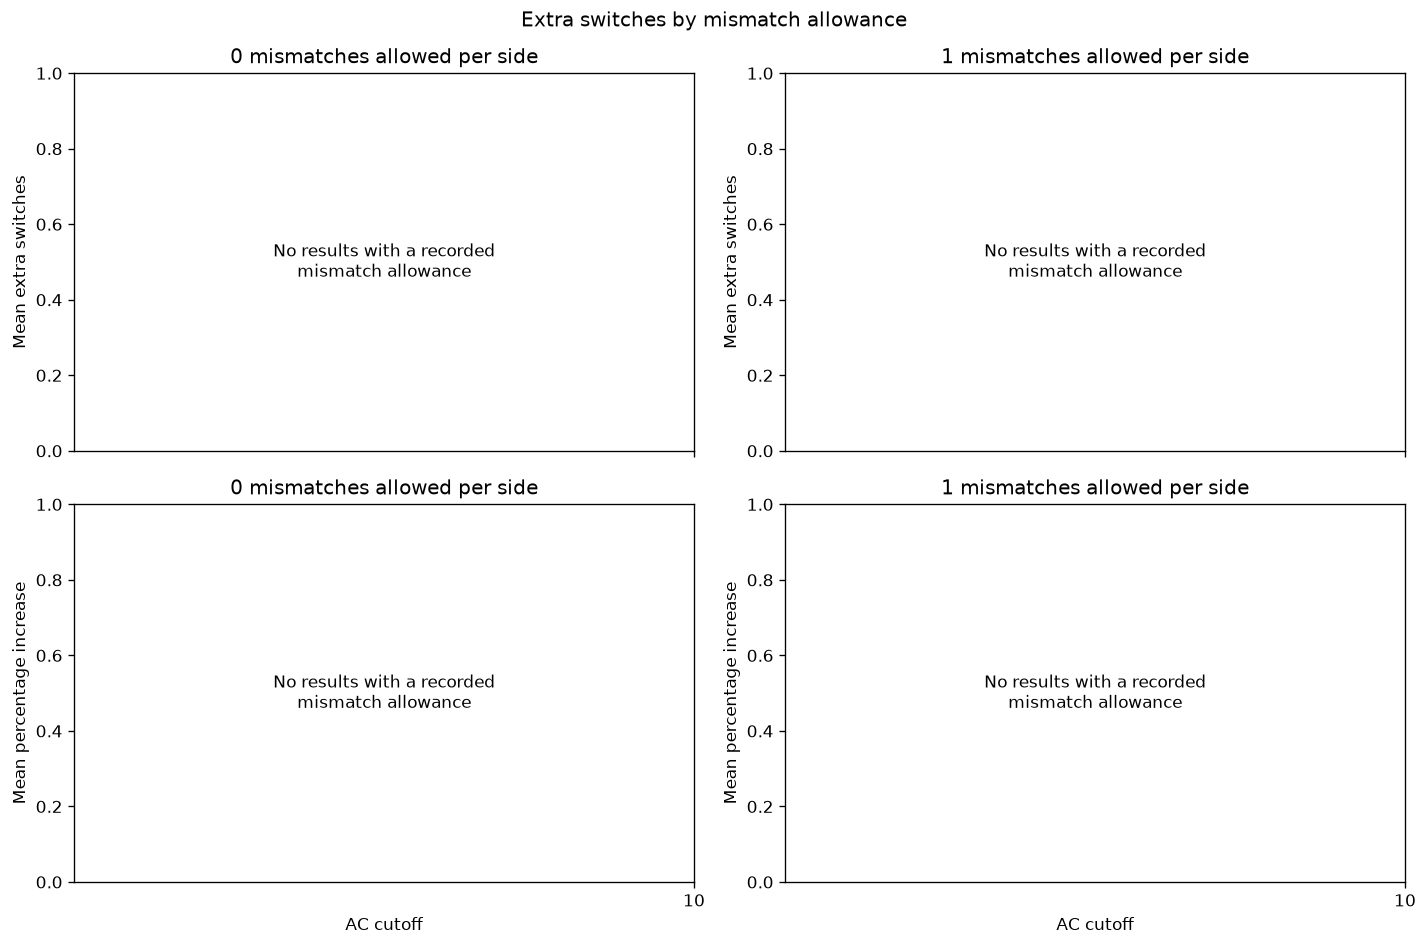

In [4]:
hyperparameter_output_dir = pathlib.Path(config["cohort"]["output_dir"]).expanduser()
if not hyperparameter_output_dir.is_absolute():
    hyperparameter_output_dir = repository_dir / hyperparameter_output_dir
hyperparameter_results = pd.read_csv(
    hyperparameter_output_dir / "haplotype_results.csv"
)
switch_counts = hyperparameter_results.pivot(
    index=["dataset", "sample_id", "ploidy_index", "population", "ac_cutoff"],
    columns="method",
    values="num_switches",
).reset_index()
switch_counts["num_extra_switches"] = switch_counts.stitched - switch_counts.full
full_switch_counts = switch_counts.full.replace(0, np.nan)
switch_counts["switch_increase_percentage"] = (
    100 * switch_counts.num_extra_switches / full_switch_counts
)
hyperparameter_metrics = [
    ("num_extra_switches", "Mean extra switches"),
    ("switch_increase_percentage", "Mean percentage increase"),
]
requested_mismatch_settings = [0, 1]
nb_plot.plot_extra_switches_vs_hyperparameters(
    hyperparameter_metrics=hyperparameter_metrics,
    requested_mismatch_settings=requested_mismatch_settings,
    switch_counts=switch_counts,
    figsize=[12, 8],
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

The saved cohort has one AC cutoff. These means and standard errors describe
the current configuration across all populations; the mismatch allowance is
not recorded in its output metadata.

In [ ]:
nb_plot.plot_extra_switches_vs_hyperparameters_2(
    hyperparameter_metrics=hyperparameter_metrics,
    switch_counts=switch_counts,
    figsize=[12, 5],
    marker="o",
    fontsize="small",
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

In [3]:
coverage_handles = nb_plot.make_path_legend()

# Population-level results

Compare all saved haplotypes, grouped by population, in the simulation and
1KGP datasets. Each observation is one haplotype. Settings and plot styles
live in the scientific settings cell below.

In [4]:
population_output_dir = pathlib.Path(config["cohort"]["output_dir"]).expanduser()
if not population_output_dir.is_absolute():
    population_output_dir = repository_dir / population_output_dir
population_output_dir.mkdir(parents=True, exist_ok=True)
population_tables = []
for settings in config["datasets"]:
    table = pd.read_csv(output_dir / settings["name"] / "comparison.csv")
    assert not table.duplicated(["sample_id", "ploidy_index"]).any()
    assert len(table) == config["cohort"]["num_haplotypes"]
    assert table.dataset.eq(settings["name"]).all()
    assert table.population.notna().all()
    assert set(table.population) == set(settings["populations"])
    population_tables.append(table)
population_comparisons = pd.concat(population_tables, ignore_index=True)
population_comparisons["num_extra_switches"] = (
    population_comparisons.stitched_switches - population_comparisons.full_switches
)
full_switch_denominator = population_comparisons.full_switches.replace(0, np.nan)
population_comparisons["switch_increase_percentage"] = (
    100 * population_comparisons.num_extra_switches / full_switch_denominator
)
for region in ("focal", "gap"):
    region_sites = population_comparisons[f"{region}_sites"].replace(0, np.nan)
    disagreeing_sites = population_comparisons[f"{region}_disagreement_sites"]
    population_comparisons[f"{region}_agreement_percentage"] = 100 * (
        1 - disagreeing_sites / region_sites
    )

## Extra switches by population

Extra switches are `stitched_switches - full_switches`. Histograms show the
distribution across haplotypes; each point beneath a histogram represents one
haplotype. Solid curves show kernel densities and dashed lines show means.

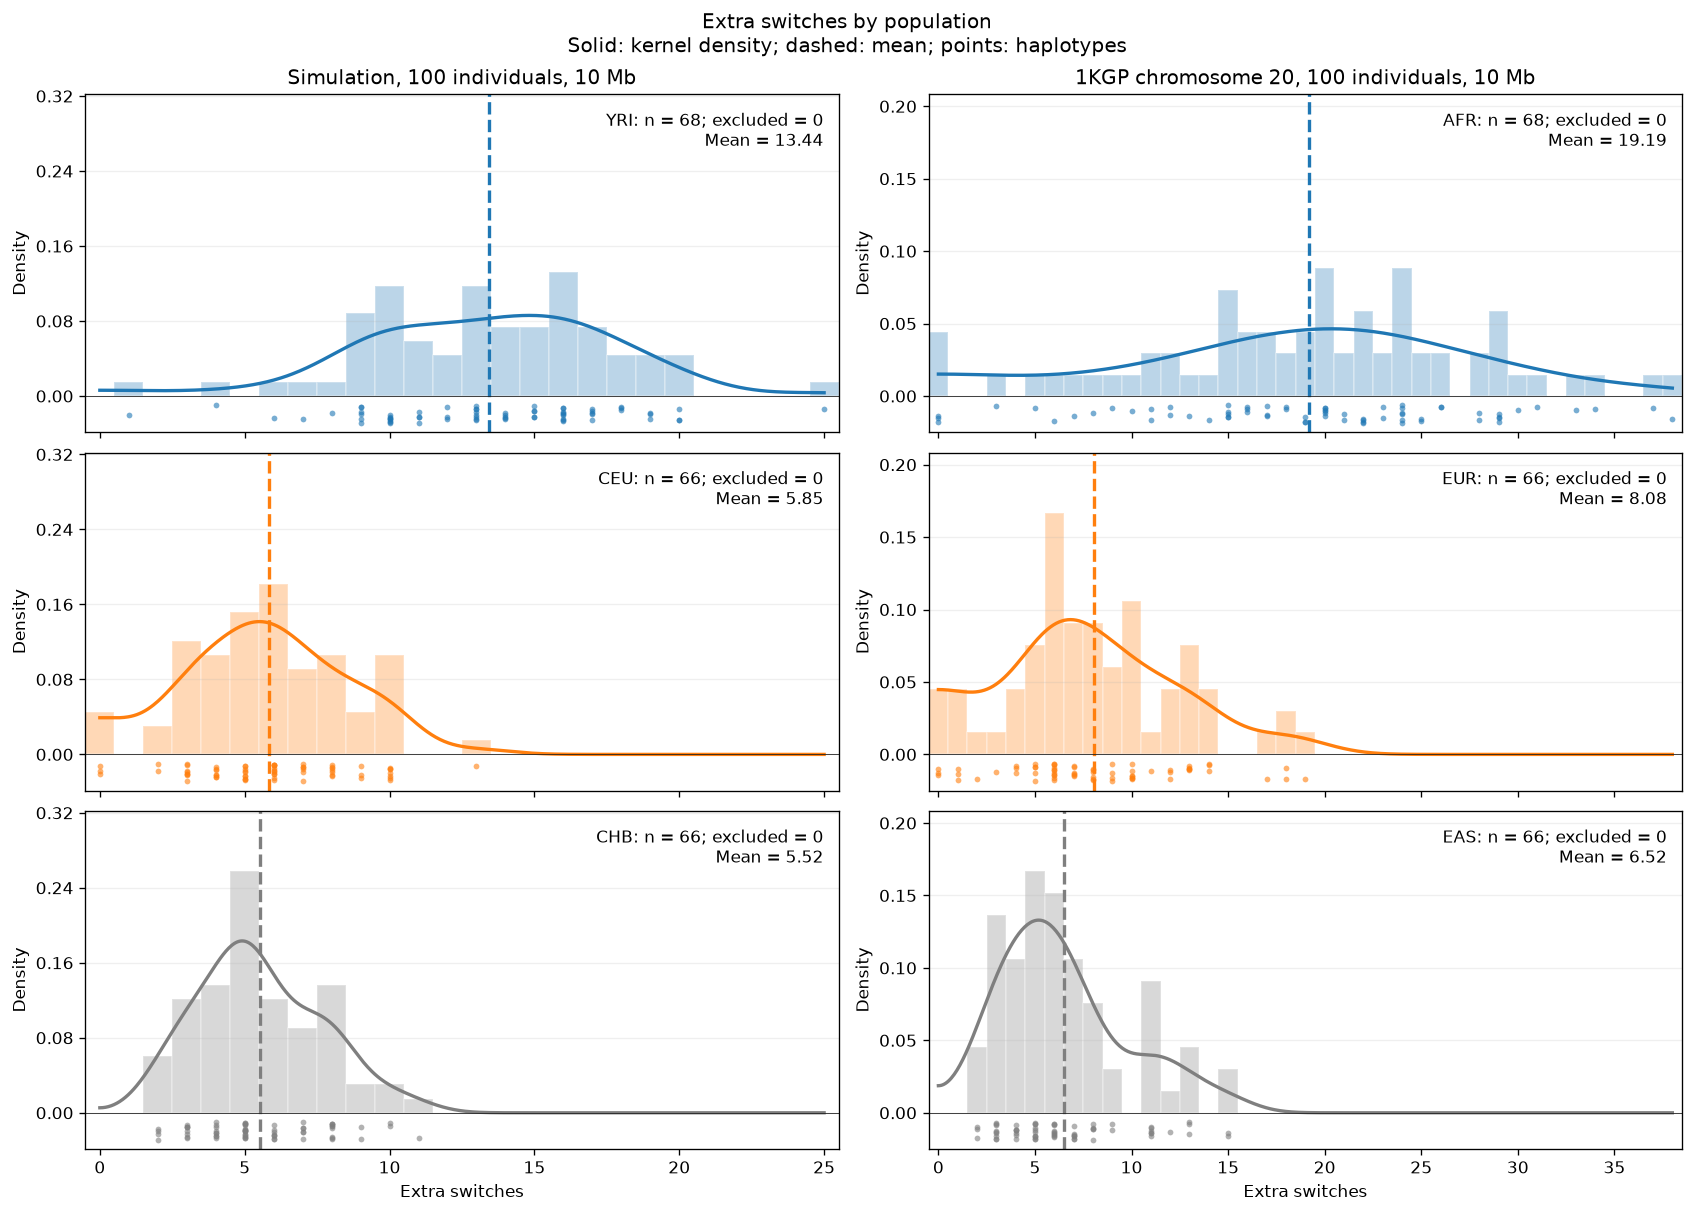

In [5]:
fig = nb_plot.plot_population_histograms(
    "num_extra_switches",
    "Extra switches",
    "Extra switches by population",
    integer_bins=True,
    config=config,
    plot_full_color="#222222",
    plot_population_results_count_bin_width=1,
    plot_population_results_density_tick_count=5,
    plot_population_results_histogram_alpha=0.3,
    plot_population_results_histogram_bins=30,
    plot_population_results_histogram_figsize=[14, 10],
    plot_population_results_kde_bandwidth="scott",
    plot_population_results_kde_grid_size=512,
    plot_population_results_line_width=2,
    plot_population_results_point_alpha=0.6,
    plot_population_results_point_size=12,
    plot_population_results_point_strip_depth=0.15,
    plot_population_results_population_colors={
        "YRI": "tab:blue",
        "AFR": "tab:blue",
        "CEU": "tab:orange",
        "EUR": "tab:orange",
        "CHB": "tab:gray",
        "EAS": "tab:gray",
    },
    plot_population_results_random_seed=42,
    plot_population_results_range_padding=0.05,
    population_comparisons=population_comparisons,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.plot_extra_switches_by_population(
    fig=fig, population_output_dir=population_output_dir
)

## Percentage increase in switches by population

Percentage increase is
`100 * (stitched_switches - full_switches) / full_switches`.
It is undefined when the full HMM has no switches, including when both paths
have zero switches. Each panel reports the number of undefined observations
excluded from its histogram, points, kernel density, and mean.

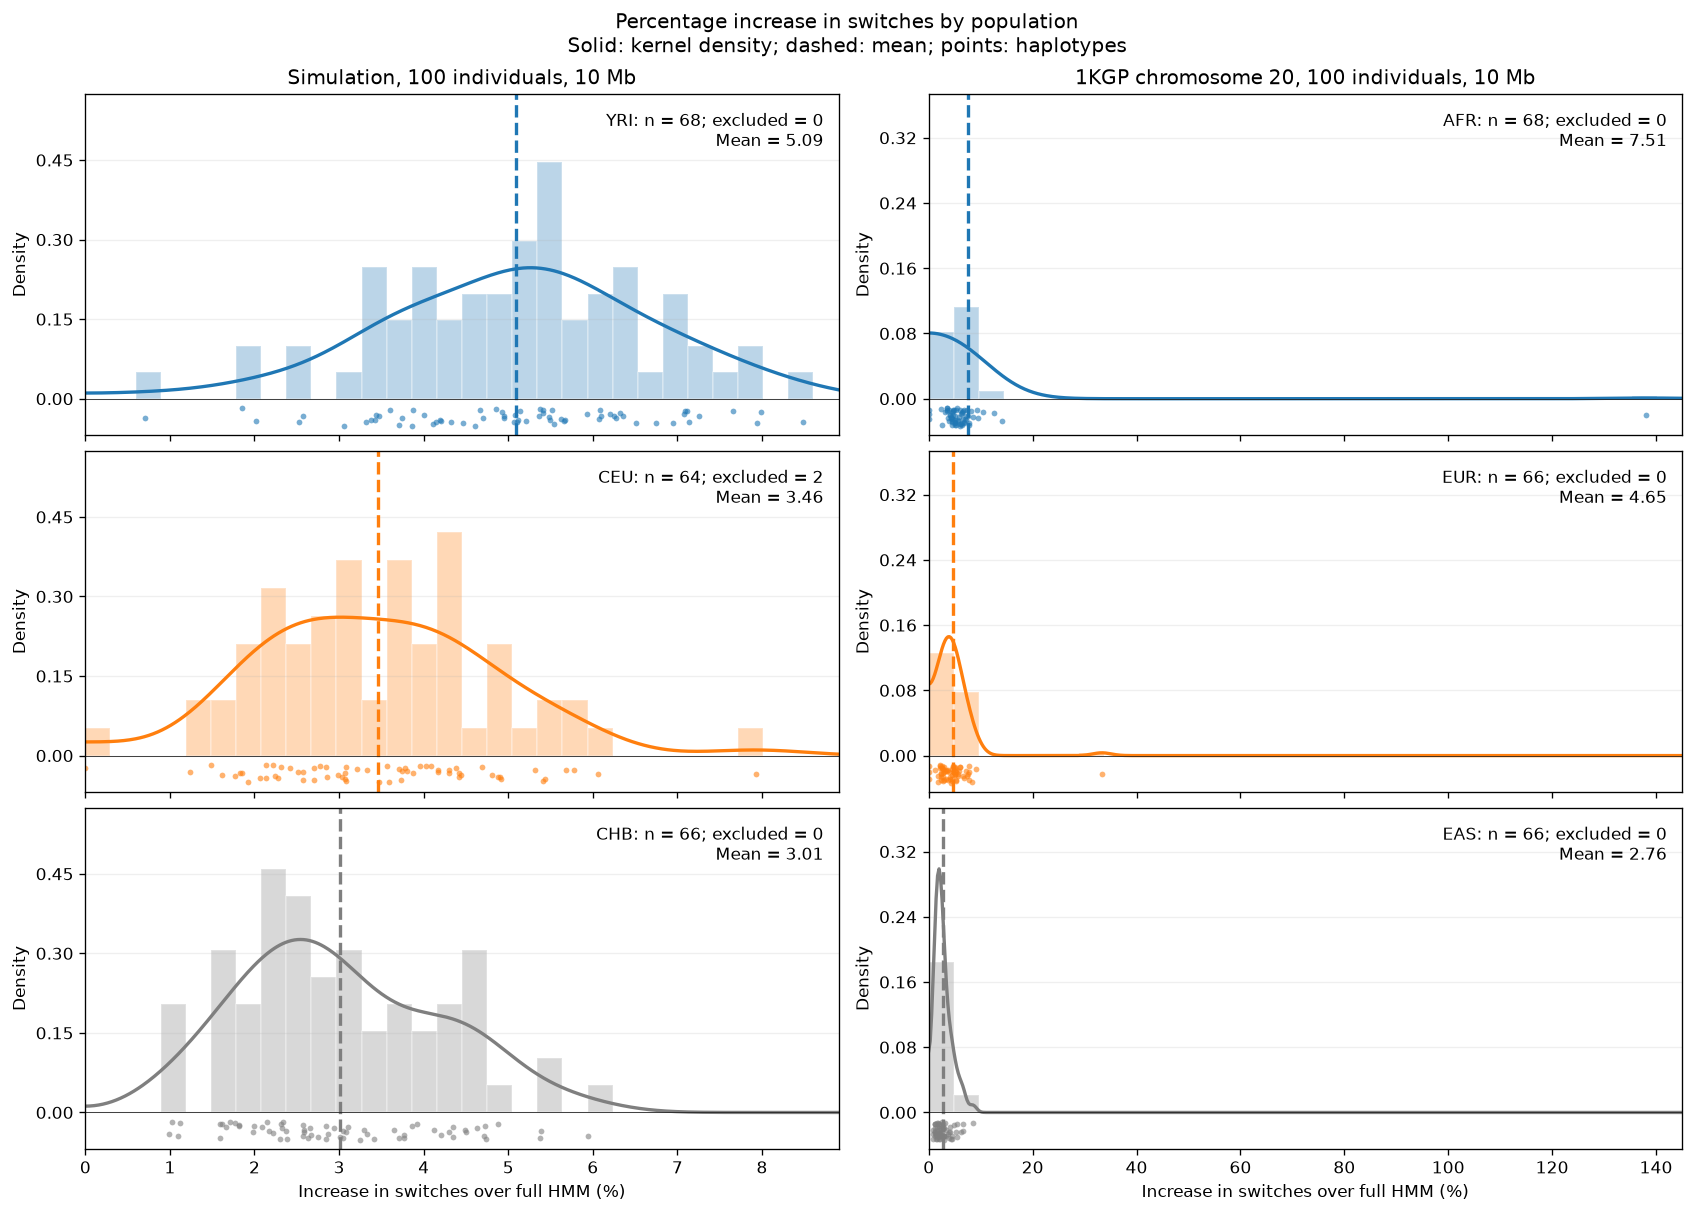

In [6]:
fig = nb_plot.plot_population_histograms(
    "switch_increase_percentage",
    "Increase in switches over full HMM (%)",
    "Percentage increase in switches by population",
    config=config,
    plot_full_color="#222222",
    plot_population_results_count_bin_width=1,
    plot_population_results_density_tick_count=5,
    plot_population_results_histogram_alpha=0.3,
    plot_population_results_histogram_bins=30,
    plot_population_results_histogram_figsize=[14, 10],
    plot_population_results_kde_bandwidth="scott",
    plot_population_results_kde_grid_size=512,
    plot_population_results_line_width=2,
    plot_population_results_point_alpha=0.6,
    plot_population_results_point_size=12,
    plot_population_results_point_strip_depth=0.15,
    plot_population_results_population_colors={
        "YRI": "tab:blue",
        "AFR": "tab:blue",
        "CEU": "tab:orange",
        "EUR": "tab:orange",
        "CHB": "tab:gray",
        "EAS": "tab:gray",
    },
    plot_population_results_random_seed=42,
    plot_population_results_range_padding=0.05,
    population_comparisons=population_comparisons,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.plot_percentage_increase_in_switches_by_population(
    fig=fig, population_output_dir=population_output_dir
)

## Gap properties

Each observation is one saved haplotype. The histograms pool populations within
each dataset; solid curves show kernel densities and dashed lines show means.
Points are coloured consistently by population: blue for YRI/AFR, orange for
CEU/EUR, and gray for CHB/EAS. Mean sites per gap is `gap_sites / num_gaps` and
is undefined for haplotypes with no gaps. Exclusion counts appear in each panel.

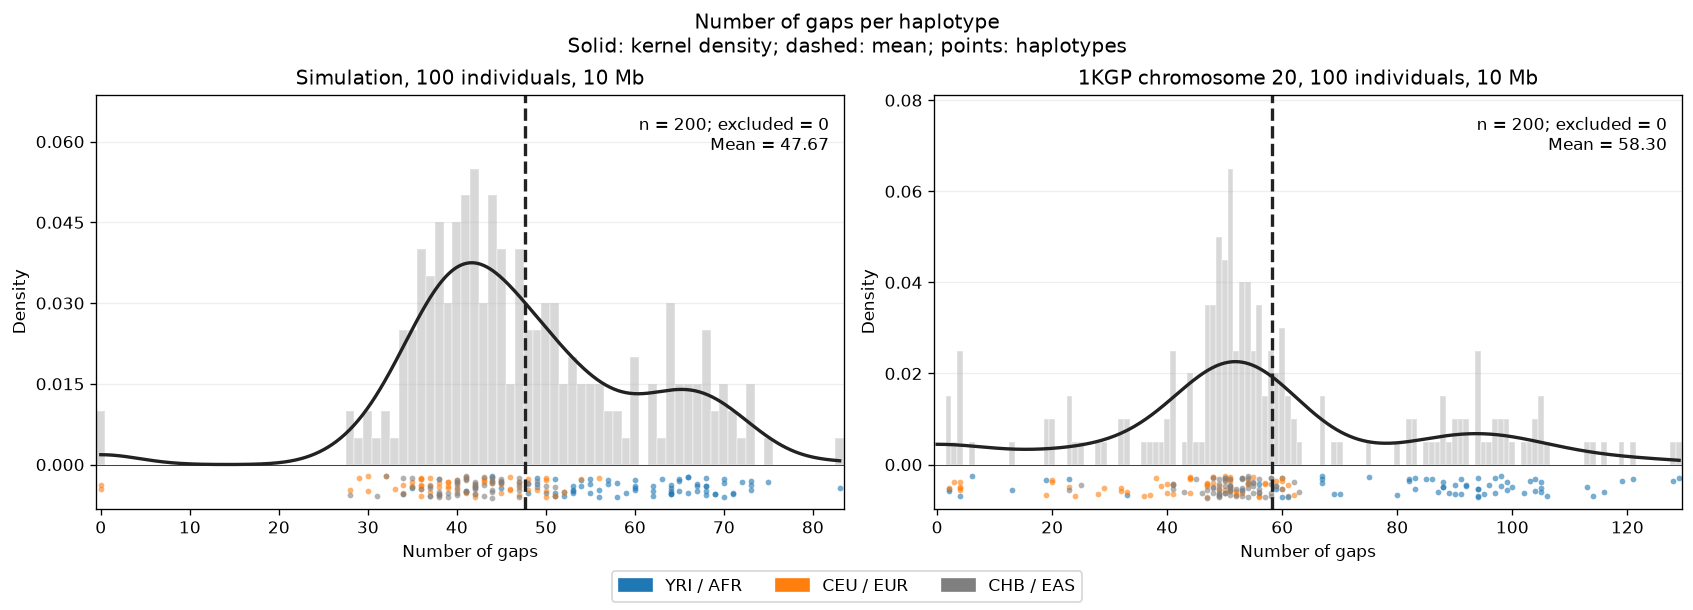

In [7]:
gap_denominator = population_comparisons.num_gaps.replace(0, np.nan)
population_comparisons["mean_sites_per_gap"] = (
    population_comparisons.gap_sites / gap_denominator
)
gap_population_handles = nb_plot.plot_gap_properties(
    config=config,
    population_comparisons=population_comparisons,
    population_output_dir=population_output_dir,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

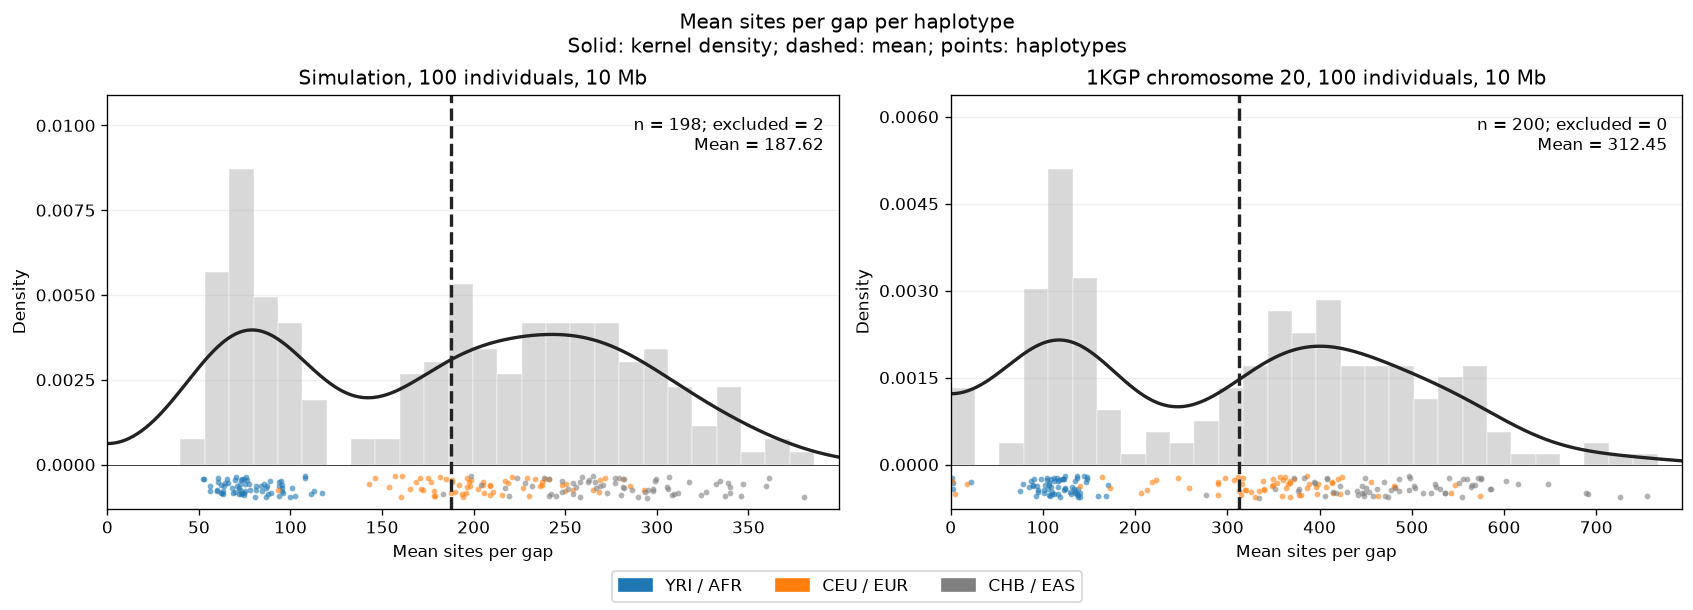

In [8]:
fig = nb_plot.plot_gap_property_histograms(
    "mean_sites_per_gap",
    "Mean sites per gap",
    "Mean sites per gap per haplotype",
    config=config,
    gap_population_handles=gap_population_handles,
    plot_full_color="#222222",
    plot_population_results_count_bin_width=1,
    plot_population_results_density_tick_count=5,
    plot_population_results_gap_histogram_color="tab:gray",
    plot_population_results_gap_histogram_figsize=[14, 5],
    plot_population_results_histogram_alpha=0.3,
    plot_population_results_histogram_bins=30,
    plot_population_results_kde_bandwidth="scott",
    plot_population_results_kde_grid_size=512,
    plot_population_results_line_width=2,
    plot_population_results_point_alpha=0.6,
    plot_population_results_point_size=12,
    plot_population_results_point_strip_depth=0.15,
    plot_population_results_population_colors={
        "YRI": "tab:blue",
        "AFR": "tab:blue",
        "CEU": "tab:orange",
        "EUR": "tab:orange",
        "CHB": "tab:gray",
        "EAS": "tab:gray",
    },
    plot_population_results_random_seed=42,
    plot_population_results_range_padding=0.05,
    population_comparisons=population_comparisons,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.plot_gap_properties_2(fig=fig, population_output_dir=population_output_dir)

Compare each haplotype's mean gap length with its number of eligible focal
ancestors (top row) and number of gaps (bottom row). Haplotypes without gaps
are excluded.

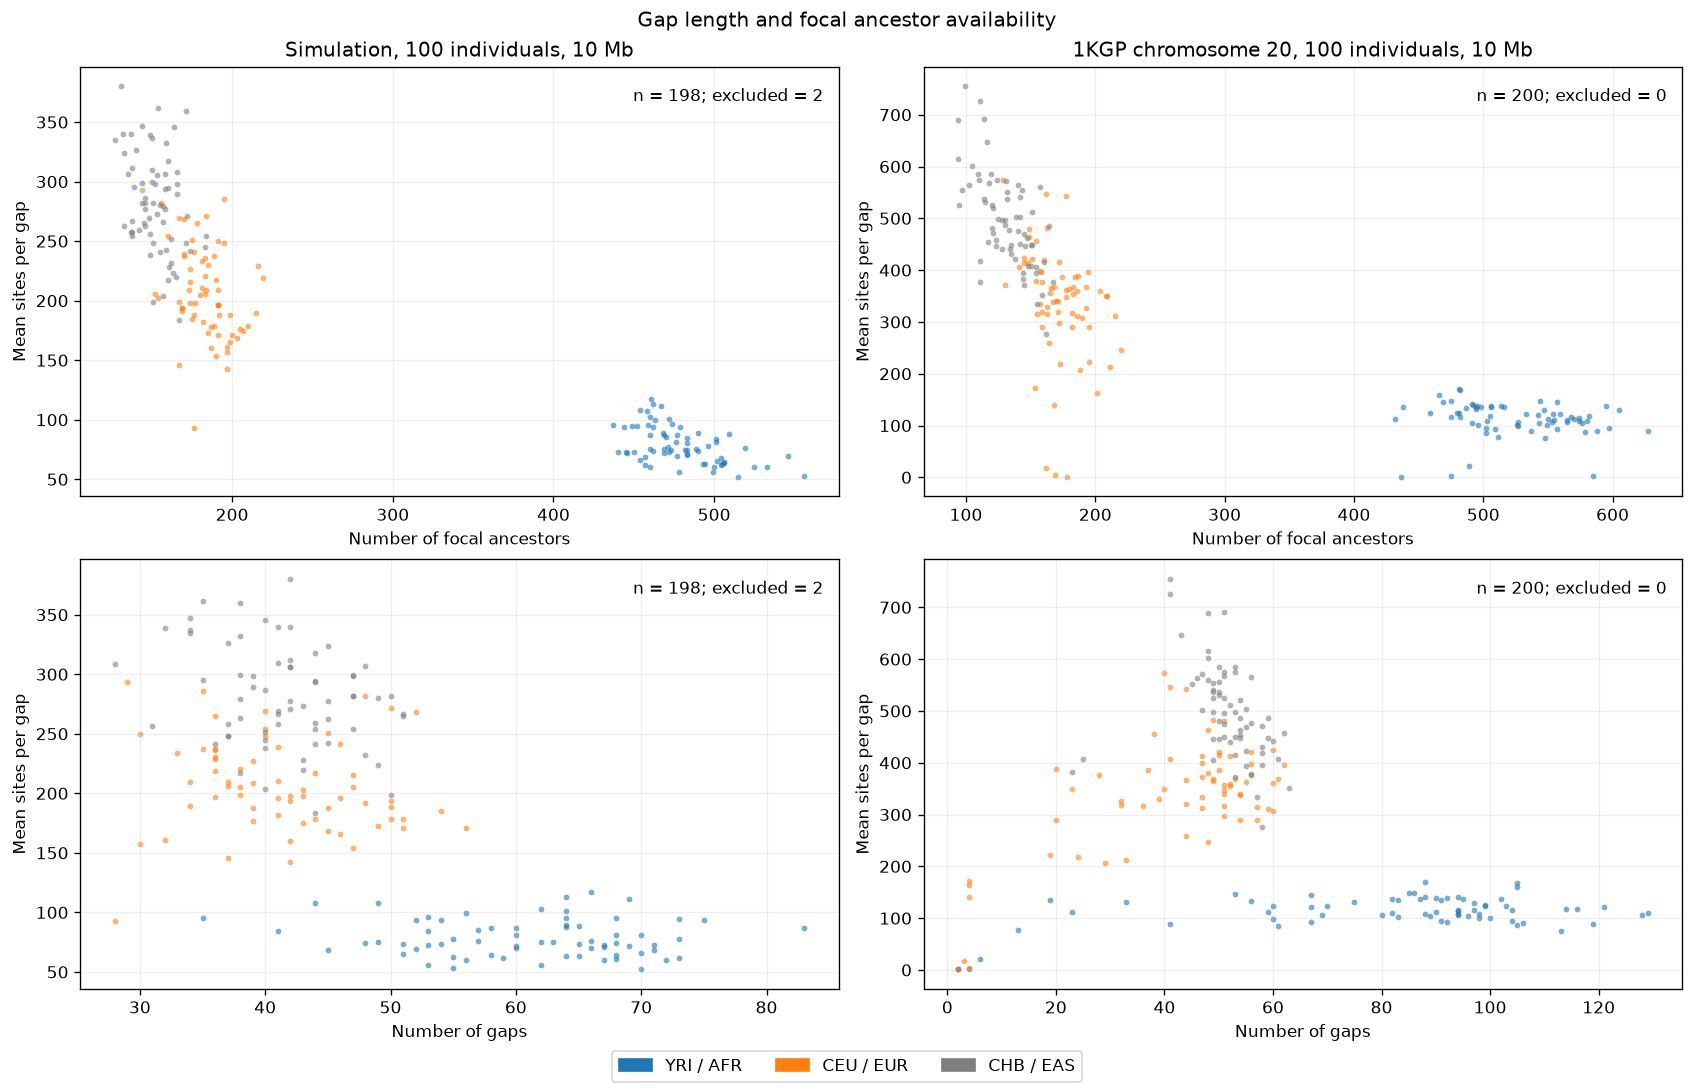

In [9]:
nb_plot.plot_gap_properties_3(
    config=config,
    gap_population_handles=gap_population_handles,
    population_comparisons=population_comparisons,
    population_output_dir=population_output_dir,
    figsize=[14, 9],
    s=12,
    alpha=0.6,
    linewidths=0,
    ylabel="Mean sites per gap",
    alpha_2=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

Relate the number of extra switches to the number of gaps, focal ancestors,
and mean sites per gap. Each row is one dataset; points are haplotypes coloured
by population. Haplotype-level gaps and extra switches are integer counts.

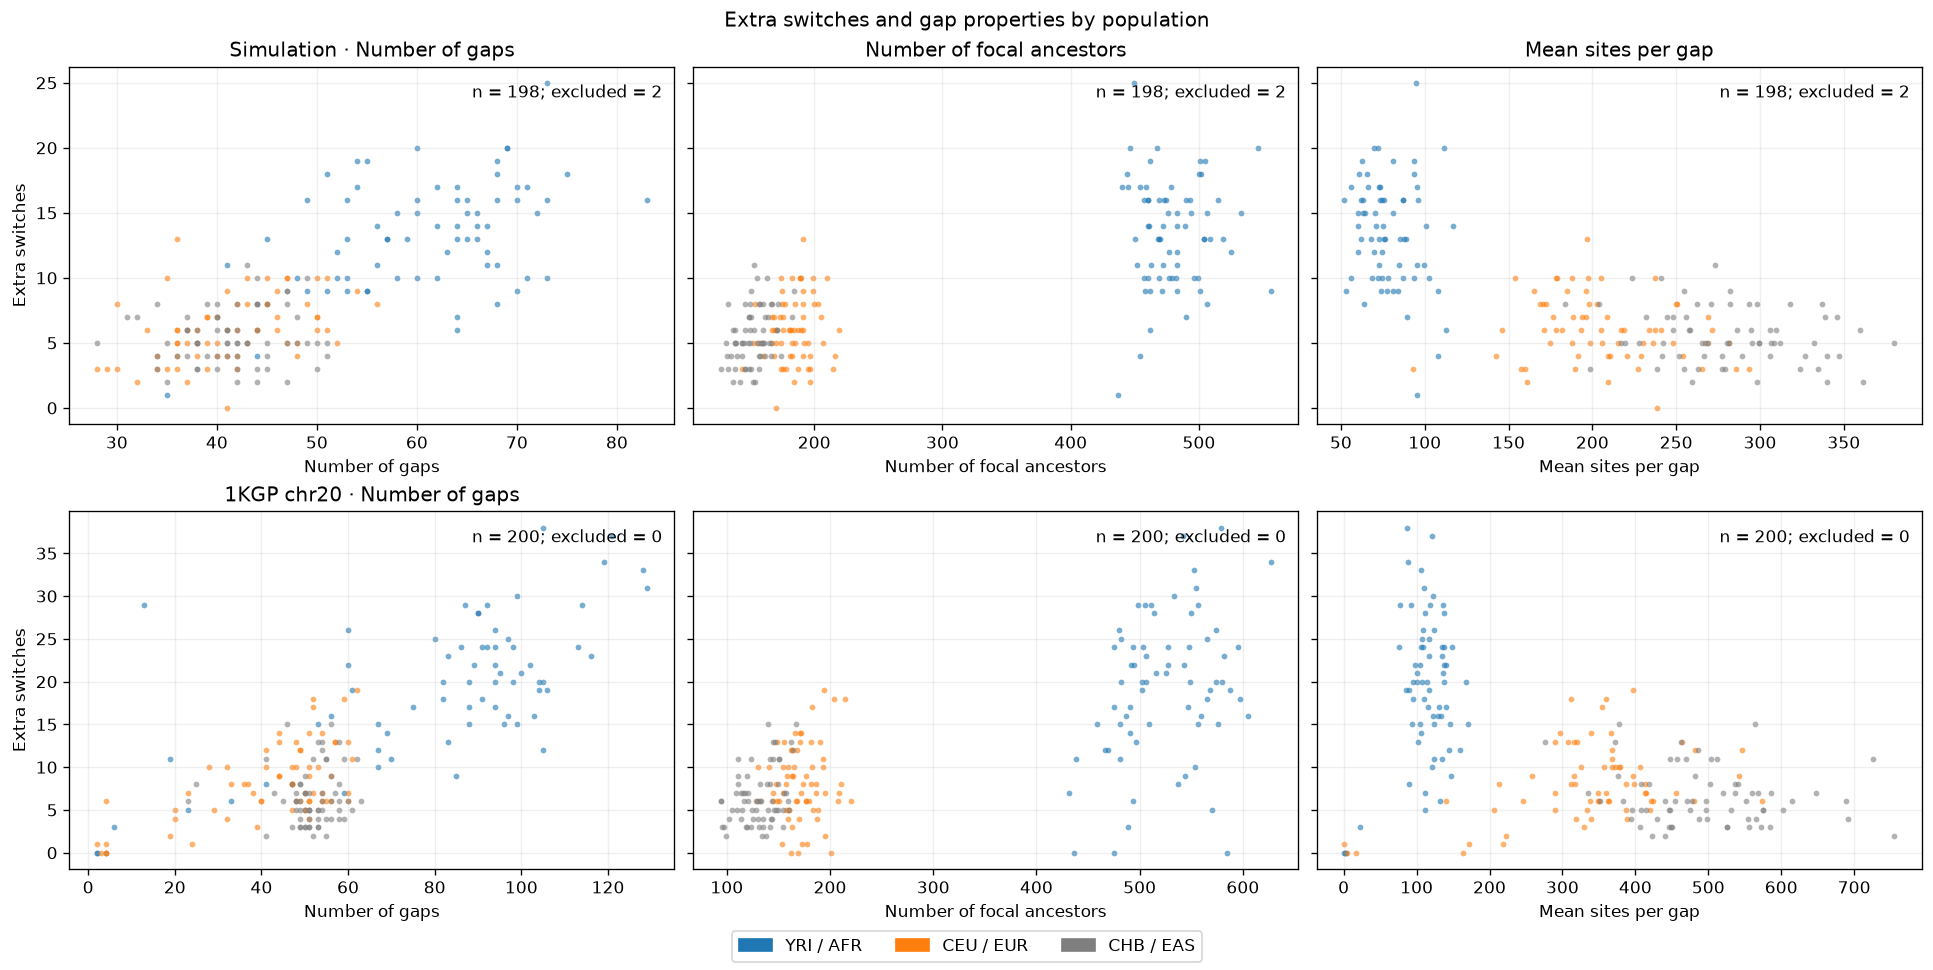

In [10]:
gap_predictors = [
    ("num_gaps", "Number of gaps"),
    ("num_focal_ancestors", "Number of focal ancestors"),
    ("mean_sites_per_gap", "Mean sites per gap"),
]
nb_plot.plot_gap_properties_4(
    config=config,
    gap_population_handles=gap_population_handles,
    gap_predictors=gap_predictors,
    population_comparisons=population_comparisons,
    population_output_dir=population_output_dir,
    figsize=[16, 8],
    s=12,
    alpha=0.6,
    linewidths=0,
    alpha_2=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Decomposing switches by type

Switches are partitioned into those within focal coverage, within gaps, and
at focal/gap seams, using the same region boundaries for both methods.
Each haplotype's counts are divided by its own method's total switches before
averaging within populations. The stacked bars therefore describe mean
haplotype compositions, and each bar sums to 100%. Haplotypes with zero
switches have undefined compositions and are excluded, as noted below.

Undefined compositions excluded
dataset                  population method                                   
out_of_africa_n100_10mbp CEU        full                                    2
                                    stitched                                2
                         CHB        full                                    0
                                    stitched                                0
                         YRI        full                                    0
                                    stitched                                0
tgp_chr20_n100           AFR        full                                    0
                                    stitched                                0
                         EAS        full                                    0
                                    stitched                                0
                         EUR        full                                    0
                                    stitched                                0

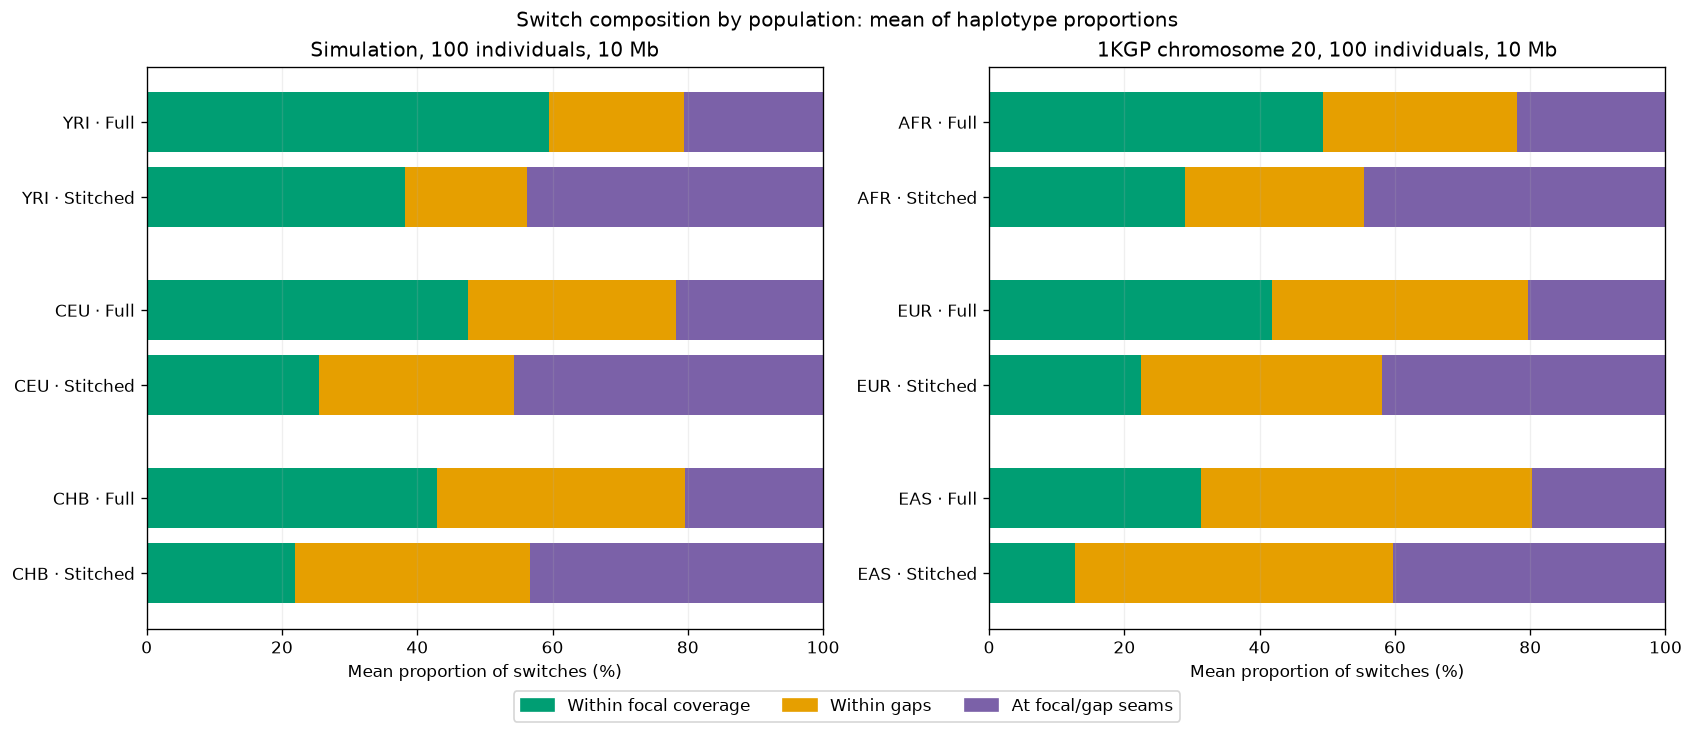

In [11]:
population_switch_categories = ["focal", "gap", "seam"]
population_switch_tables = []
for method in ("full", "stitched"):
    method_table = population_comparisons[
        ["dataset", "sample_id", "ploidy_index", "population"]
    ].copy()
    method_table["method"] = method
    totals = population_comparisons[f"{method}_switches"]
    counts = population_comparisons[
        [f"{method}_{category}_switches" for category in population_switch_categories]
    ]
    assert counts.sum(axis=1).eq(totals).all()
    denominator = totals.replace(0, np.nan)
    for category in population_switch_categories:
        category_counts = population_comparisons[f"{method}_{category}_switches"]
        method_table[category] = category_counts / denominator
    defined = totals.gt(0)
    assert np.allclose(
        method_table.loc[defined, population_switch_categories].sum(axis=1), 1
    )
    population_switch_tables.append(method_table)
population_switch_proportions = pd.concat(population_switch_tables, ignore_index=True)
population_switch_means = population_switch_proportions.groupby(
    ["dataset", "population", "method"]
)[population_switch_categories].mean()
population_switch_excluded = (
    population_switch_proportions.assign(
        excluded=population_switch_proportions.focal.isna()
    )
    .groupby(["dataset", "population", "method"])
    .excluded.sum()
)
excluded_compositions = population_switch_excluded.rename(
    "Undefined compositions excluded"
)
ipython_display.display(excluded_compositions.to_frame())
nb_plot.plot_decomposing_switches_by_type(
    config=config,
    population_output_dir=population_output_dir,
    population_switch_categories=population_switch_categories,
    population_switch_means=population_switch_means,
    figsize=[14, 6],
    height=0.32,
    xlim=(0, 100),
    xlabel="Mean proportion of switches (%)",
    alpha=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

The ternary plots show the same compositions for individual haplotypes.
A corner represents 100% of its switch type; the opposite edge represents 0%.
Colours identify populations, consistently across datasets: blue for YRI/AFR,
orange for CEU/EUR, and gray for CHB/EAS. Circles show full HMM haplotypes and
triangles show stitched HMM haplotypes. Large outlined markers show population
means, labelled by population. Undefined compositions are excluded as in the bars.

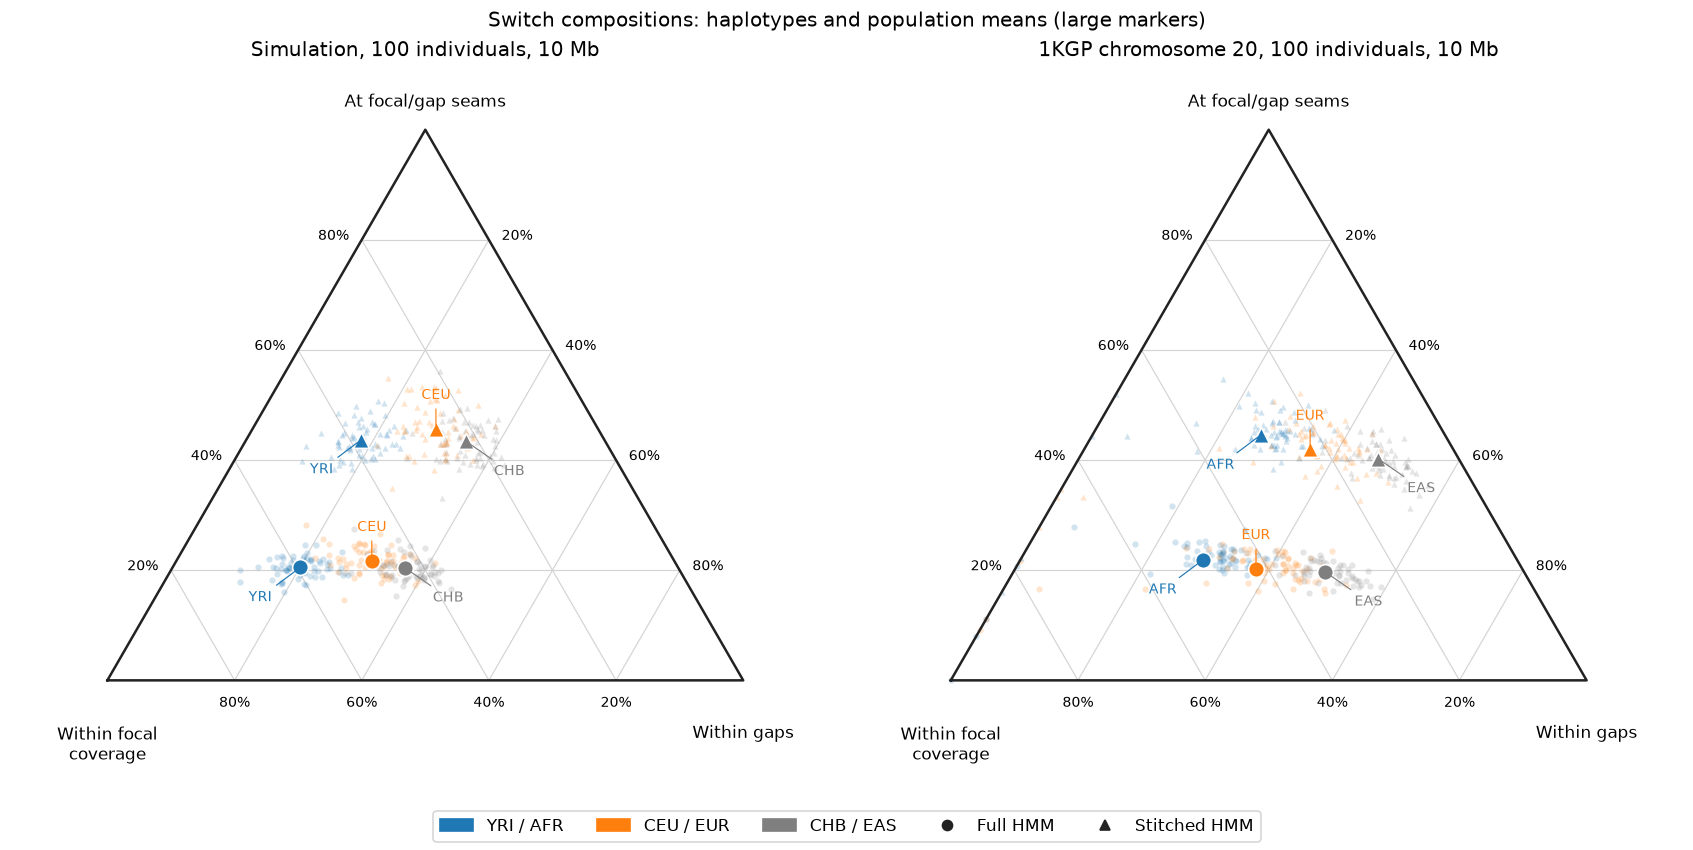

In [12]:
nb_plot.plot_decomposing_switches_by_type_2(
    config=config,
    population_output_dir=population_output_dir,
    population_switch_categories=population_switch_categories,
    population_switch_means=population_switch_means,
    population_switch_proportions=population_switch_proportions,
    figsize=[14, 7],
    color="#222222",
    color_2="lightgray",
    linewidth=0.7,
    fontsize="small",
    s=14,
    alpha=0.2,
    linewidths=0,
    s_2=90,
    xlim=(-0.15, 1.15),
    linestyle="none",
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Parent agreement proportions

Each strip shows the mean proportions of all inference sites assigned to
focal/agree, focal/disagree, gaps/agree, and gaps/disagree. The four fractions
share the same denominator and sum to 100%. Focal and gap segments are kept
together, so their boundary also shows mean focal coverage.

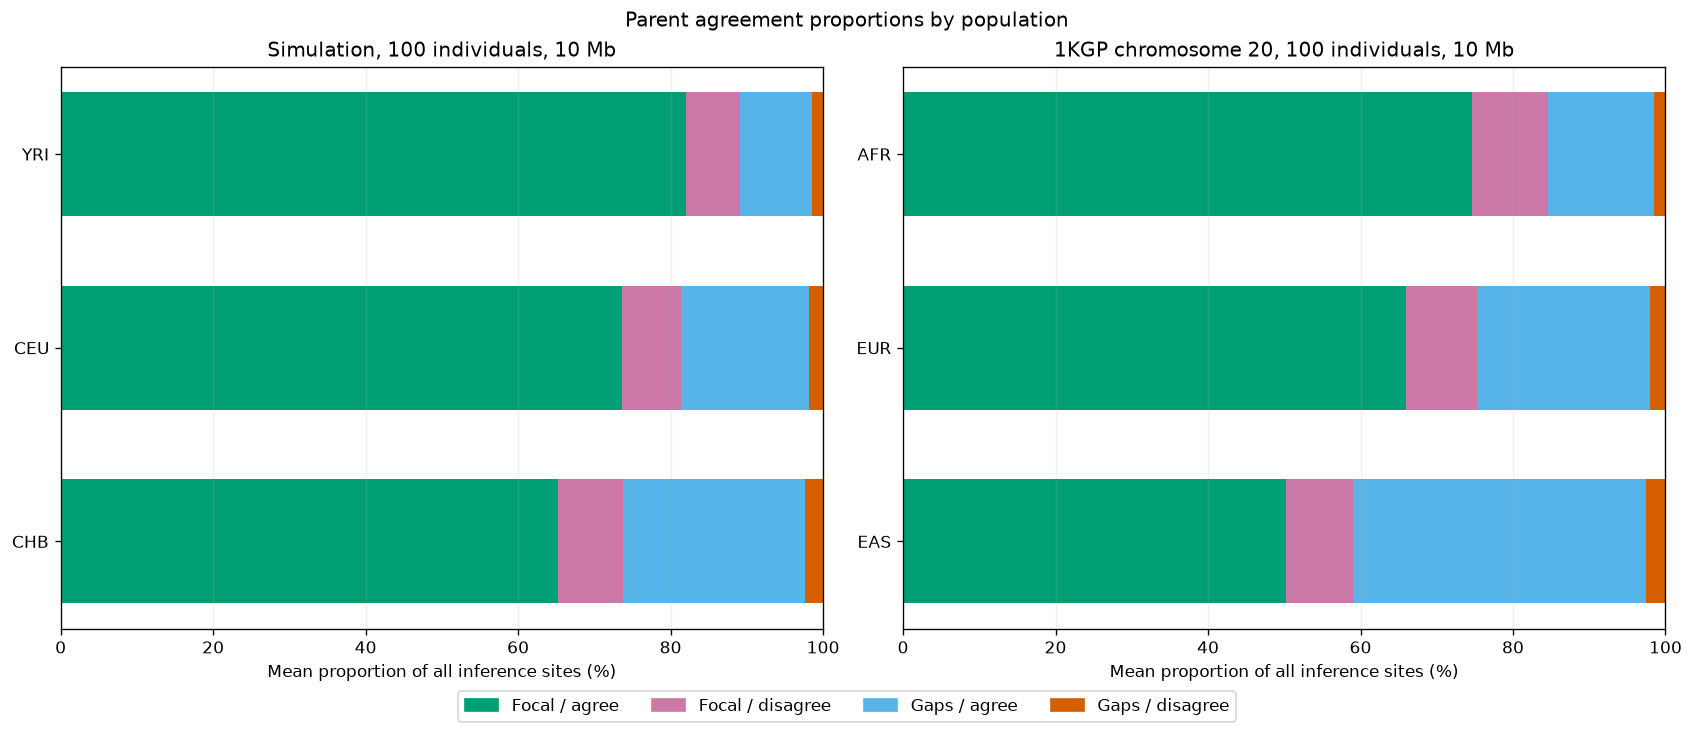

In [13]:
population_agreement_columns = [
    "focal_agree_fraction",
    "focal_disagree_fraction",
    "gap_agree_fraction",
    "gap_disagree_fraction",
]
assert np.allclose(population_comparisons[population_agreement_columns].sum(axis=1), 1)
population_agreement_means = population_comparisons.groupby(["dataset", "population"])[
    population_agreement_columns
].mean()
nb_plot.plot_parent_agreement_proportions(
    config=config,
    population_agreement_columns=population_agreement_columns,
    population_agreement_means=population_agreement_means,
    population_output_dir=population_output_dir,
    figsize=[14, 6],
    xlim=(0, 100),
    xlabel="Mean proportion of all inference sites (%)",
    alpha=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Parent agreement in focal regions

Agreement within focal regions is
`100 * (focal_sites - focal_disagreement_sites) / focal_sites`.
Each haplotype contributes its own percentage; agreement and disagreement
within its focal regions sum to 100%. Haplotypes without focal sites have
undefined agreement percentages and are excluded, with counts in each panel.

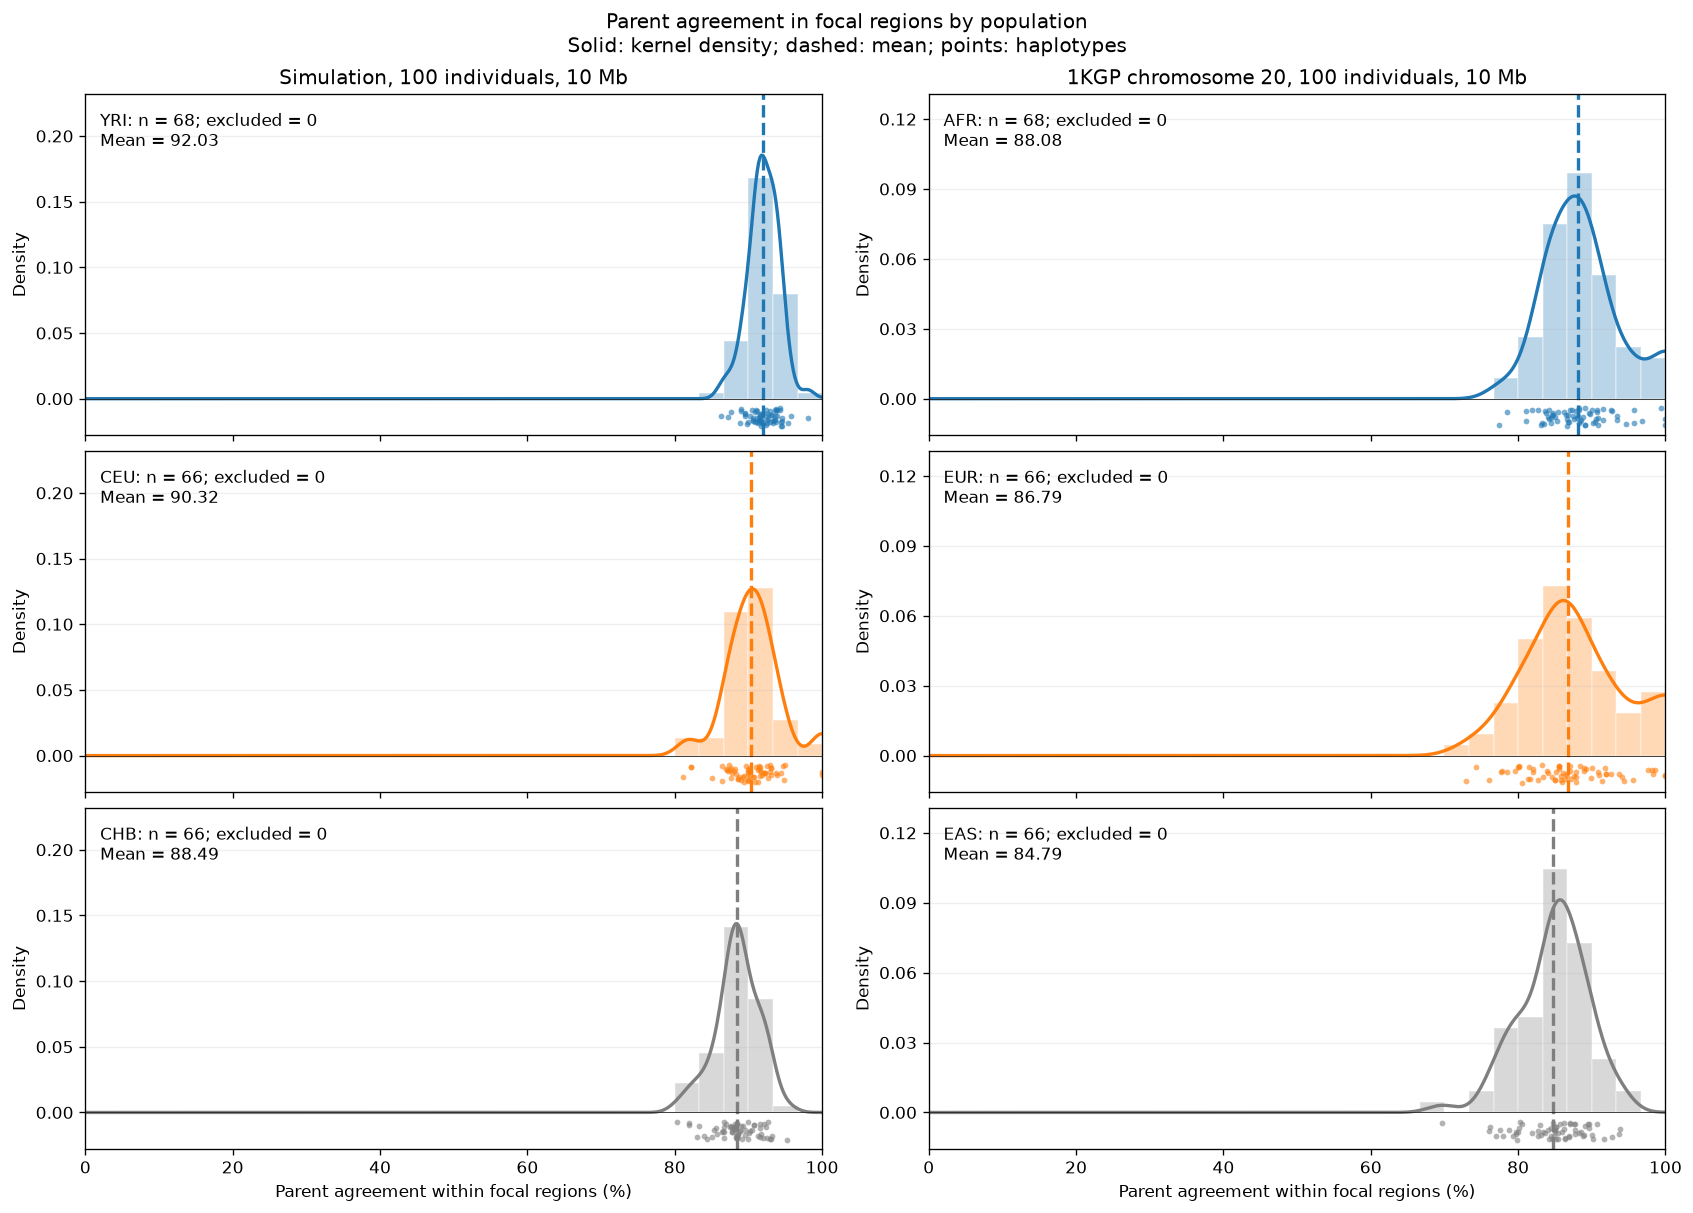

In [14]:
fig = nb_plot.plot_population_histograms(
    "focal_agreement_percentage",
    "Parent agreement within focal regions (%)",
    "Parent agreement in focal regions by population",
    bounded_percentage=True,
    config=config,
    plot_full_color="#222222",
    plot_population_results_count_bin_width=1,
    plot_population_results_density_tick_count=5,
    plot_population_results_histogram_alpha=0.3,
    plot_population_results_histogram_bins=30,
    plot_population_results_histogram_figsize=[14, 10],
    plot_population_results_kde_bandwidth="scott",
    plot_population_results_kde_grid_size=512,
    plot_population_results_line_width=2,
    plot_population_results_point_alpha=0.6,
    plot_population_results_point_size=12,
    plot_population_results_point_strip_depth=0.15,
    plot_population_results_population_colors={
        "YRI": "tab:blue",
        "AFR": "tab:blue",
        "CEU": "tab:orange",
        "EUR": "tab:orange",
        "CHB": "tab:gray",
        "EAS": "tab:gray",
    },
    plot_population_results_random_seed=42,
    plot_population_results_range_padding=0.05,
    population_comparisons=population_comparisons,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.plot_parent_agreement_in_focal_regions(
    fig=fig, population_output_dir=population_output_dir
)

## Parent agreement in gaps

Agreement within gaps is
`100 * (gap_sites - gap_disagreement_sites) / gap_sites`.
Each haplotype contributes its own percentage; agreement and disagreement
within its gaps sum to 100%. Haplotypes without gap sites have undefined
agreement percentages and are excluded, with counts in each panel.

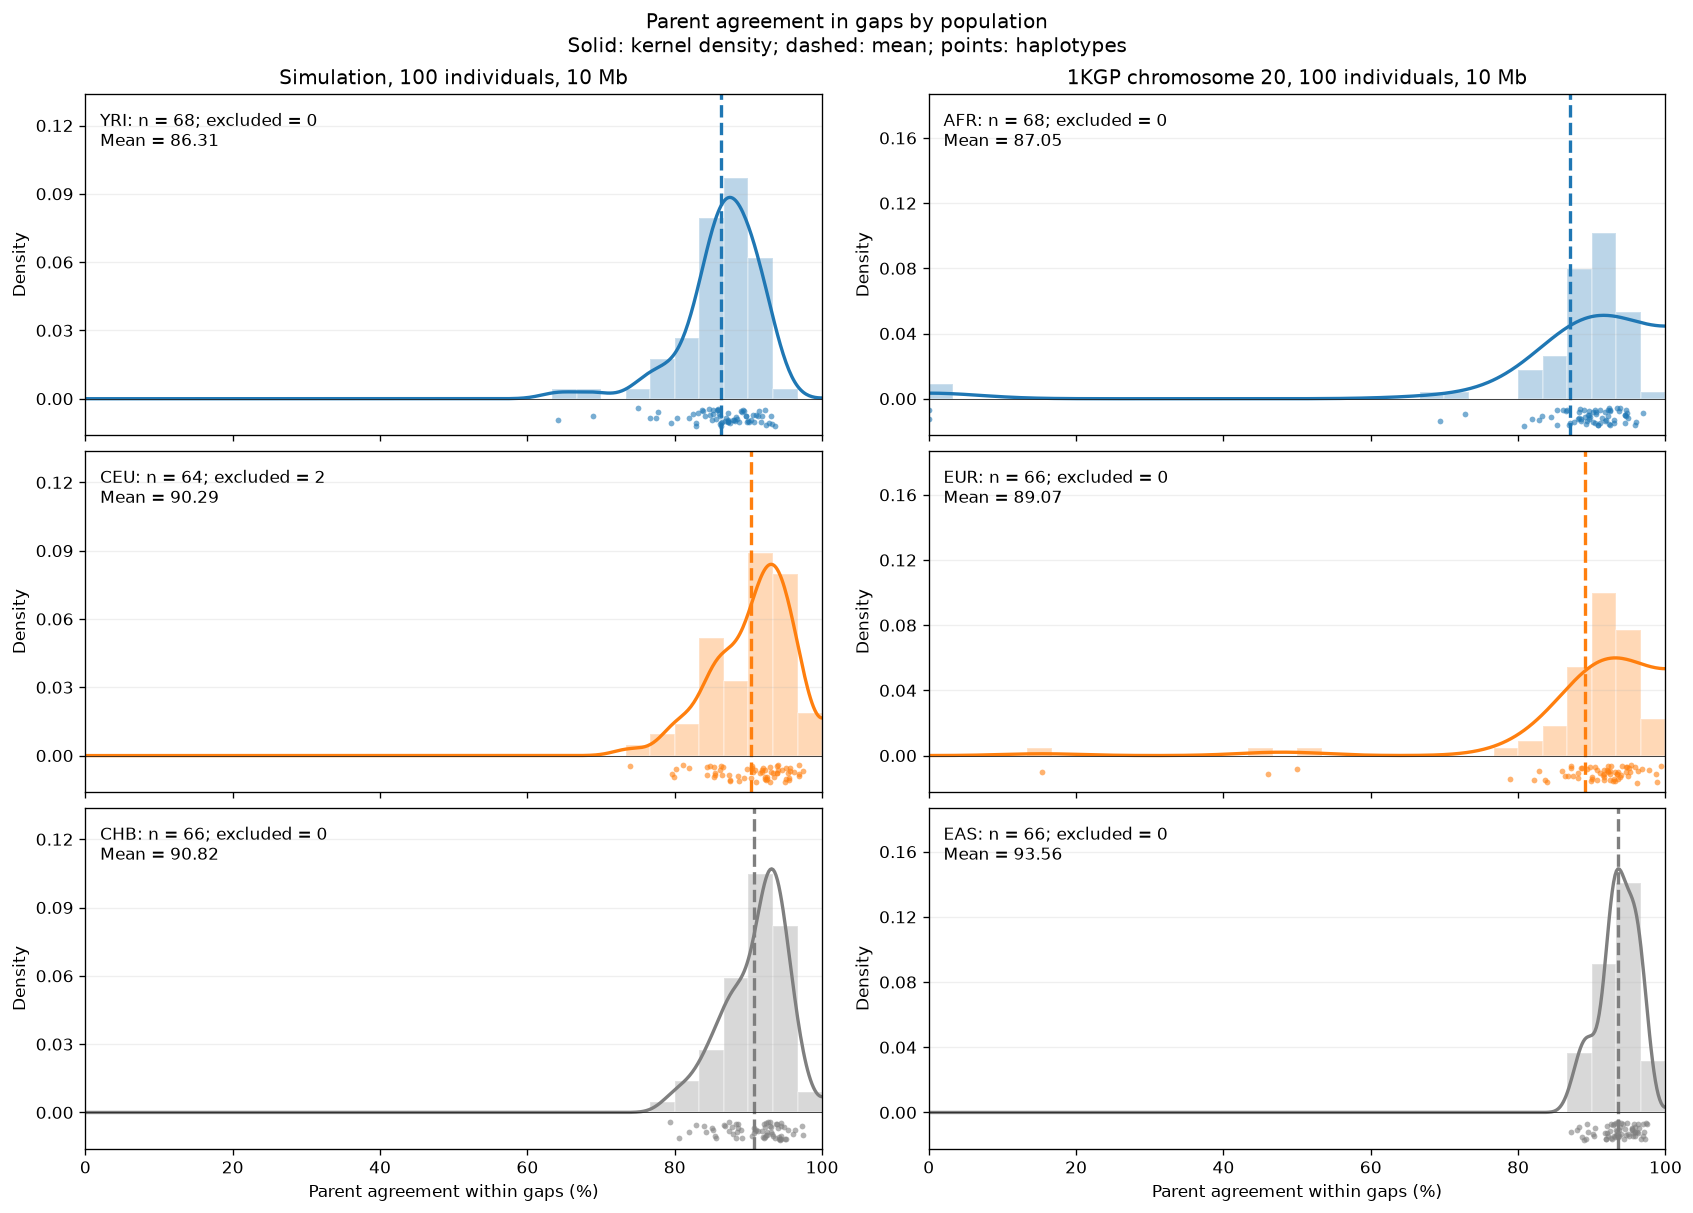

In [15]:
fig = nb_plot.plot_population_histograms(
    "gap_agreement_percentage",
    "Parent agreement within gaps (%)",
    "Parent agreement in gaps by population",
    bounded_percentage=True,
    config=config,
    plot_full_color="#222222",
    plot_population_results_count_bin_width=1,
    plot_population_results_density_tick_count=5,
    plot_population_results_histogram_alpha=0.3,
    plot_population_results_histogram_bins=30,
    plot_population_results_histogram_figsize=[14, 10],
    plot_population_results_kde_bandwidth="scott",
    plot_population_results_kde_grid_size=512,
    plot_population_results_line_width=2,
    plot_population_results_point_alpha=0.6,
    plot_population_results_point_size=12,
    plot_population_results_point_strip_depth=0.15,
    plot_population_results_population_colors={
        "YRI": "tab:blue",
        "AFR": "tab:blue",
        "CEU": "tab:orange",
        "EUR": "tab:orange",
        "CHB": "tab:gray",
        "EAS": "tab:gray",
    },
    plot_population_results_random_seed=42,
    plot_population_results_range_padding=0.05,
    population_comparisons=population_comparisons,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.plot_parent_agreement_in_gaps(
    fig=fig, population_output_dir=population_output_dir
)

# Analysis of outliers

Select one haplotype per dataset for each criterion: most extra switches,
lowest parent agreement within focal regions, and lowest parent agreement
within gaps. Undefined agreement percentages are excluded from selection.
Ties are resolved by sample ID, then ploidy index. The table identifies the
populations and the denominators before inspecting any copying paths.

In [5]:
outlier_rows = []
for settings in config["datasets"]:
    table = population_comparisons.loc[
        population_comparisons.dataset.eq(settings["name"])
    ]
    for criterion in config["outliers"]["criteria"]:
        metric = criterion["metric"]
        eligible = table.dropna(subset=[metric])
        ordered = eligible.sort_values(
            [metric, "sample_id", "ploidy_index"],
            ascending=[criterion["ascending"], True, True],
        )
        selected = ordered.iloc[0].to_dict()
        selected["criterion"] = criterion["label"]
        selected["tied_haplotypes"] = int(eligible[metric].eq(selected[metric]).sum())
        selected["haplotype"] = f"{selected['sample_id']}/{selected['ploidy_index']}"
        outlier_rows.append(selected)
outlier_selection = pd.DataFrame(outlier_rows)
ipython_display.display(
    outlier_selection[
        [
            "dataset",
            "criterion",
            "haplotype",
            "population",
            "num_extra_switches",
            "focal_agreement_percentage",
            "focal_sites",
            "gap_agreement_percentage",
            "gap_sites",
            "num_gaps",
            "tied_haplotypes",
        ]
    ].round(2)
)
outlier_output_dir = pathlib.Path(config["outliers"]["output_dir"]).expanduser()
if not outlier_output_dir.is_absolute():
    outlier_output_dir = repository_dir / outlier_output_dir
outlier_output_dir.mkdir(parents=True, exist_ok=True)
outlier_selection.to_csv(outlier_output_dir / "selected_haplotypes.csv", index=False)
outlier_datasets = []
for settings in config["datasets"]:
    selected = outlier_selection.loc[outlier_selection.dataset.eq(settings["name"])]
    identities = selected[["sample_id", "ploidy_index"]].drop_duplicates()
    haplotypes = identities.to_dict("records")
    outlier_settings = settings | {"haplotypes": haplotypes, "deep_dive": haplotypes[0]}
    dataset = nb_utils.path_diagnostics_load_dataset(
        outlier_settings,
        experiment_config=experiment_config,
        input_dir=input_dir,
        output_dir=output_dir,
        plot_terminal_site_width_bp=1,
    )
    cases_by_identity = {
        (case.summary["sample_id"], case.summary["ploidy_index"]): case
        for case in dataset.cases
    }
    dataset.cases = [
        cases_by_identity[identity["sample_id"], identity["ploidy_index"]]
        for identity in haplotypes
    ]
    outlier_datasets.append(dataset)
outlier_case_datasets = [
    dataclasses.replace(dataset, primary=case)
    for dataset in outlier_datasets
    for case in dataset.cases
]

,dataset,criterion,haplotype,population,num_extra_switches,focal_agreement_percentage,focal_sites,gap_agreement_percentage,gap_sites,num_gaps,tied_haplotypes
0,out_of_africa_n100_10mbp,Most extra switches,tsk_19/0,YRI,25,87.66,37305,89.06,6920,73,1
1,out_of_africa_n100_10mbp,Lowest focal agreement,tsk_74/1,CHB,4,80.35,30294,87.40,13931,41,1
2,out_of_africa_n100_10mbp,Lowest gap agreement,tsk_19/1,YRI,11,93.60,40752,64.18,3473,41,1
3,tgp_chr20_n100,Most extra switches,NA19150/1,AFR,38,88.41,52699,88.26,9099,105,1
4,tgp_chr20_n100,Lowest focal agreement,NA18565/1,EAS,5,69.72,32904,92.06,28894,48,1
5,tgp_chr20_n100,Lowest gap agreement,NA18518/0,AFR,0,96.80,61796,0.00,2,2,2


## Summary plots

Compare each outlier's four site categories and full/stitched switch counts,
then locate its focal regions, gaps, and parent disagreement along the genome.
Switch-type colours match the population plots. Whole-span parent IDs identify
copying parents; their vertical spacing has no biological distance meaning.

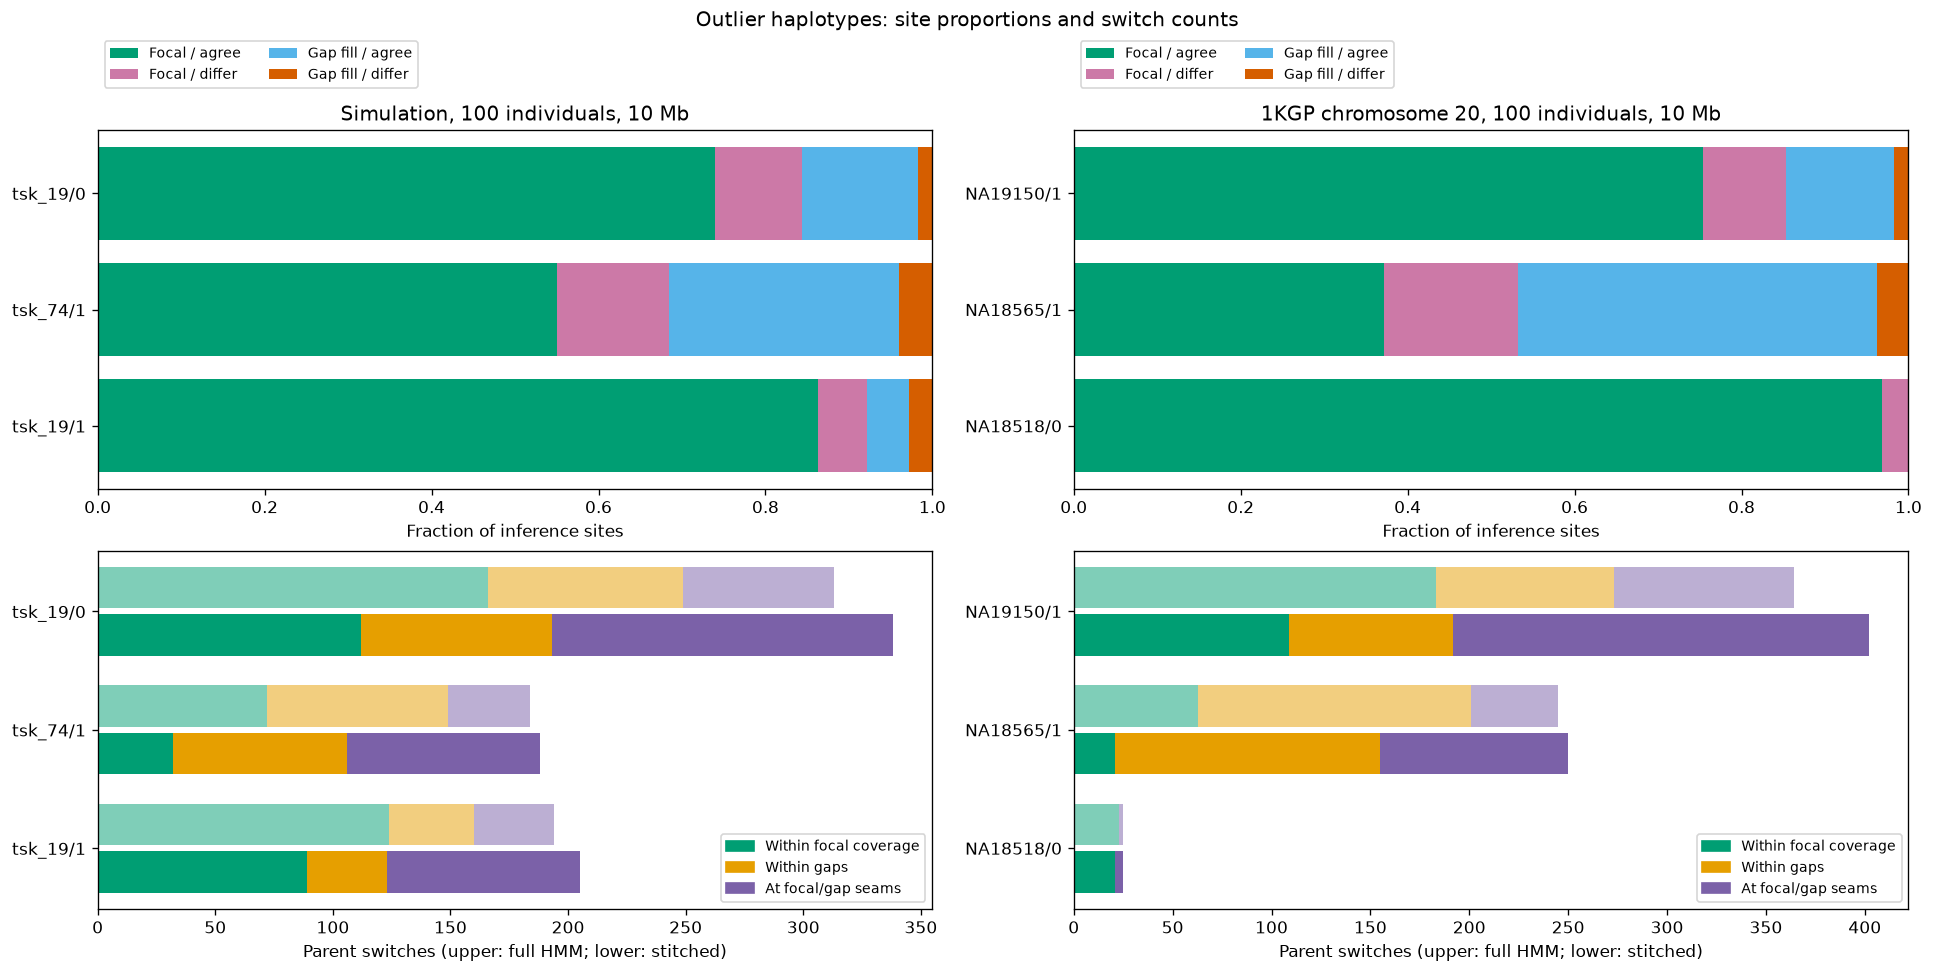

,dataset,haplotype,method,Within focal coverage,Within gaps,At focal/gap seams
0,"Simulation, 100 individuals, 10 Mb",tsk_19/0,full,166,83,64
1,"Simulation, 100 individuals, 10 Mb",tsk_74/1,full,72,77,35
2,"Simulation, 100 individuals, 10 Mb",tsk_19/1,full,124,36,34
3,"Simulation, 100 individuals, 10 Mb",tsk_19/0,stitched,112,81,145
4,"Simulation, 100 individuals, 10 Mb",tsk_74/1,stitched,32,74,82
5,"Simulation, 100 individuals, 10 Mb",tsk_19/1,stitched,89,34,82
6,"1KGP chromosome 20, 100 individuals, 10 Mb",NA19150/1,full,183,90,91
7,"1KGP chromosome 20, 100 individuals, 10 Mb",NA18565/1,full,63,138,44
8,"1KGP chromosome 20, 100 individuals, 10 Mb",NA18518/0,full,23,0,2
9,"1KGP chromosome 20, 100 individuals, 10 Mb",NA19150/1,stitched,109,83,210


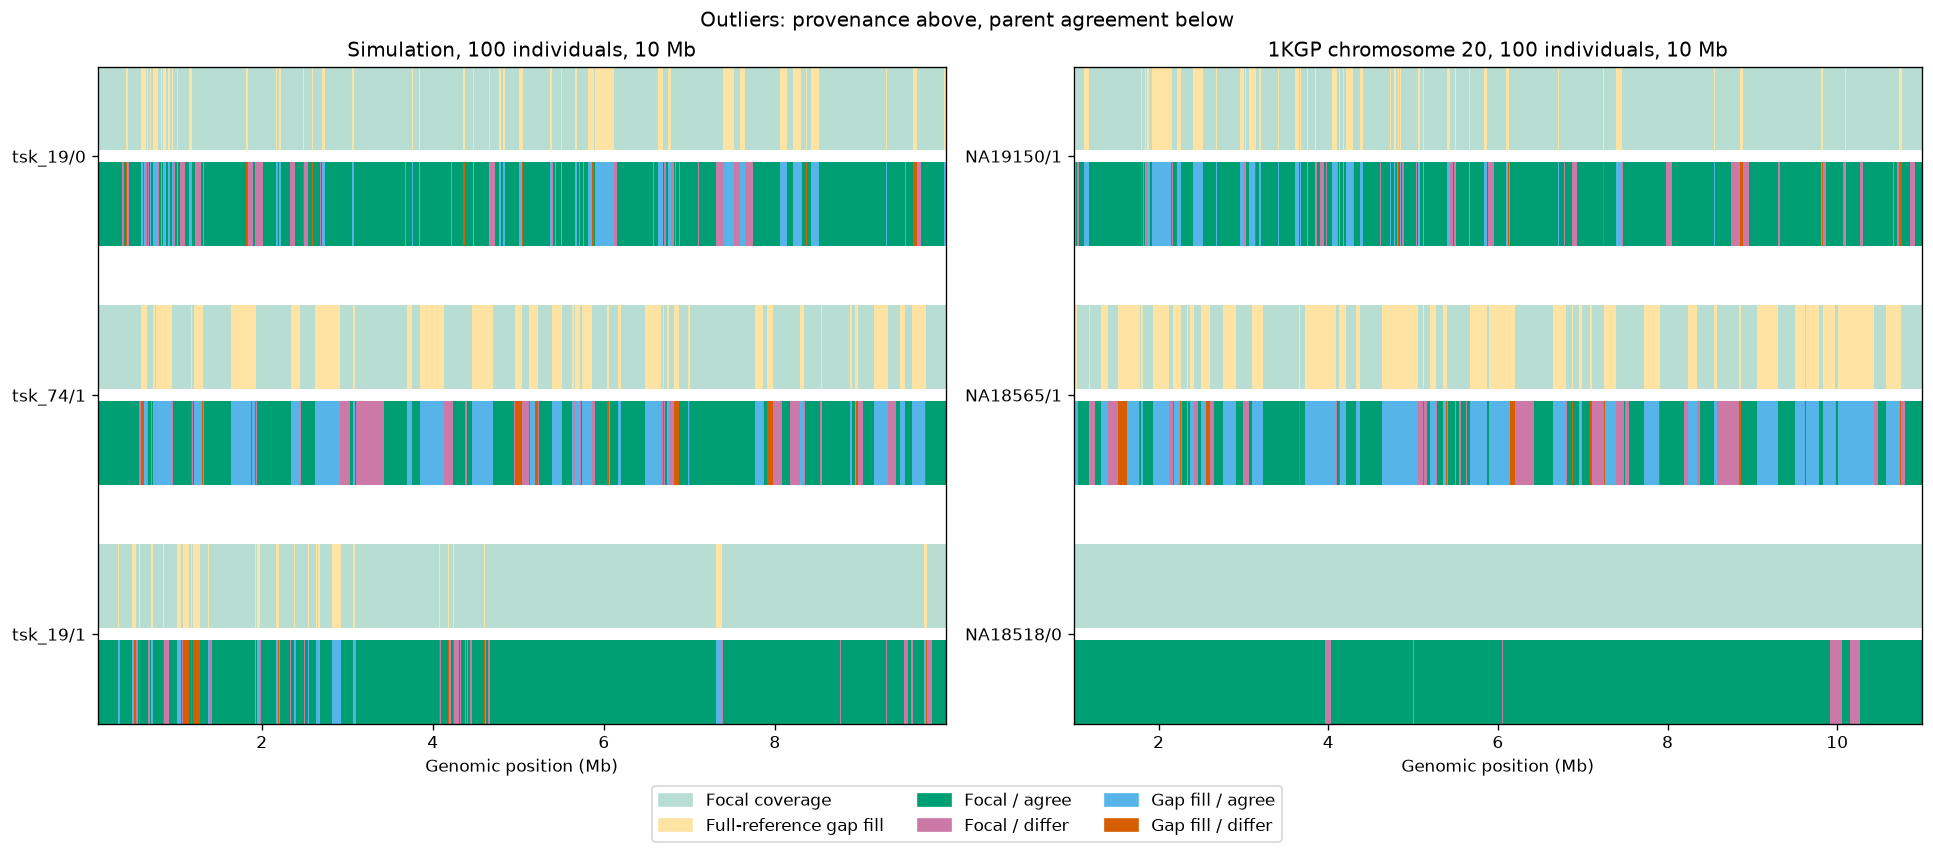

In [17]:
outlier_summary = nb_plot.plot_case_summary(
    outlier_datasets,
    "Outlier haplotypes: site proportions and switch counts",
    plot_category_colors=["#009E73", "#CC79A7", "#56B4E9", "#D55E00"],
    plot_category_labels=[
        "Focal / agree",
        "Focal / differ",
        "Gap fill / agree",
        "Gap fill / differ",
    ],
    plot_cohort_figsize=[16, 8],
    plot_switch_colors=["#009E73", "#E69F00", "#7B61A8"],
    plot_switch_labels=["Within focal coverage", "Within gaps", "At focal/gap seams"],
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.save_notebook_figure(
    outlier_summary.figure, outlier_output_dir / "outlier_site_and_switch_summary.png"
)
nb_plot.plot_summary_plots(
    category_cmap=category_cmap,
    category_norm=category_norm,
    coverage_handles=coverage_handles,
    outlier_datasets=outlier_datasets,
    outlier_output_dir=outlier_output_dir,
    outlier_summary=outlier_summary,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

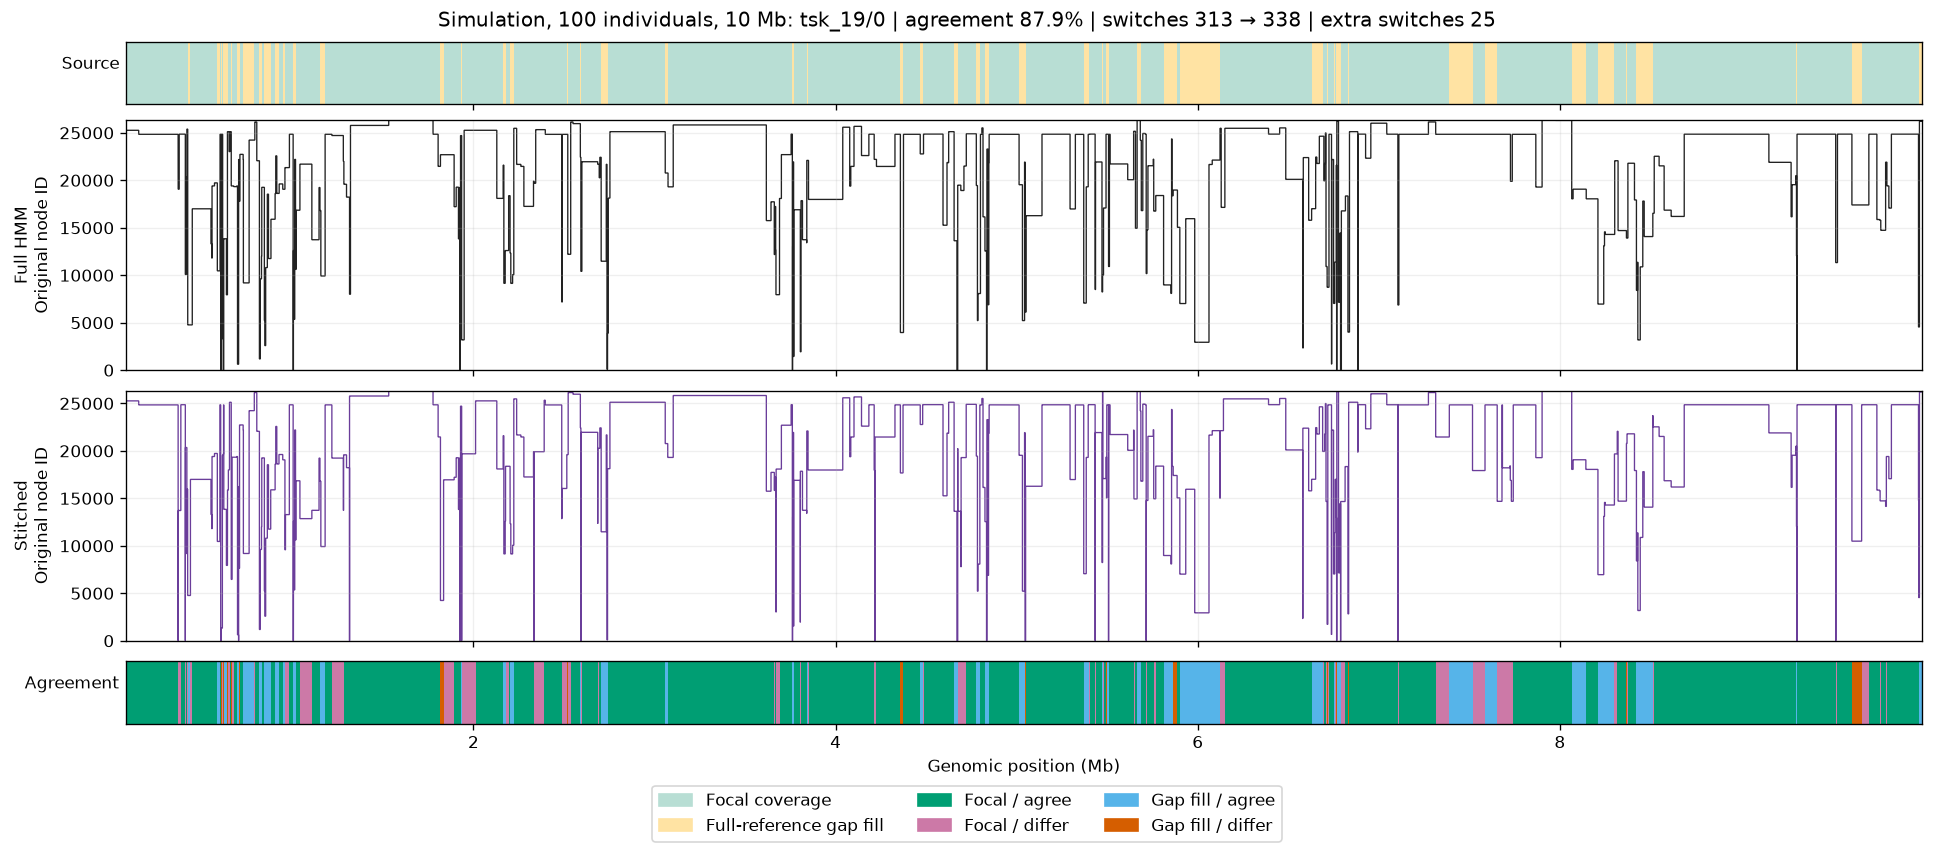

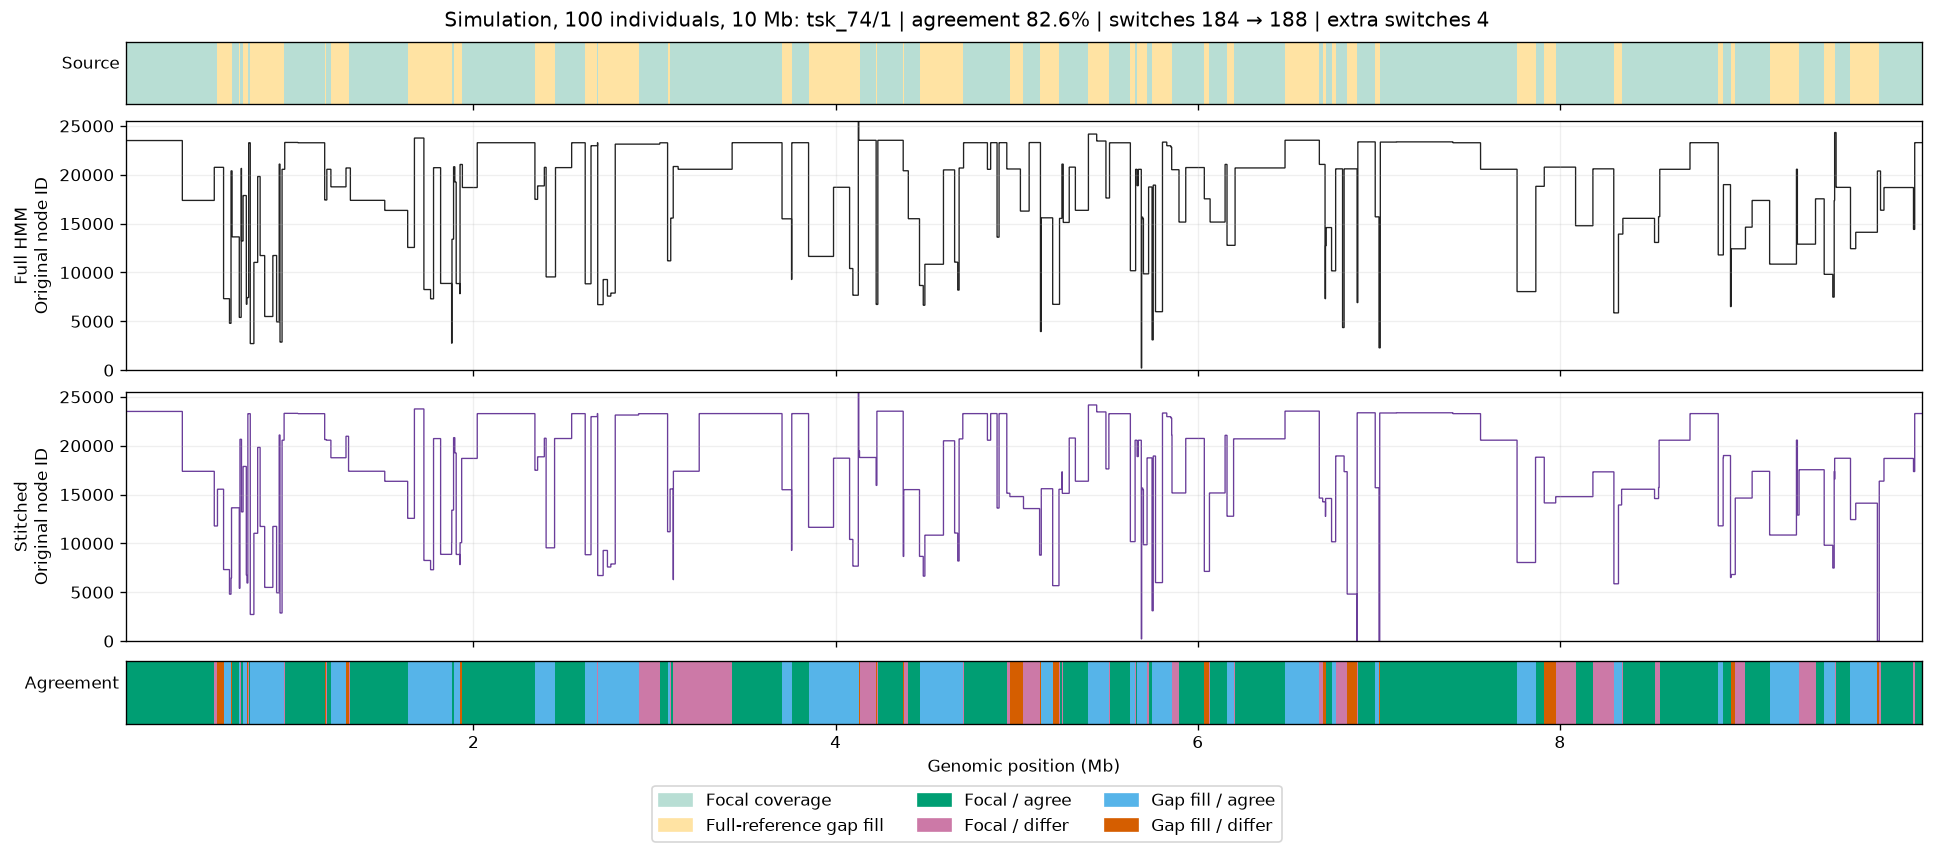

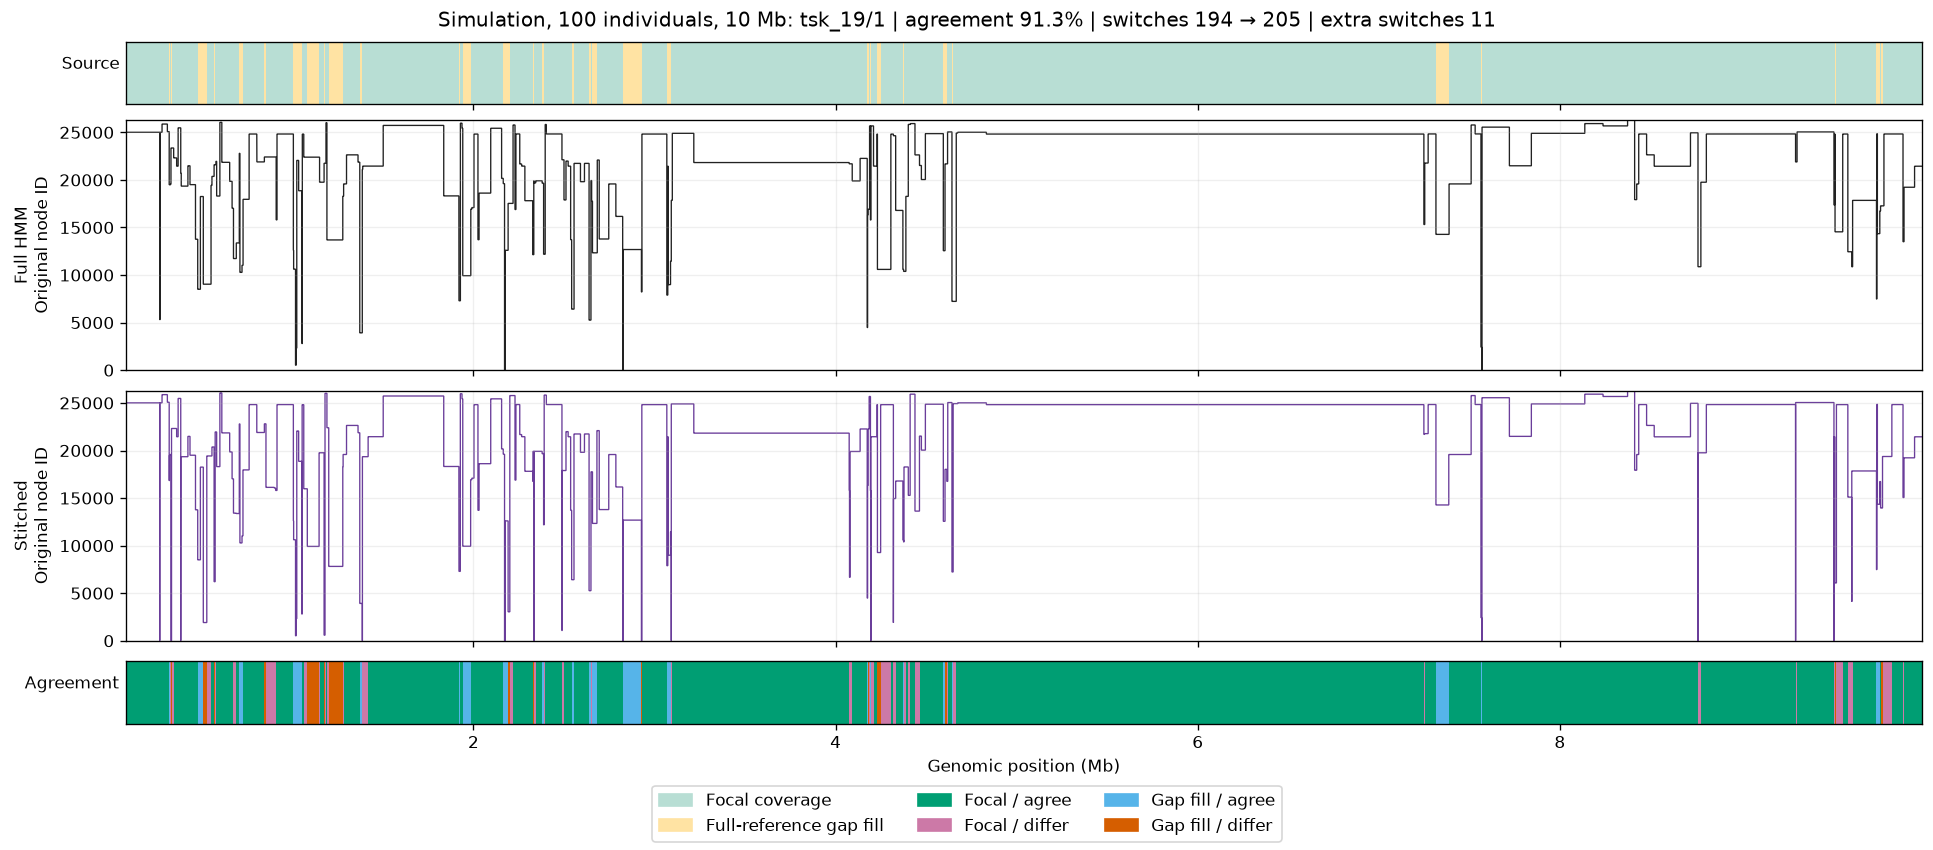

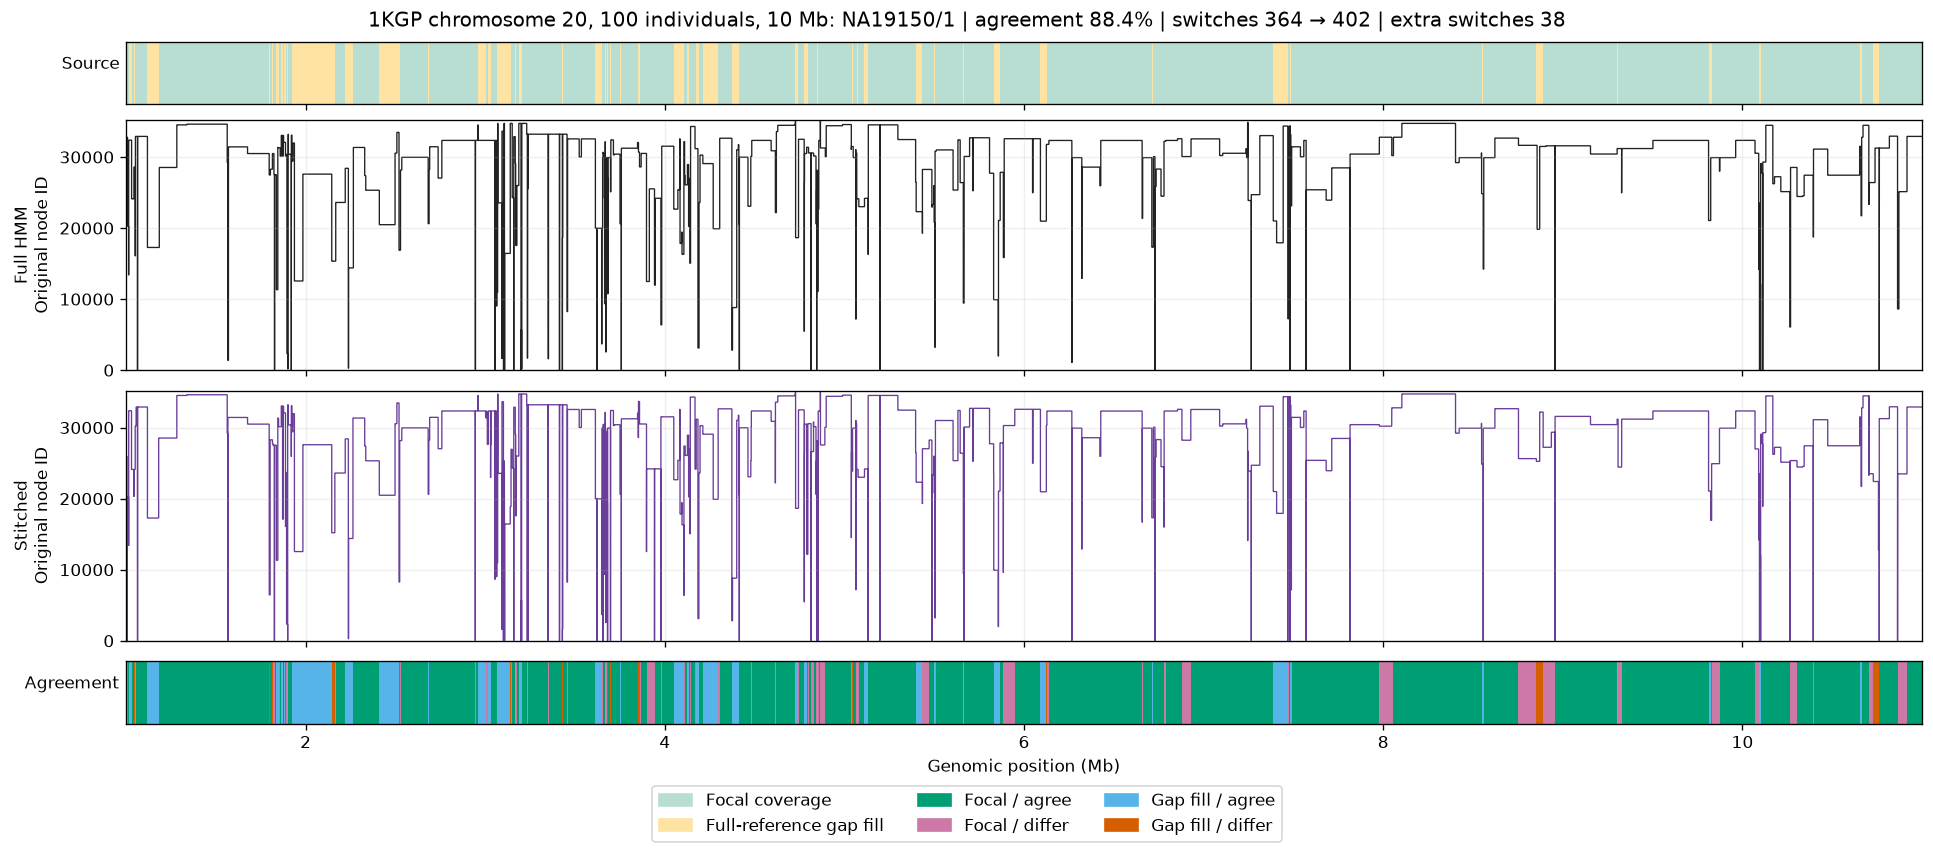

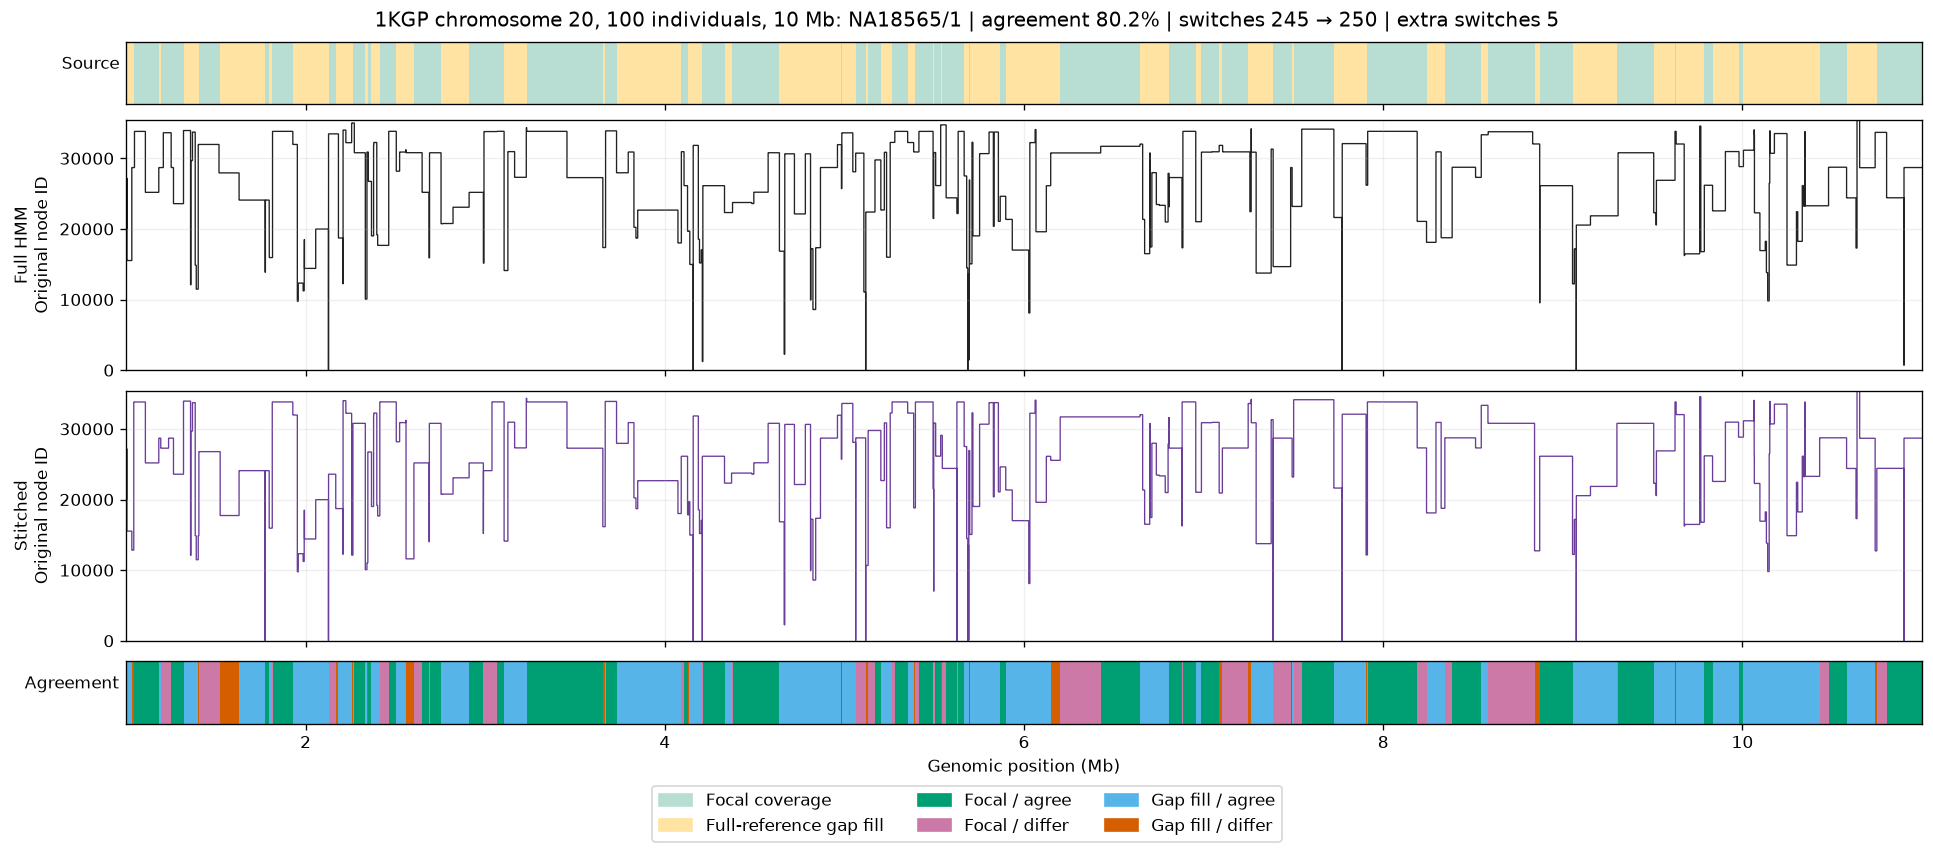

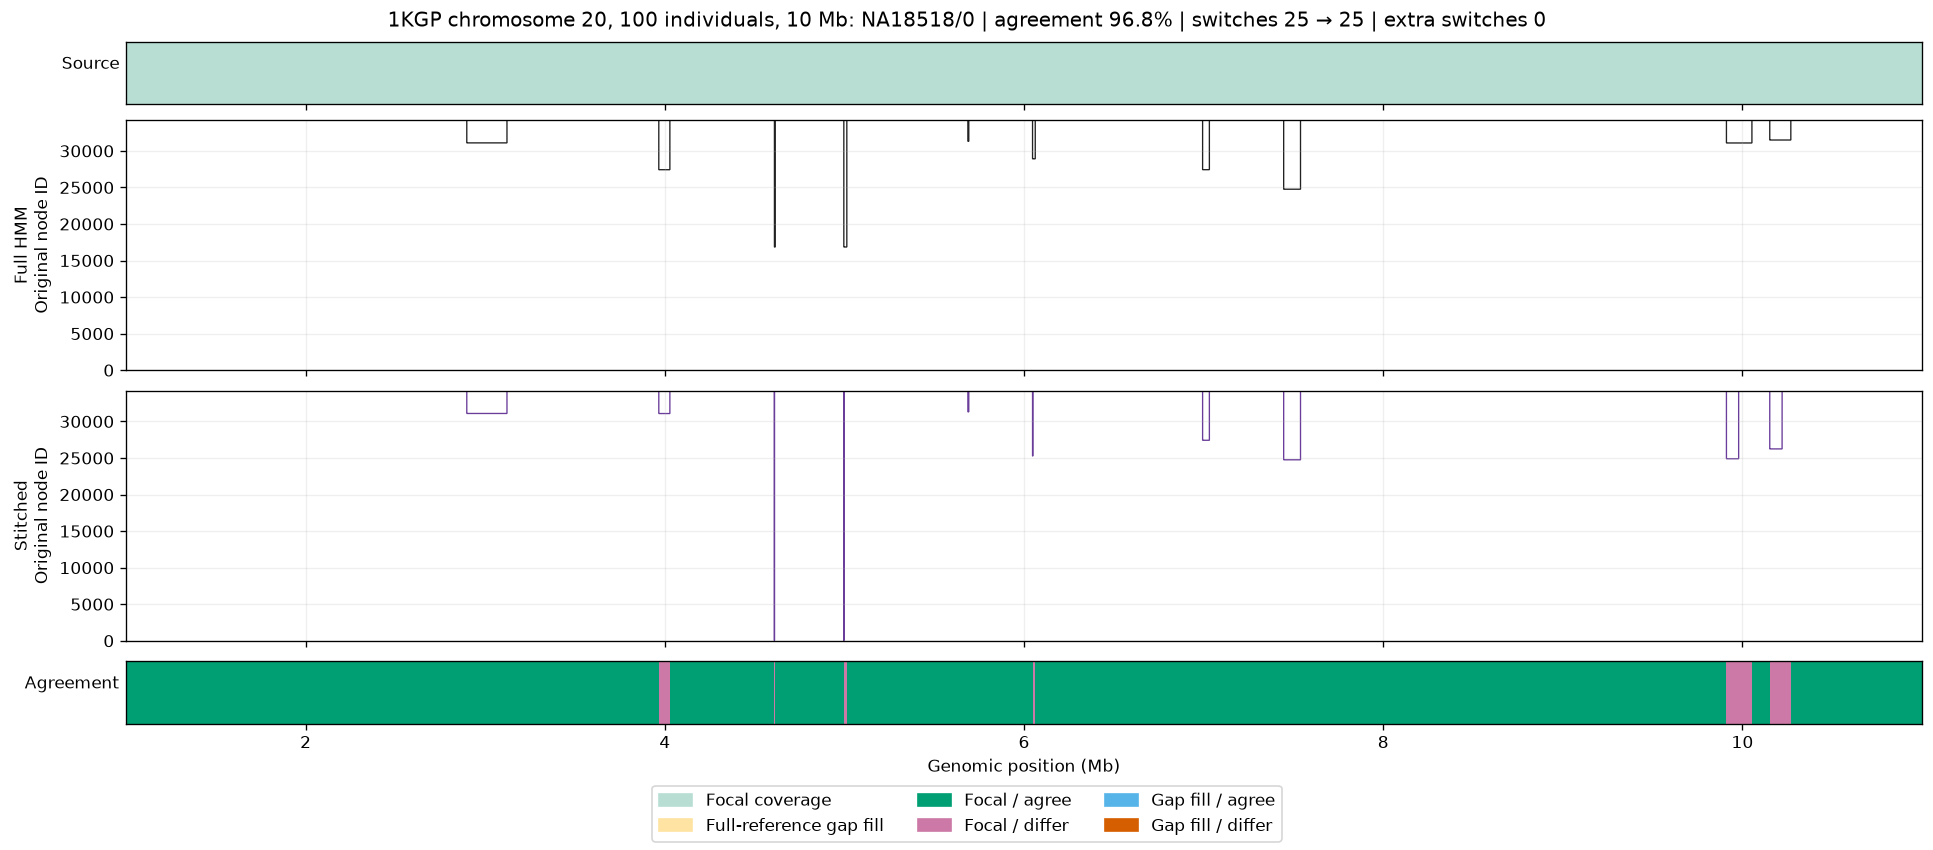

In [18]:
nb_plot.plot_summary_plots_2(
    category_cmap=category_cmap,
    category_norm=category_norm,
    coverage_handles=coverage_handles,
    outlier_case_datasets=outlier_case_datasets,
    outlier_output_dir=outlier_output_dir,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Deep dive

A switch has a position and a directed parent transition, such as A → B.
Losing a focal-interior switch and gaining a seam switch can therefore mean
that the same transition moved, or that the ordered parent sequence changed.
We distinguish these using maximal runs of parent disagreement, including one
agreeing site on each side when both flanks exist:

- **Identical switch:** same position and same parents on both sides.
- **Shifted parent sequence:** both flanking parents agree and the complete
  ordered parent sequences are identical, while switch positions differ.
- **Changed parent sequence:** flanking parents agree but the ordered sequences
  differ. Some individual transitions may still be shared within these regions.
- **Unanchored difference:** a disagreement reaches an inference-site boundary,
  so there is no pair of agreeing flanks for this comparison.

The switch-count partition includes every full and stitched switch. Proven
relocations preserve parent IDs and direction; they are not inferred by pairing
whichever switch happens to be closest. Counts associated with a gap include
its interior and its existing left/right seams. They are signed net differences,
and omit switches in focal interiors. This distinction matters when a switch
moves between the two types of region.

In [7]:
outlier_analyses = {}
outlier_windows = {}
outlier_change_rows = []
outlier_relocation_rows = []
for dataset in outlier_case_datasets:
    case = dataset.primary
    key = (dataset.name, case.label)
    analysis = nb_utils.analyse_outlier_paths(
        dataset,
        plot_outliers_transition_kinds=[
            "Identical switch",
            "Shifted parent sequence",
            "Changed parent sequence",
            "Unanchored difference",
        ],
    )
    outlier_analyses[key] = analysis
    outlier_windows[key] = nb_utils.select_outlier_windows(
        dataset,
        analysis,
        config=config,
        plot_outliers_transition_kinds_2="Changed parent sequence",
    )
    prefix = f"{dataset.name}_{case.summary['sample_id'].lower()}_{case.summary['ploidy_index']}"
    for name, table in (
        ("gaps", analysis.gaps),
        ("parent_differences", analysis.divergences),
        ("relocated_switches", analysis.relocations),
    ):
        table.to_csv(outlier_output_dir / f"{prefix}_{name}.csv", index=False)
    for row in analysis.switch_counts.itertuples():
        outlier_change_rows.append(
            {
                "dataset": dataset.name,
                "haplotype": case.label,
                "population": case.summary["population"],
                "kind": row.kind,
                "full_switches": row.full,
                "stitched_switches": row.stitched,
                "extra_switches": row.stitched - row.full,
            }
        )
    for row in analysis.relocations.itertuples():
        outlier_relocation_rows.append(
            {
                "dataset": dataset.name,
                "haplotype": case.label,
                "full_location": row.full_location,
                "stitched_location": row.stitched_location,
                "absolute_shift_sites": abs(row.shift_sites),
            }
        )
outlier_parent_changes = pd.DataFrame(outlier_change_rows)
outlier_parent_changes.to_csv(
    outlier_output_dir / "outlier_parent_transition_summary.csv", index=False
)
ipython_display.display(outlier_parent_changes)
outlier_relocations = pd.DataFrame(outlier_relocation_rows)
relocation_summary = outlier_relocations.groupby(
    ["dataset", "haplotype", "full_location", "stitched_location"]
).absolute_shift_sites.agg(["count", "median", "max"])
print("Proven parent-preserving relocations (haplotypes without any are absent):")
ipython_display.display(relocation_summary)
relocation_summary.to_csv(outlier_output_dir / "outlier_relocation_summary.csv")

,dataset,haplotype,population,kind,full_switches,stitched_switches,extra_switches
0,out_of_africa_n100_10mbp,tsk_19/0,YRI,Identical switch,186,186,0
1,out_of_africa_n100_10mbp,tsk_19/0,YRI,Shifted parent sequence,22,22,0
2,out_of_africa_n100_10mbp,tsk_19/0,YRI,Changed parent sequence,105,130,25
3,out_of_africa_n100_10mbp,tsk_19/0,YRI,Unanchored difference,0,0,0
4,out_of_africa_n100_10mbp,tsk_74/1,CHB,Identical switch,107,107,0
5,out_of_africa_n100_10mbp,tsk_74/1,CHB,Shifted parent sequence,18,18,0
6,out_of_africa_n100_10mbp,tsk_74/1,CHB,Changed parent sequence,59,63,4
7,out_of_africa_n100_10mbp,tsk_74/1,CHB,Unanchored difference,0,0,0
8,out_of_africa_n100_10mbp,tsk_19/1,YRI,Identical switch,109,109,0
9,out_of_africa_n100_10mbp,tsk_19/1,YRI,Shifted parent sequence,14,14,0


Proven parent-preserving relocations (haplotypes without any are absent):


count  \
dataset                  haplotype full_location stitched_location          
out_of_africa_n100_10mbp tsk_19/0  focal         seam                  22   
                         tsk_19/1  focal         seam                  14   
                         tsk_74/1  focal         seam                  18   
tgp_chr20_n100           NA18565/1 focal         seam                  14   
                         NA19150/1 focal         seam                  32   

                                                                    median  \
dataset                  haplotype full_location stitched_location           
out_of_africa_n100_10mbp tsk_19/0  focal         seam                  9.5   
                         tsk_19/1  focal         seam                  4.0   
                         tsk_74/1  focal         seam                 20.5   
tgp_chr20_n100           NA18565/1 focal         seam                 26.0   
                         NA19150/1 focal         seam                  6.0   

                                                                    max  
dataset                  haplotype full_location stitched_location       
out_of_africa_n100_10mbp tsk_19/0  focal         seam                74  
                         tsk_19/1  focal         seam                82  
                         tsk_74/1  focal         seam               625  
tgp_chr20_n100           NA18565/1 focal         seam               315  
                         NA19150/1 focal         seam                50

The bars below distinguish relocation of a preserved parent sequence from
switches occurring in regions with different parent sequences. Relocation
preserves the number of transitions within its disagreement run. A positive
net excess in a changed-sequence region cannot be explained by moving the
same complete sequence of parent transitions alone.
A gap with complete parent agreement can still gain seam switches when its
neighbouring focal parents differ from the full path.

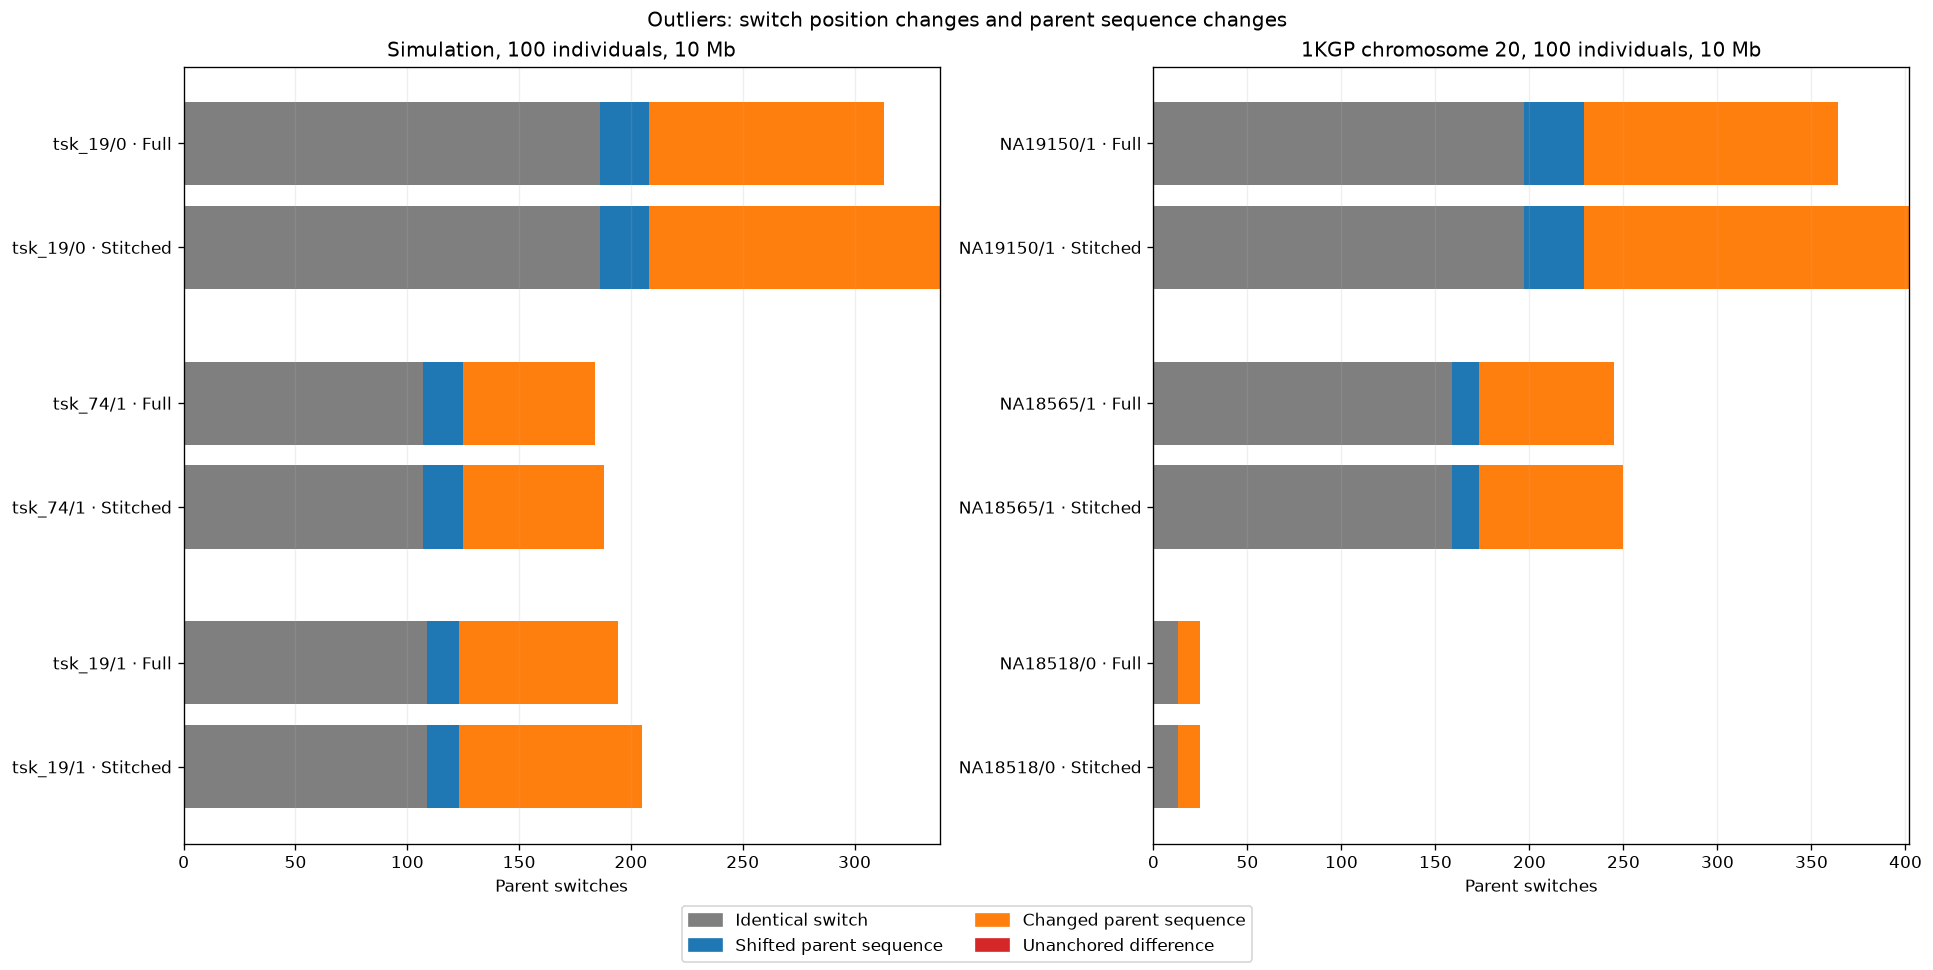

In [21]:
nb_plot.plot_deep_dive(
    outlier_analyses=outlier_analyses,
    outlier_datasets=outlier_datasets,
    outlier_output_dir=outlier_output_dir,
    figsize=[16, 8],
    height=0.32,
    xlabel="Parent switches",
    alpha=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

Inspect every outlier's gap table and genomic switch distribution below.
Switch-position rugs compare positions only; the parent-sequence tables and
categorical zooms establish whether the parents also change. The cumulative
curve accounts for switch gains and losses across the entire inference span.
Gap plots label gaps as g0, g1, …, matching their table indices.

Simulation, 100 individuals, 10 Mb: tsk_19/0 (YRI)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
38,38,20853,20855,2,0.0,0,2,2,0,False,False
0,0,1493,1494,1,0.0,1,2,1,0,True,False
1,1,1669,1670,1,0.0,1,2,1,0,True,False
17,17,5929,5930,1,0.0,1,2,1,0,True,False
27,27,11921,11922,1,0.0,1,2,1,0,True,False
43,43,24402,24403,1,0.0,1,2,1,0,True,False
49,49,25654,25655,1,0.0,1,2,1,0,True,False
59,59,31423,31424,1,0.0,1,2,1,0,True,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
62,62,33978,34216,238,0,Changed parent sequence,2,5,3,24844 → 19893 → 24841,24844 → 18213 → 18429 → 16896 → 14688 → 24841
60,60,33258,33550,292,0,Changed parent sequence,0,2,2,24844,24844 → 17926 → 24844
61,61,33817,33973,156,0,Changed parent sequence,0,2,2,24844,24844 → 14685 → 24844
42,42,24673,24695,22,12,Changed parent sequence,1,3,2,17083 → 24850,17083 → 19348 → 15038 → 24850
19,19,8669,9010,341,1,Changed parent sequence,2,3,1,24709 → 3188 → 25266,24709 → 1 → 19690 → 25266
59,59,32385,32709,324,0,Changed parent sequence,1,2,1,26143 → 24844,26143 → 21460 → 24844
17,17,8149,8469,320,84,Changed parent sequence,2,3,1,21467 → 22694 → 17219,21467 → 4244 → 16951 → 17219
15,15,5479,5787,308,0,Changed parent sequence,3,4,1,24845 → 24715 → 22000 → 19582,24845 → 19238 → 19239 → 13737 → 19582


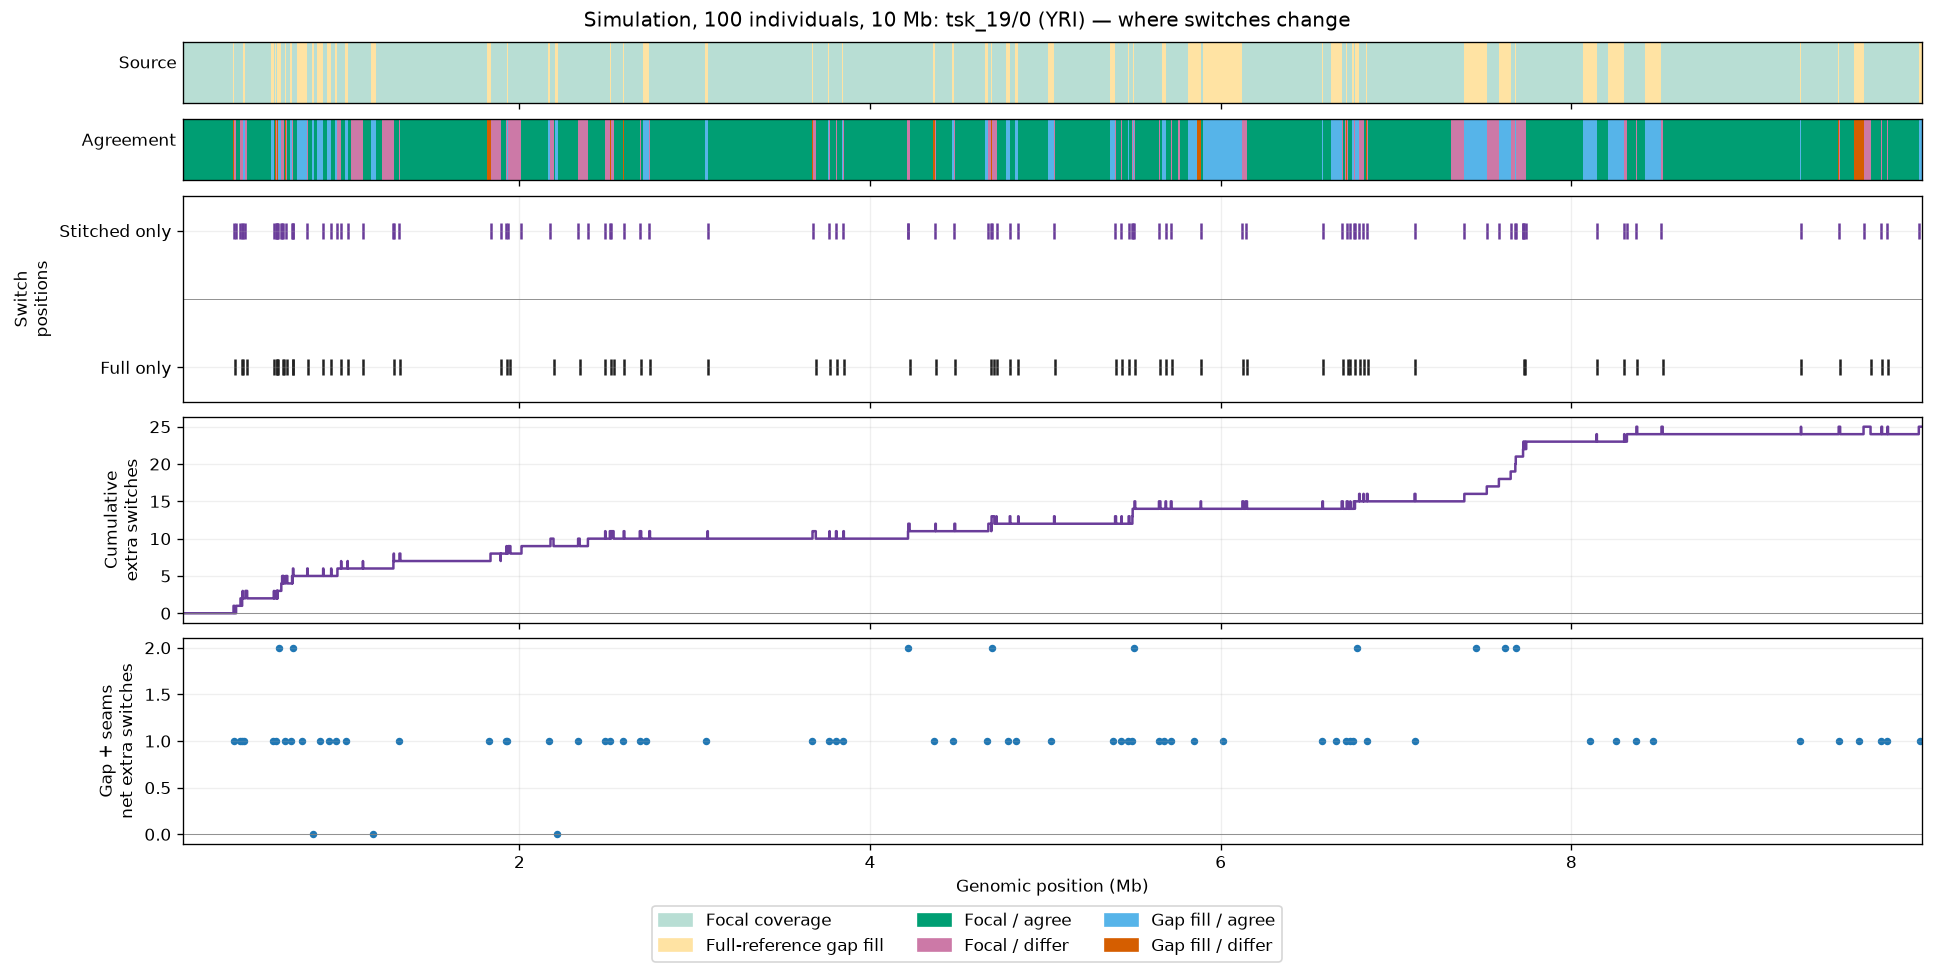

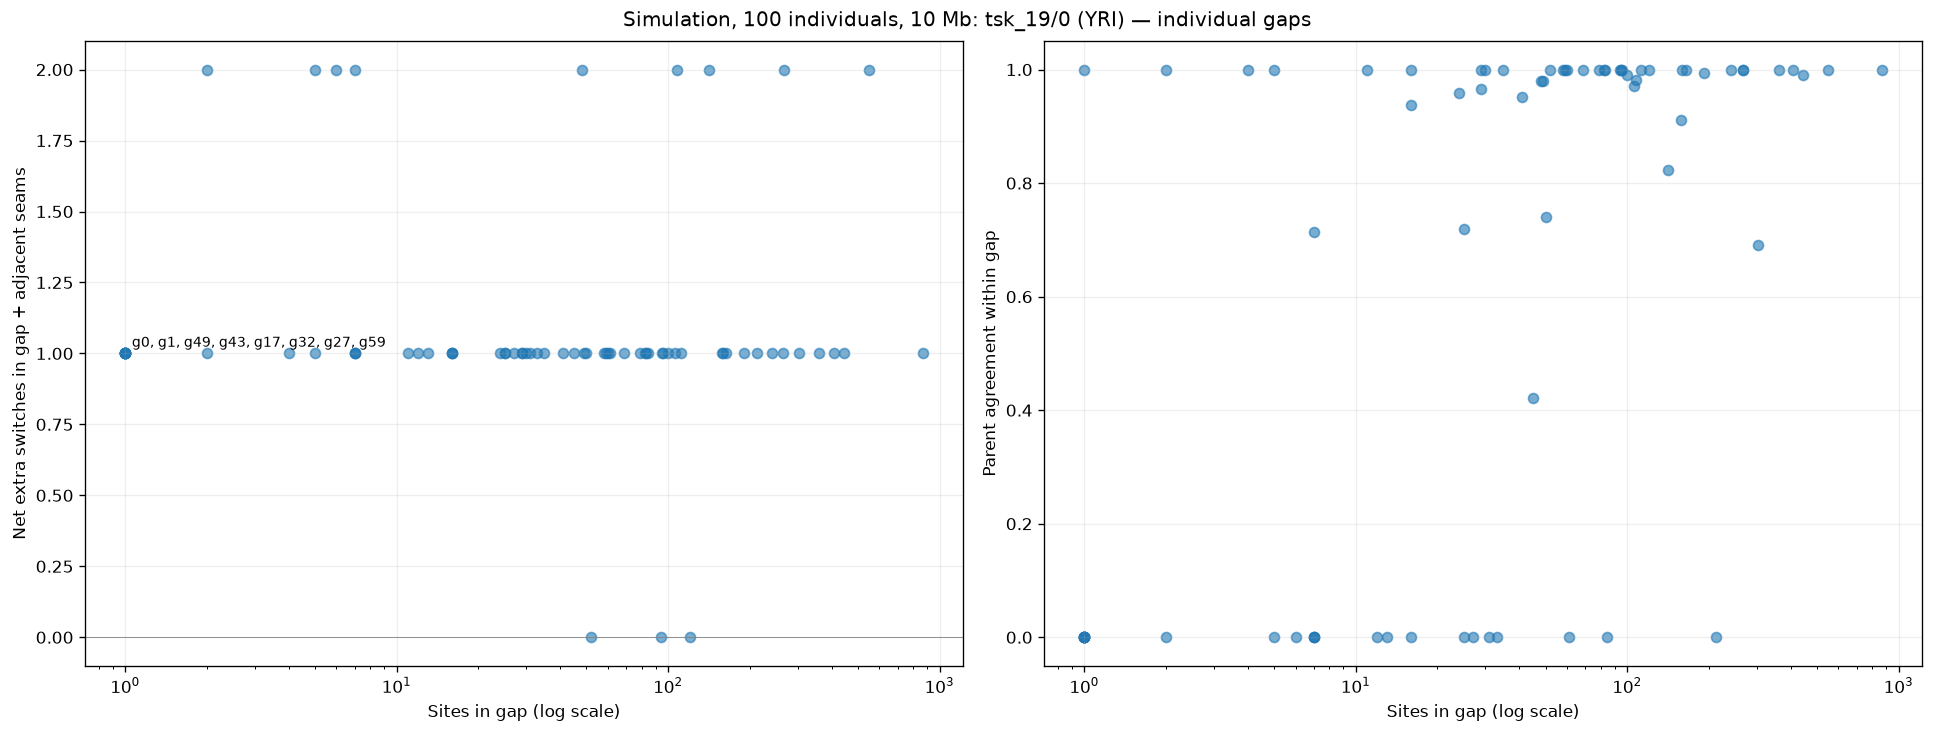

Simulation, 100 individuals, 10 Mb: tsk_74/1 (CHB)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
12,12,13924,13929,5,0.0,1,2,1,0,True,False
20,20,23541,23552,11,0.0,1,2,1,0,True,False
15,15,18761,18773,12,0.0,1,2,1,0,False,False
1,1,3148,3163,15,1.0,1,2,1,0,True,False
16,16,19420,19436,16,0.0,1,2,1,0,True,False
35,35,37778,37799,21,1.0,1,2,1,0,False,False
4,4,5318,5350,32,0.0,1,2,1,0,True,False
11,11,13761,13826,65,1.0,1,2,1,0,True,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
33,33,36093,36626,533,0,Changed parent sequence,2,3,1,14785 → 20608 → 5863,14785 → 17322 → 17321 → 5863
29,29,29936,30461,525,232,Changed parent sequence,5,6,1,10164 → 20607 → 4361 → 20607 → 6918 → 23368,10164 → 17342 → 18950 → 17342 → 4811 → 1 → 23368
15,15,18362,18792,430,20,Changed parent sequence,3,4,1,25484 → 23531 → 6730 → 23531,25484 → 19471 → 18792 → 15935 → 23531
0,0,2488,2726,238,155,Changed parent sequence,2,3,1,17377 → 20764 → 7318,17377 → 11782 → 15546 → 7318
13,13,13924,15255,1331,5,Changed parent sequence,3,3,0,15570 → 20847 → 20565 → 23286,15570 → 6278 → 17385 → 23286
18,18,22077,22932,855,361,Changed parent sequence,5,5,0,23287 → 20594 → 16283 → 23300 → 3955 → 15595,23287 → 15134 → 14791 → 13563 → 8796 → 15595
32,32,34904,35661,757,259,Changed parent sequence,2,2,0,18820 → 20784 → 14785,18820 → 14141 → 14785
11,11,12929,13554,625,0,Shifted parent sequence,1,1,0,23138 → 23275,23138 → 23275


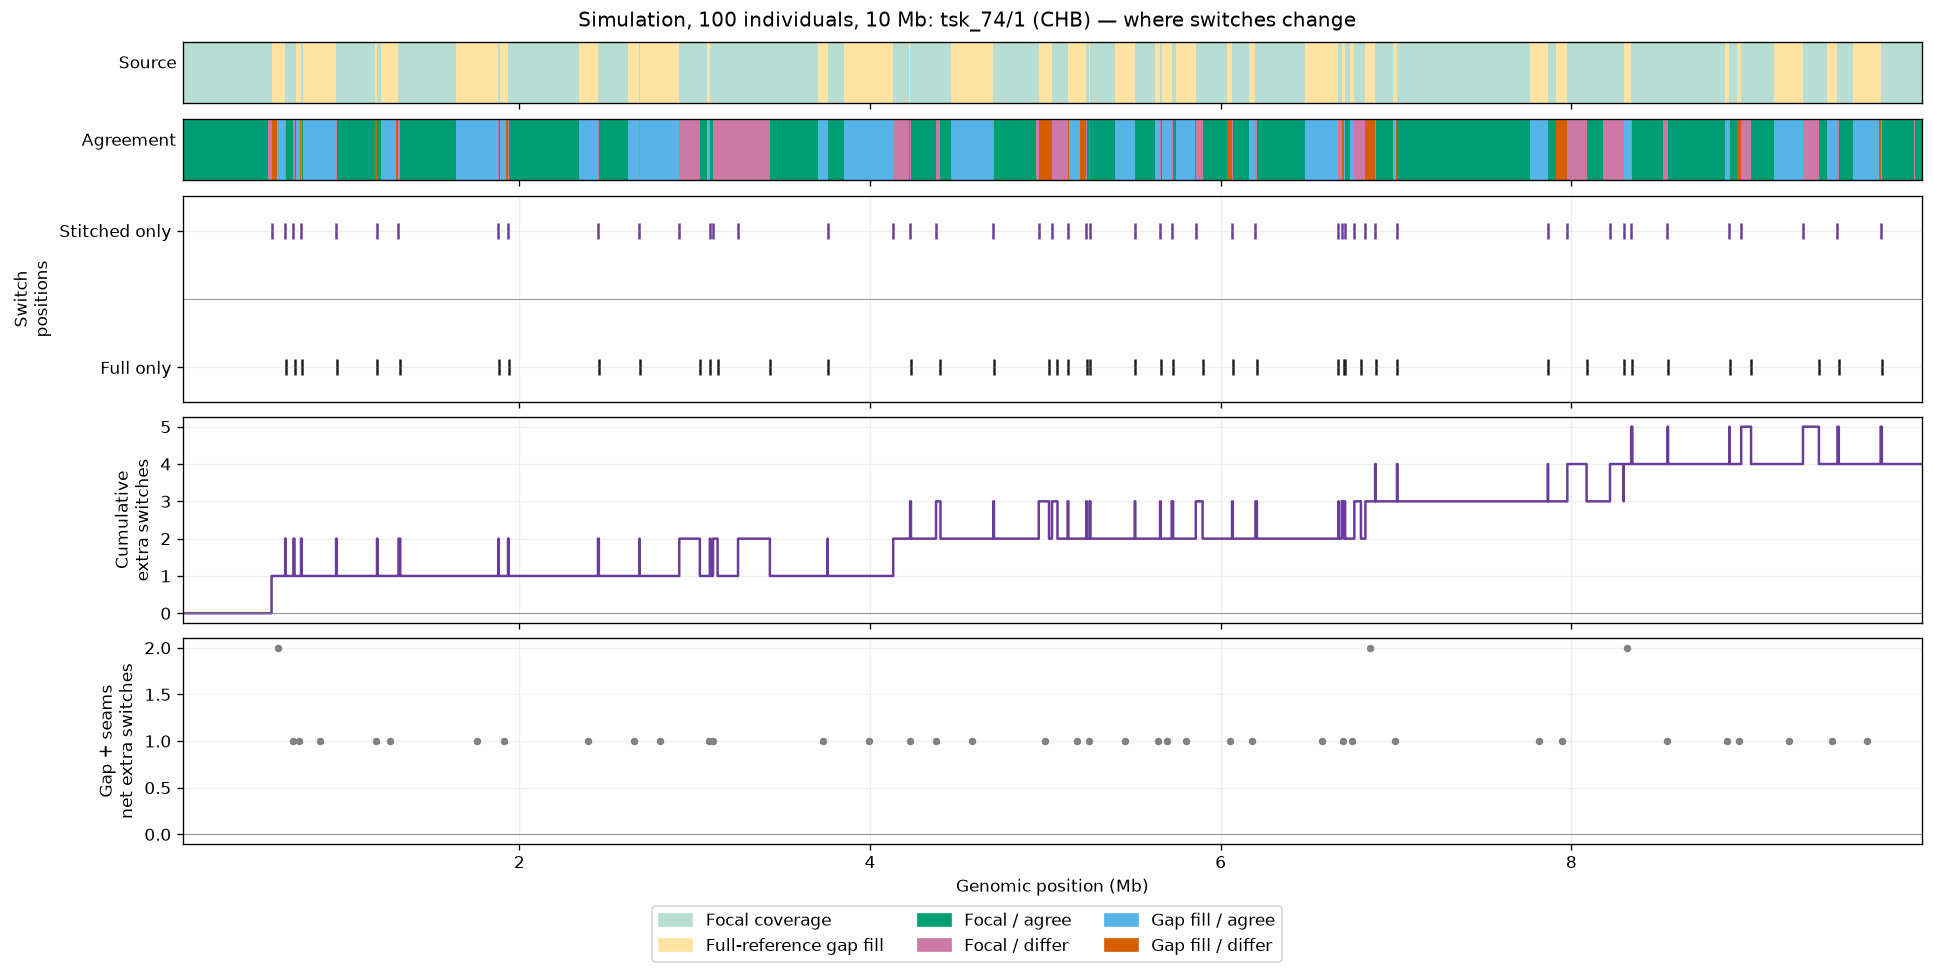

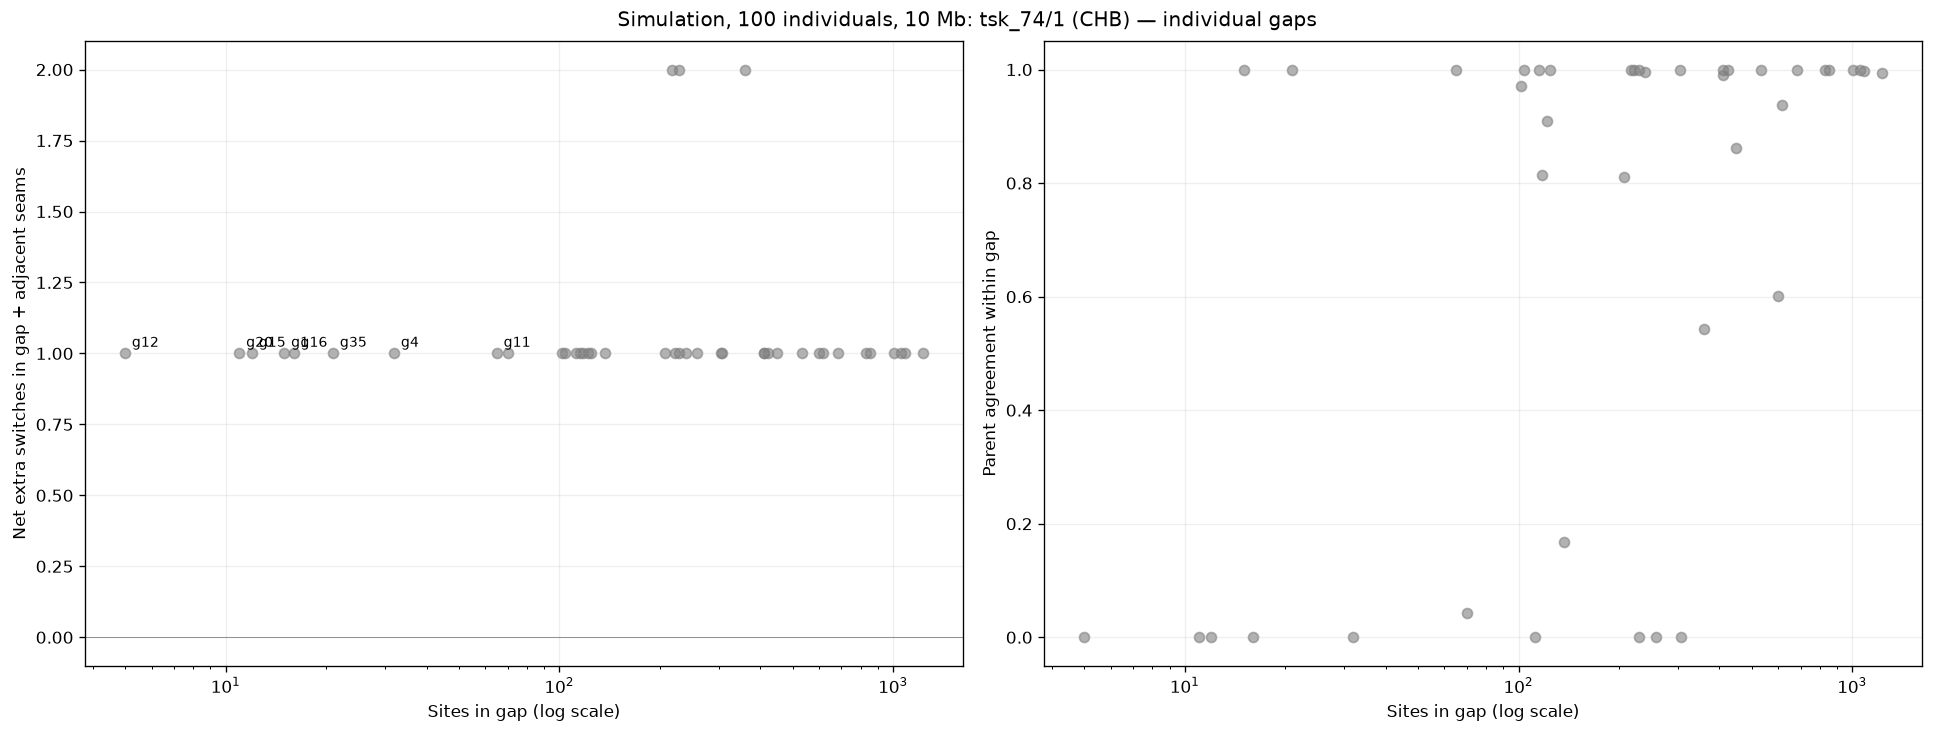

Simulation, 100 individuals, 10 Mb: tsk_19/1 (YRI)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
0,0,1016,1017,1,0.0,1,2,1,0,True,False
34,34,38763,38764,1,0.0,1,2,1,0,True,False
36,36,42186,42187,1,0.0,1,2,1,0,True,False
38,38,42585,42586,1,0.0,1,2,1,0,False,False
35,35,41266,41268,2,0.0,1,2,1,0,True,False
3,3,1571,1574,3,0.0,1,2,1,0,True,False
28,28,19172,19175,3,0.0,1,2,1,0,True,False
18,18,10965,10972,7,0.0,1,2,1,0,True,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
9,9,3749,4042,293,39,Changed parent sequence,2,4,2,21894 → 22413 → 15802,21894 → 22804 → 16126 → 16054 → 15802
12,12,4738,5199,461,349,Changed parent sequence,2,3,1,24819 → 22394 → 19762,24819 → 15977 → 9918 → 19762
14,14,5362,5760,398,342,Changed parent sequence,2,3,1,26011 → 13692 → 18289,26011 → 22394 → 7816 → 18289
47,47,43194,43481,287,46,Changed parent sequence,2,3,1,16735 → 17274 → 24831,16735 → 13954 → 19371 → 24831
16,16,6201,6325,124,3,Changed parent sequence,2,3,1,3923 → 21103 → 21454,3923 → 1 → 19350 → 21454
29,29,18135,18216,81,18,Changed parent sequence,2,3,1,21827 → 21694 → 19898,21827 → 15814 → 6669 → 19898
37,37,20453,20526,73,41,Changed parent sequence,2,3,1,12558 → 21687 → 25043,12558 → 18021 → 16757 → 25043
33,33,19172,19234,62,3,Changed parent sequence,2,3,1,24820 → 24646 → 16794,24820 → 1901 → 14953 → 16794


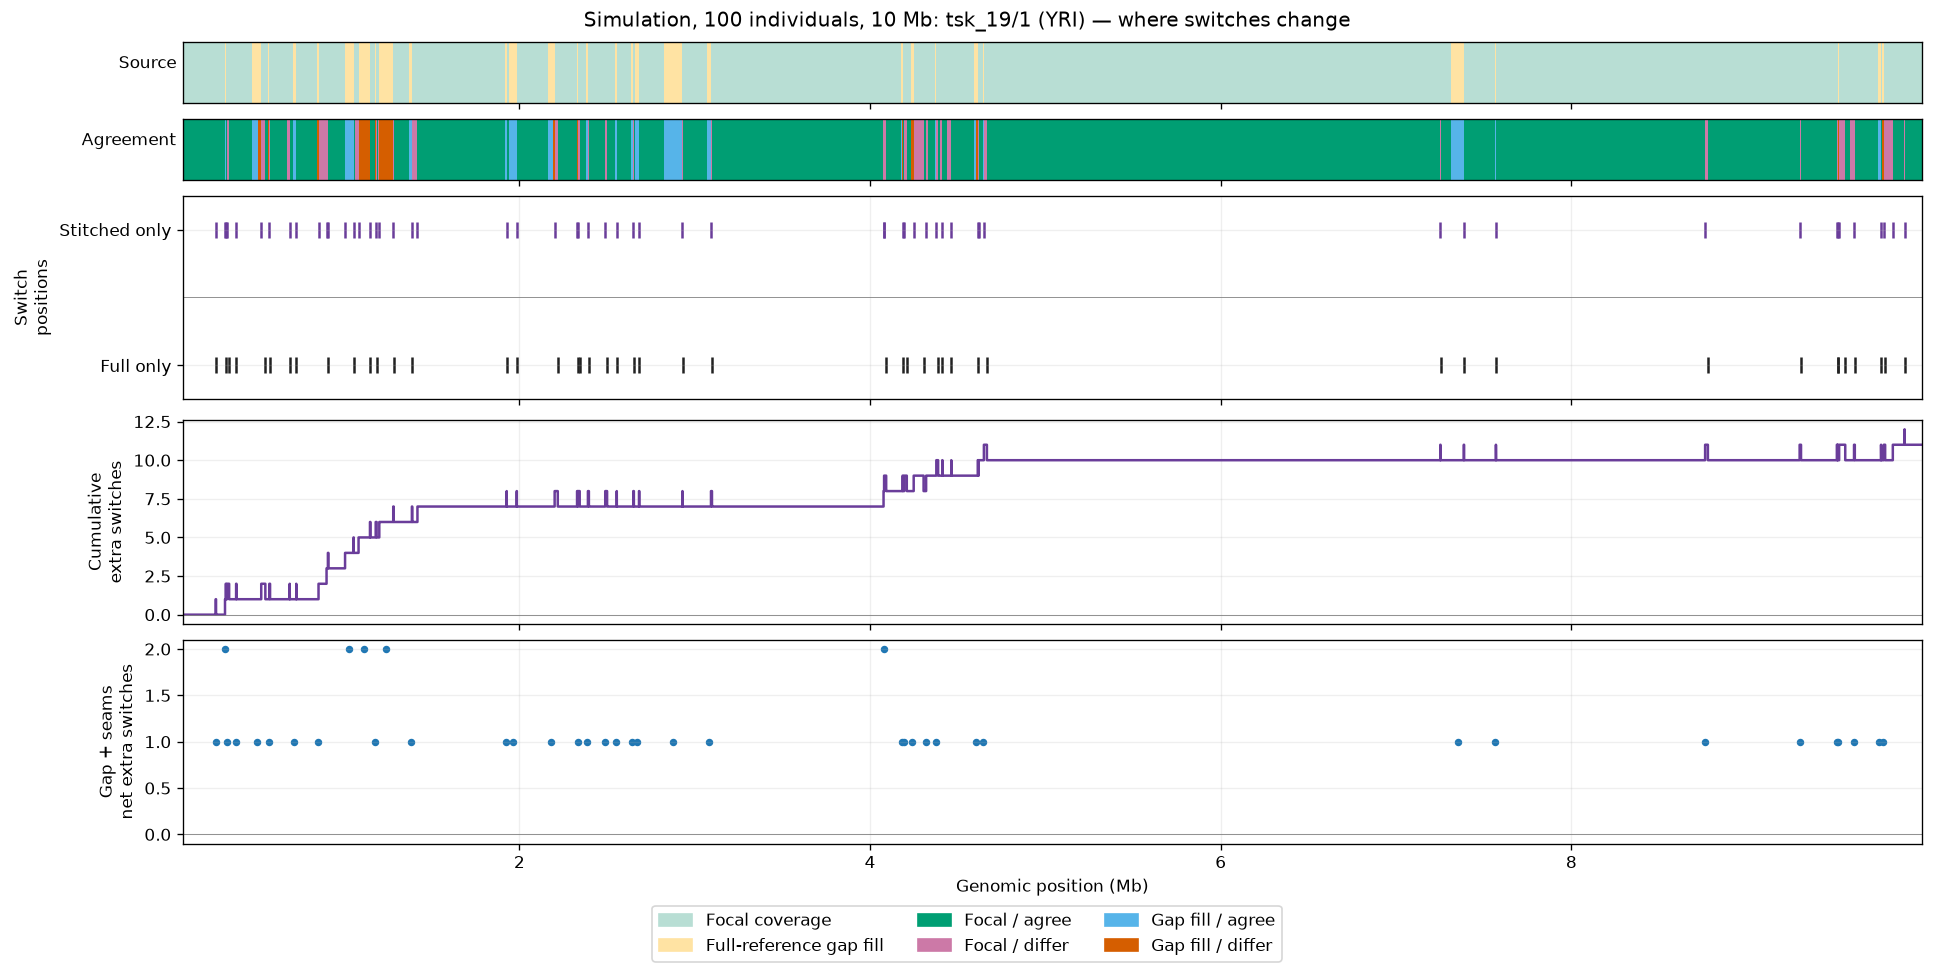

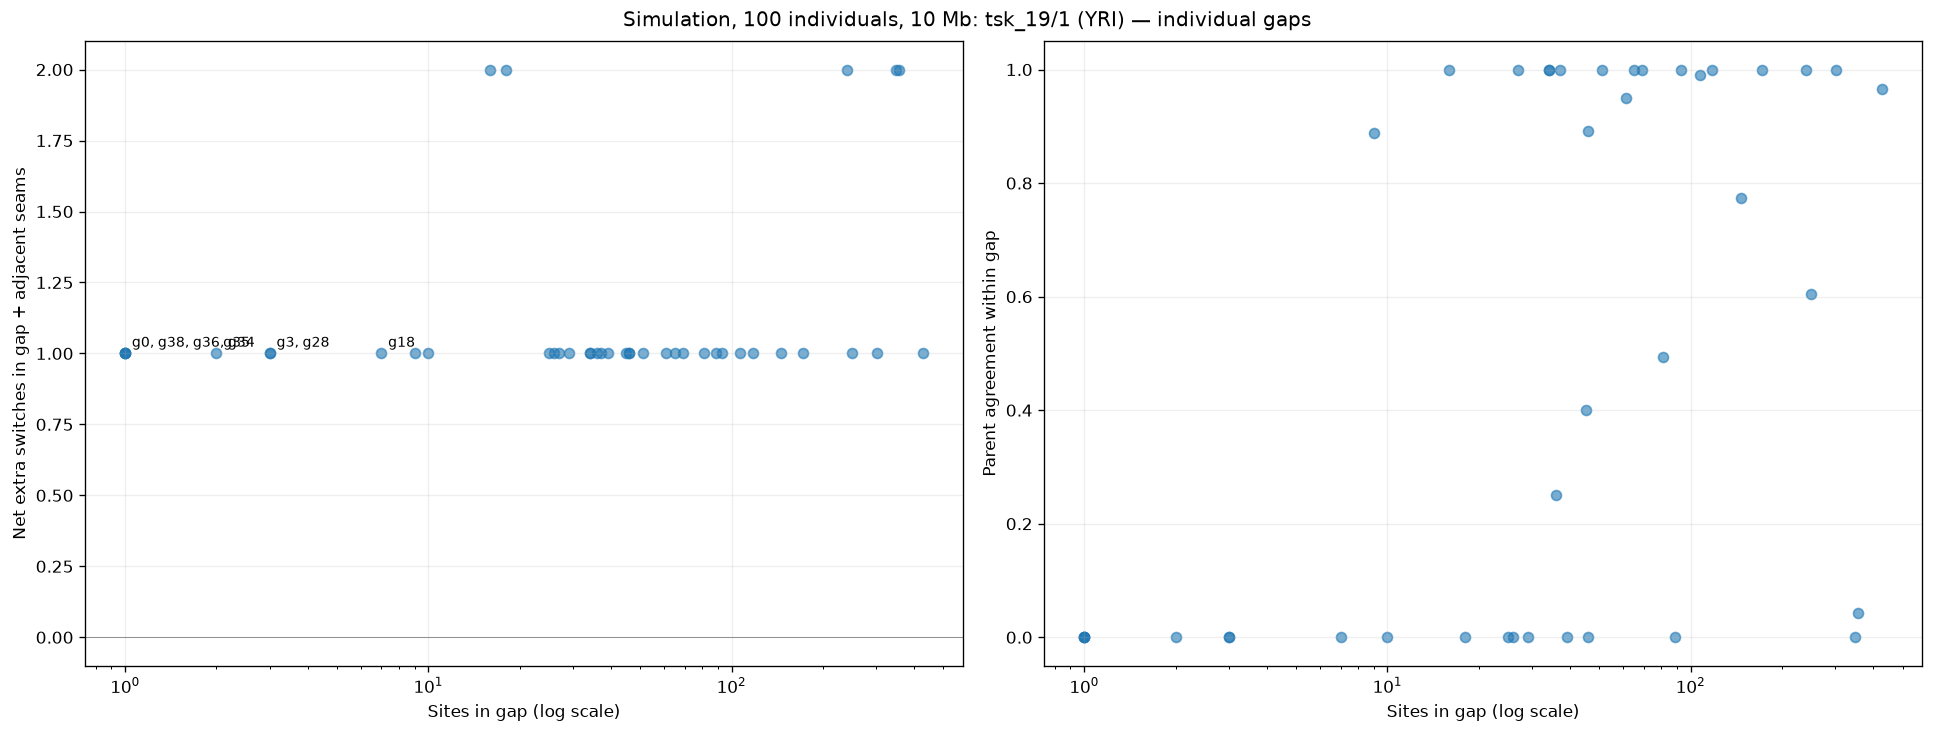

1KGP chromosome 20, 100 individuals, 10 Mb: NA19150/1 (AFR)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
78,78,36192,36193,1,0.0,0,2,2,0,False,False
20,20,12006,12007,1,1.0,0,2,2,0,False,False
0,0,47,48,1,0.0,1,2,1,0,True,False
5,5,3322,3323,1,0.0,1,2,1,0,True,False
17,17,11729,11730,1,0.0,1,2,1,0,True,False
23,23,12221,12222,1,0.0,1,2,1,0,True,False
31,31,13308,13309,1,0.0,1,2,1,0,True,False
32,32,13345,13346,1,0.0,1,2,1,0,True,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
84,84,49048,50576,1528,287,Changed parent sequence,5,8,3,32663 → 31644 → 19832 → 31487 → 31578 → 1,32663 → 25633 → 25634 → 25252 → 32187 → 27230 ...
58,58,25154,25257,103,11,Changed parent sequence,2,5,3,31027 → 31476 → 29922,31027 → 14458 → 23672 → 26496 → 23865 → 29922
25,25,12466,12498,32,4,Changed parent sequence,2,5,3,1 → 34733 → 1,1 → 25355 → 19711 → 23673 → 23554 → 1
96,96,60148,60447,299,190,Changed parent sequence,3,5,2,23255 → 26404 → 31262 → 1,23255 → 34491 → 23506 → 22414 → 12727 → 1
87,87,55089,55367,278,33,Changed parent sequence,2,4,2,21064 → 29916 → 27991,21064 → 16939 → 24923 → 24924 → 27991
20,20,11973,12006,33,0,Changed parent sequence,0,2,2,32341,32341 → 31386 → 32341
21,21,12007,12032,25,0,Changed parent sequence,0,2,2,32341,32341 → 27634 → 32341
22,22,12088,12107,19,10,Changed parent sequence,1,3,2,32341 → 32337,32341 → 22946 → 27634 → 32337


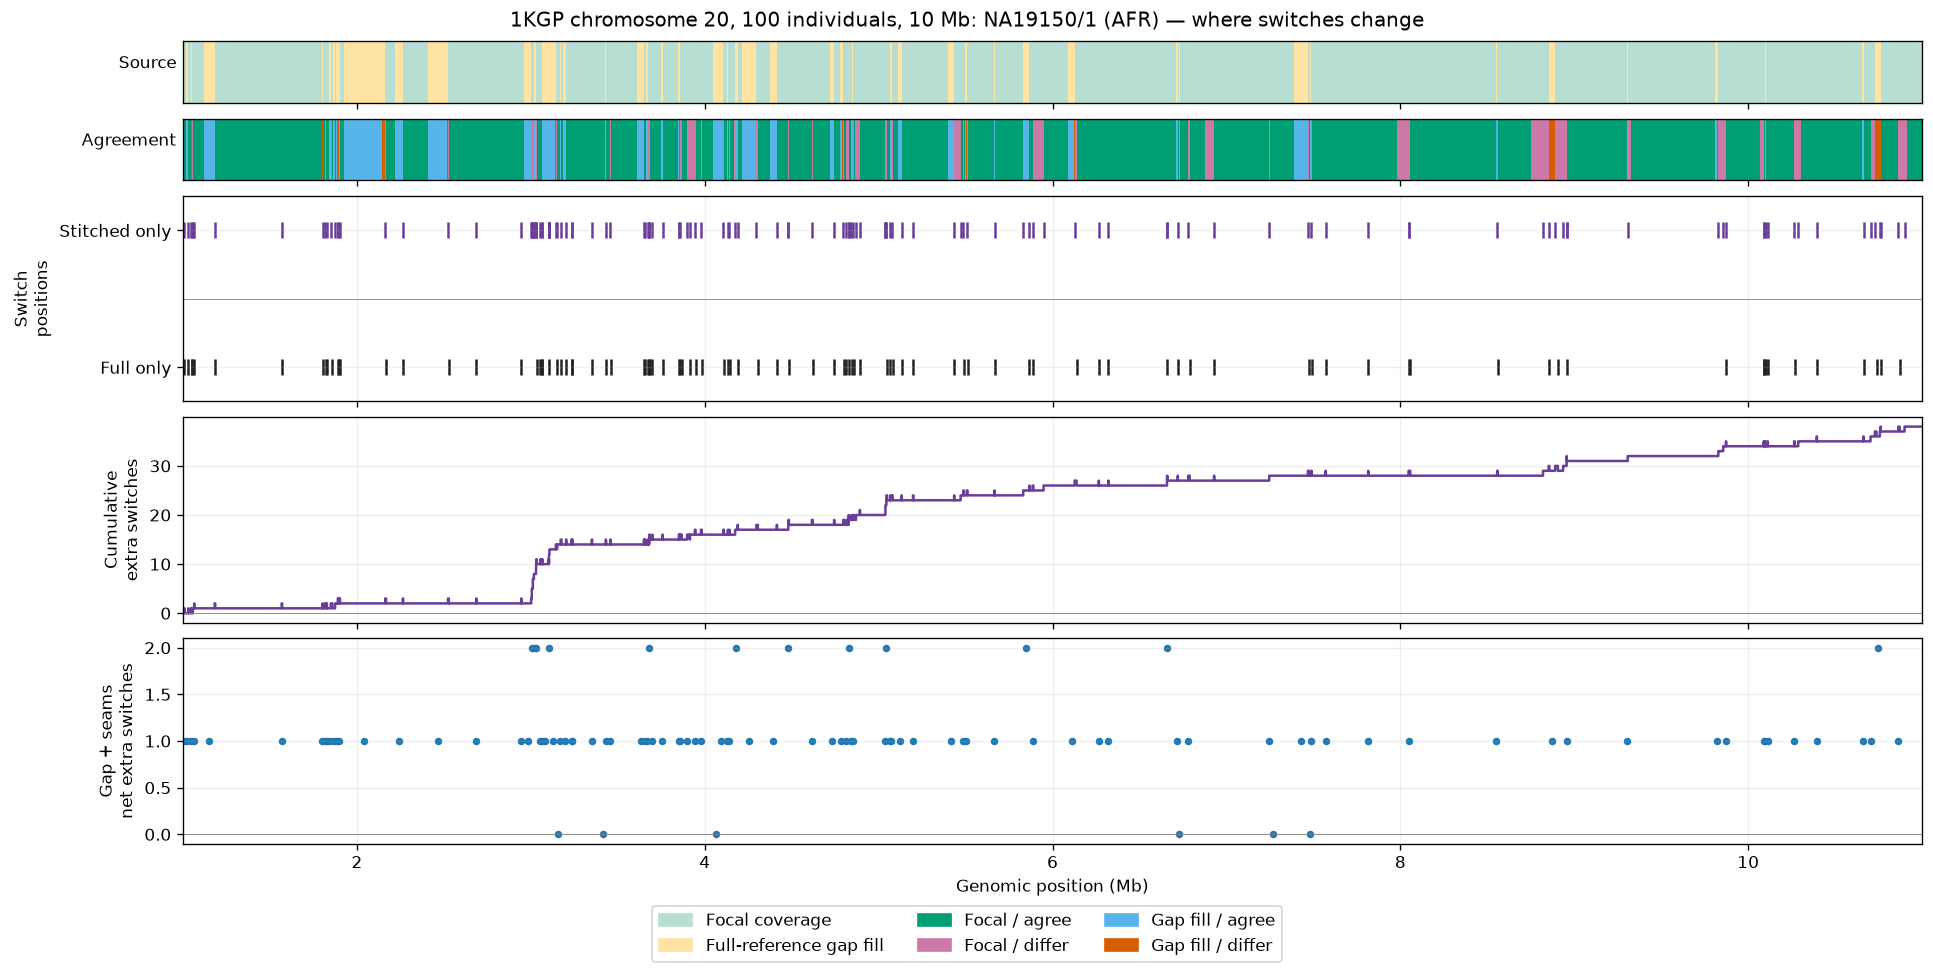

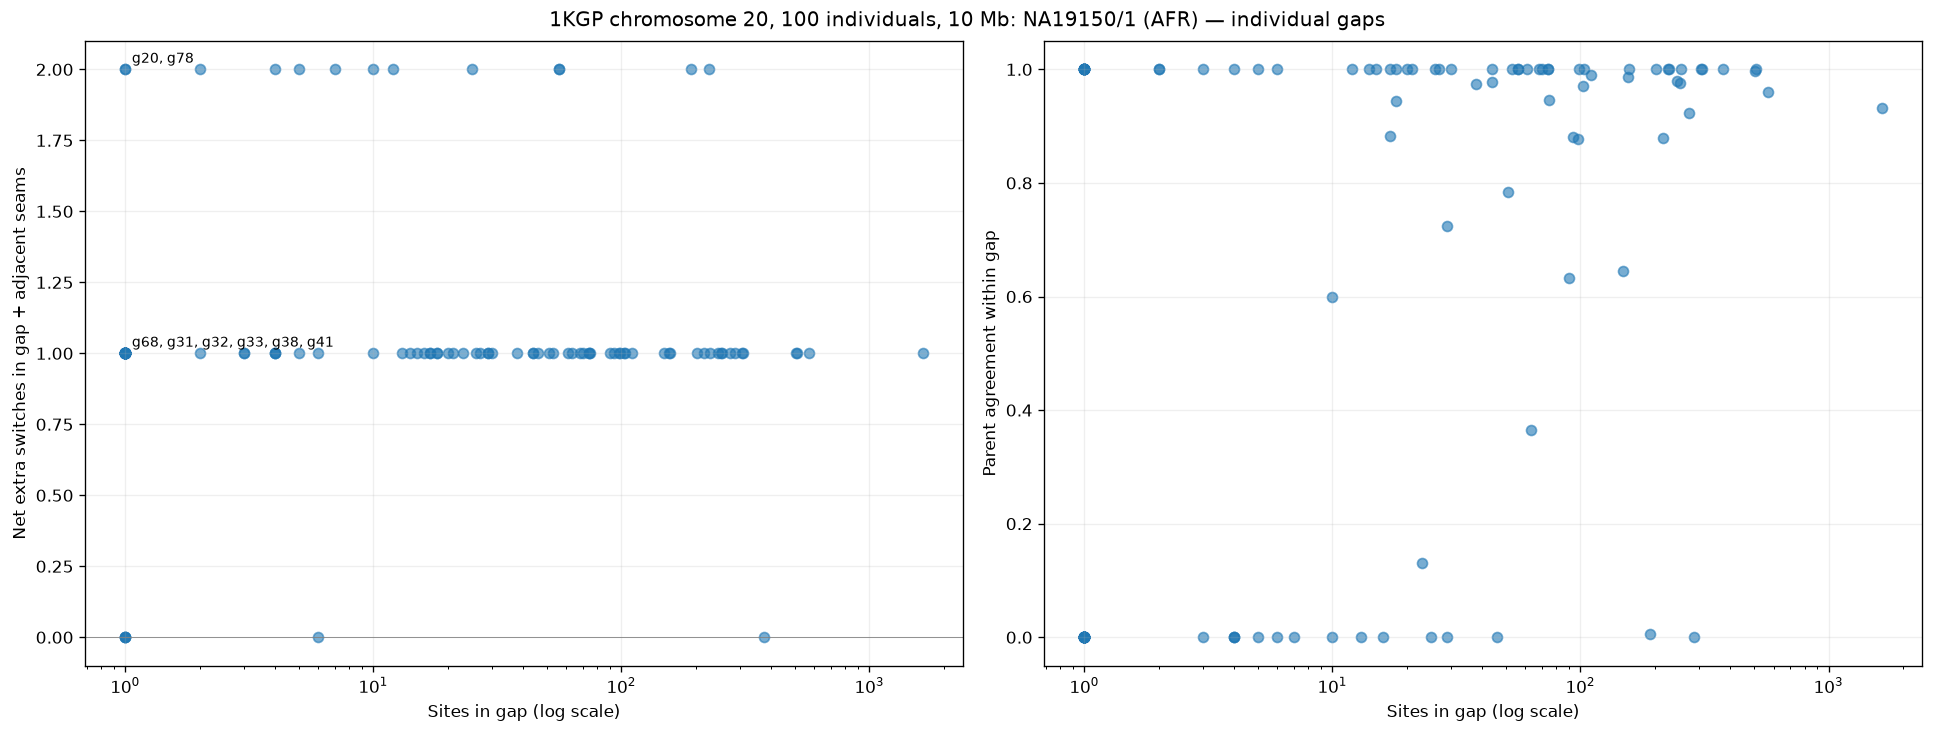

1KGP chromosome 20, 100 individuals, 10 Mb: NA18565/1 (EAS)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
25,25,29212,29213,1,0.000,1,2,1,0,True,False
47,47,61133,61134,1,0.000,1,2,1,0,True,False
12,12,11903,11904,1,1.000,1,2,1,0,True,False
30,30,37555,37563,8,0.000,1,2,1,0,True,False
10,10,10289,10309,20,0.000,1,2,1,0,True,False
23,23,28407,28451,44,0.932,2,3,1,0,True,False
34,34,41523,41569,46,1.000,1,2,1,0,True,False
20,20,25672,25736,64,0.047,2,3,1,0,False,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
2,2,2242,3432,1190,438,Changed parent sequence,3,4,1,11471 → 31962 → 27933 → 24085,11471 → 14866 → 26779 → 17731 → 24085
11,11,11904,12308,404,0,Changed parent sequence,2,3,1,15150 → 33786 → 33821,15150 → 24086 → 24087 → 33821
14,14,18606,18800,194,0,Changed parent sequence,2,3,1,18012 → 30935 → 26128,18012 → 26124 → 26127 → 26128
15,15,18951,19046,95,91,Changed parent sequence,2,3,1,26128 → 19669 → 19698,26128 → 25176 → 17827 → 19698
31,31,38055,38058,3,0,Changed parent sequence,1,2,1,33819 → 21023,33819 → 26122 → 21023
38,38,48049,50077,2028,226,Changed parent sequence,4,4,0,33334 → 33762 → 32031 → 9520 → 26126,33334 → 30789 → 30790 → 12736 → 26126
28,28,33167,34963,1796,278,Changed parent sequence,2,2,0,26116 → 30760 → 31698,26116 → 25545 → 31698
32,32,38915,39949,1034,235,Changed parent sequence,4,4,0,30924 → 31830 → 30911 → 22445 → 34201,30924 → 20921 → 27290 → 33598 → 34201


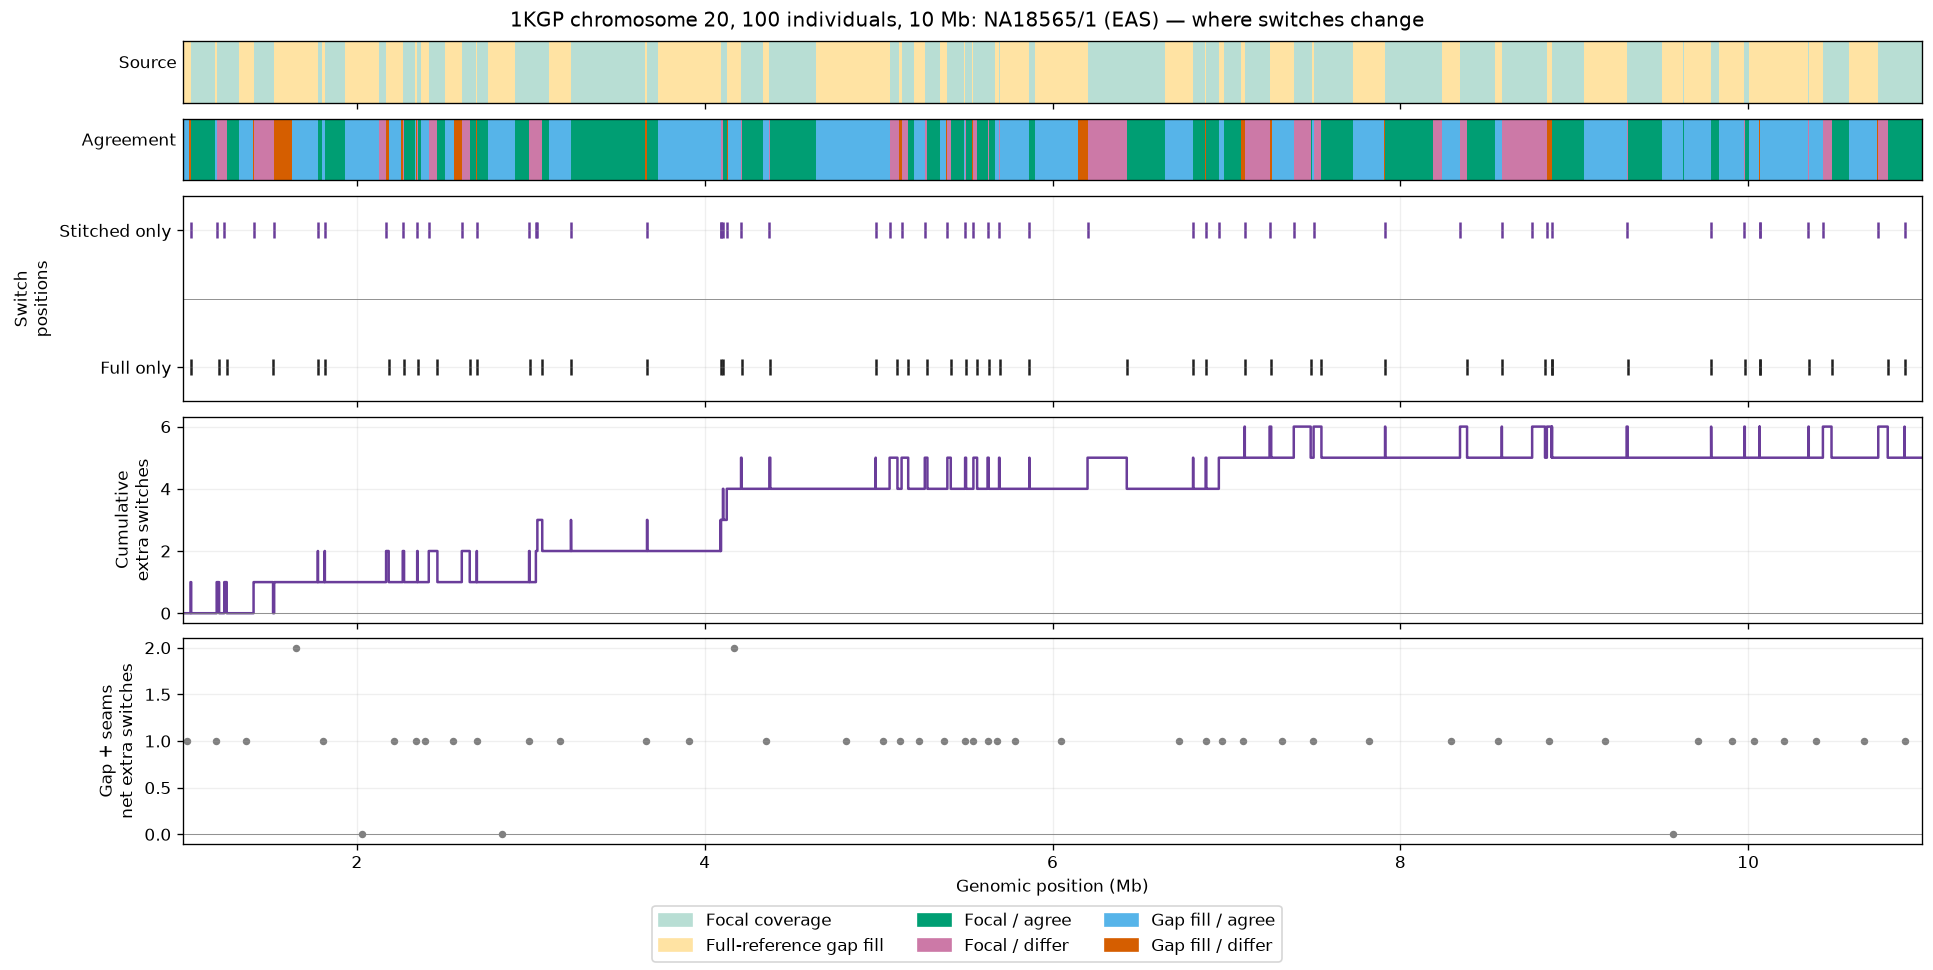

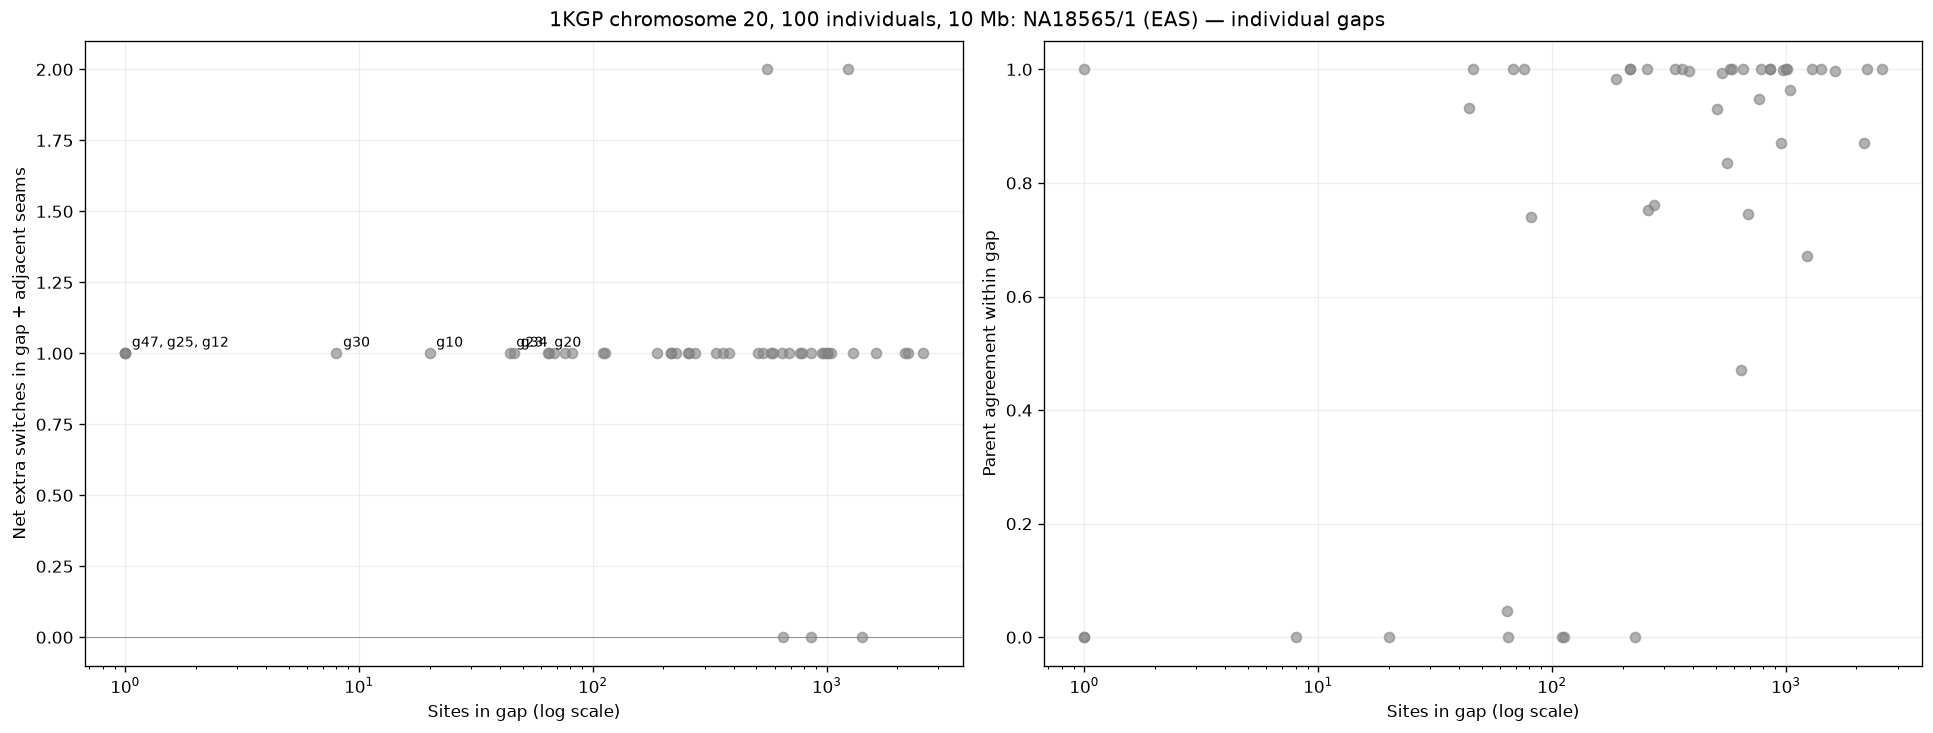

1KGP chromosome 20, 100 individuals, 10 Mb: NA18518/0 (AFR)
Gaps ranked by net extra switches per site (including their seams):


,gap,start_site,end_site,num_sites,agreement_fraction,full_gap_and_seam_switches,stitched_gap_and_seam_switches,extra_gap_and_seam_switches,extra_interior_switches,left_flank_parent_agrees,right_flank_parent_agrees
0,0,22016,22017,1,0.0,1,2,1,0,True,False
1,1,24882,24883,1,0.0,1,2,1,0,True,False


Disagreement regions ranked by net extra switches, then number of sites:


,difference,start_site,end_site,num_sites,gap_sites,kind,full_switches,stitched_switches,extra_switches,full_parent_sequence,stitched_parent_sequence
4,4,55641,56515,874,0,Changed parent sequence,2,2,0,34232 → 31083 → 34233,34232 → 24900 → 34233
5,5,57205,57785,580,0,Changed parent sequence,2,2,0,34233 → 31487 → 34234,34233 → 26246 → 34234
0,0,17760,18030,270,0,Changed parent sequence,2,2,0,34222 → 27425 → 34223,34222 → 31084 → 34223
3,3,32373,32494,121,0,Changed parent sequence,2,2,0,34227 → 28913 → 34228,34227 → 25273 → 34228
2,2,24882,24973,91,1,Changed parent sequence,2,2,0,34224 → 16852 → 34225,34224 → 1 → 34225
1,1,22016,22057,41,1,Changed parent sequence,2,2,0,34220 → 16844 → 34224,34220 → 1 → 34224


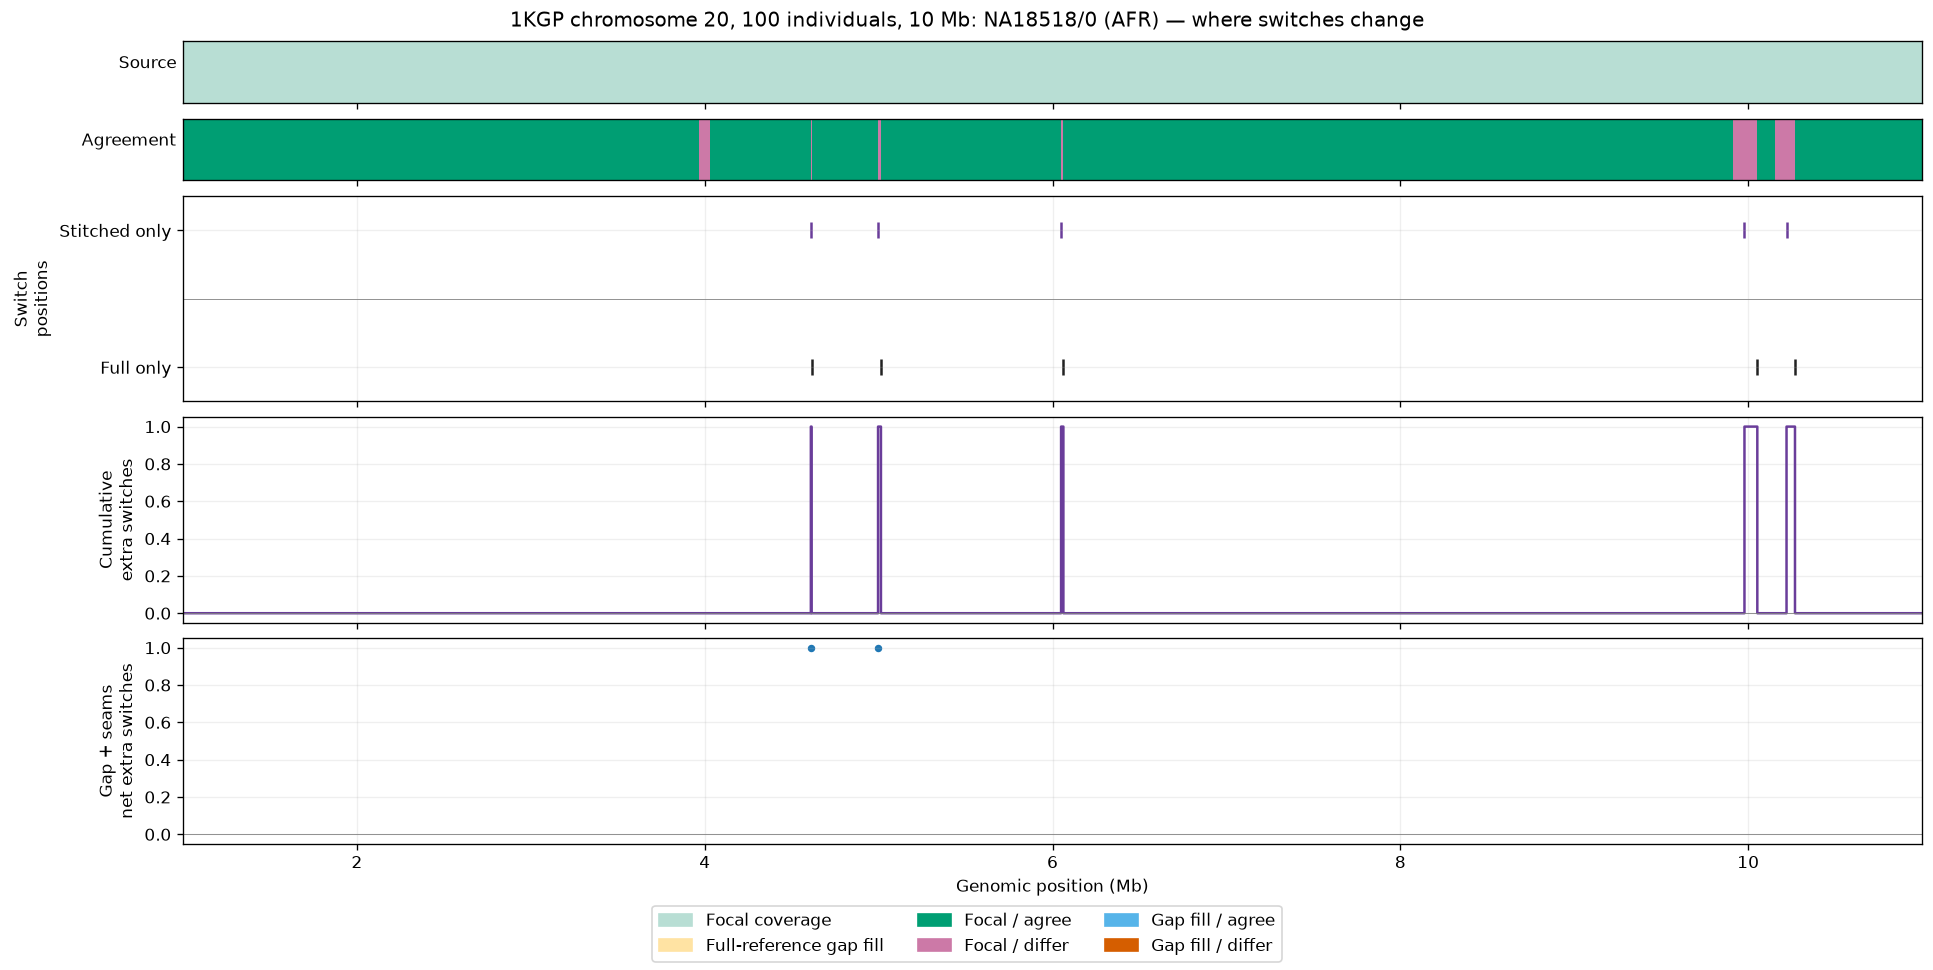

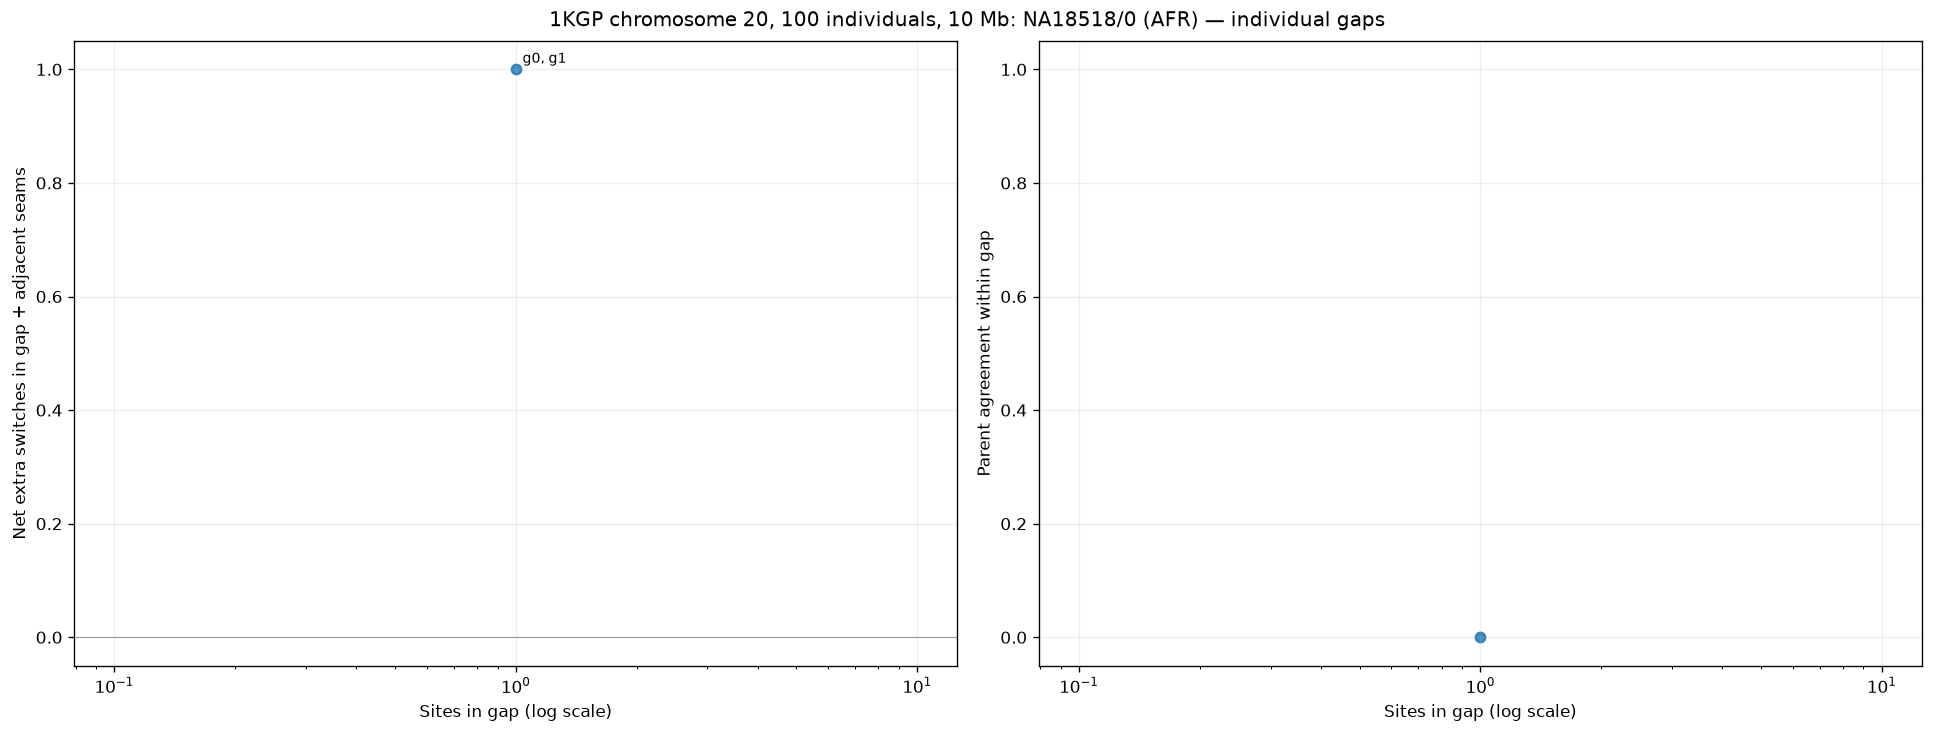

In [22]:
nb_plot.plot_deep_dive_2(
    category_cmap=category_cmap,
    category_norm=category_norm,
    config=config,
    coverage_handles=coverage_handles,
    outlier_analyses=outlier_analyses,
    outlier_case_datasets=outlier_case_datasets,
    outlier_output_dir=outlier_output_dir,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

Choose detailed windows reproducibly: a short gap with high net extra switches
per site, the gap with lowest parent agreement, the longest uninterrupted
focal disagreement, a changed parent sequence around a gap, and a proven
parent-preserving relocation when available. Duplicate displayed windows are
shown once. Tables report the entire target and displayed coordinates.
Short-gap zooms use inference-site indices to keep even one-site gaps visible;
their genomic coordinates are reported in the tables. Other zooms use kb.

Most long targets are clipped to the configured site limit around a relevant
anchor. Relocation windows retain both switch positions, even when farther
apart, so the before/after parents and the intervening disagreement are visible.
Shared categorical rows identify the actual parents; black dashed is full HMM
and solid purple is stitched. Dotted lines mark target boundaries.

Detailed windows: Simulation, 100 individuals, 10 Mb, tsk_19/0


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,out_of_africa_n100_10mbp,tsk_19/0,Short gap with extra switches,20853,20855,20828,20880,0.000,4683961.0,4699586.0
1,out_of_africa_n100_10mbp,tsk_19/0,Lowest gap agreement,42589,42802,42564,42804,0.000,9607783.0,9666593.0
2,out_of_africa_n100_10mbp,tsk_19/0,Longest focal parent disagreement,8670,9010,8645,8885,0.000,1929994.0,1986465.0
3,out_of_africa_n100_10mbp,tsk_19/0,Changed parent sequence around a gap,24673,24695,24648,24720,0.000,5488009.0,5502286.0
4,out_of_africa_n100_10mbp,tsk_19/0,Same parents with a relocated switch,9766,9841,9741,9866,0.013,2172114.0,2204381.0


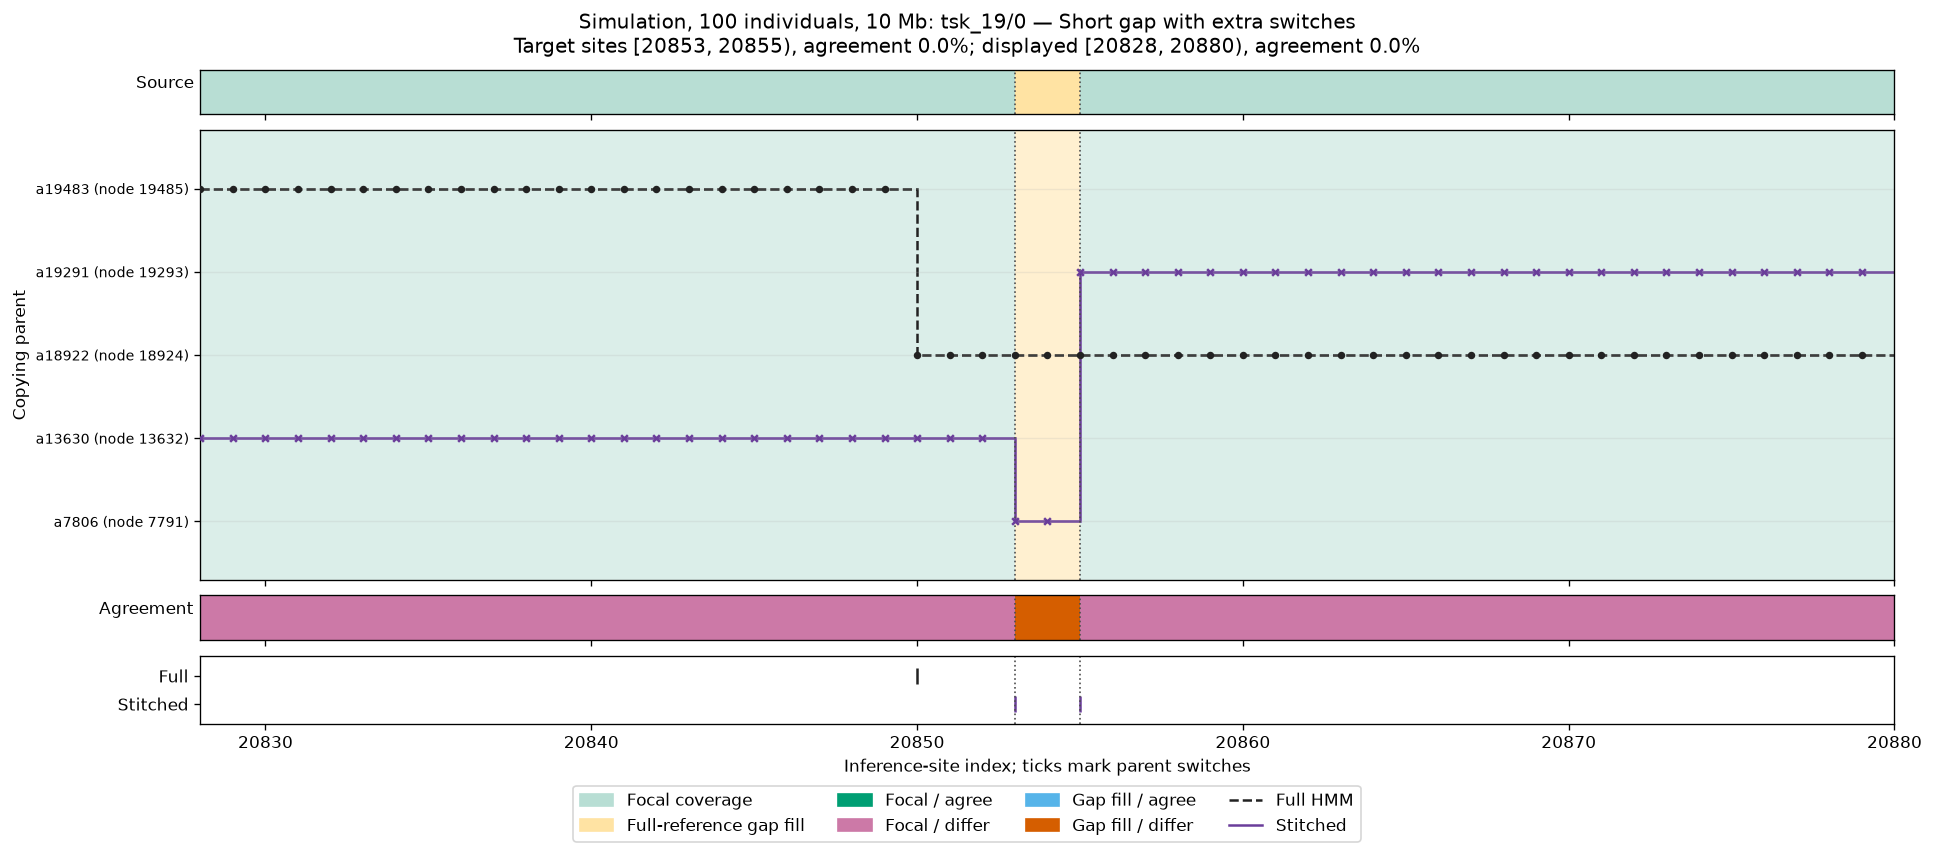

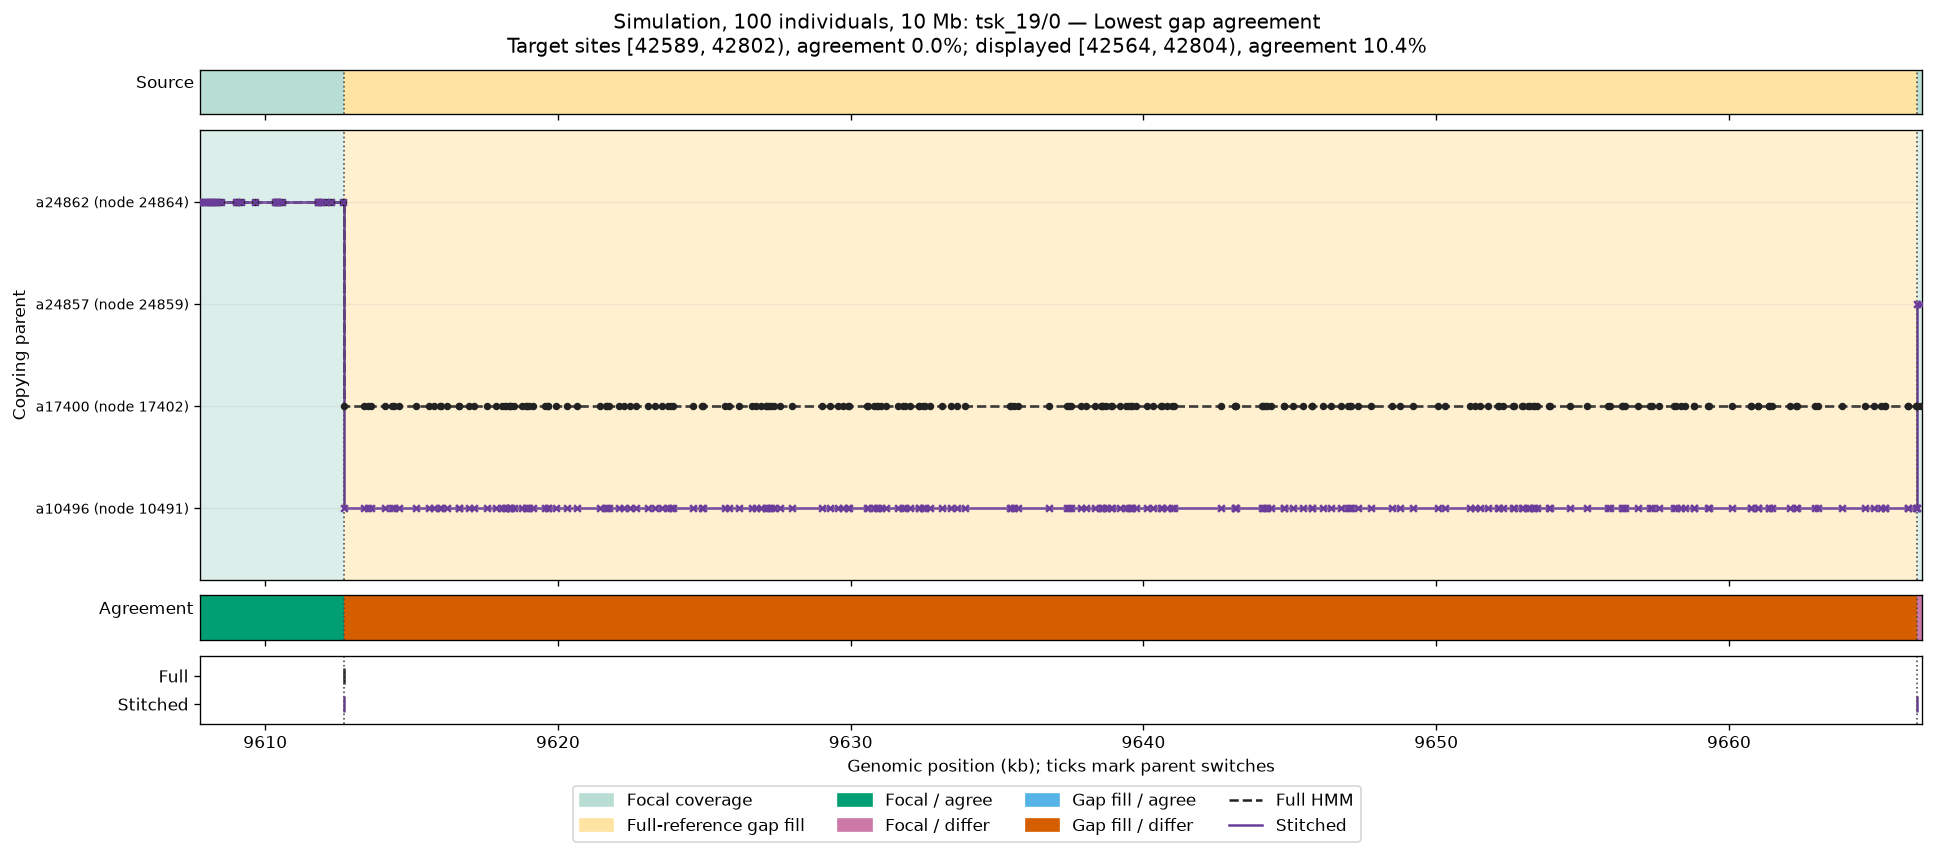

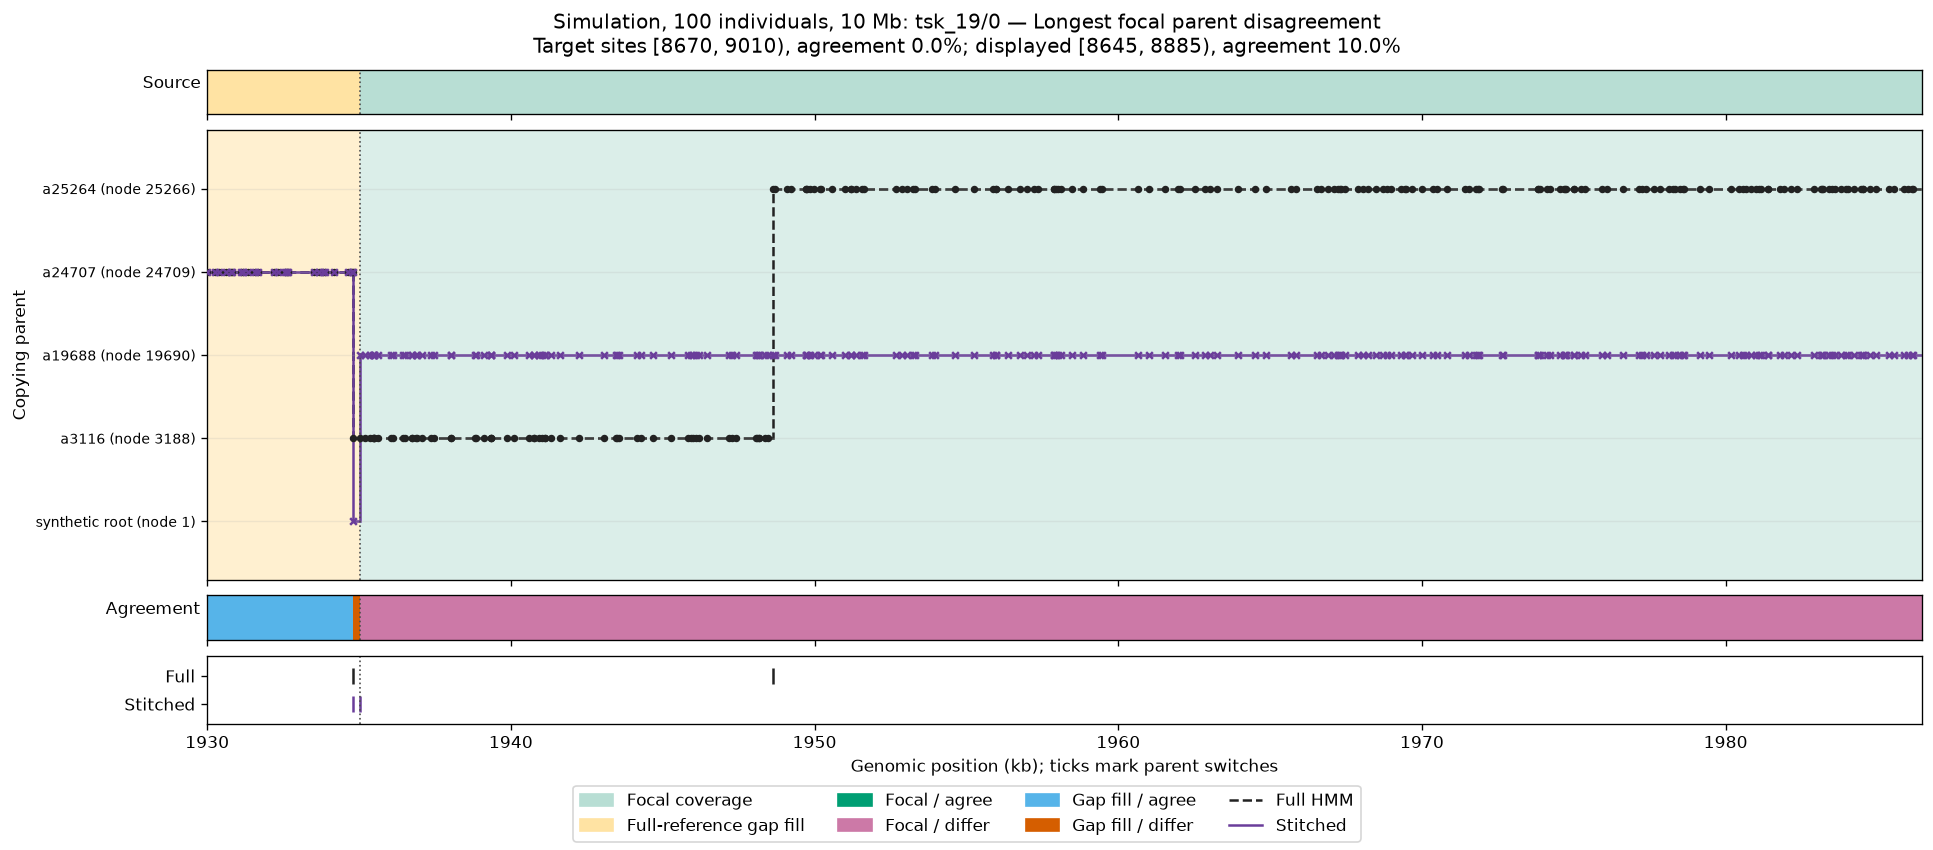

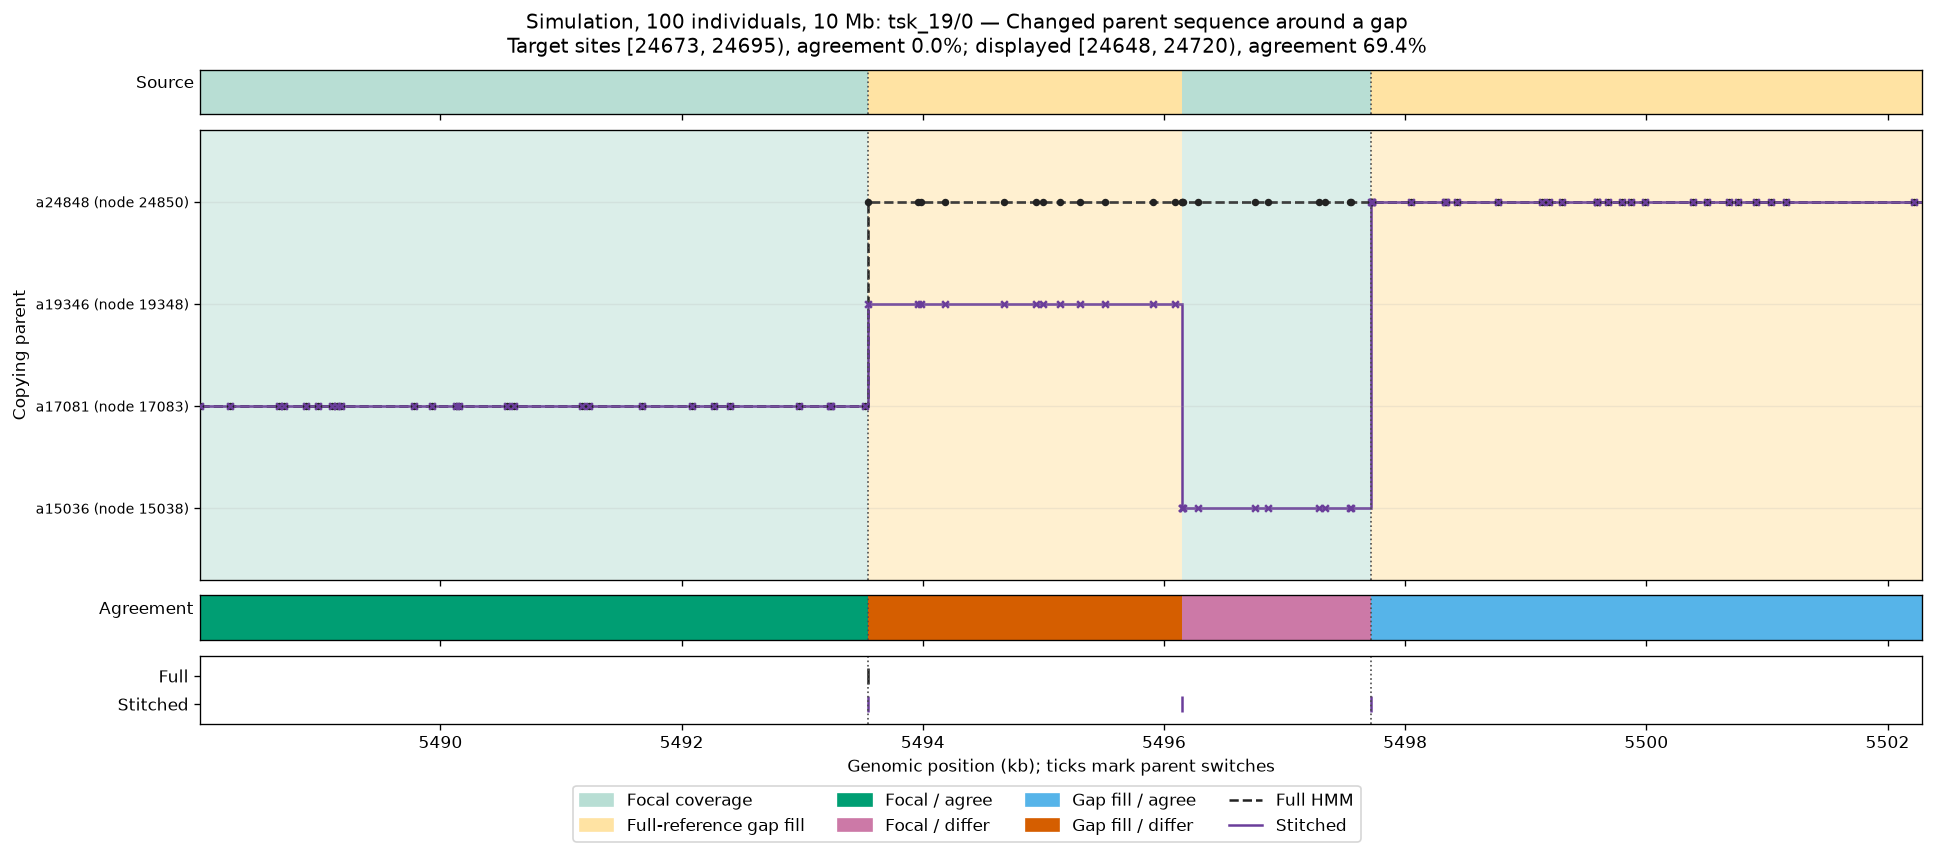

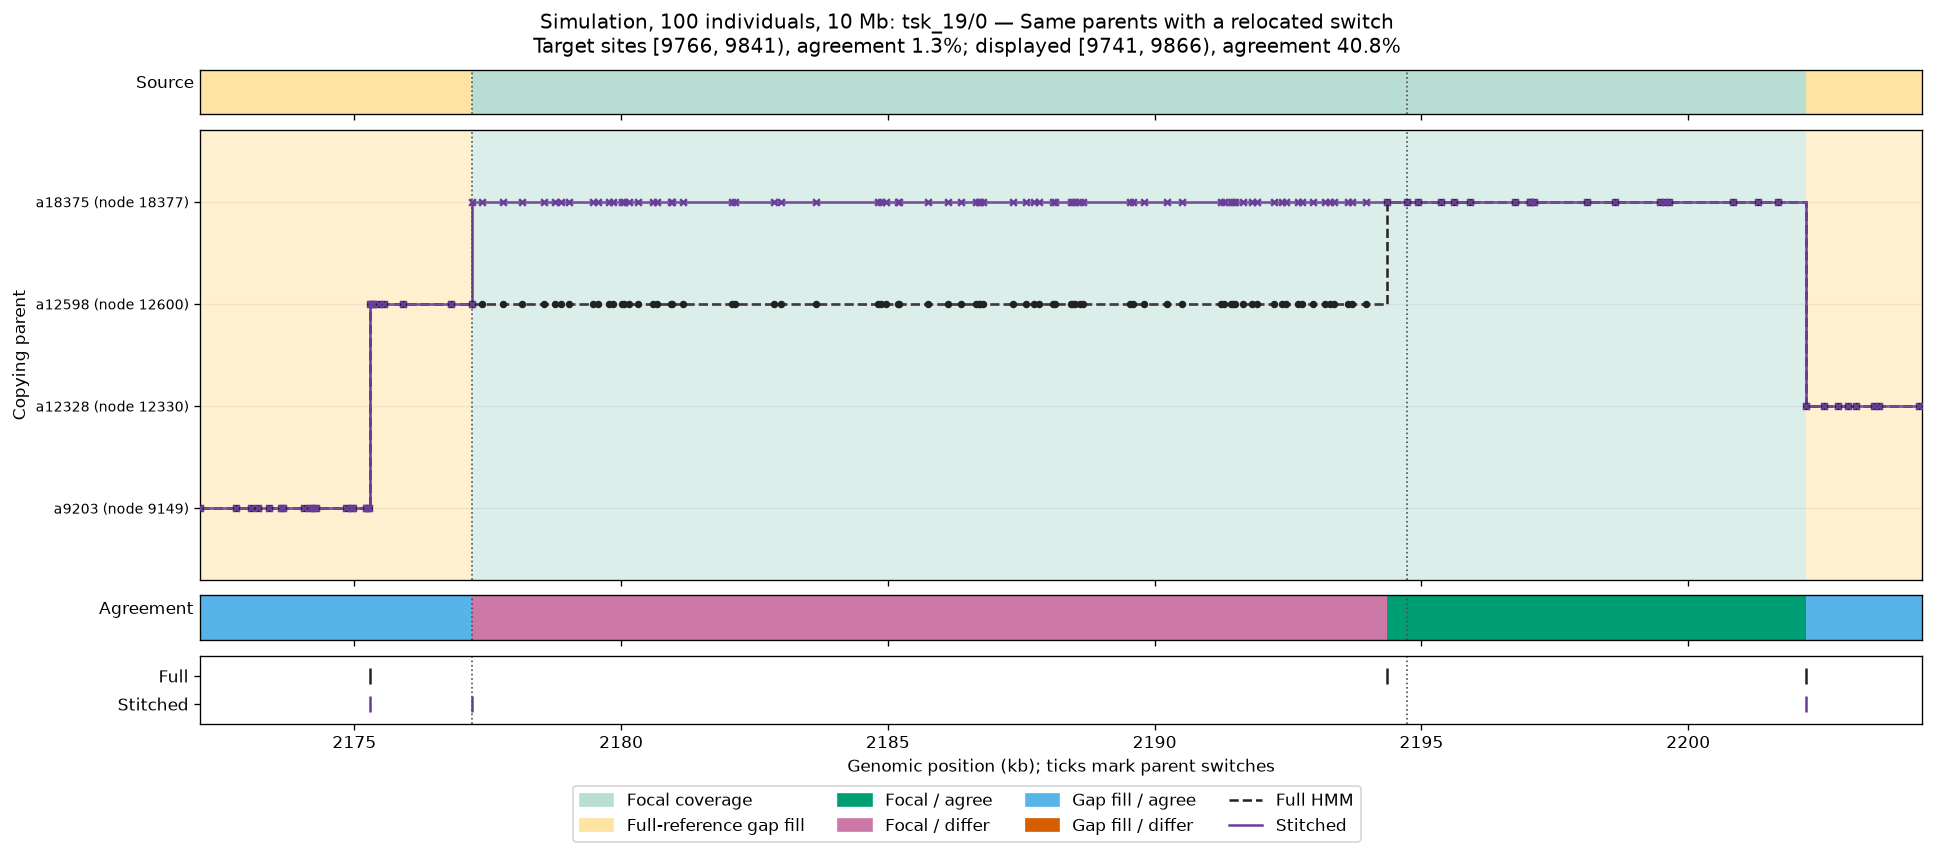

Detailed windows: Simulation, 100 individuals, 10 Mb, tsk_74/1


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,out_of_africa_n100_10mbp,tsk_74/1,Short gap with extra switches,13924,13929,13899,13954,0.000,3098822.0,3110319.0
1,out_of_africa_n100_10mbp,tsk_74/1,Lowest gap agreement,22160,22466,22135,22375,0.000,4955770.0,5014890.0
2,out_of_africa_n100_10mbp,tsk_74/1,Longest focal parent disagreement,13929,15255,13904,14144,0.000,3099701.0,3153000.0
3,out_of_africa_n100_10mbp,tsk_74/1,Changed parent sequence around a gap,29936,30461,30195,30435,0.000,6819746.0,6875554.0
4,out_of_africa_n100_10mbp,tsk_74/1,Same parents with a relocated switch,12929,13555,12904,13580,0.002,2904419.0,3035647.0


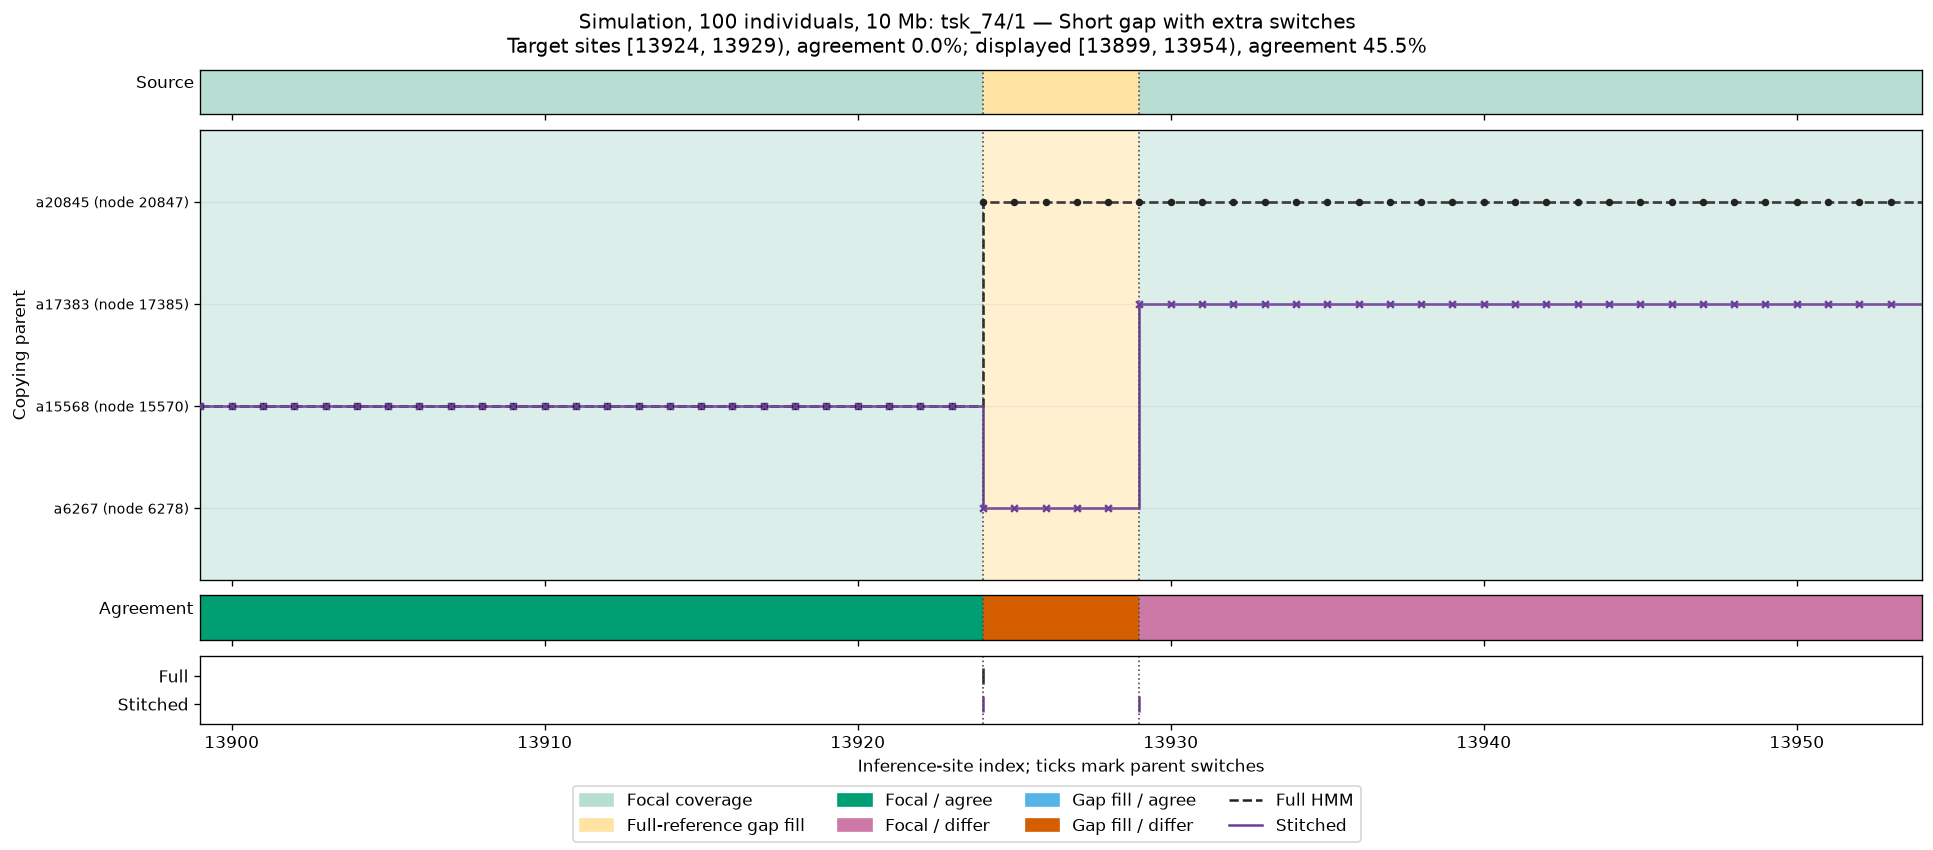

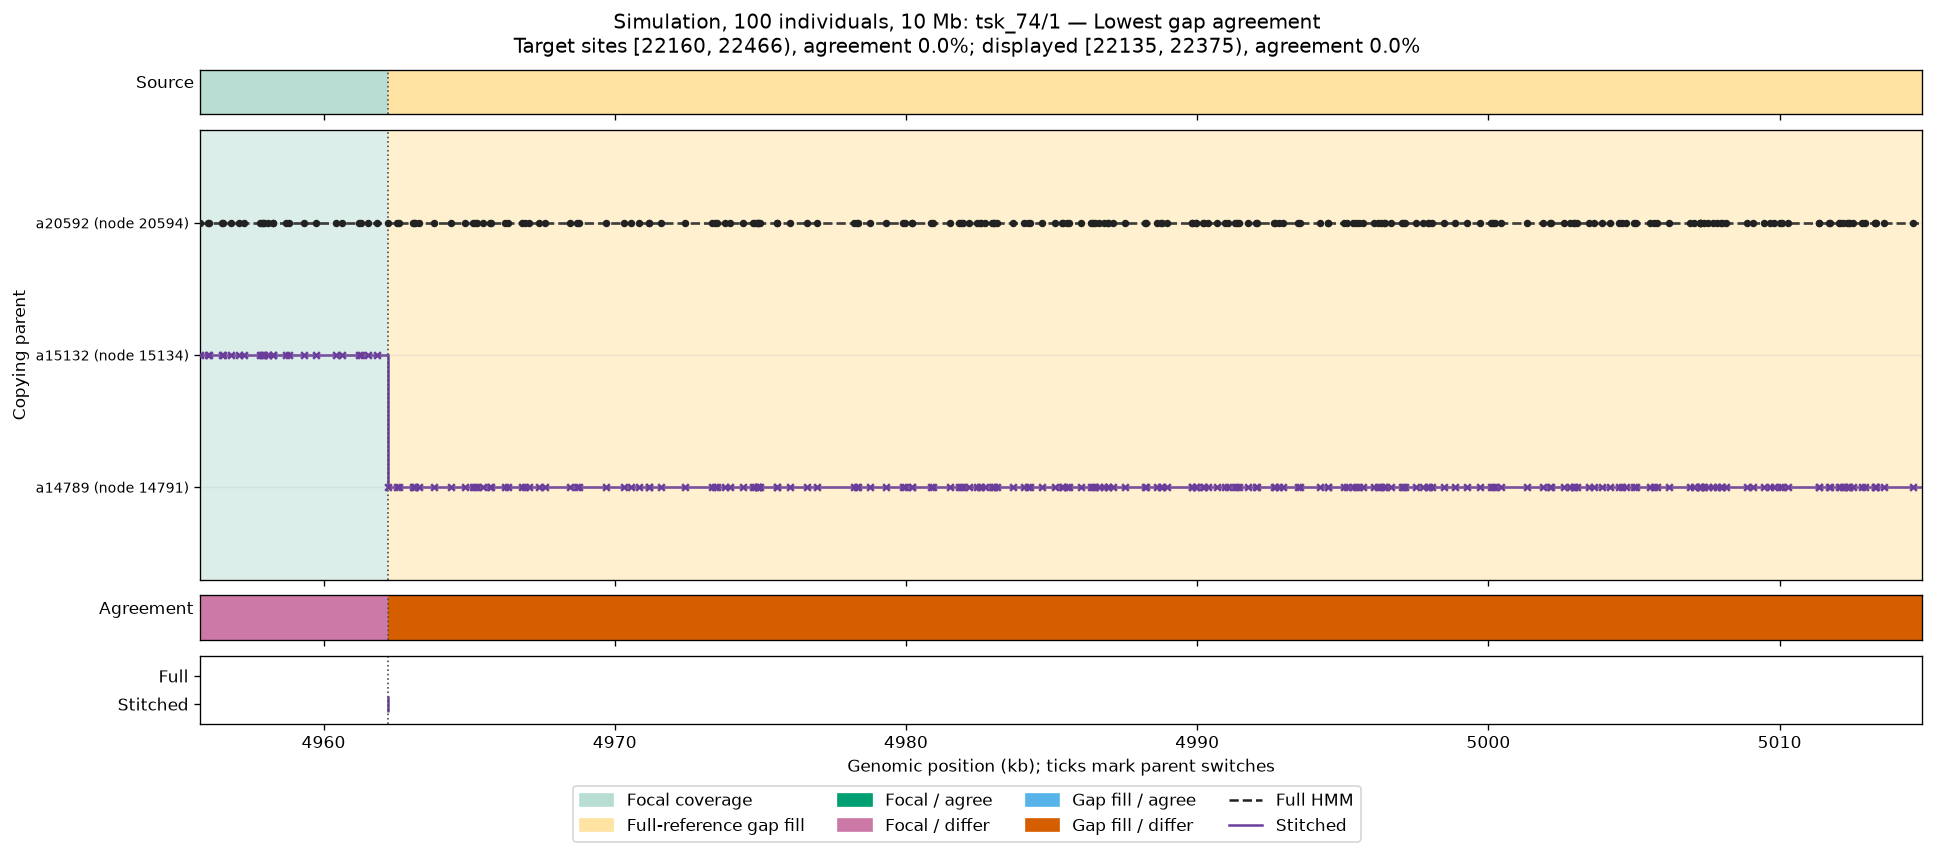

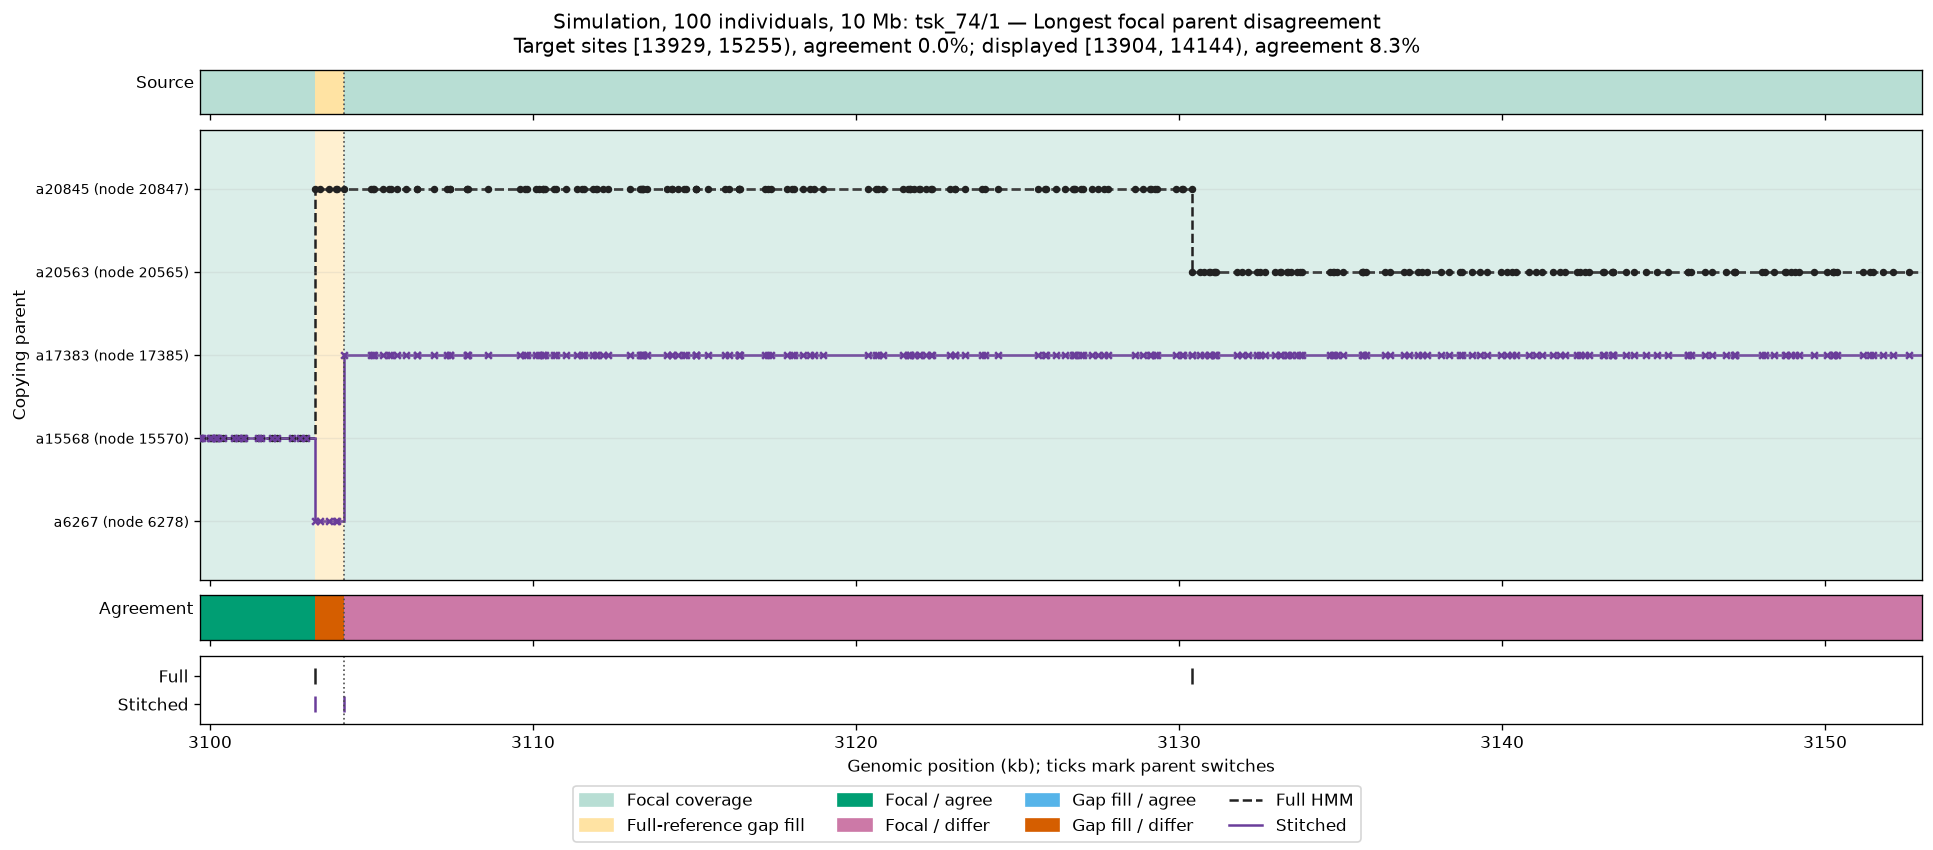

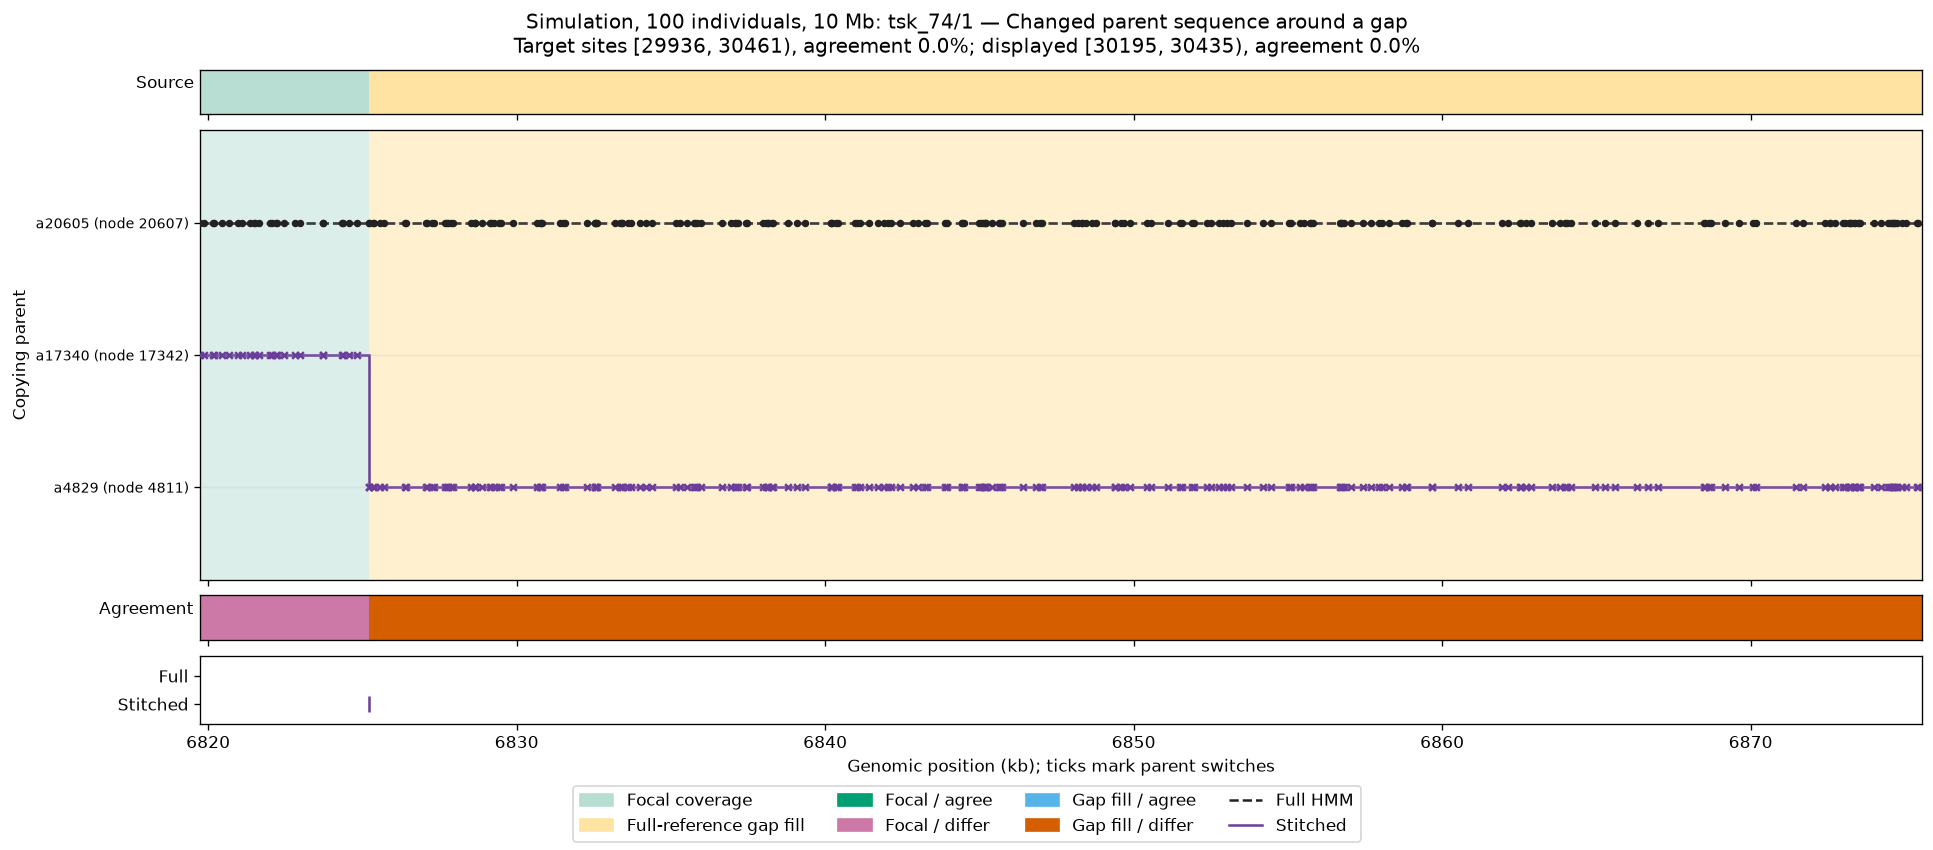

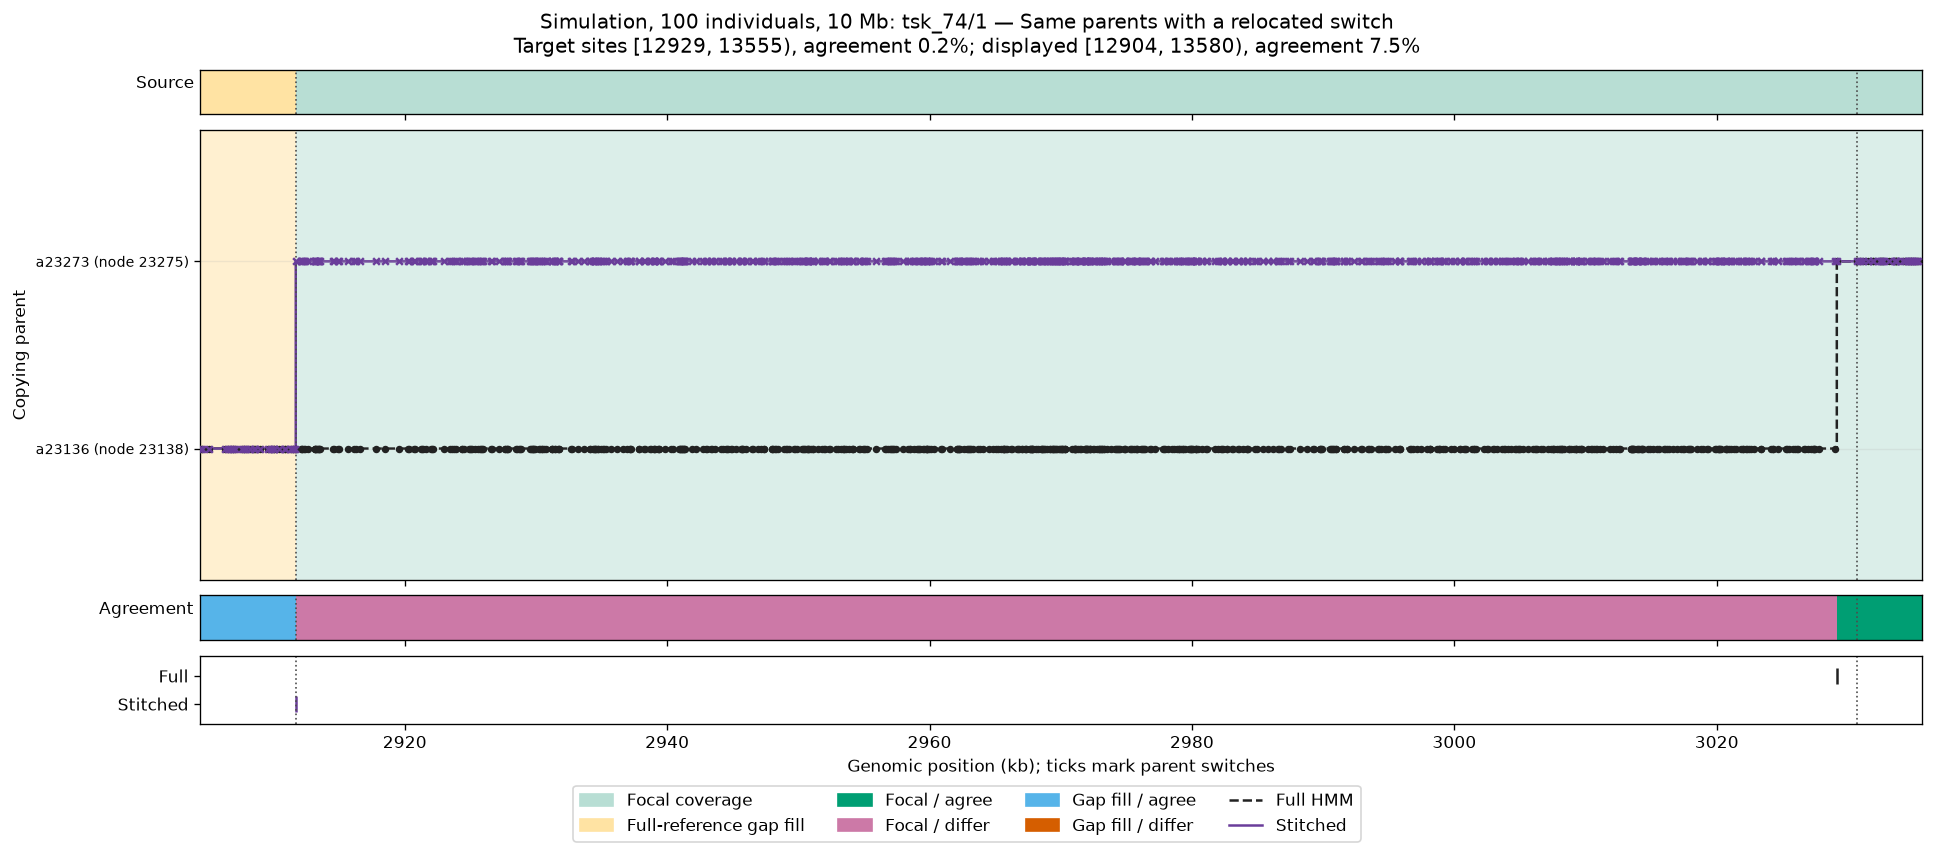

Detailed windows: Simulation, 100 individuals, 10 Mb, tsk_19/1


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,out_of_africa_n100_10mbp,tsk_19/1,Short gap with extra switches,1016,1017,991,1042,0.000,261356.0,271620.0
1,out_of_africa_n100_10mbp,tsk_19/1,Lowest gap agreement,4837,5186,4812,5052,0.000,1077840.0,1123641.0
2,out_of_africa_n100_10mbp,tsk_19/1,Longest focal parent disagreement,3788,4042,3763,4003,0.000,847946.0,899528.0
3,out_of_africa_n100_10mbp,tsk_19/1,Changed parent sequence around a gap,3749,4042,3724,3964,0.000,839324.0,890008.0
4,out_of_africa_n100_10mbp,tsk_19/1,Same parents with a relocated switch,20661,20744,20636,20769,0.012,4644099.0,4671558.0


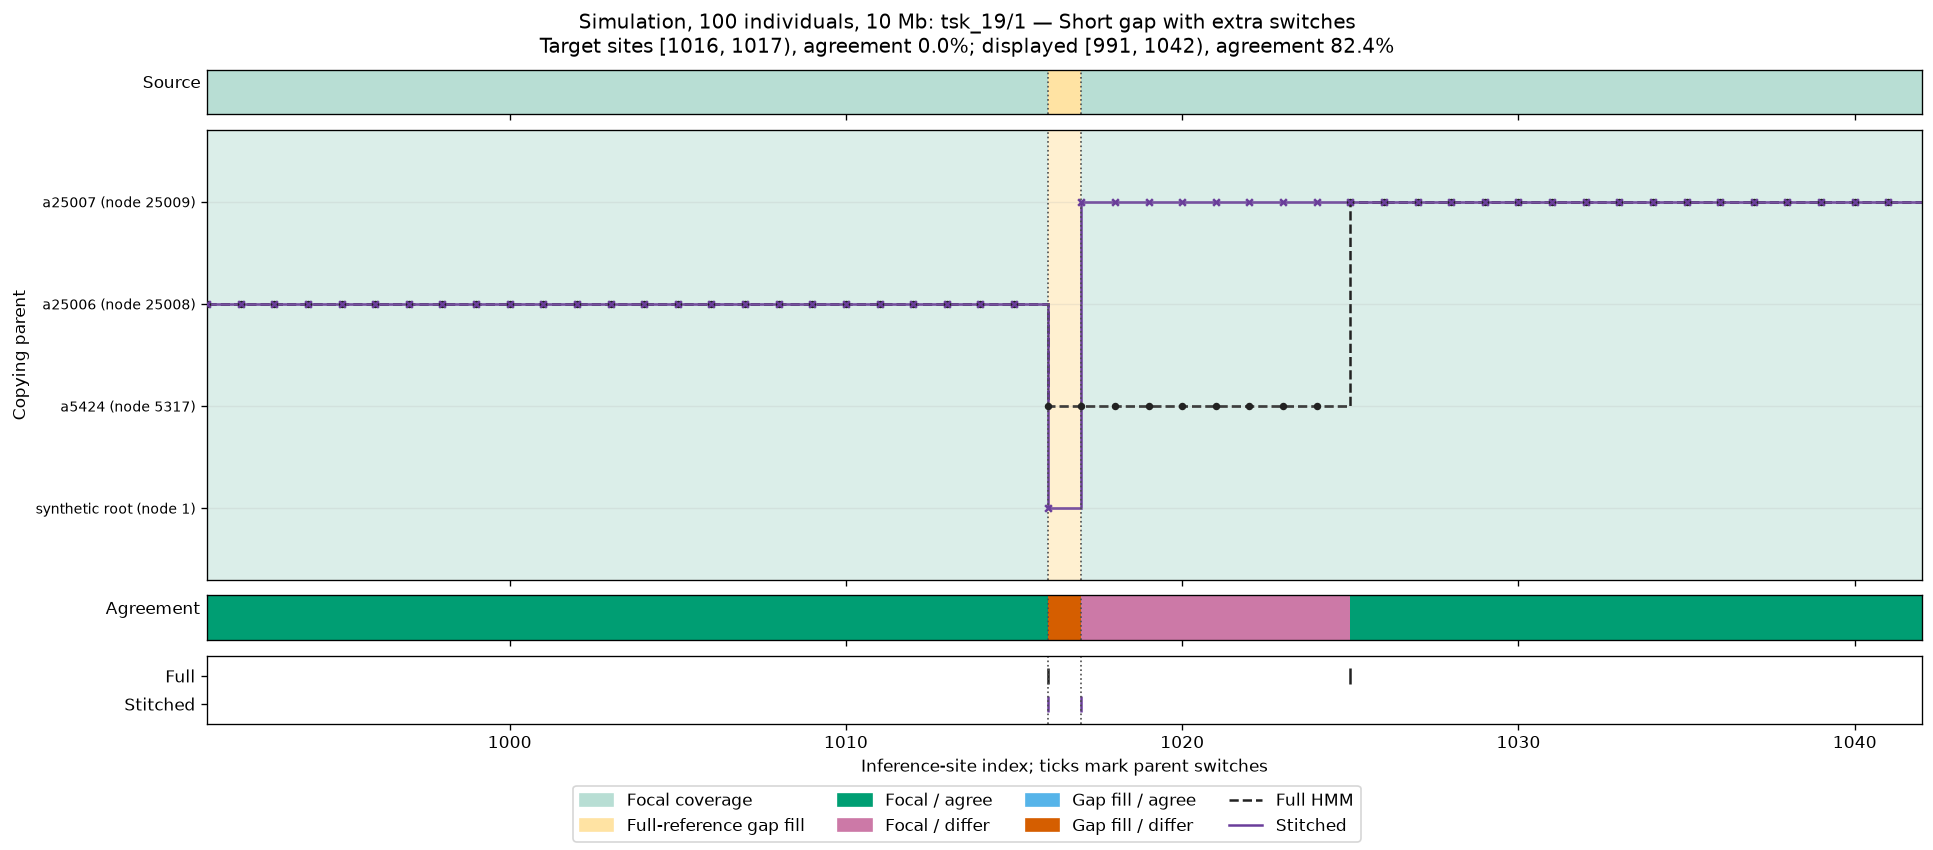

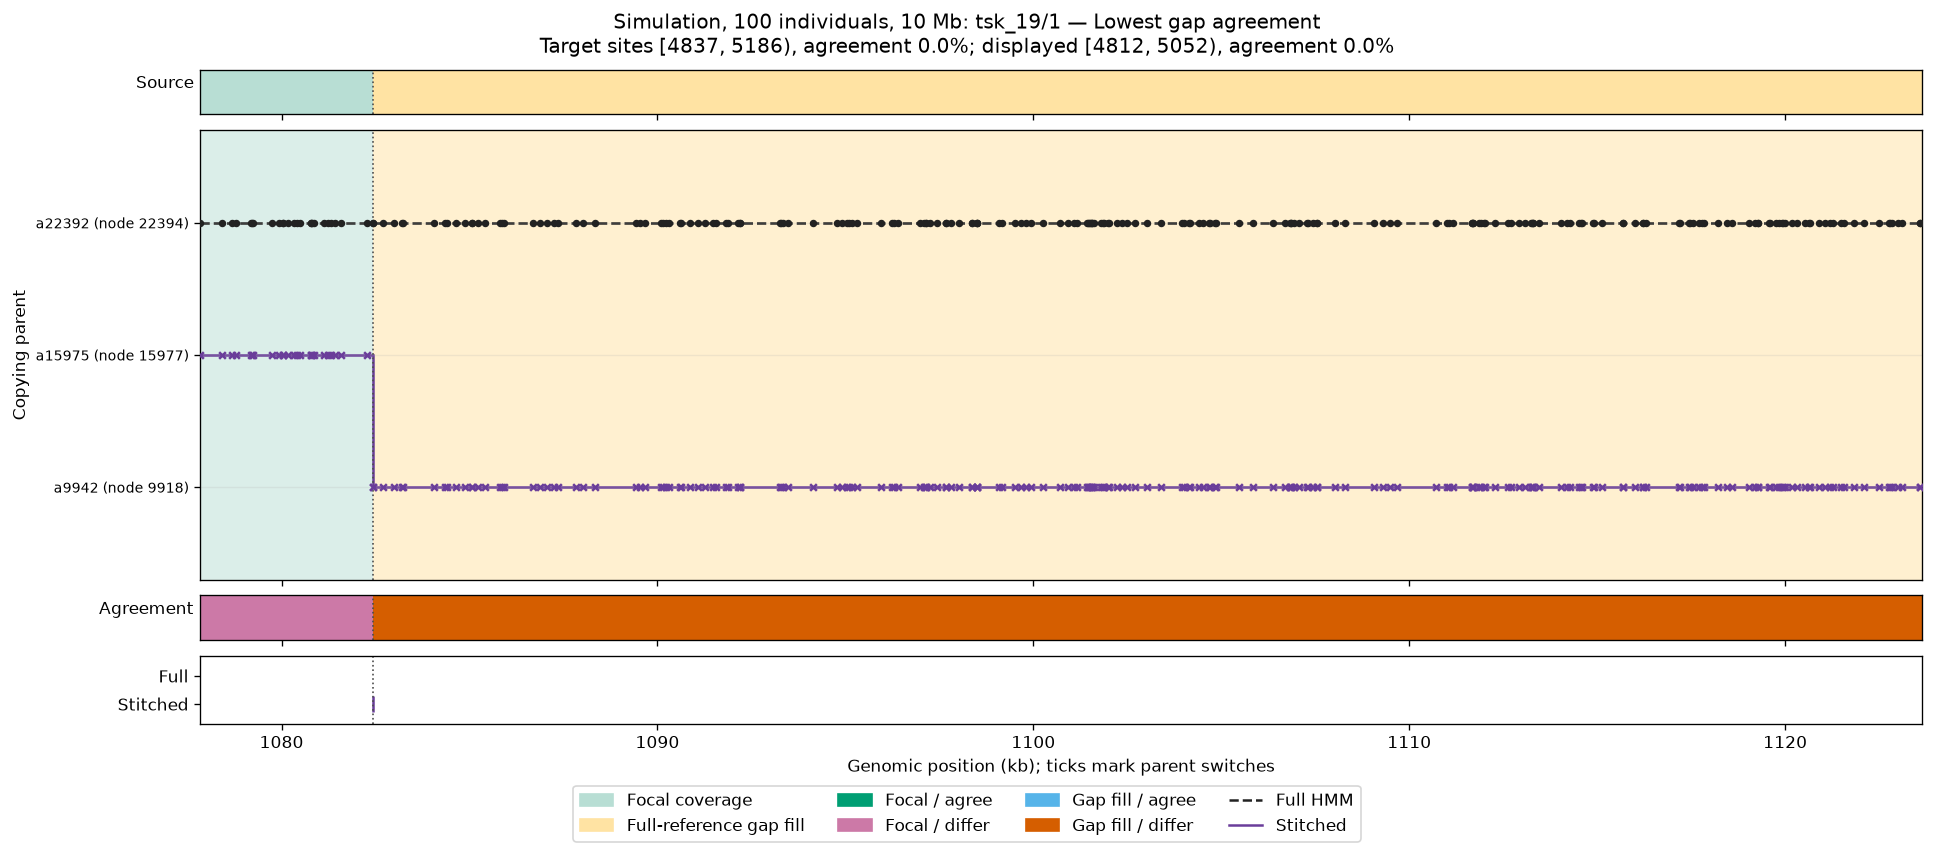

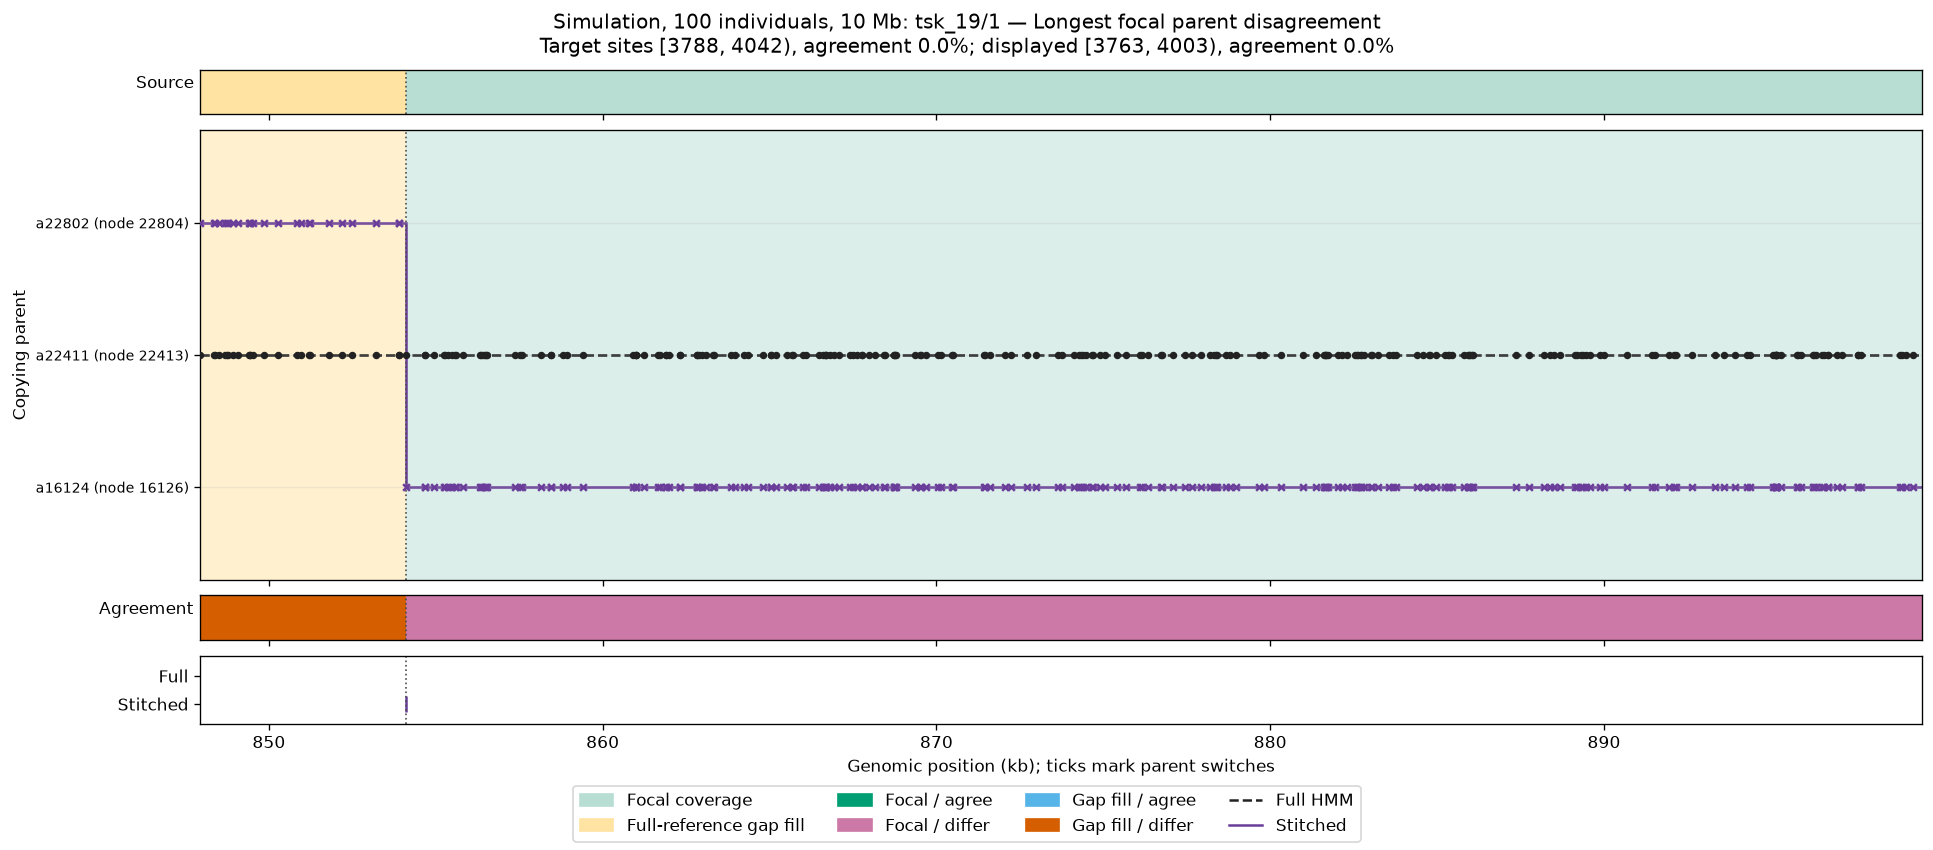

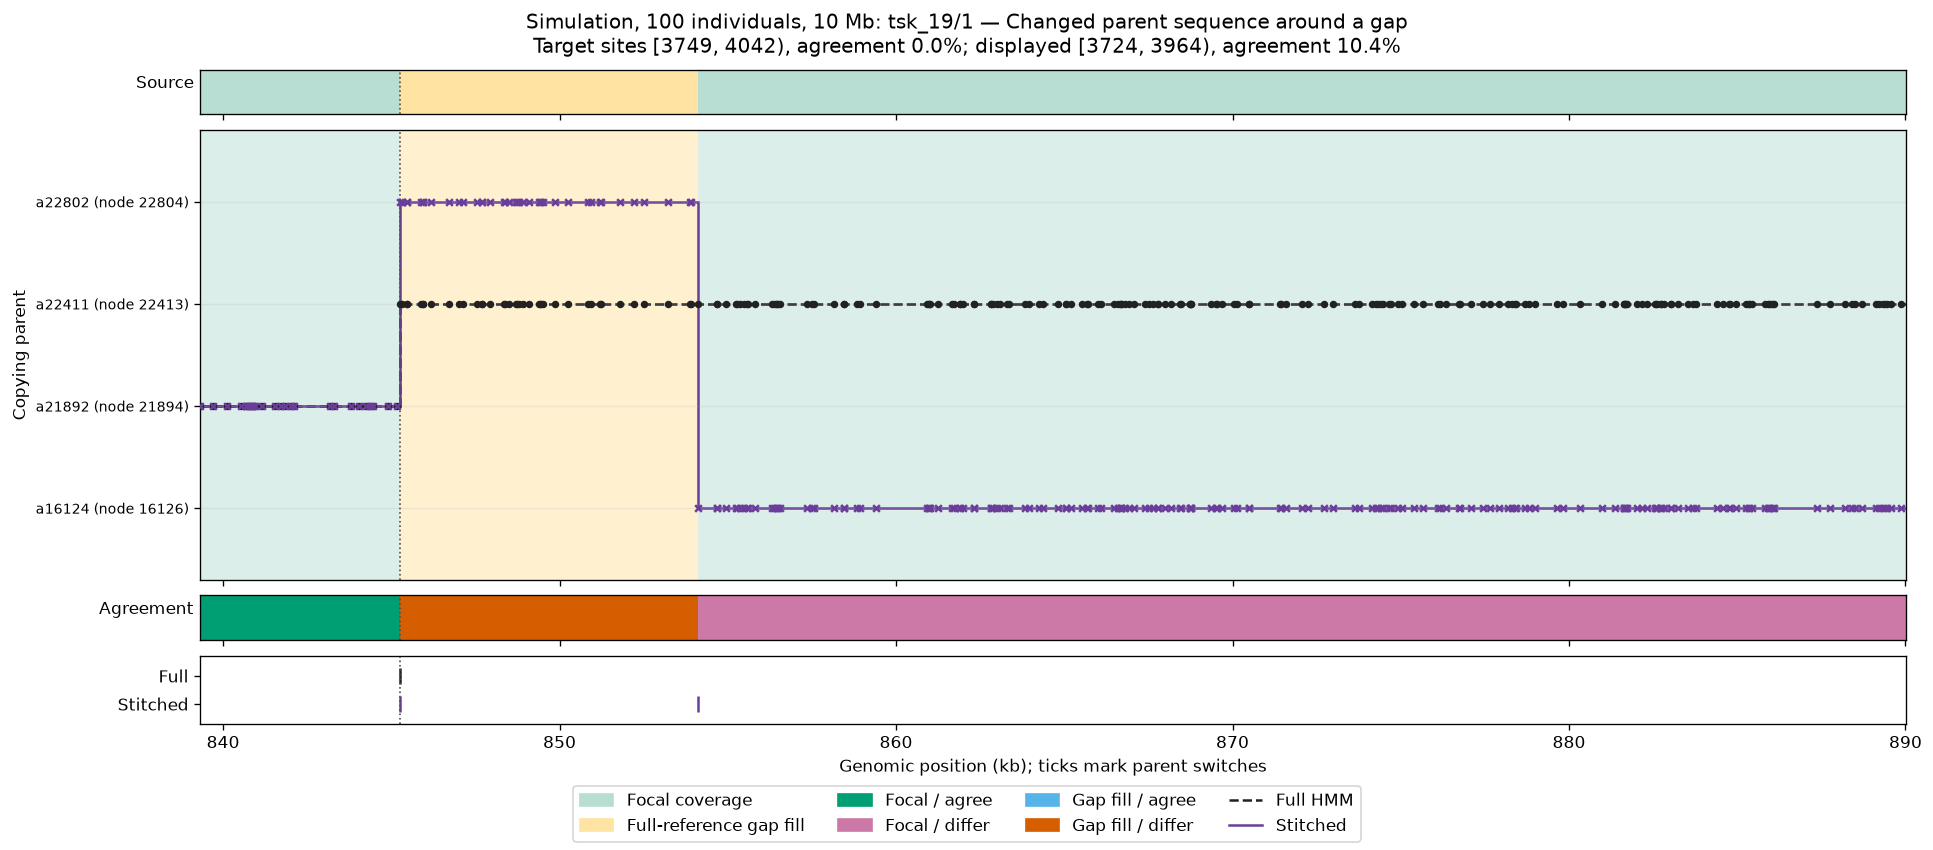

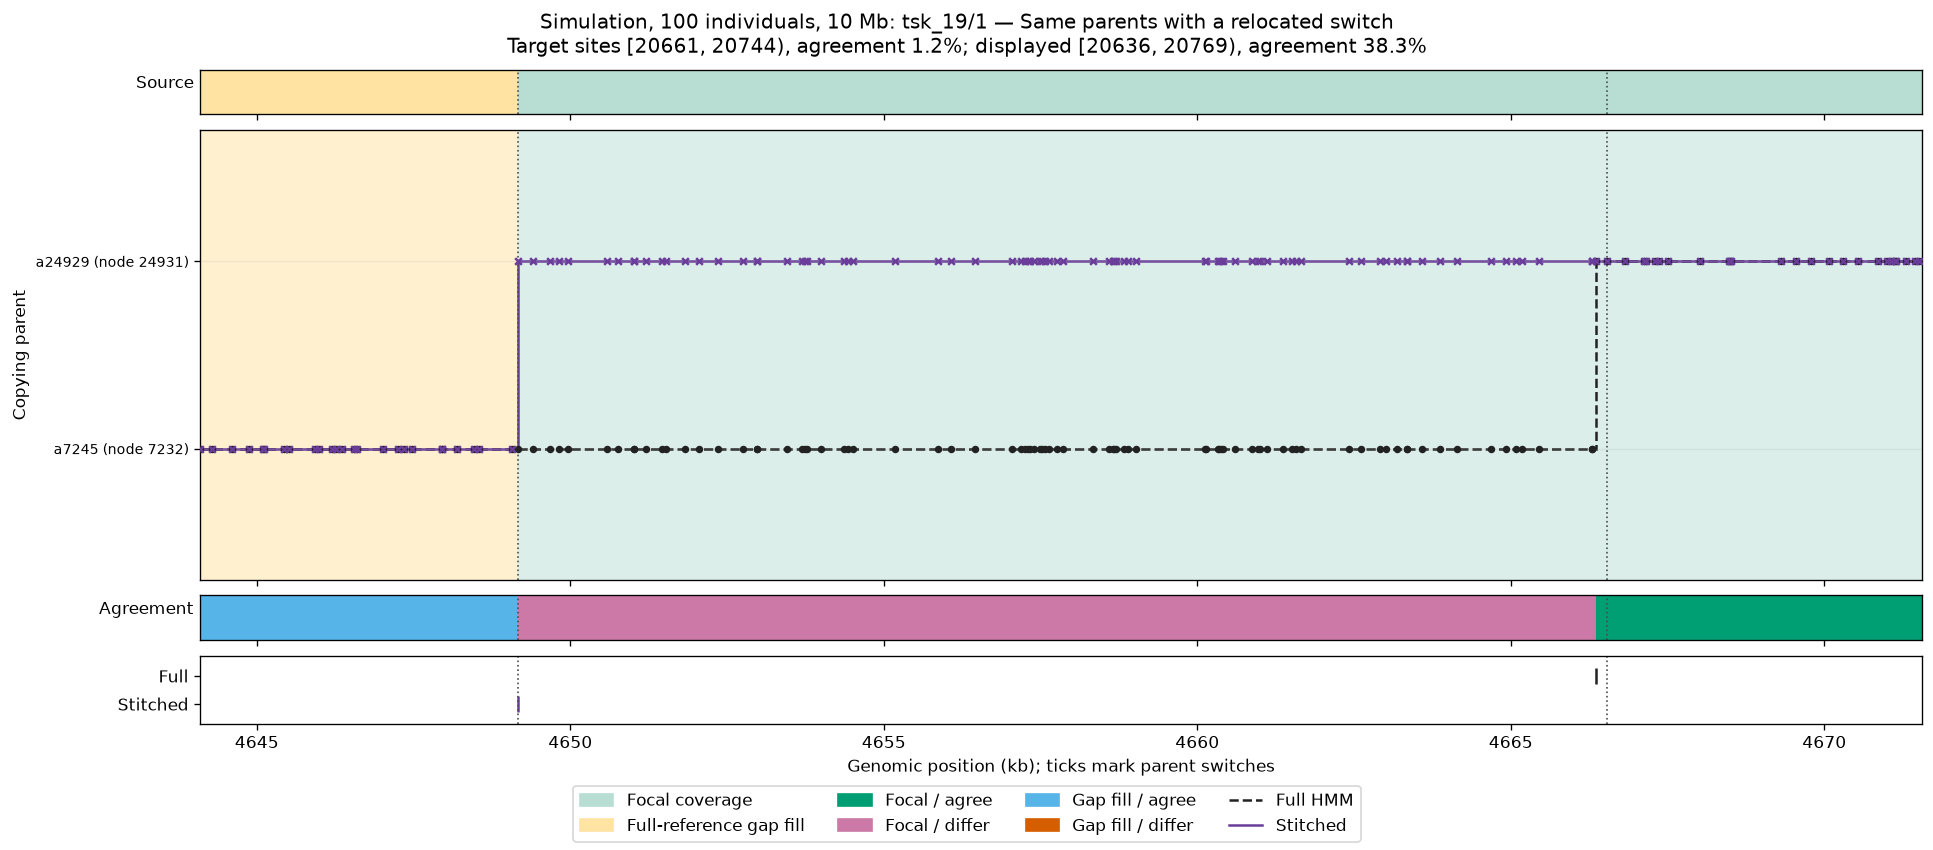

Detailed windows: 1KGP chromosome 20, 100 individuals, 10 Mb, NA19150/1


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,tgp_chr20_n100,NA19150/1,Short gap with extra switches,12006,12007,11981,12032,1.00,3007838.0,3017682.0
1,tgp_chr20_n100,NA19150/1,Lowest gap agreement,49933,50220,49908,50148,0.00,8848825.0,8880316.0
2,tgp_chr20_n100,NA19150/1,Longest focal parent disagreement,49048,49933,49023,49263,0.00,8749956.0,8781161.0
3,tgp_chr20_n100,NA19150/1,Same parents with a relocated switch,4622,4673,4597,4698,0.02,1845449.0,1861980.0


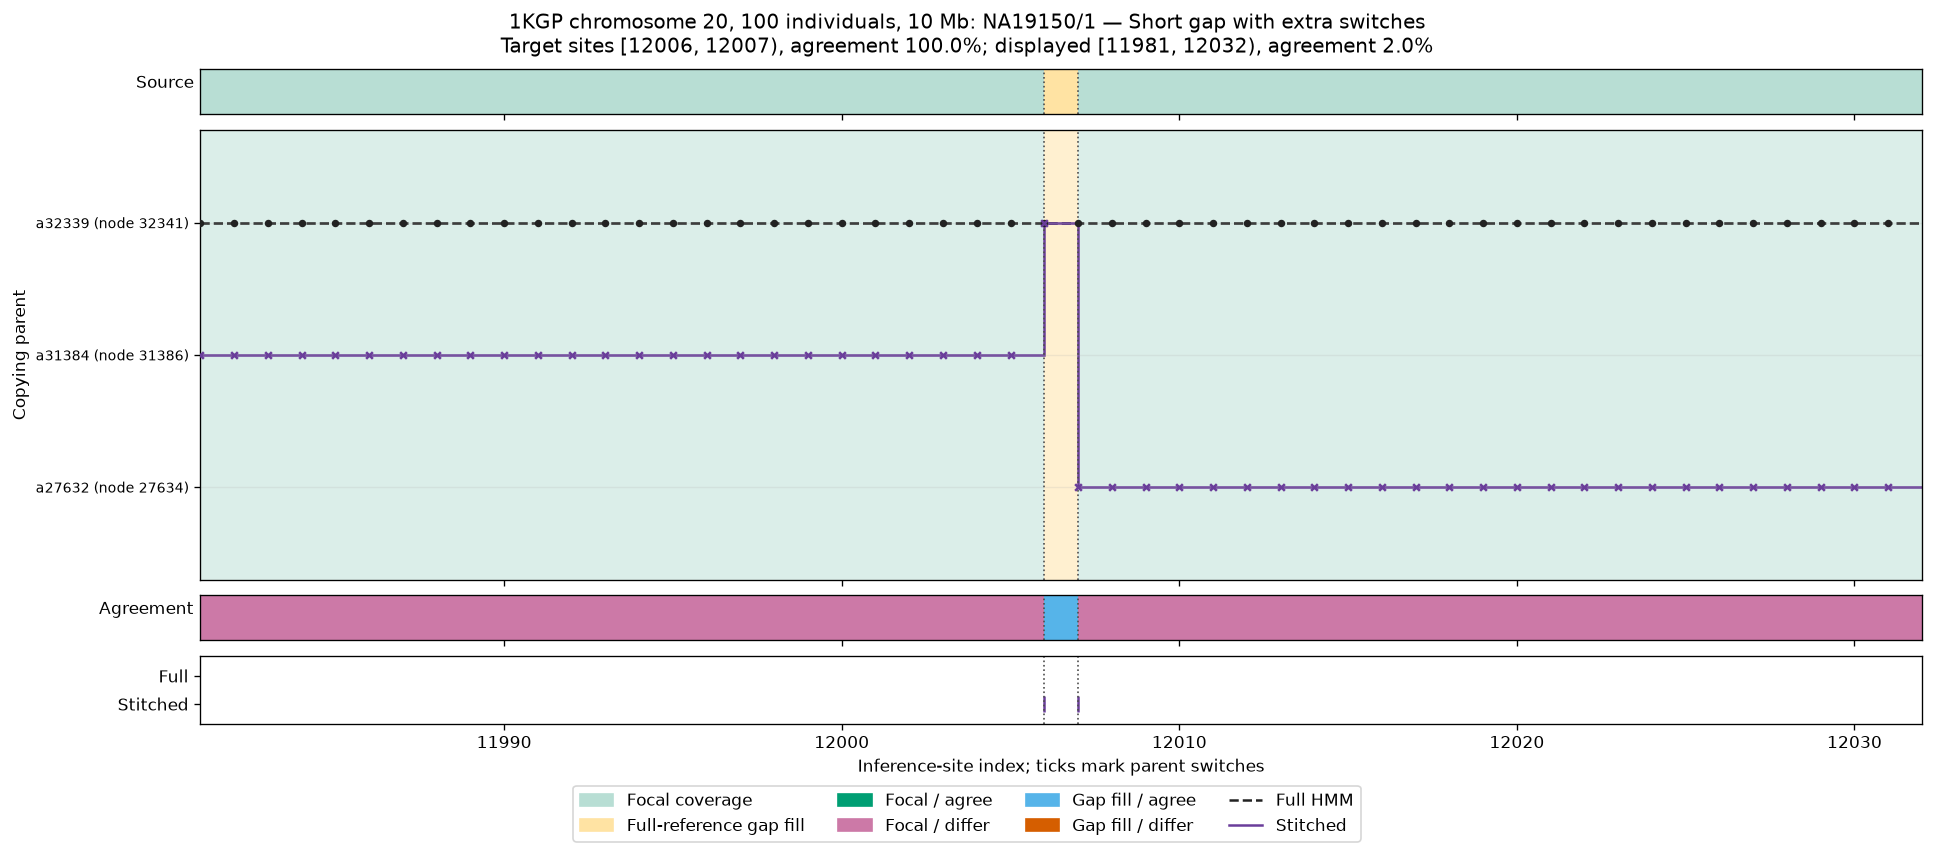

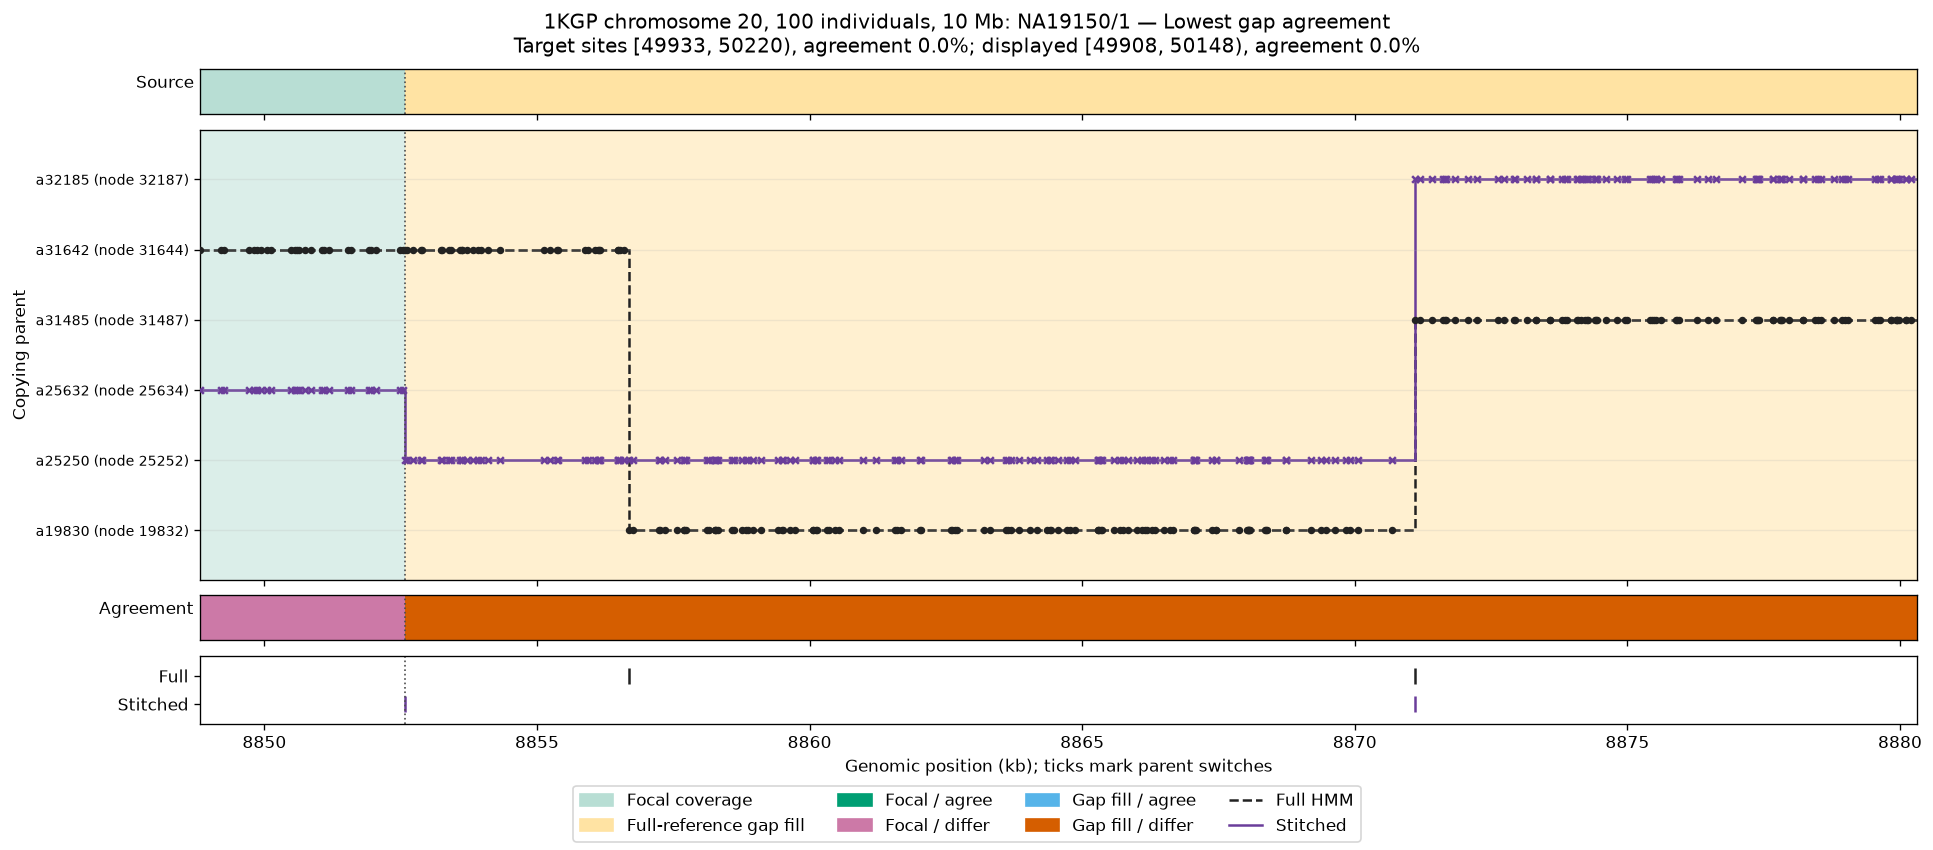

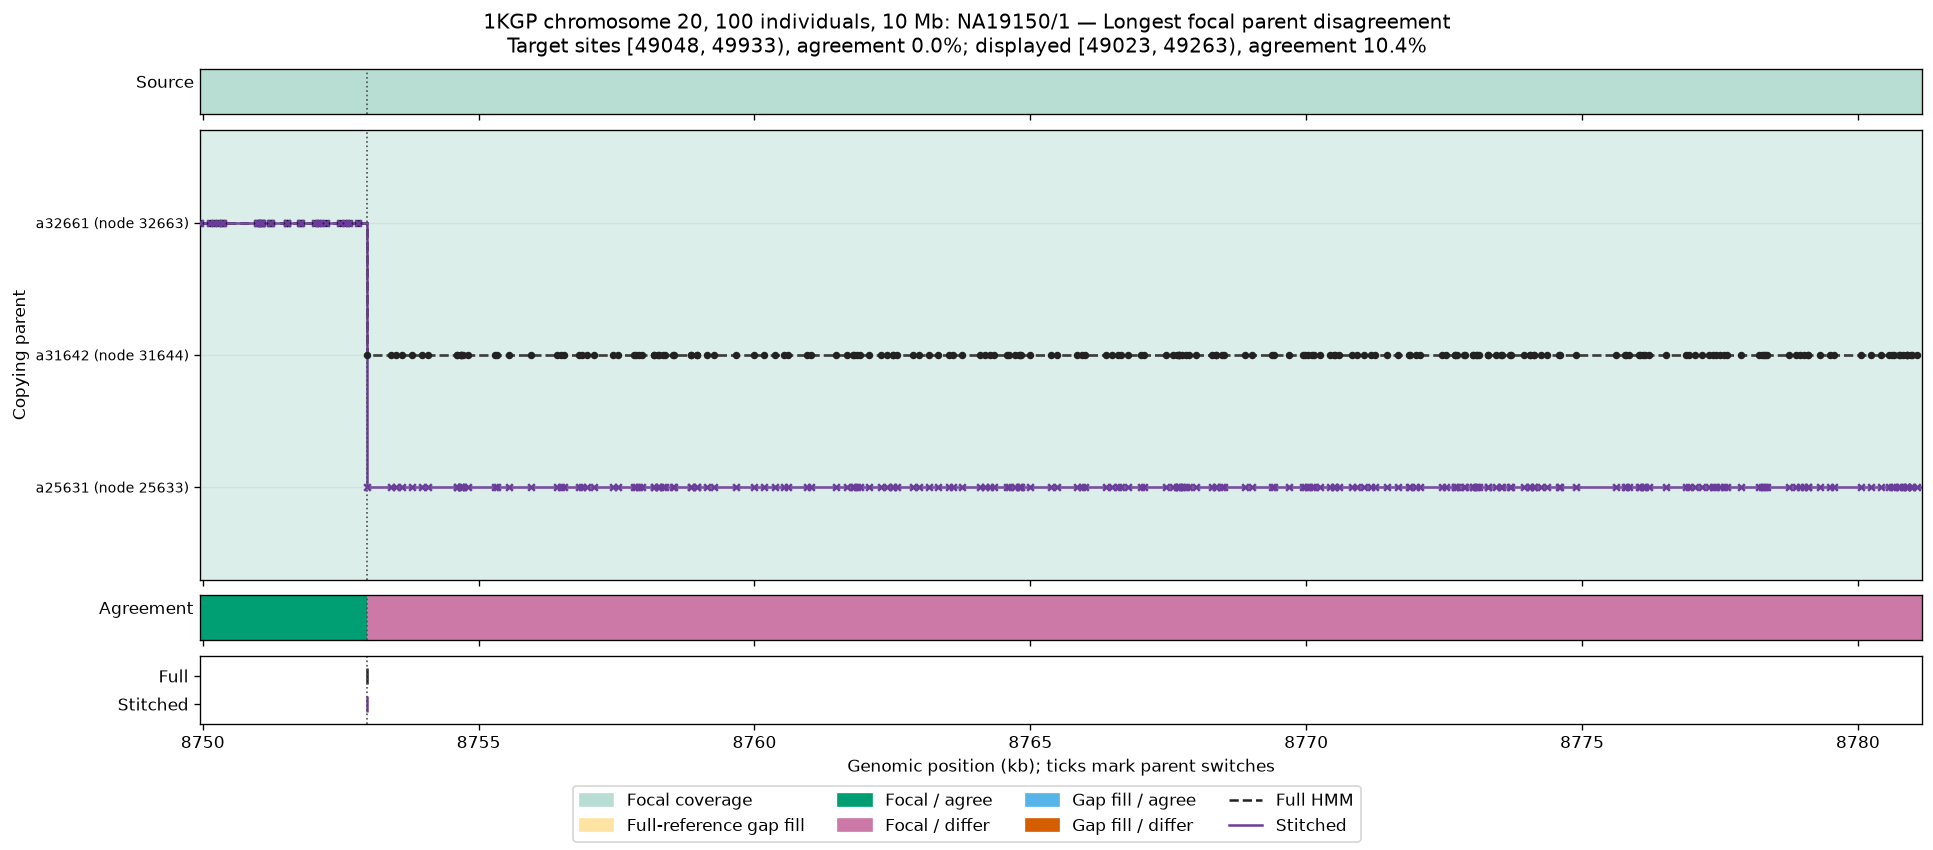

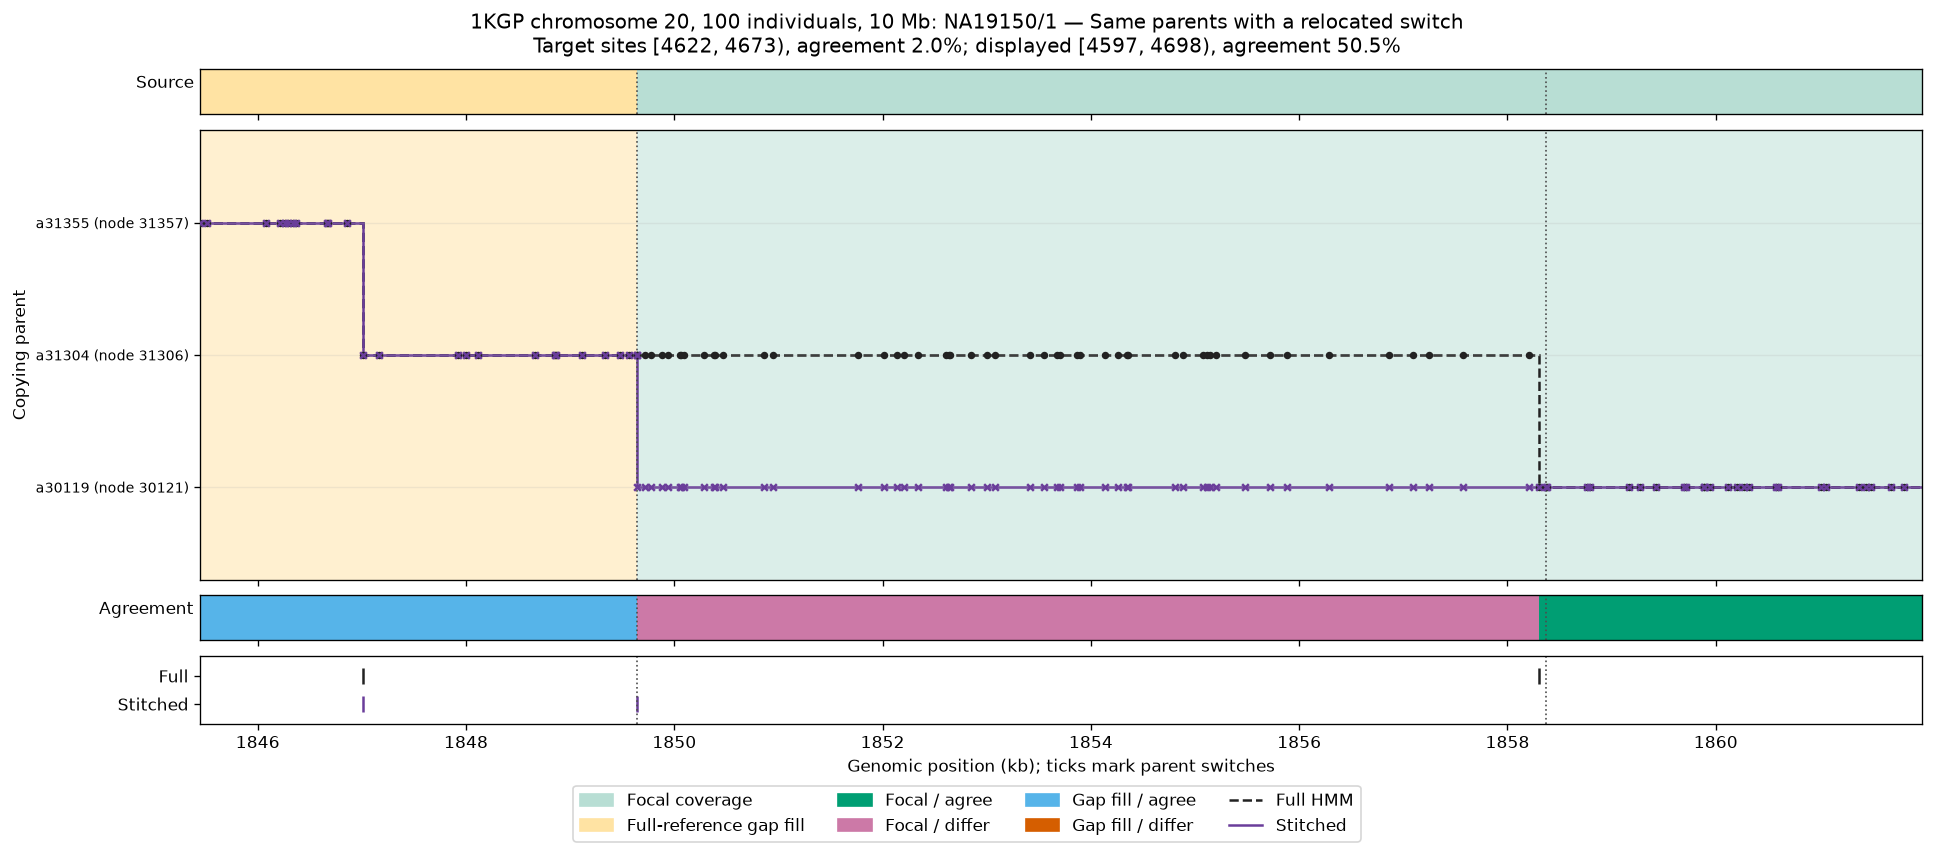

Detailed windows: 1KGP chromosome 20, 100 individuals, 10 Mb, NA18565/1


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,tgp_chr20_n100,NA18565/1,Short gap with extra switches,11903,11904,11878,11929,1.000,2982277.0,2995283.0
1,tgp_chr20_n100,NA18565/1,Lowest gap agreement,49846,50072,49821,50061,0.000,8840628.0,8868732.0
2,tgp_chr20_n100,NA18565/1,Longest focal parent disagreement,48049,49846,48024,48264,0.000,8579999.0,8621404.0
3,tgp_chr20_n100,NA18565/1,Changed parent sequence around a gap,2242,3432,3004,3244,0.000,1519529.0,1559180.0
4,tgp_chr20_n100,NA18565/1,Same parents with a relocated switch,58807,59123,58782,59148,0.003,10427023.0,10486334.0


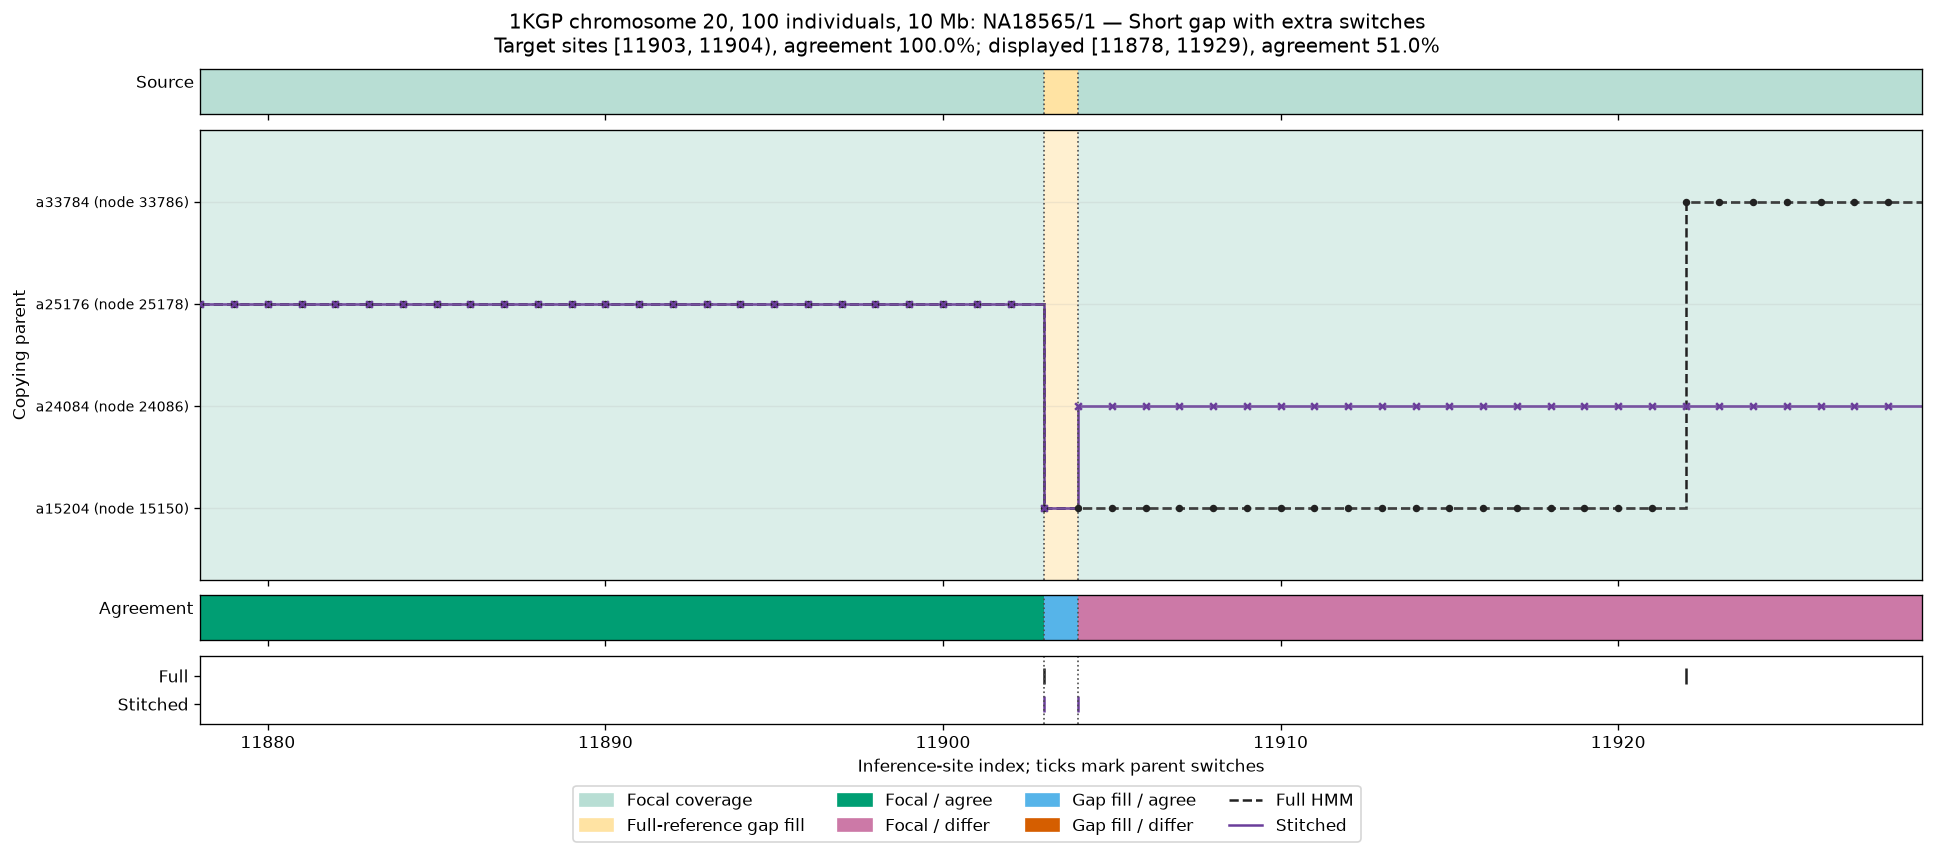

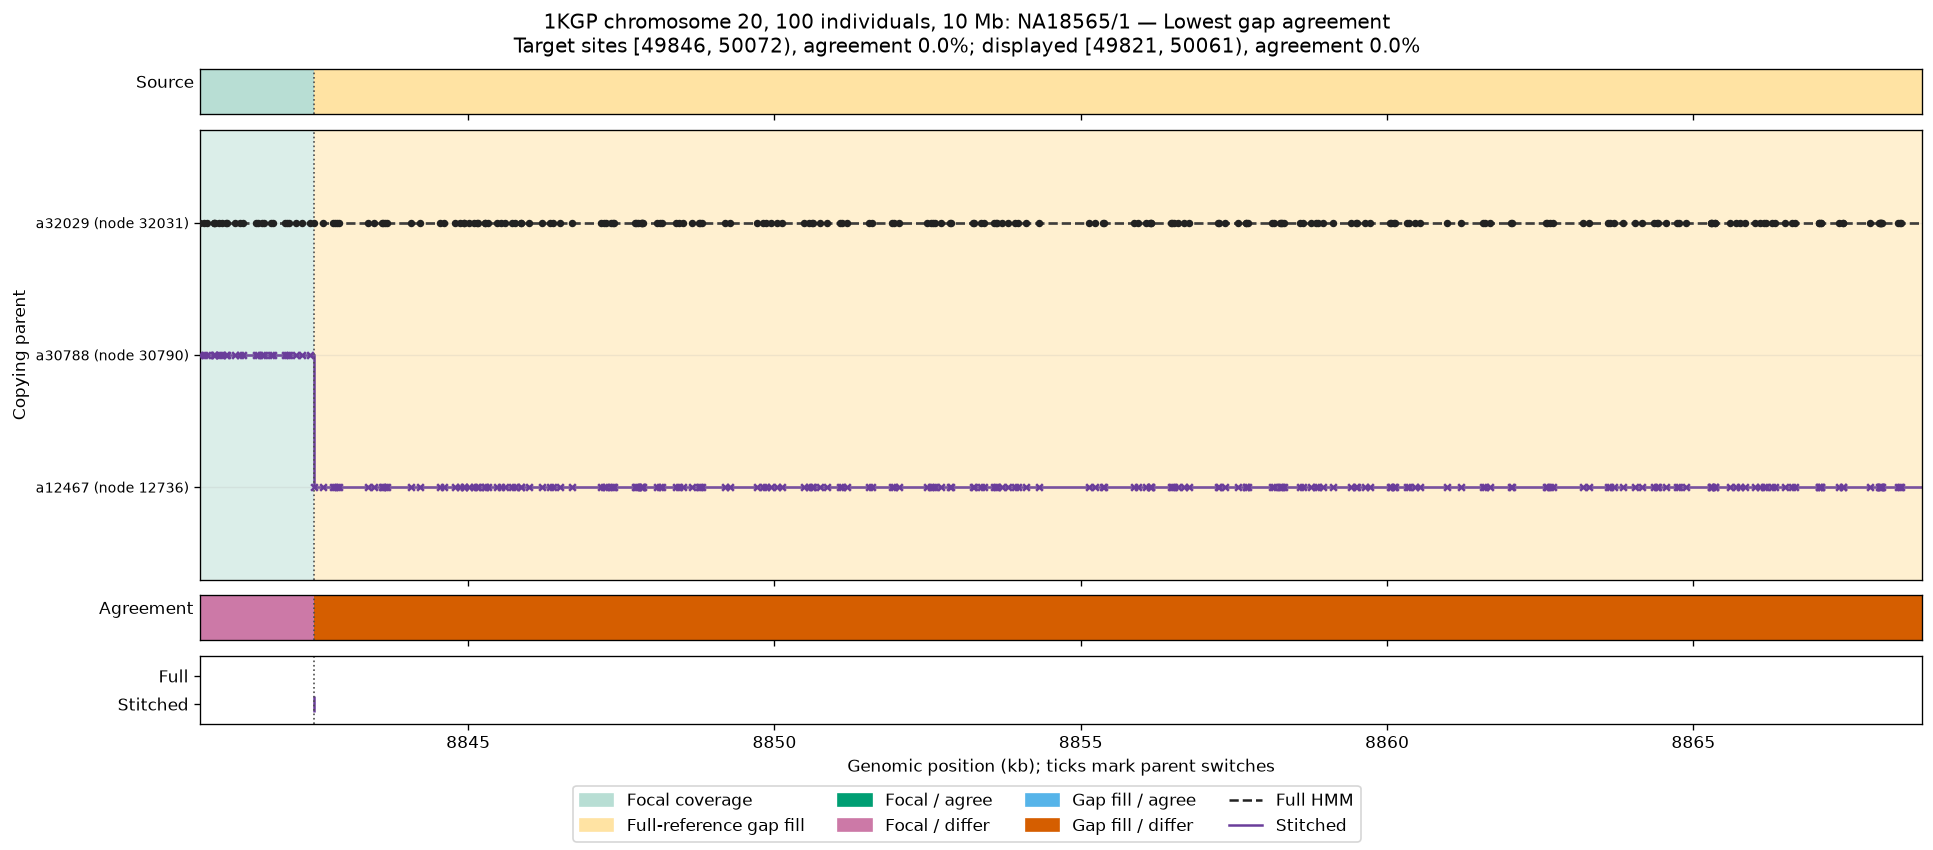

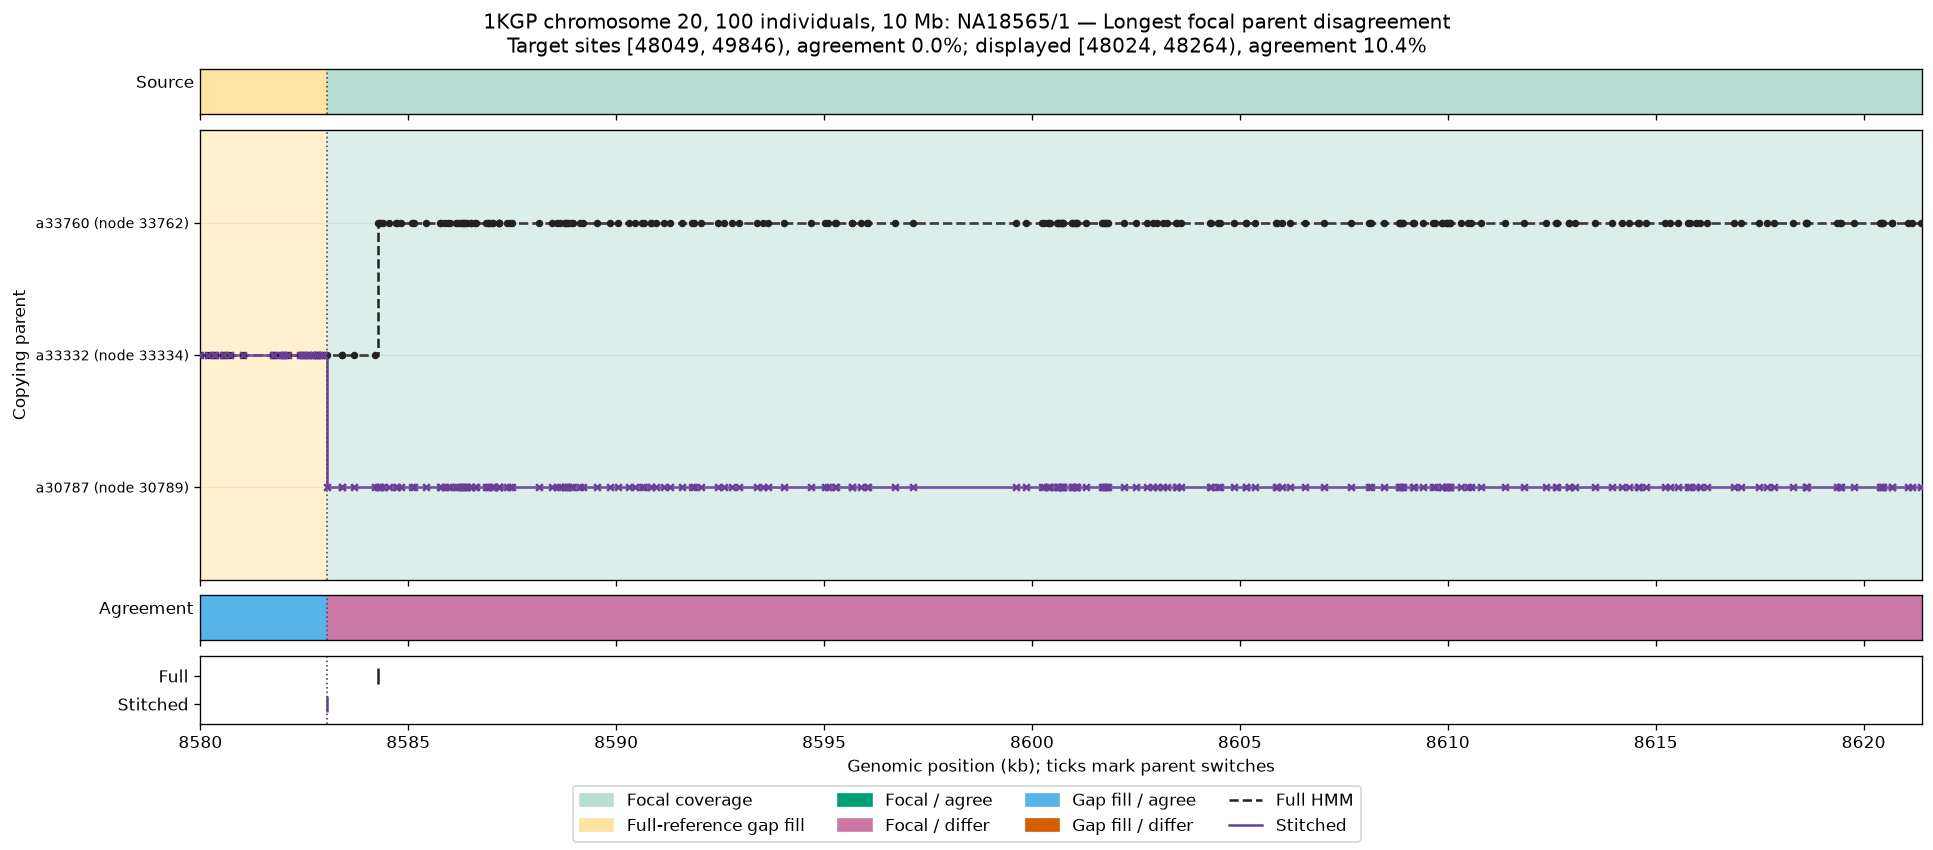

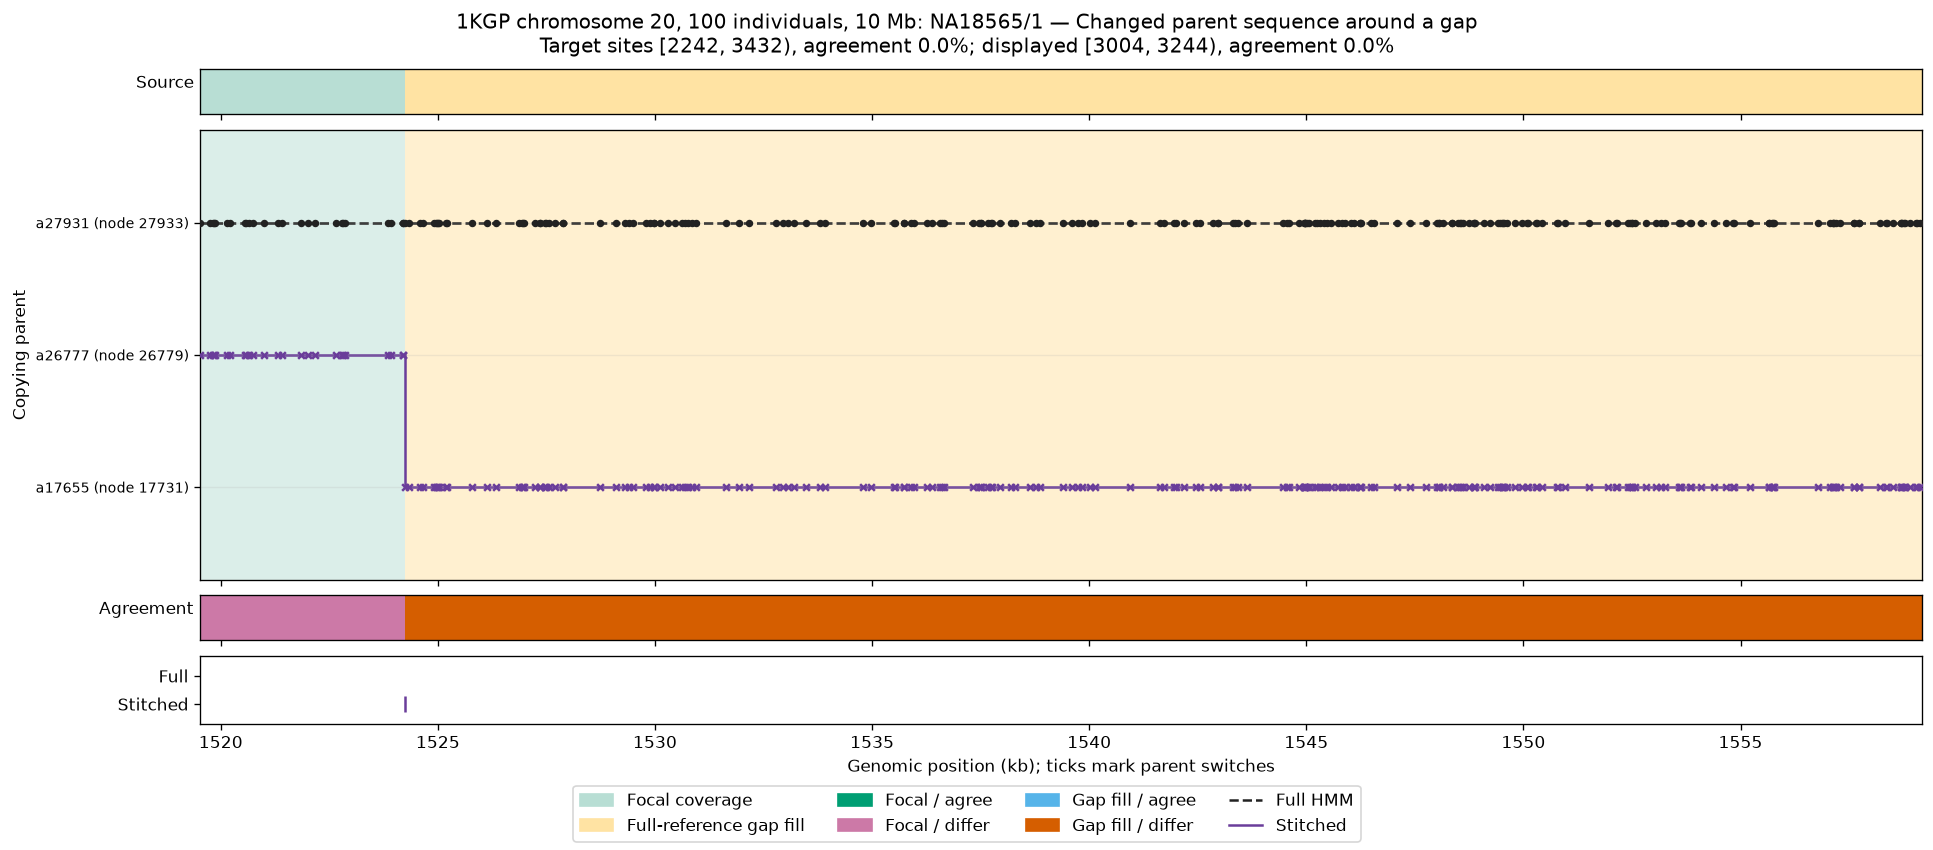

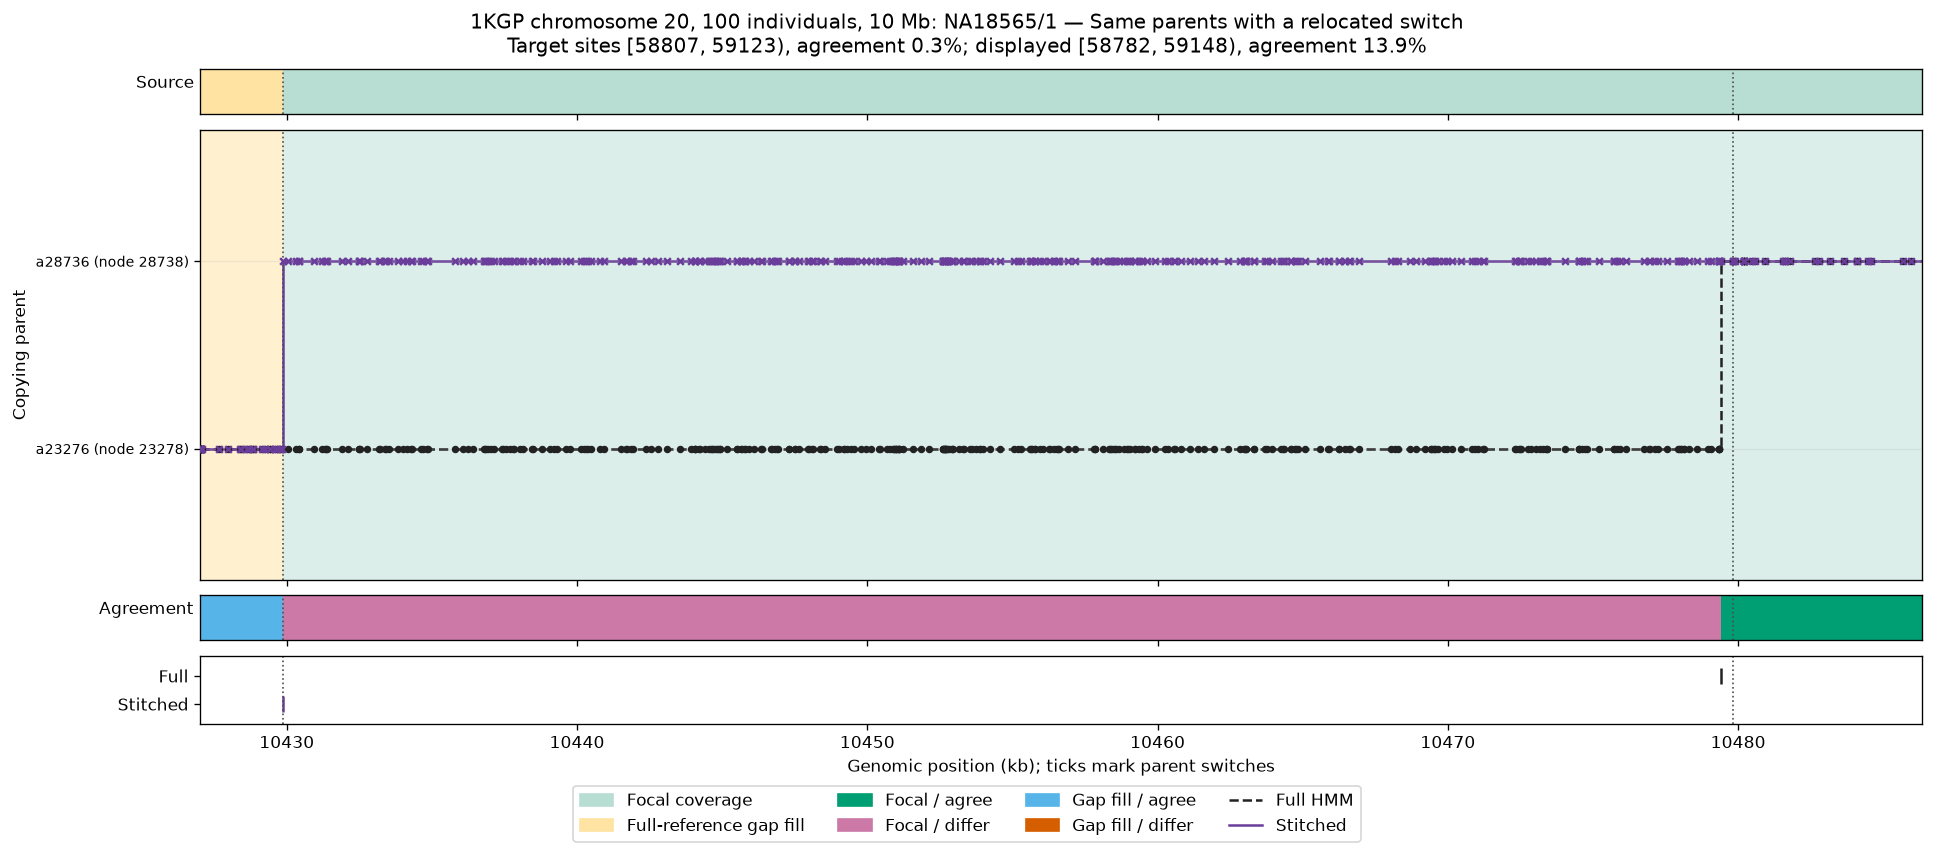

Detailed windows: 1KGP chromosome 20, 100 individuals, 10 Mb, NA18518/0


,dataset,haplotype,kind,target_start,target_end,start,end,target_agreement,display_start_bp,display_end_bp
0,tgp_chr20_n100,NA18518/0,Short gap with extra switches,22016,22017,21991,22042,0.0,4605975.0,4613106.0
1,tgp_chr20_n100,NA18518/0,Longest focal parent disagreement,55641,56515,55616,55856,0.0,9907622.0,9952397.0
2,tgp_chr20_n100,NA18518/0,Changed parent sequence around a gap,22016,22057,21991,22082,0.0,4605975.0,4616680.0


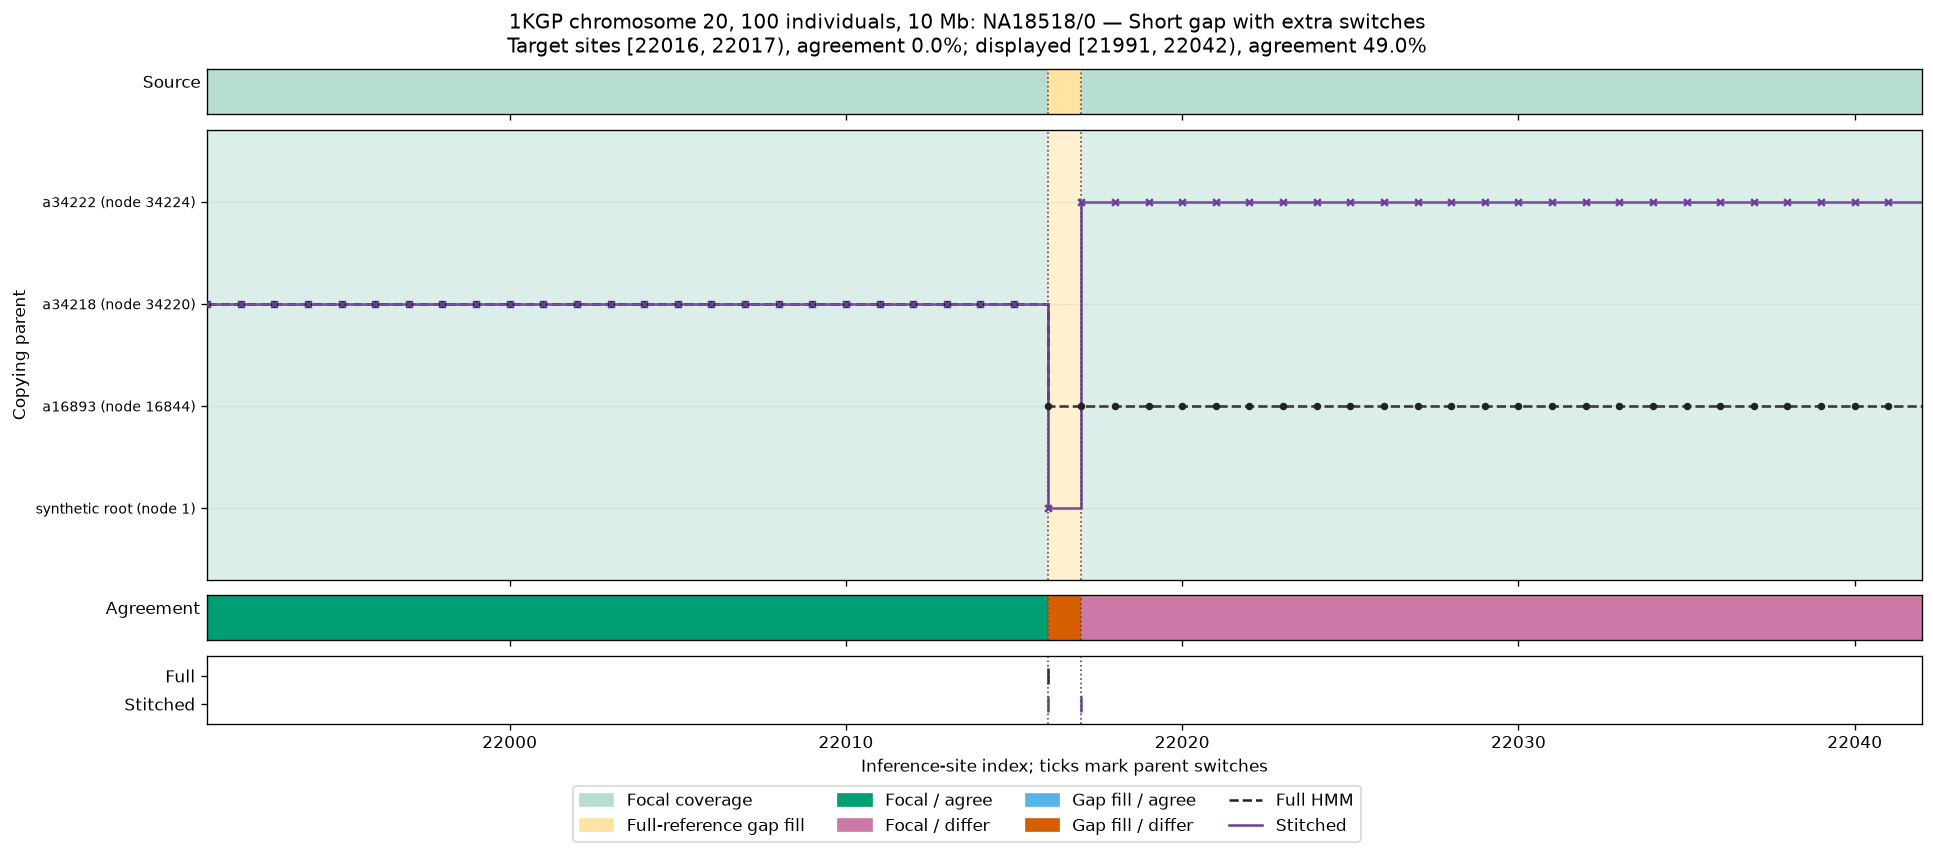

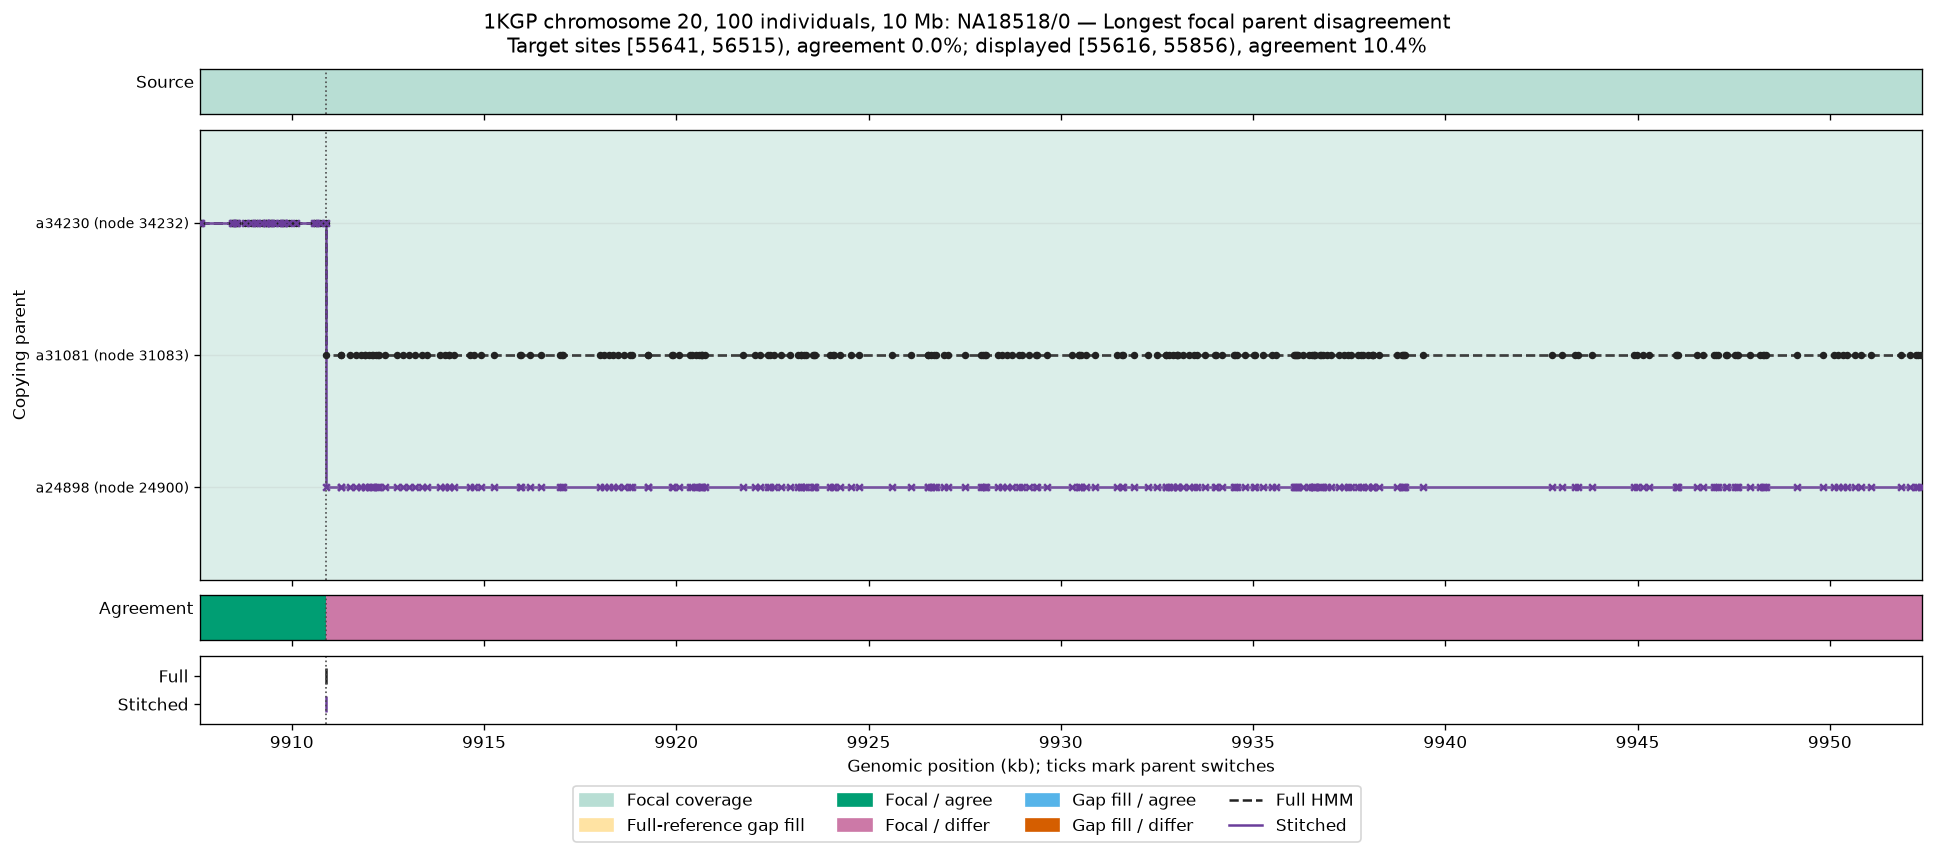

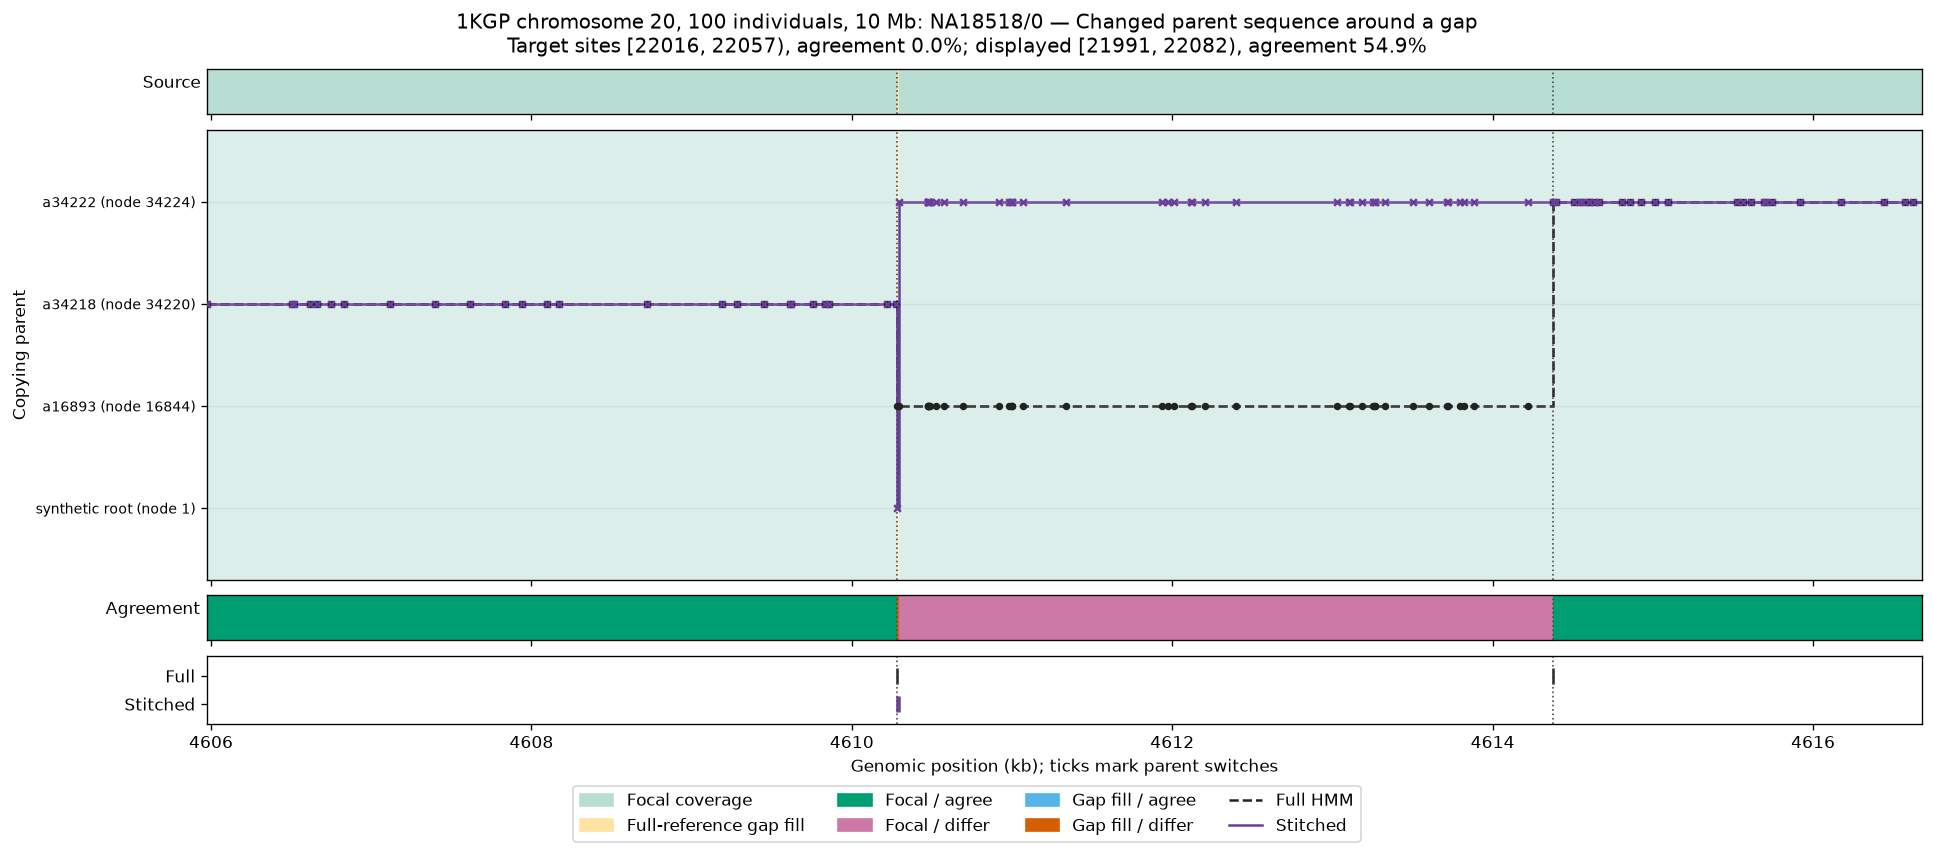

In [8]:
outlier_window_rows = []
nb_plot.plot_deep_dive_3(
    category_cmap=category_cmap,
    category_norm=category_norm,
    config=config,
    coverage_handles=coverage_handles,
    outlier_case_datasets=outlier_case_datasets,
    outlier_output_dir=outlier_output_dir,
    outlier_window_rows=outlier_window_rows,
    outlier_windows=outlier_windows,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
pd.DataFrame(outlier_window_rows).to_csv(
    outlier_output_dir / "outlier_detail_windows.csv", index=False
)

Finally, compare disagreement with distance from the nearest seam separately
for every outlier and source region. Distance is in inference-site steps;
the sites immediately beside a seam have distance zero. These are descriptive
profiles of selected outliers, with denominators exported alongside the plot.

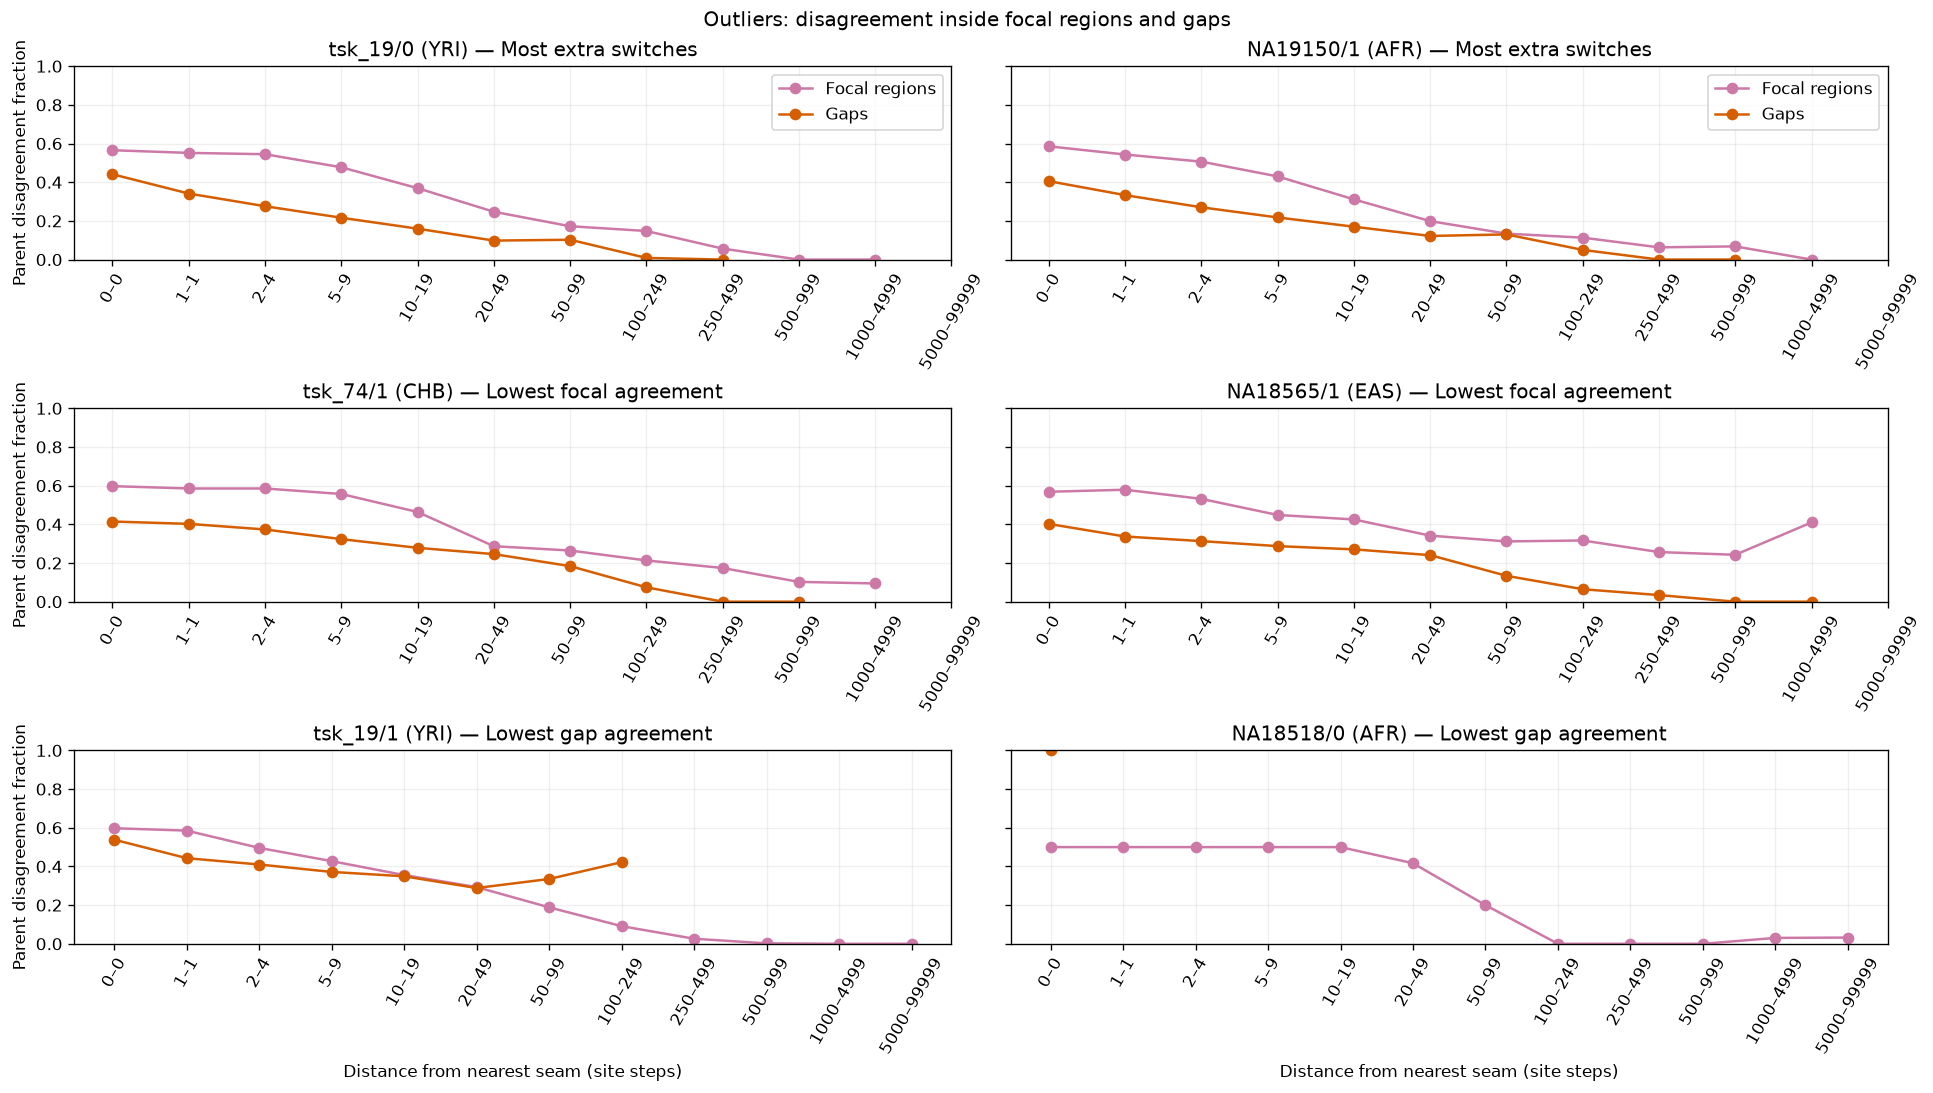

In [24]:
outlier_distance_rows = nb_plot.plot_deep_dive_4(
    config=config,
    outlier_datasets=outlier_datasets,
    outlier_output_dir=outlier_output_dir,
    outlier_selection=outlier_selection,
    figsize=[16, 9],
    marker="o",
    ylim=(0, 1),
    alpha=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
pd.DataFrame(outlier_distance_rows).to_csv(
    outlier_output_dir / "outlier_seam_distance_counts.csv", index=False
)

# Diagnosing stitched focal and gap matches

Compare full HMM and stitched copying paths for a 10 Mb simulation and a
10 Mb region of chromosome 20 from 1KGP. Focal coverage is the union of
zero-mismatch intervals anchored at each eligible ancestor's leftmost focal
site, using 2 ≤ focal AC ≤ 10. Gaps are maximal uncovered site runs.
Within coverage, a covering ancestor is kept until its interval ends; the
next available interval extending furthest right is chosen, with original
node ID breaking ties. Independent full-reference HMM matches fill the gaps.
All parents are original-reference node IDs.

Questions:
1. Which focal pieces and gap fills agree with the full HMM parent path?
2. Where do the additional switches occur: inside focal pieces, inside gaps,
   or at the seams between them?
3. Can we inspect both successful and unsuccessful gap fills, and focal pieces
   that already differ from the full path?

Settings and deep-dive identities live in
the scientific settings cell below. The notebook reads existing
outputs and copied references; it does not rerun matching or change its inputs.
Edit this `.py` file and use Jupytext to synchronize the paired notebook.

In [25]:
datasets = [
    nb_utils.path_diagnostics_load_dataset(
        settings,
        experiment_config=experiment_config,
        input_dir=input_dir,
        output_dir=output_dir,
        plot_terminal_site_width_bp=1,
    )
    for settings in config["datasets"]
]
summary = pd.DataFrame([case.summary for dataset in datasets for case in dataset.cases])
summary["focal_agreement_fraction"] = (
    1 - summary.focal_disagreement_sites / summary.focal_sites
)
summary["gap_agreement_fraction"] = (
    1 - summary.gap_disagreement_sites / summary.gap_sites
)
ipython_display.display(
    summary[
        [
            "dataset",
            "sample_id",
            "ploidy_index",
            "num_focal_ancestors",
            "focal_sites",
            "gap_sites",
            "num_gaps",
            "fraction_parent_agreement",
            "focal_agreement_fraction",
            "gap_agreement_fraction",
            "full_switches",
            "stitched_switches",
            "num_extra_switches",
            "extra_switch_fraction",
            "full_mismatches",
            "stitched_mismatches",
        ]
    ].round(4)
)

,dataset,sample_id,ploidy_index,num_focal_ancestors,focal_sites,gap_sites,num_gaps,fraction_parent_agreement,focal_agreement_fraction,gap_agreement_fraction,full_switches,stitched_switches,num_extra_switches,extra_switch_fraction,full_mismatches,stitched_mismatches
0,out_of_africa_n100_10mbp,tsk_18,0,556,41317,2908,55,0.9368,0.9427,0.8525,250,259,9,0.0347,0,0
1,out_of_africa_n100_10mbp,tsk_40,1,184,36488,7737,37,0.9052,0.8997,0.9312,162,164,2,0.0122,0,0
2,out_of_africa_n100_10mbp,tsk_96,1,127,32845,11380,34,0.9191,0.9157,0.9290,165,168,3,0.0179,0,0
3,tgp_chr20_n100,NA07019,1,171,43466,18332,54,0.8563,0.8513,0.8682,247,261,14,0.0536,0,0
4,tgp_chr20_n100,NA18582,0,94,28712,33086,48,0.8666,0.7609,0.9583,239,245,6,0.0245,0,0
5,tgp_chr20_n100,NA19150,0,627,51222,10576,119,0.8082,0.7846,0.9226,453,487,34,0.0698,0,0


## Coverage, agreement, and switches across the saved haplotypes

Bar lengths below are **fractions of inference sites**, not physical coverage.
Focal/gap provenance and parent agreement are independent dimensions. An exact
focal allele match may still copy a different parent than the full HMM.

Switches are changes between adjacent site parents. A seam is the edge where
provenance changes between focal coverage and a gap fill; it contributes
a switch only if the parent changes there. The same edge categories are used for
the full HMM path so their totals can be compared directly.

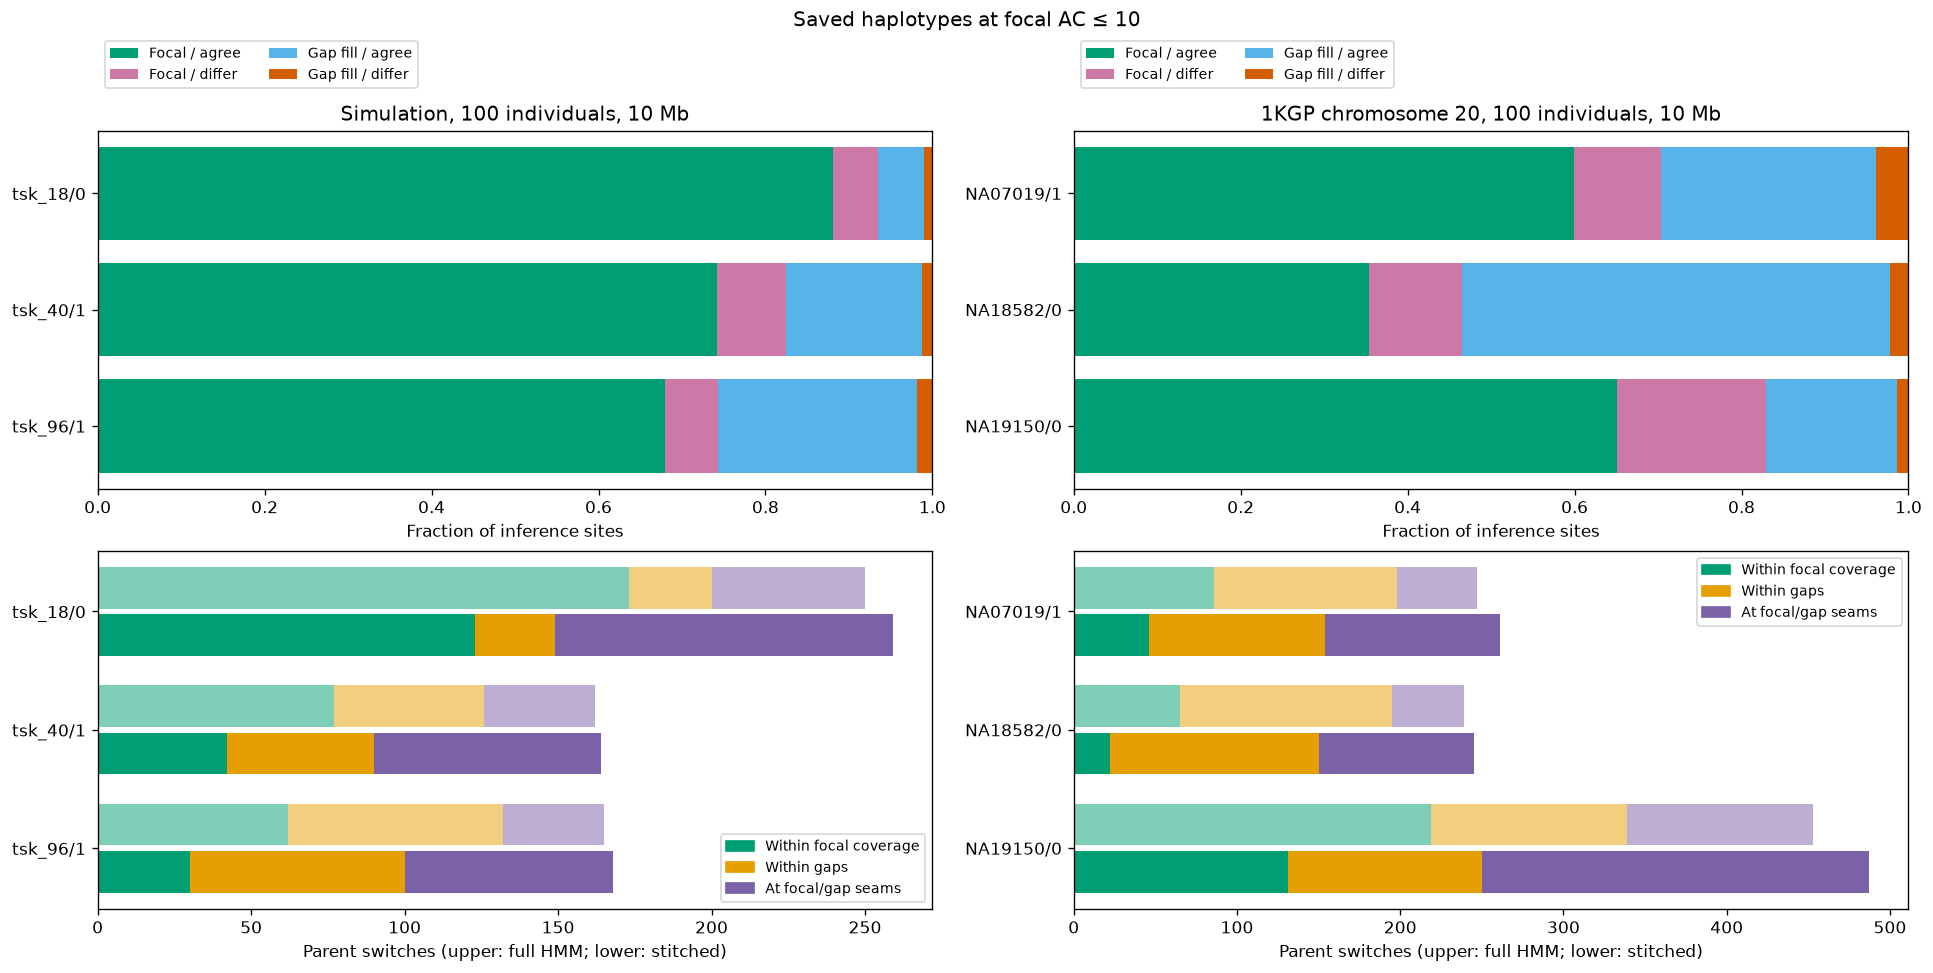

,dataset,haplotype,method,Within focal coverage,Within gaps,At focal/gap seams
0,"Simulation, 100 individuals, 10 Mb",tsk_18/0,full,173,27,50
1,"Simulation, 100 individuals, 10 Mb",tsk_40/1,full,77,49,36
2,"Simulation, 100 individuals, 10 Mb",tsk_96/1,full,62,70,33
3,"Simulation, 100 individuals, 10 Mb",tsk_18/0,stitched,123,26,110
4,"Simulation, 100 individuals, 10 Mb",tsk_40/1,stitched,42,48,74
5,"Simulation, 100 individuals, 10 Mb",tsk_96/1,stitched,30,70,68
6,"1KGP chromosome 20, 100 individuals, 10 Mb",NA07019/1,full,86,112,49
7,"1KGP chromosome 20, 100 individuals, 10 Mb",NA18582/0,full,65,130,44
8,"1KGP chromosome 20, 100 individuals, 10 Mb",NA19150/0,full,219,120,114
9,"1KGP chromosome 20, 100 individuals, 10 Mb",NA07019/1,stitched,46,108,107


In [26]:
case_summary = nb_plot.plot_case_summary(
    datasets,
    f"Saved haplotypes at focal AC ≤ {experiment_config['ac_cutoff']}",
    plot_category_colors=["#009E73", "#CC79A7", "#56B4E9", "#D55E00"],
    plot_category_labels=[
        "Focal / agree",
        "Focal / differ",
        "Gap fill / agree",
        "Gap fill / differ",
    ],
    plot_cohort_figsize=[16, 8],
    plot_switch_colors=["#009E73", "#E69F00", "#7B61A8"],
    plot_switch_labels=["Within focal coverage", "Within gaps", "At focal/gap seams"],
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.show_figure()
switch_table = case_summary.switches
ipython_display.display(switch_table)

## Extra switch fraction

`num_extra_switches = stitched_switches - full_switches`, and
`extra_switch_fraction = num_extra_switches / stitched_switches`.
This reports the net extra switches as a proportion of all stitched switches,
using the stitched count as the denominator. It is undefined when the stitched
path has no switches, and can be negative if stitching reduces the count.
The count alone does not identify which individual switches are unnecessary.

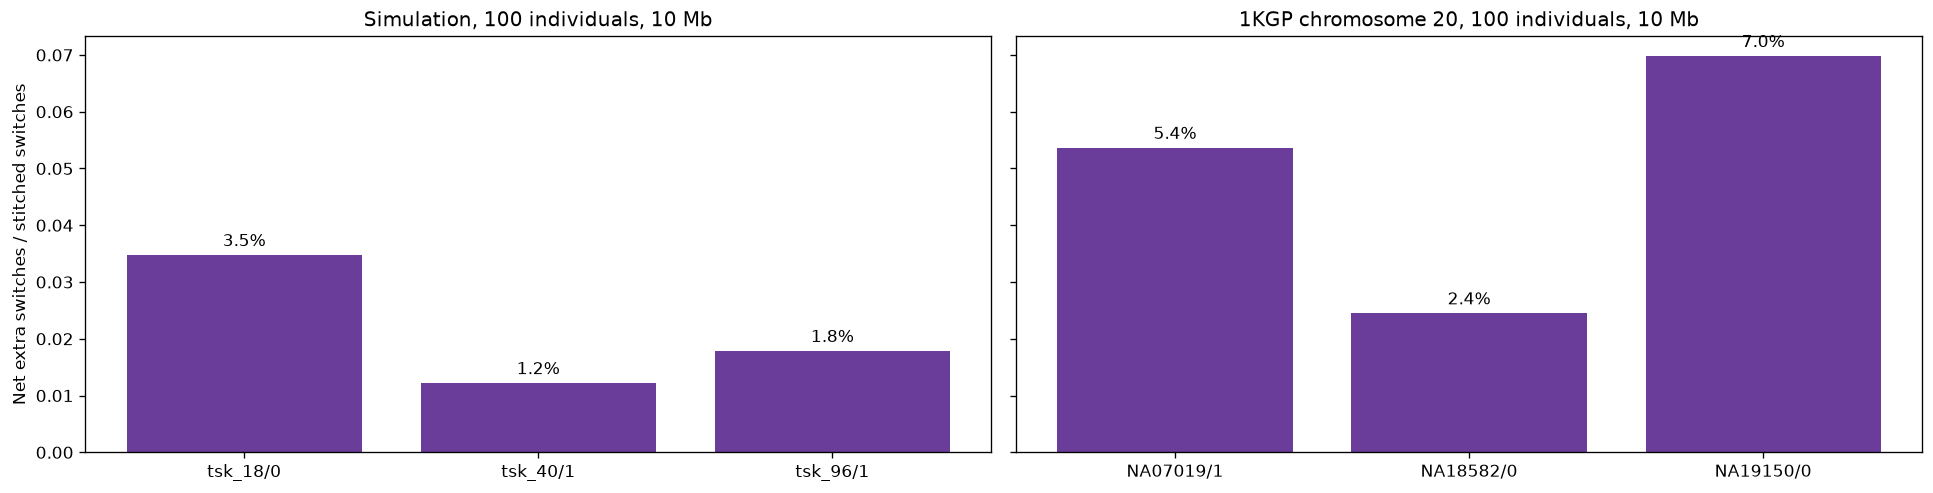

In [27]:
nb_plot.plot_extra_switch_fraction_2(
    datasets=datasets,
    figsize=[16, 4],
    color="#6A3D9A",
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Where covered focal pieces and gap fills agree with the full path

Each haplotype has two tracks: provenance (covered focal or gap fill), then
the four-way agreement classification. Genomic widths are a display convention:
a site's classification extends to the next inference-site position, with one
configured plotting width at the final site. This is **not** evidence of exact
focal matching between sites or beyond ancestor support. All counts and rates
remain site-based. The chromosome's unobserved flanks are excluded from plots.

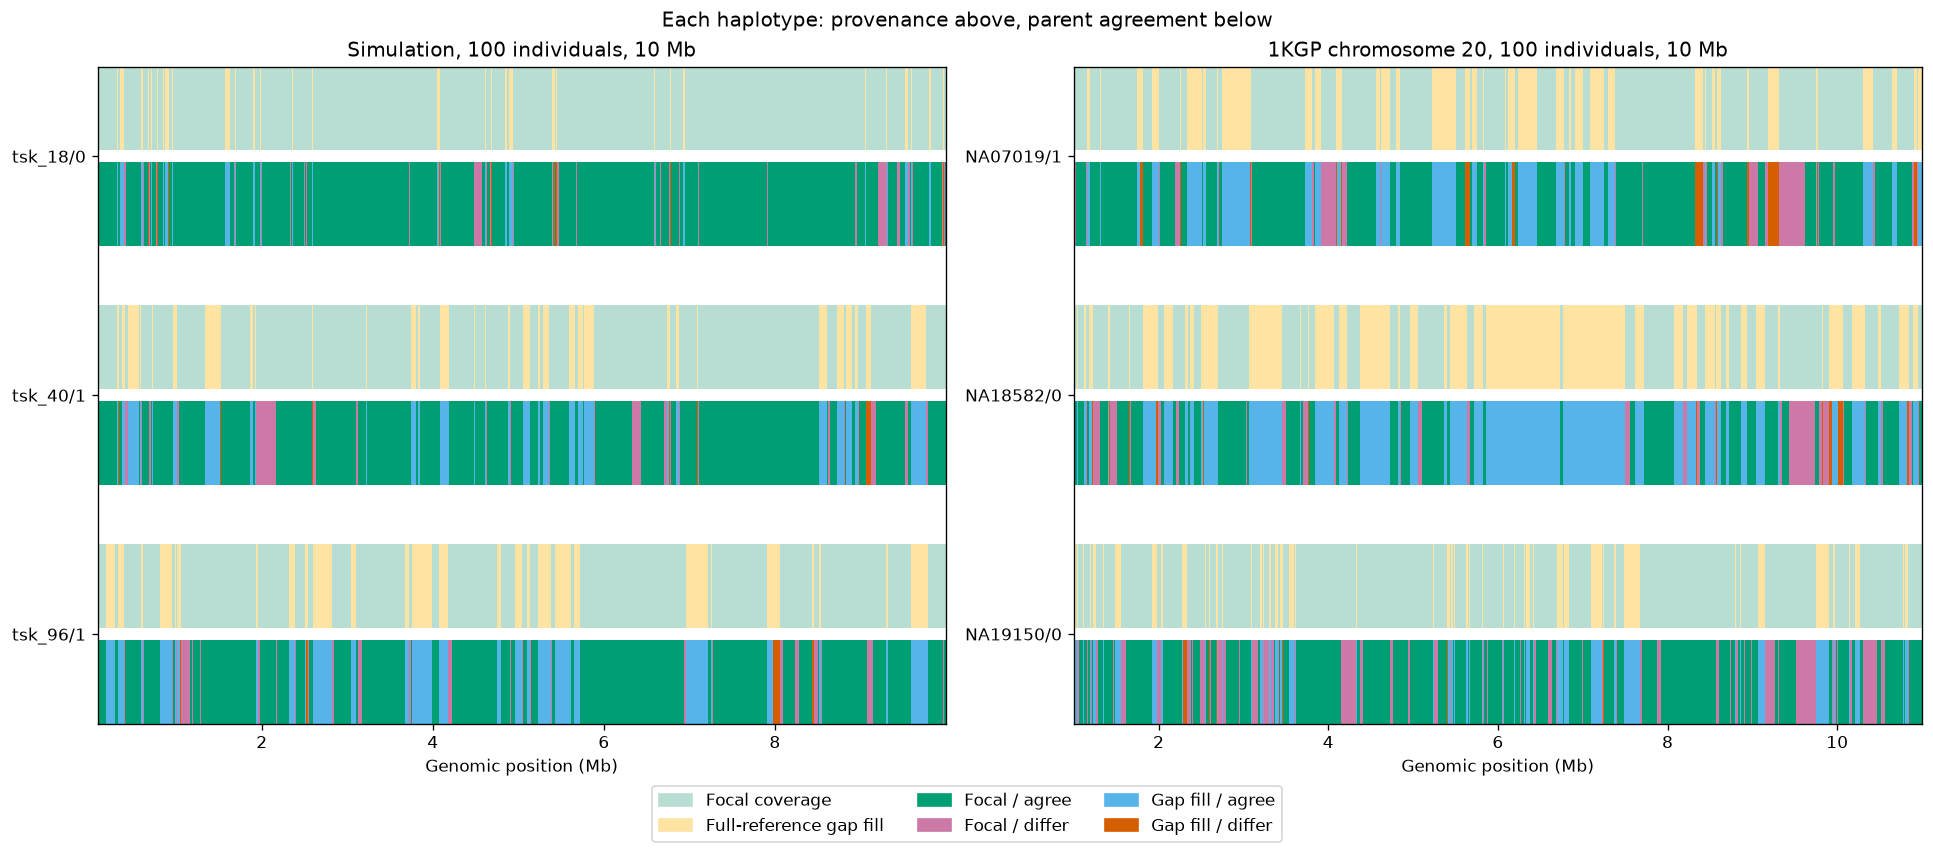

In [28]:
fig = nb_plot.plot_case_tracks(
    datasets,
    "Each haplotype: provenance above, parent agreement below",
    category_cmap=category_cmap,
    category_norm=category_norm,
    coverage_handles=coverage_handles,
    plot_genome_unit_bp=1000000,
    plot_genome_unit_label="Mb",
    plot_tracks_figsize=[16, 7],
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
nb_plot.show_figure()

## Whole-span paths for the selected simulated and real haplotypes

The full HMM and stitched paths use the same original-node ID scale. Node IDs
identify parents; their vertical spacing has no biological distance meaning.
The source and agreement tracks show which sites have focal coverage and which were
rematched. A gap's parent can agree with the full HMM for only part of that gap.

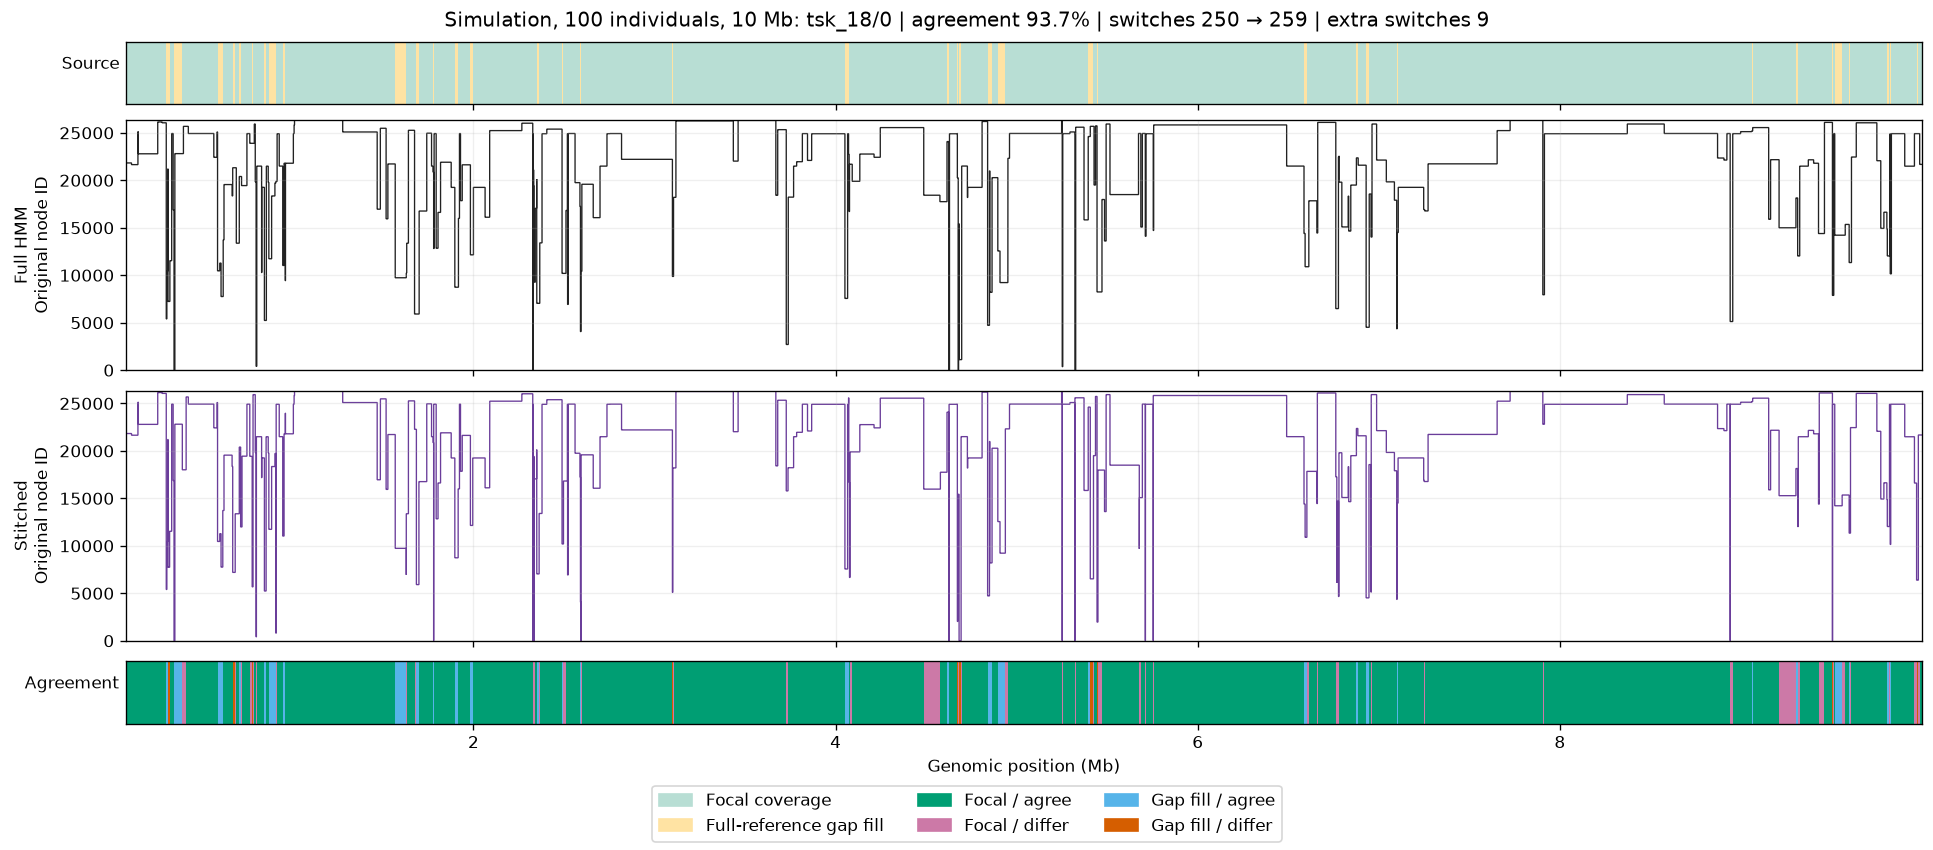

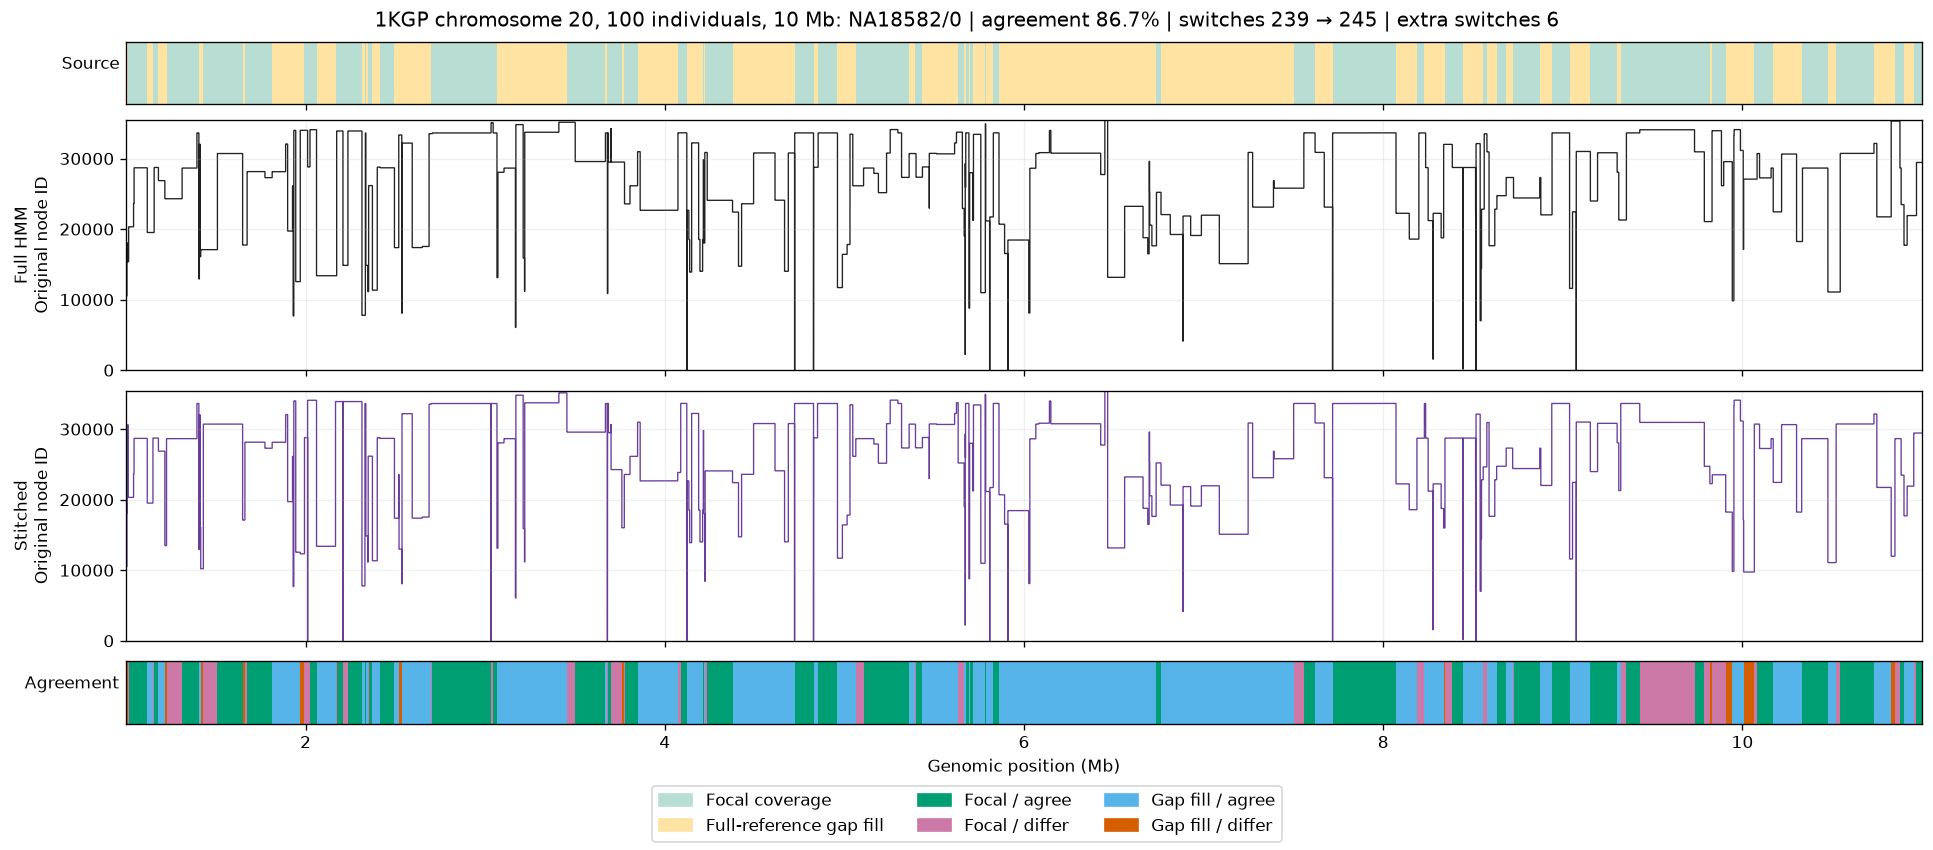

In [29]:
nb_plot.plot_whole_span_paths_for_the_selected_simulated_and_real(
    category_cmap=category_cmap,
    category_norm=category_norm,
    coverage_handles=coverage_handles,
    datasets=datasets,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Gap diagnostics and reproducible zoom selection

Each gap is summarized with its number of sites, agreement fraction, and the
switch counts strictly inside the gap. Left/right seam switches are reported
separately. Chromosome-edge gaps have no seam on their outer edge.

For each selected haplotype the notebook chooses four windows from the saved
site arrays, rather than hand-picking genomic coordinates:
- **Gap disagreement:** the gap with the most disagreeing sites; ties use NPZ
  interval order. The zoom is anchored on its first disagreeing site.
- **Gap agreement:** among gaps of at least the configured minimum size, choose
  the highest agreement fraction, breaking ties by longer gap then earlier
  interval. The zoom is anchored on its first agreeing site.
- **Mixed gap fill:** among gaps with both agreement and disagreement, choose
  the one with the most disagreeing sites, then the earliest gap. Anchor the
  zoom on its first within-gap transition between agreement and disagreement.
- **Focal disagreement:** the covered focal interval with the most disagreeing
  sites. The zoom is anchored on its first disagreement.

Short target intervals include their full extent and context on both sides.
Long intervals are clipped to the configured maximum site count around the
selected anchor, so a zoom may show only part of the target. Dashed lines mark
target boundaries when they are inside the displayed window. The table reports
both the complete target and the displayed half-open site window.

In [30]:
gap_tables = {}
detail_windows = {}
for dataset in datasets:
    gaps = nb_utils.path_diagnostics_gap_diagnostics(dataset)
    gap_tables[dataset.name] = gaps
    detail_windows[dataset.name] = nb_utils.path_diagnostics_select_windows(
        dataset, gaps, config=config
    )
    print(f"{dataset.label}, {dataset.primary.label}: {len(gaps)} gaps")
    ipython_display.display(
        gaps.sort_values("differ_sites", ascending=False).head(10).round(4)
    )
    window_rows = []
    for window in detail_windows[dataset.name]:
        target_disagreement = dataset.primary.disagreement[
            window.target_start : window.target_end
        ]
        window_rows.append(
            {
                **dataclasses.asdict(window),
                "target_agree_sites": int(np.count_nonzero(~target_disagreement)),
                "target_differ_sites": int(np.count_nonzero(target_disagreement)),
                "display_start_bp": dataset.positions[window.start],
                "display_end_bp": dataset.site_edges[window.end],
            }
        )
    ipython_display.display(pd.DataFrame(window_rows))

Simulation, 100 individuals, 10 Mb, tsk_18/0: 55 gaps


,gap,start_site,end_site,num_sites,start_bp,end_bp,agree_sites,differ_sites,agreement_fraction,full_interior_switches,full_left_seam_switch,full_right_seam_switch,stitched_interior_switches,stitched_left_seam_switch,stitched_right_seam_switch
32,32,24209,24352,143,5395126.0,5424234.0,59,84,0.4126,1,True,False,1,True,True
3,3,2967,3040,73,670398.0,684212.0,0,73,0.0000,0,True,False,0,True,True
0,0,1191,1297,106,303470.0,321954.0,51,55,0.4811,3,True,False,3,True,True
54,54,44080,44117,37,9969938.0,9979622.0,0,37,0.0000,0,False,False,0,True,True
27,27,20819,20855,36,4681978.0,4693086.0,0,36,0.0000,0,True,False,0,True,True
33,33,24461,24484,23,5443773.0,5448851.0,0,23,0.0000,0,True,False,0,True,True
5,5,3454,3473,19,777932.0,782706.0,0,19,0.0000,0,False,False,0,True,True
24,24,18143,18161,18,4076822.0,4079943.0,0,18,0.0000,0,True,False,0,True,True
22,22,13897,13914,17,3098770.0,3100855.0,0,17,0.0000,0,True,False,0,True,True
40,40,29994,30011,17,6777356.0,6779841.0,0,17,0.0000,1,False,False,0,True,True


,kind,target_start,target_end,start,end,target_agree_sites,target_differ_sites,display_start_bp,display_end_bp
0,Gap disagreement,24209,24352,24184,24377,59,84,5389332.0,5428711.0
1,Gap agreement,1401,1612,1376,1616,211,0,341599.0,392493.0
2,Mixed gap fill,24209,24352,24184,24377,59,84,5389332.0,5428711.0
3,Focal disagreement,18161,20498,18136,18376,1894,443,4075280.0,4133506.0


1KGP chromosome 20, 100 individuals, 10 Mb, NA18582/0: 48 gaps


,gap,start_site,end_site,num_sites,start_bp,end_bp,agree_sites,differ_sites,agreement_fraction,full_interior_switches,full_left_seam_switch,full_right_seam_switch,stitched_interior_switches,stitched_left_seam_switch,stitched_right_seam_switch
43,43,55610,56584,974,9906716.0,10066221.0,384,590,0.3943,7,False,False,7,True,True
6,6,4439,5646,1207,1813696.0,1993666.0,1076,131,0.8915,7,True,False,7,True,True
18,18,16565,16671,106,3760850.0,3774447.0,0,106,0.0000,0,False,False,0,True,True
14,14,8996,10366,1370,2520043.0,2698846.0,1278,92,0.9328,5,False,False,5,True,True
4,4,2276,2460,184,1405691.0,1430572.0,93,91,0.5054,3,True,False,3,True,True
5,5,3564,3647,83,1649260.0,1662007.0,0,83,0.0000,0,True,False,0,True,True
46,46,60284,60863,579,10732162.0,10849091.0,499,80,0.8618,2,True,False,2,True,True
42,42,55065,55141,76,9818534.0,9832077.0,0,76,0.0000,1,False,False,0,True,True
3,3,972,1266,294,1180469.0,1225594.0,232,62,0.7891,1,True,False,1,True,True
35,35,46003,46667,664,8229118.0,8343609.0,634,30,0.9548,6,False,False,6,True,True


,kind,target_start,target_end,start,end,target_agree_sites,target_differ_sites,display_start_bp,display_end_bp
0,Gap disagreement,55610,56584,55585,55825,384,590,9902605.0,9946030.0
1,Gap agreement,30972,36690,30947,31187,5718,0,5859002.0,5886080.0
2,Mixed gap fill,55610,56584,55792,56032,384,590,9936741.0,9981797.0
3,Focal disagreement,52193,55065,52168,52408,735,2137,9317611.0,9360603.0


## Detailed parent paths: covered focal pieces, gap fills, agreement, and difference

These zooms put both paths on **categorical rows labeled by original ancestor
identity and node ID**. Rows are shared within each panel; matching parent IDs
occupy exactly the same row. Solid purple is stitched; dashed black is full HMM.
Markers locate inference sites. Background shading shows provenance, and the
lower agreement strip distinguishes all four source/agreement combinations.
The bottom rug marks full-path switches above and stitched-path switches below.

Focal intervals are exact in generated ancestor calls. Parent agreement tests
copying identity; the saved mutation records separately test copied alleles
in the inferred reference.

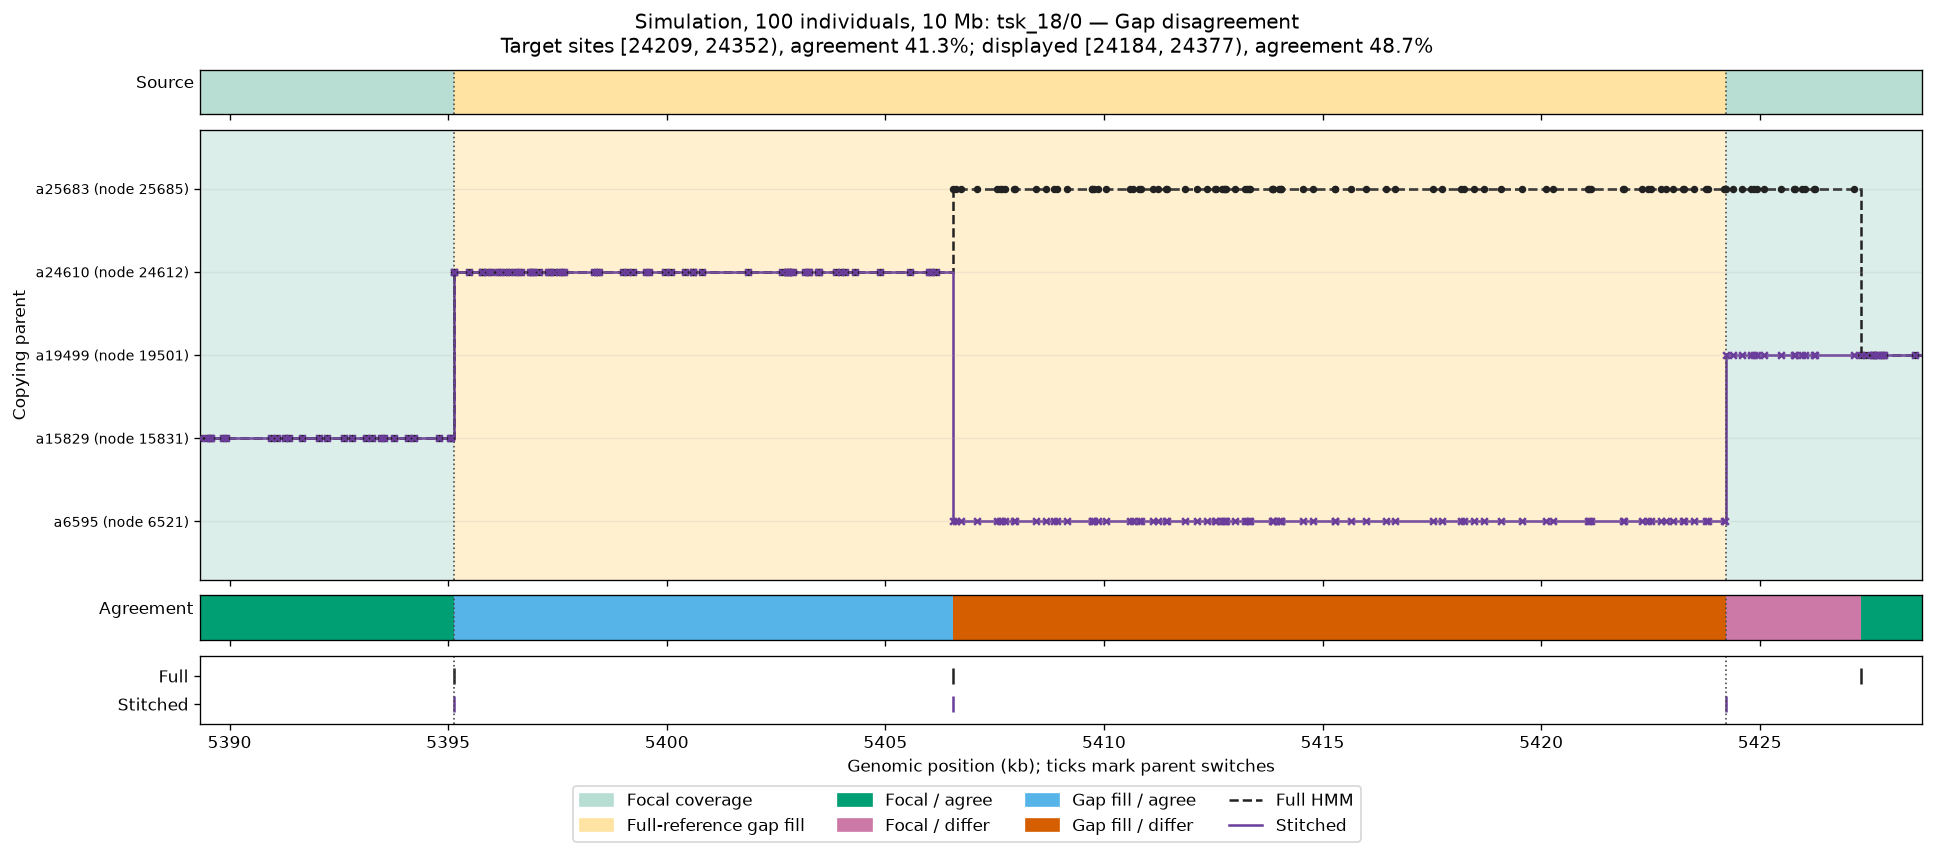

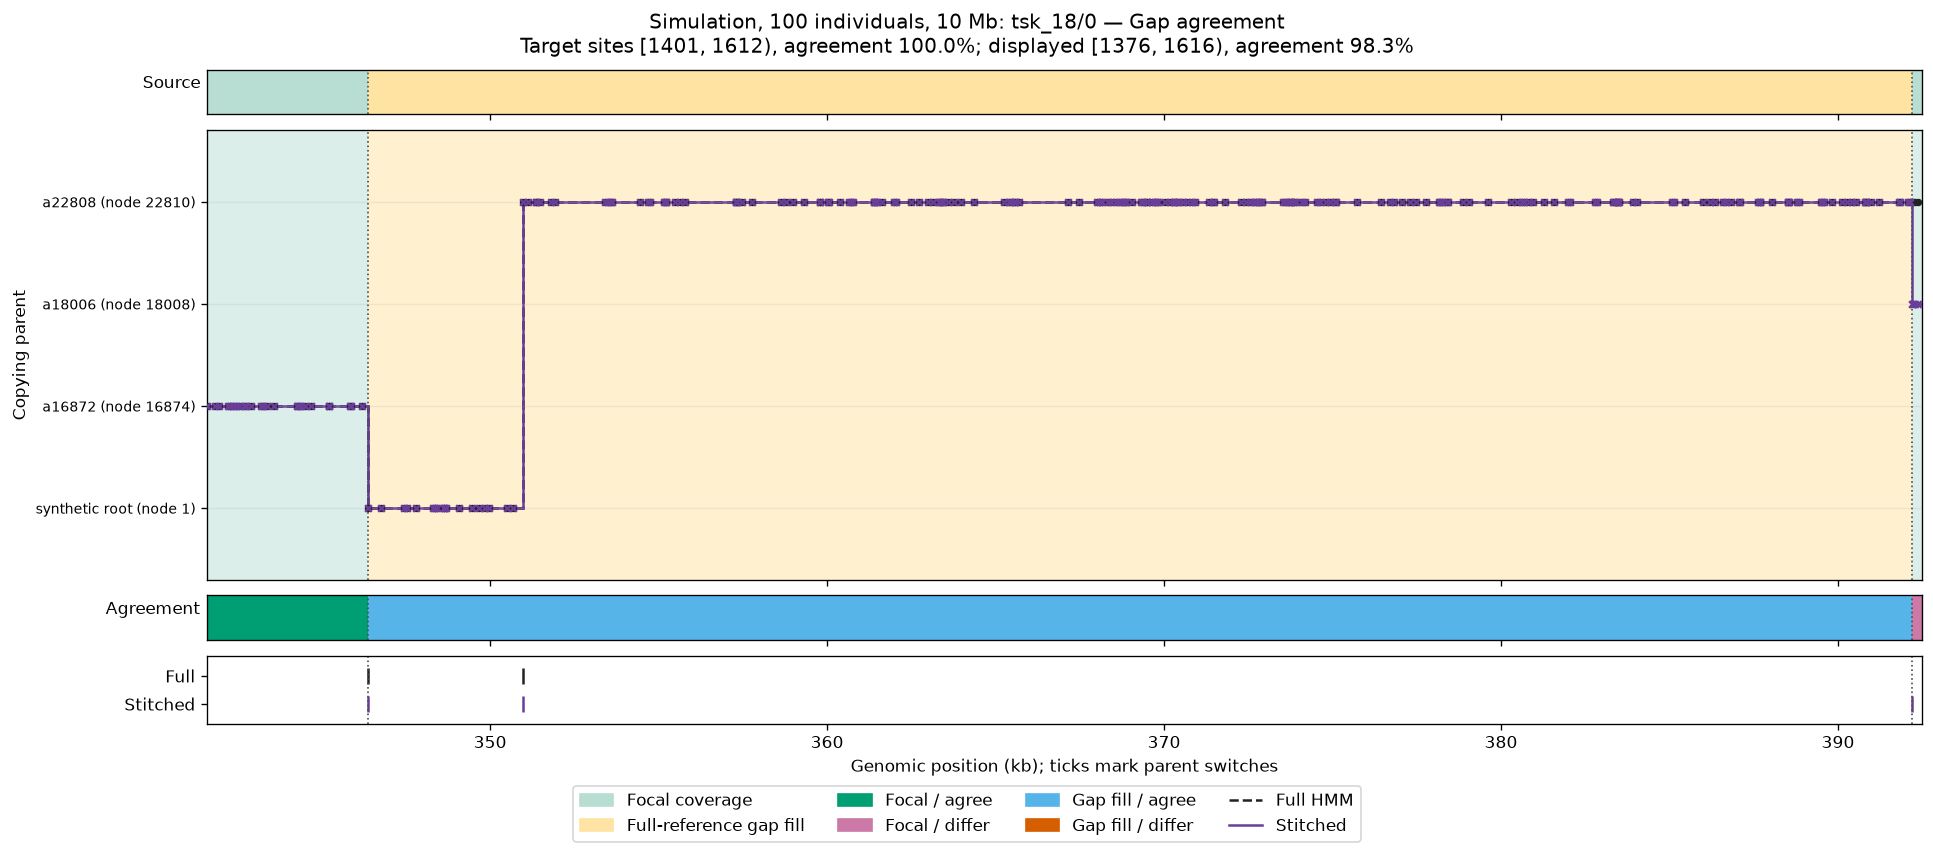

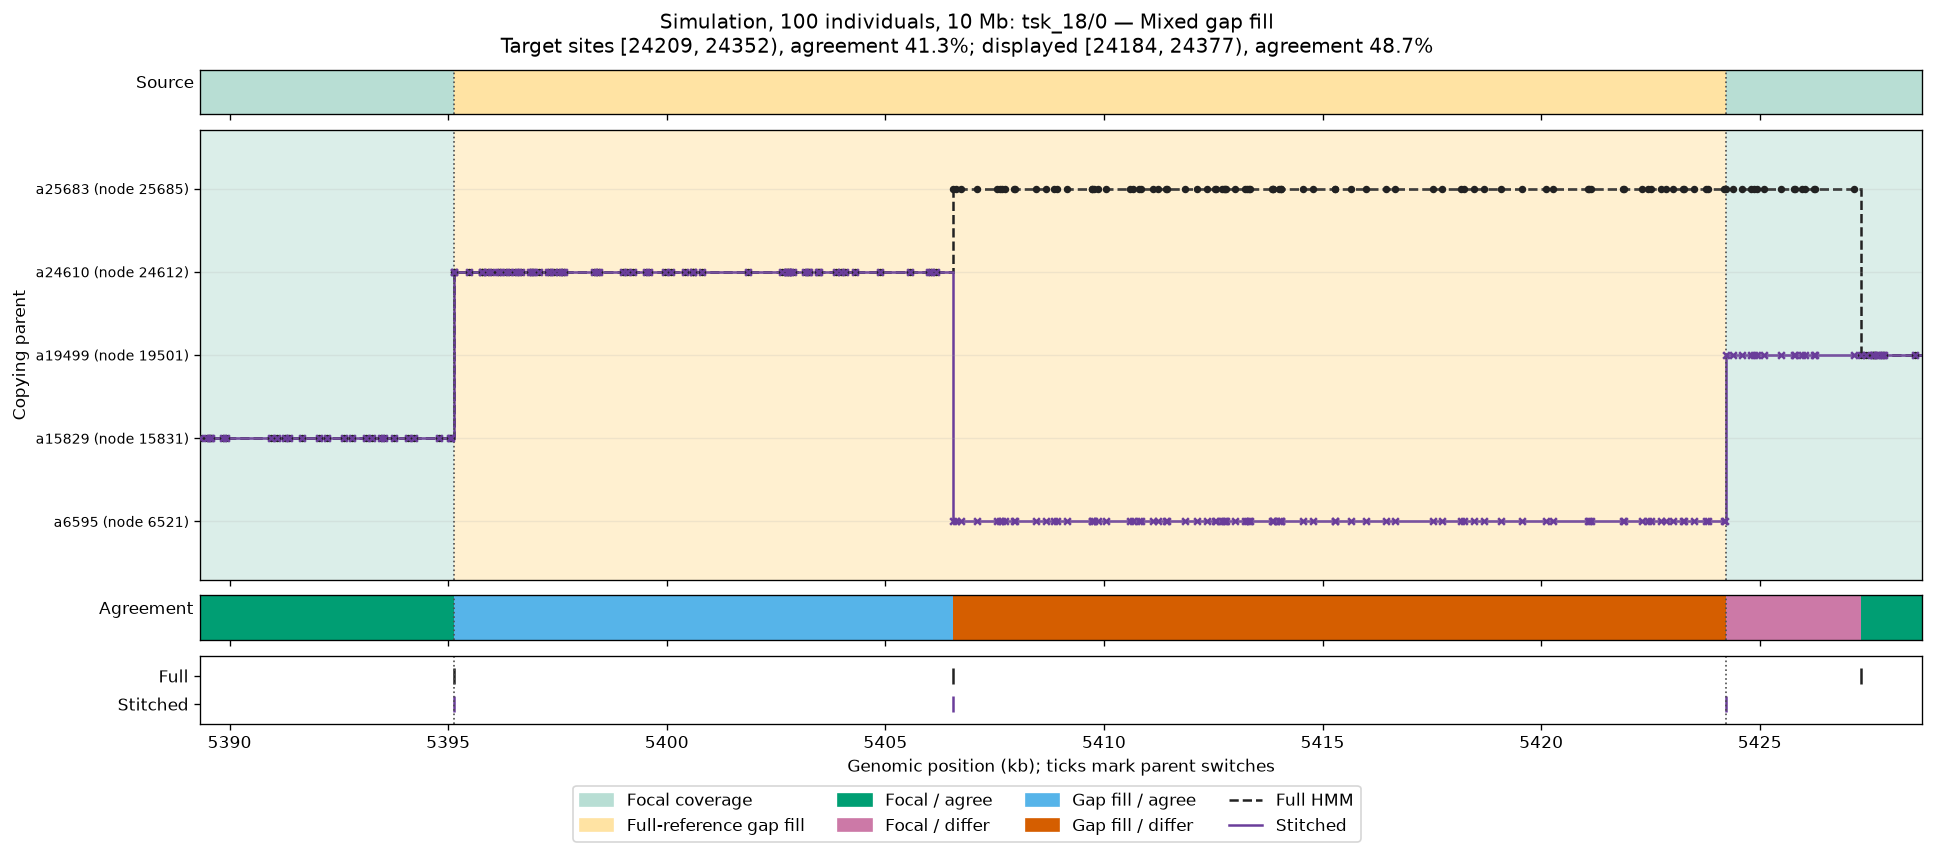

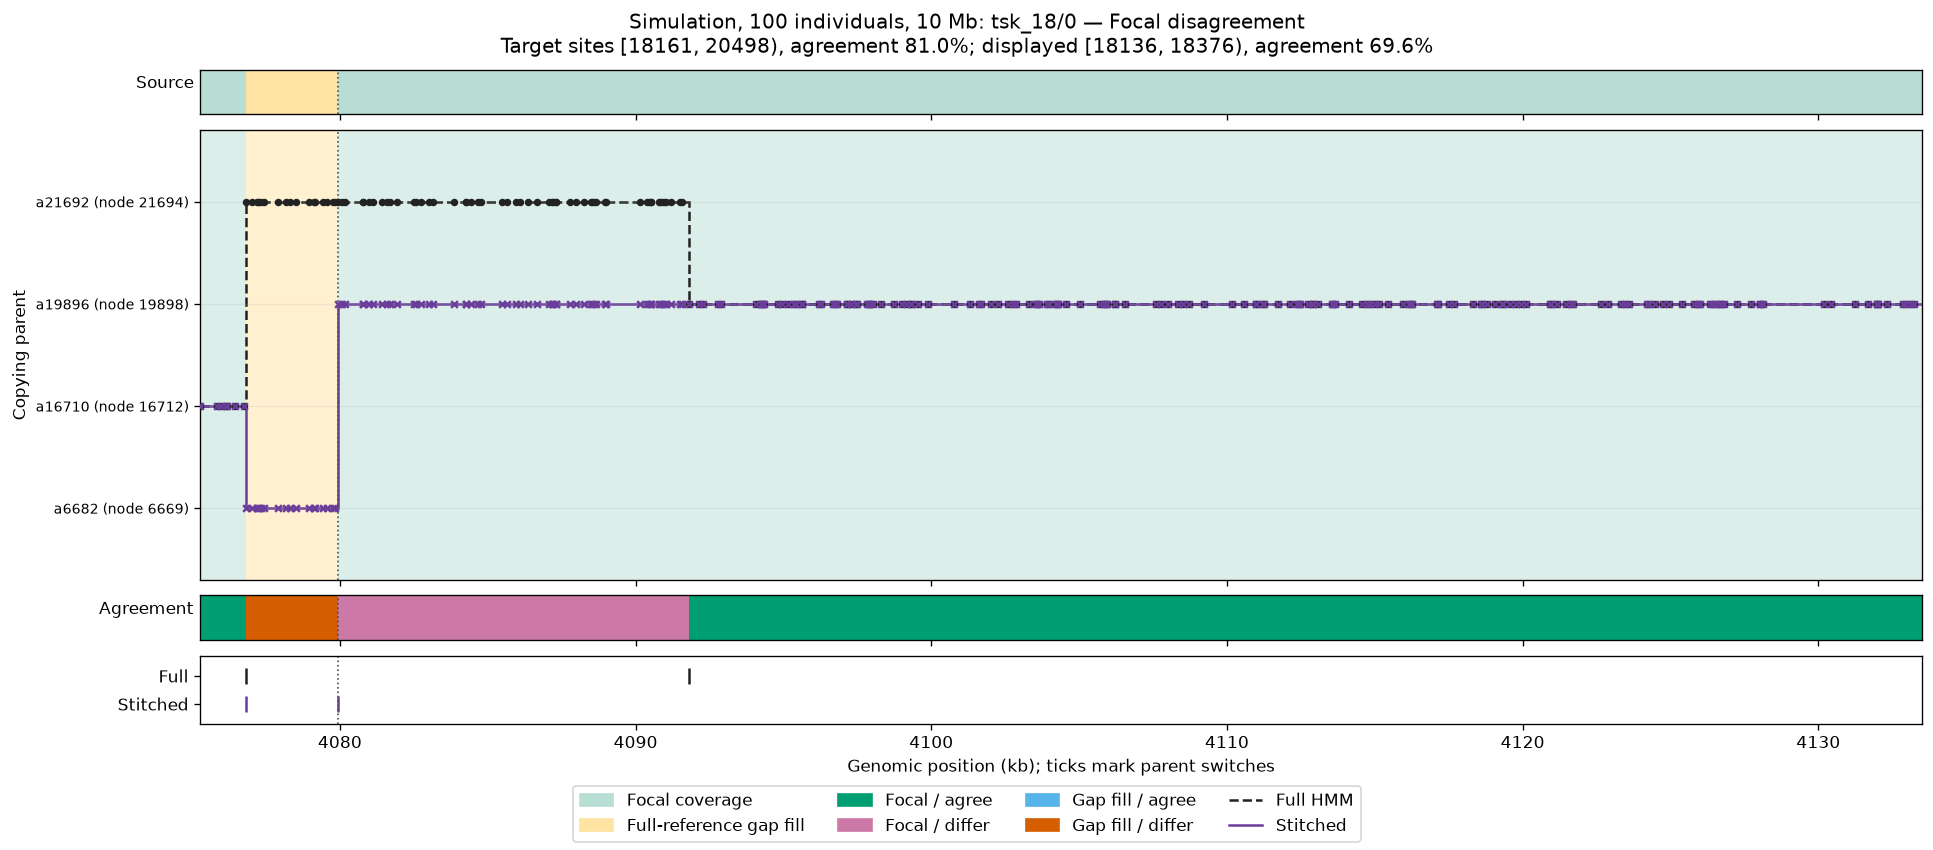

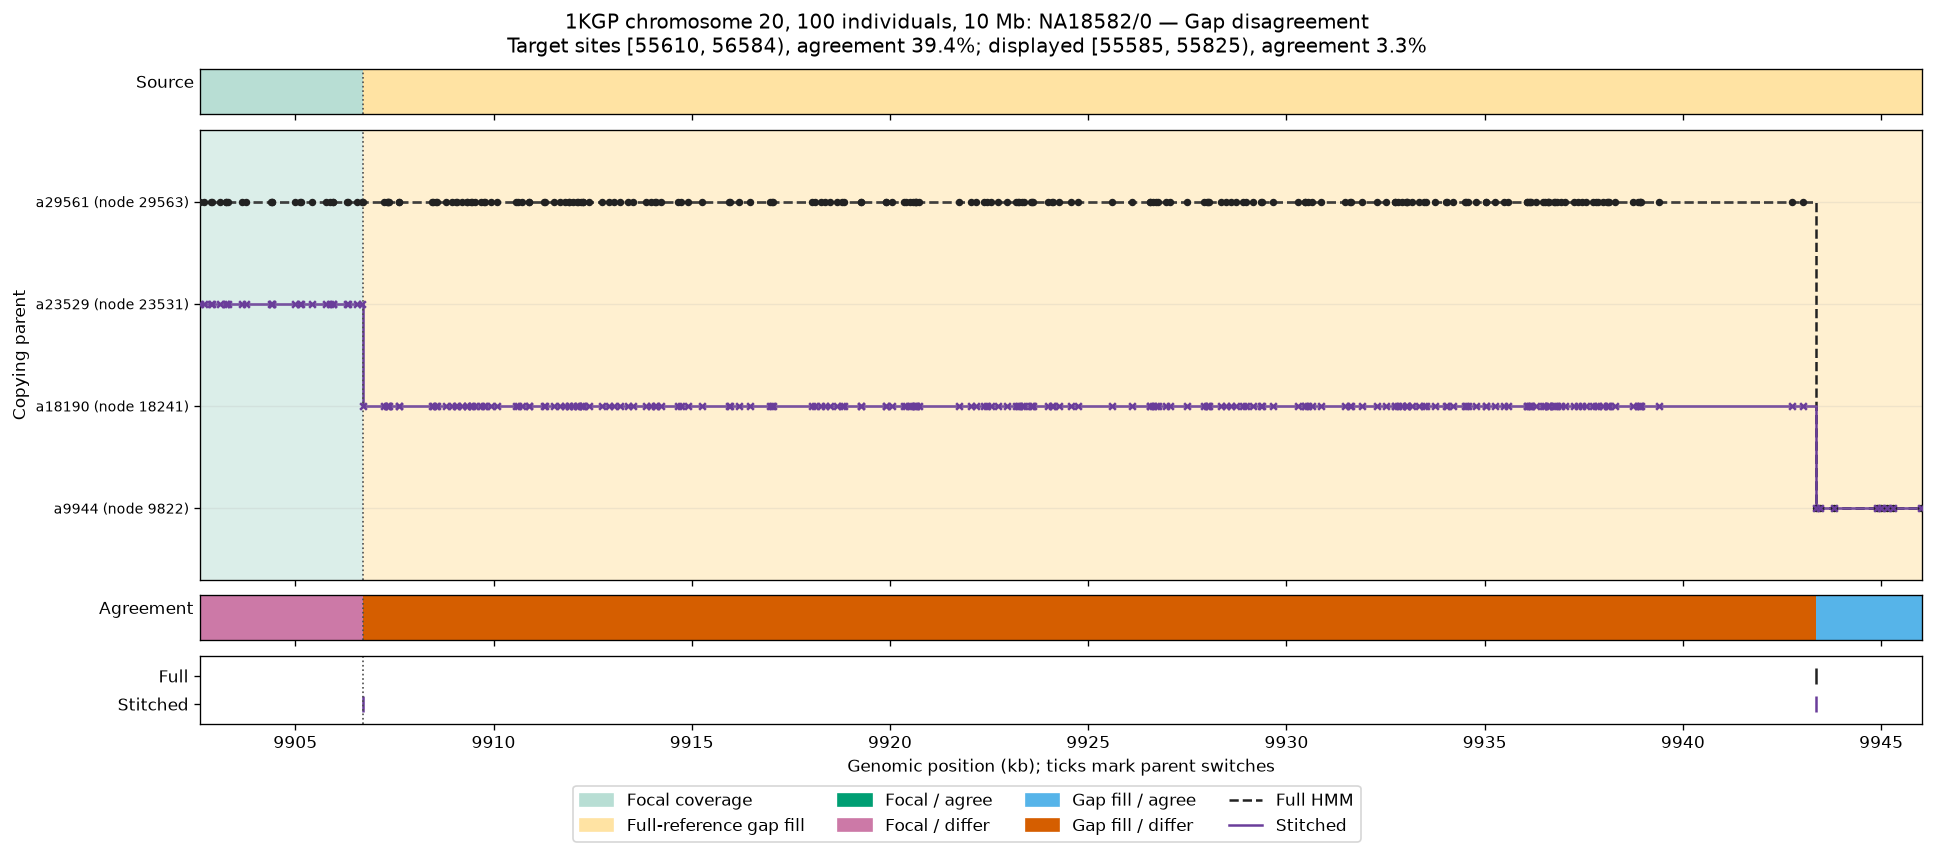

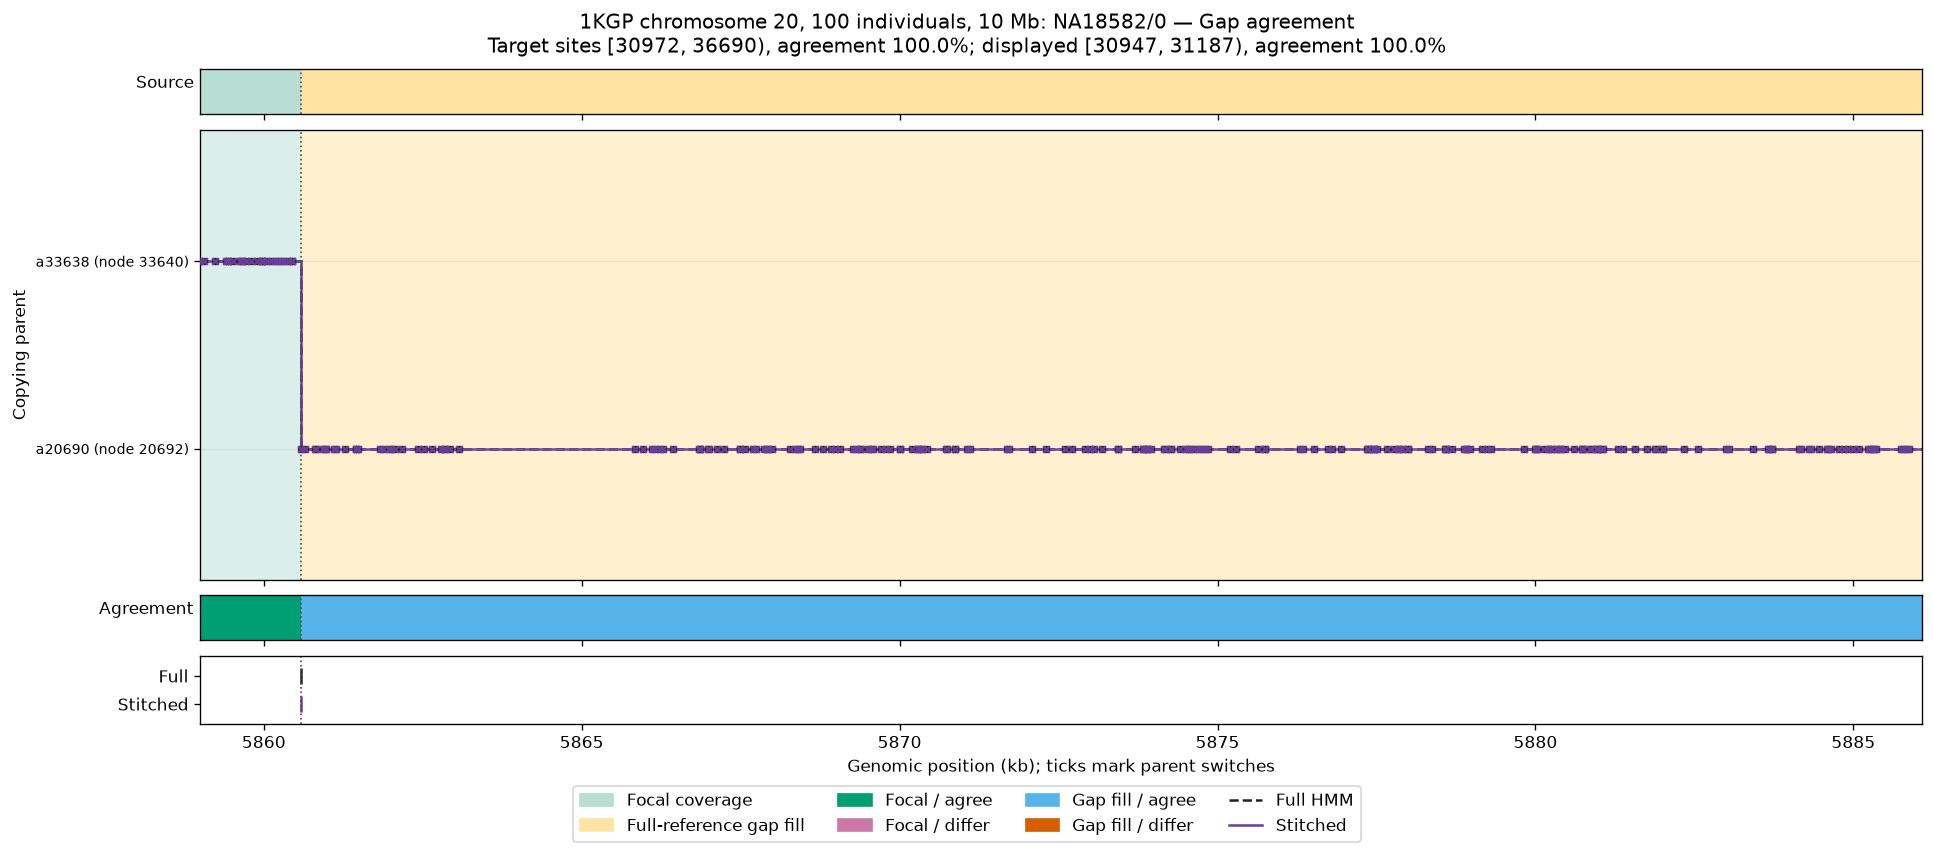

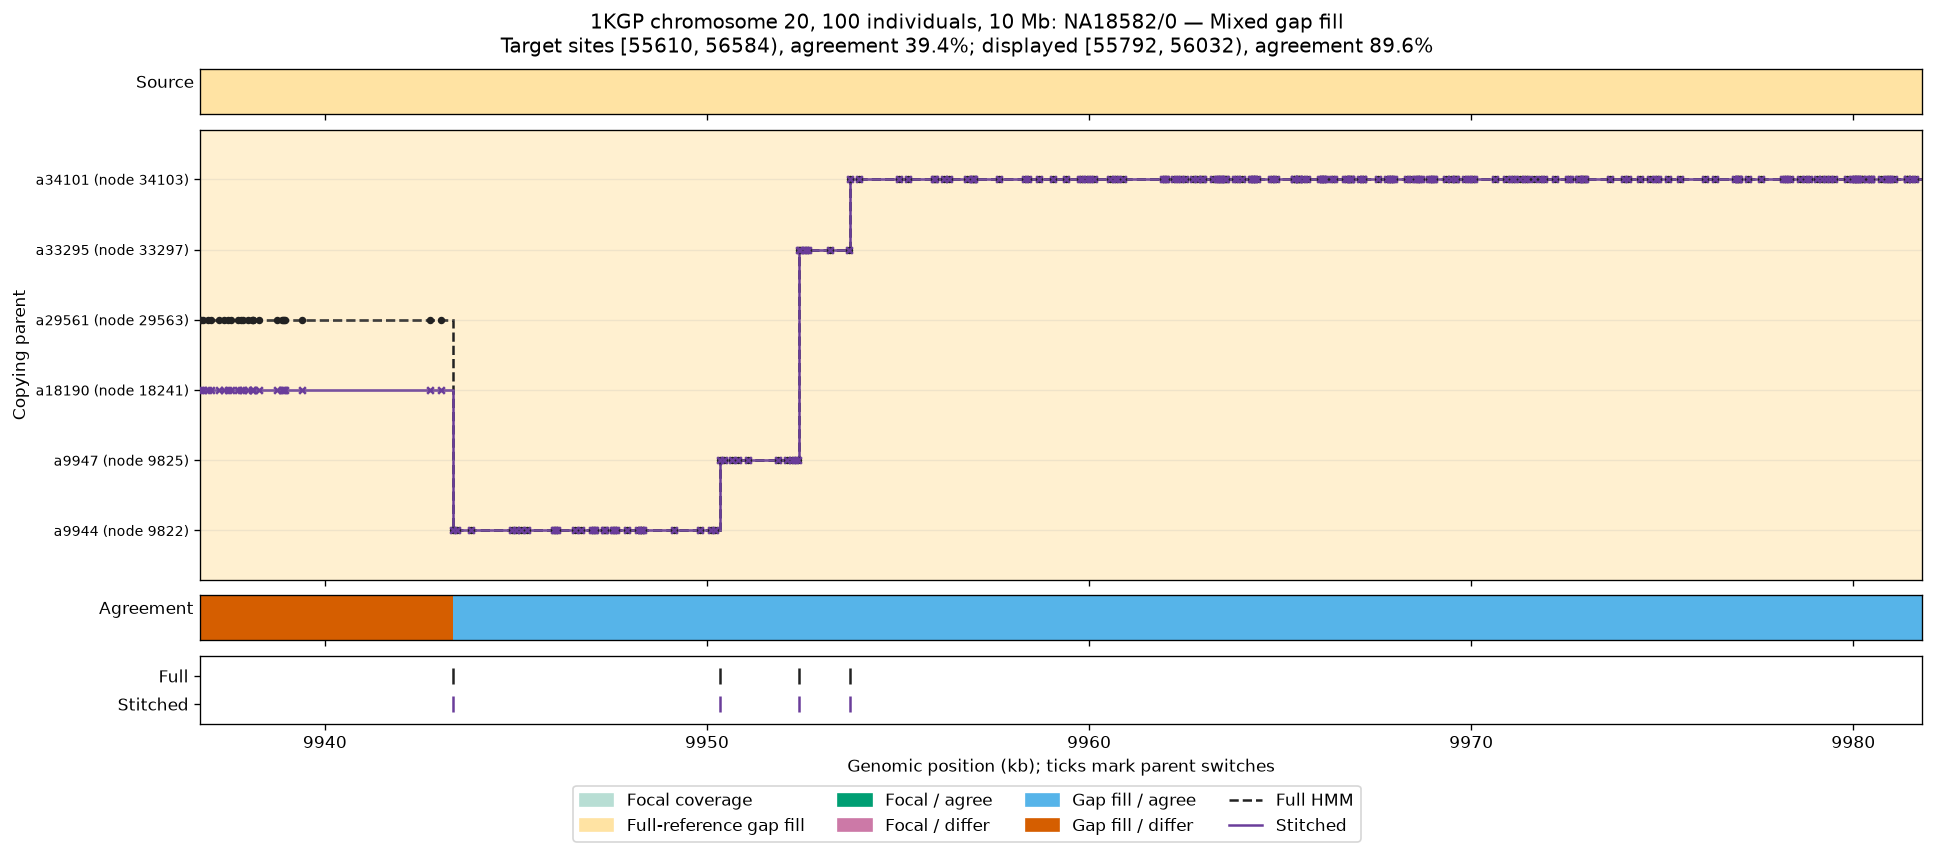

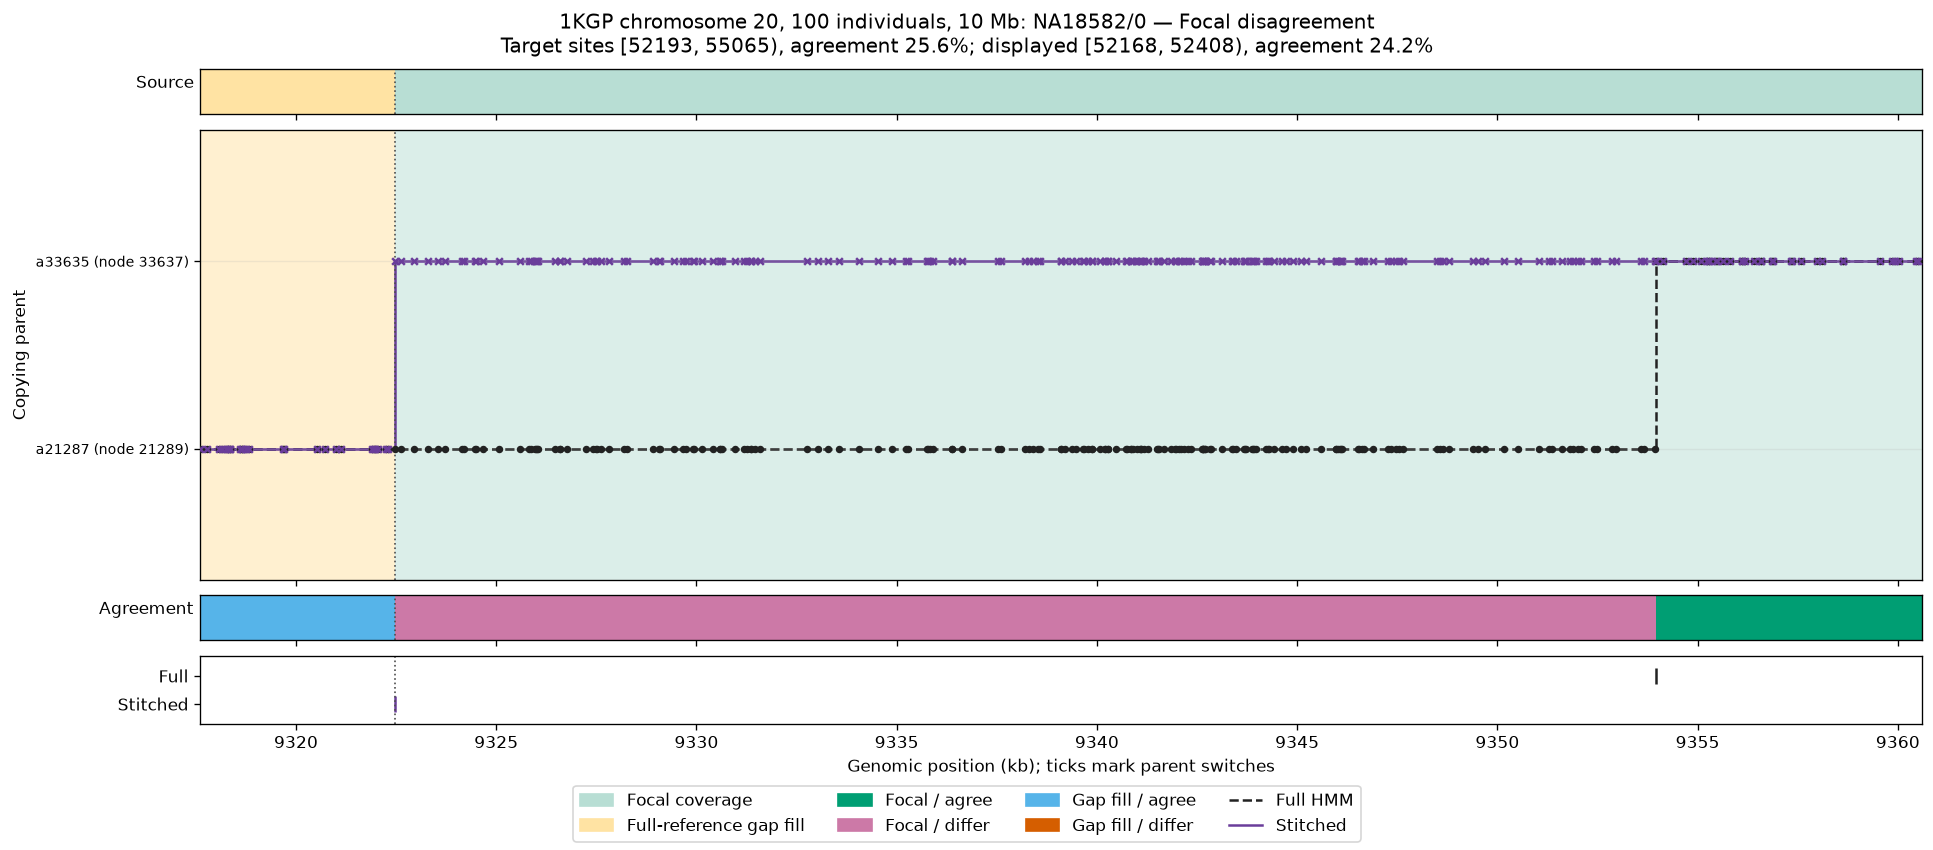

In [31]:
nb_plot.plot_detailed_parent_paths_covered_focal_pieces_gap_fills(
    category_cmap=category_cmap,
    category_norm=category_norm,
    coverage_handles=coverage_handles,
    datasets=datasets,
    detail_windows=detail_windows,
    source_cmap=source_cmap,
    source_norm=source_norm,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)

## Does disagreement concentrate near focal/gap seams?

Pool the saved haplotypes **within each dataset**, separating covered focal
sites from gap-fill sites. Distance is the number of inference-site steps to
the nearest provenance seam, with the immediately adjacent site on either side
assigned distance zero. Fractions use the actual site counts in each distance
bin; the accompanying table gives the denominators.

These are selected diagnostic haplotypes, not a representative population
sample. Proximity is descriptive and does not isolate a causal boundary effect.
In particular, distant disagreement within covered focal pieces means that
conditioning gap endpoints alone cannot recover this particular full parent path.

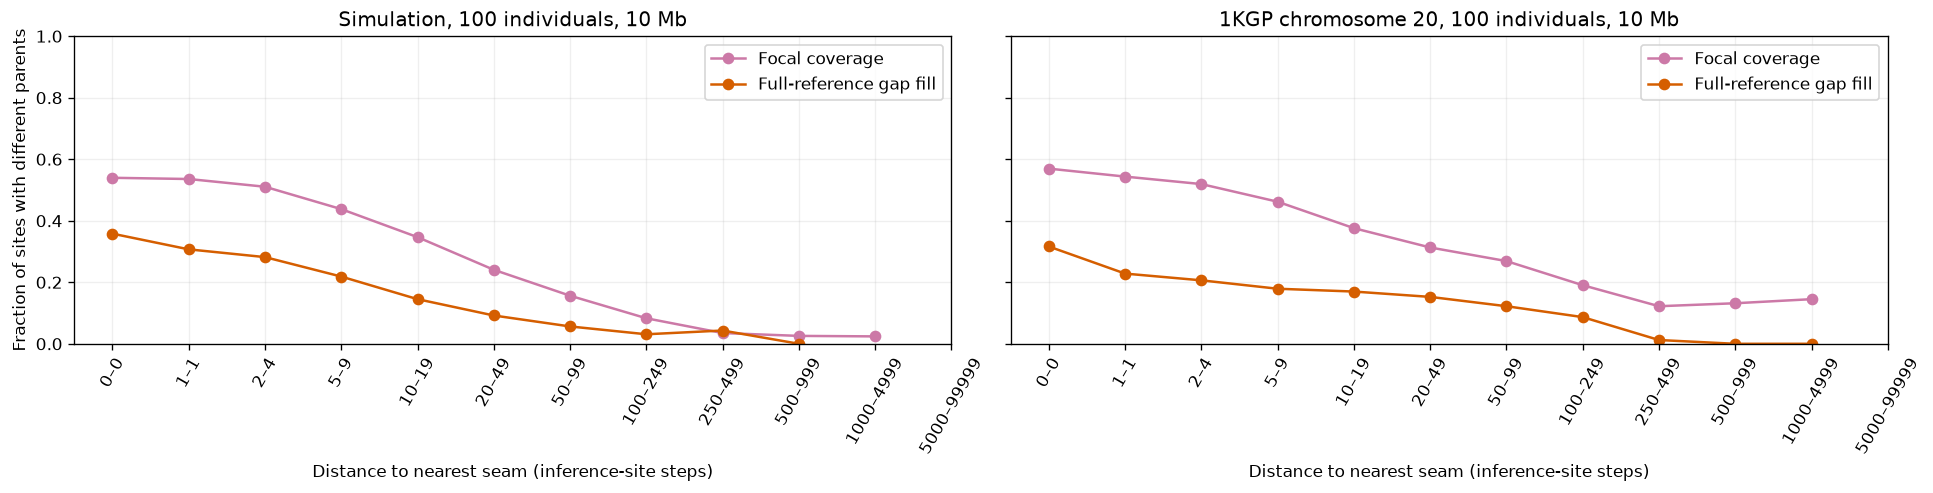

,dataset,source,distance_start,distance_end,num_sites,disagree_sites,disagreement_fraction
0,"Simulation, 100 individuals, 10 Mb",Focal coverage,0,1,252,136,0.5397
1,"Simulation, 100 individuals, 10 Mb",Focal coverage,1,2,252,135,0.5357
2,"Simulation, 100 individuals, 10 Mb",Focal coverage,2,5,756,386,0.5106
3,"Simulation, 100 individuals, 10 Mb",Focal coverage,5,10,1254,549,0.4378
4,"Simulation, 100 individuals, 10 Mb",Focal coverage,10,20,2385,827,0.3468
5,"Simulation, 100 individuals, 10 Mb",Focal coverage,20,50,6750,1624,0.2406
6,"Simulation, 100 individuals, 10 Mb",Focal coverage,50,100,9572,1496,0.1563
7,"Simulation, 100 individuals, 10 Mb",Focal coverage,100,250,20665,1715,0.0830
8,"Simulation, 100 individuals, 10 Mb",Focal coverage,250,500,21651,757,0.0350
9,"Simulation, 100 individuals, 10 Mb",Focal coverage,500,1000,22290,573,0.0257


In [32]:
distance_rows = []
bins = np.array(config["distance_bin_edges"])
nb_plot.plot_does_disagreement_concentrate_near_focal_gap_seams_2(
    bins=bins,
    datasets=datasets,
    distance_rows=distance_rows,
    figsize=[16, 4],
    marker="o",
    ylim=(0, 1),
    xlabel="Distance to nearest seam (inference-site steps)",
    alpha=0.2,
    dpi=120,
    show_top_spine=True,
    show_right_spine=True,
)
distance_table = pd.DataFrame(distance_rows)
ipython_display.display(distance_table.loc[distance_table.num_sites > 0].round(4))